In [2]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Не Colab: подключение Drive пропущено')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Детская депривация в Казахстане: факторы и ассоциации
## по синтетическим данным обследования домашних хозяйств (D002, D004, D006, D008), 2021–2024

---

## ⚠️ 0. О природе данных — прочитать перед всем остальным

**Все данные в этом исследовании полностью синтетические.** Это не выгрузка реальных
анкет Бюро национальной статистики, а искусственно сгенерированный датасет для
учебного дата-марафона (datathon), подготовленный Дарханом Медеуовым. Источник этого
раздела — сопроводительная документация к датасету (`datathon_synthetic_data.html`,
`d004-form-notes.html`).

**Как устроена генерация.** Используется последовательный метод синтеза по деревьям
решений (в духе R-пакета `synthpop`), не GAN и не копулы. Для каждого домохозяйства
столбцы заполняются один за другим: дерево решений, построенное на реальных данных,
относит синтетическое домохозяйство в группу «похожих» реальных домохозяйств по уже
заполненным столбцам, затем значение **копируется** из случайного реального
домохозяйства этой группы. Иными словами: *каждое отдельное значение — это реальный
ответ, но ни одна строка не описывает реального человека* — значения в одной строке
происходят из разных реальных домохозяйств.

**Что из этого следует напрямую для нашего исследования:**

1. **Одномерные распределения (доли, средние) близки к реальным** — авторы сообщают
   медианную ошибку <0.02 по 236 таблицам. Описательная статистика (Milestone 13) в
   целом заслуживает доверия.
2. **Связи между столбцами систематически ослаблены** — поскольку дерево для каждого
   столбца использует не все остальные столбцы, а только часть. Авторы явно измерили
   это на зарегистрированных заранее регрессиях:

   | Регрессия | Коэффициент | Реальные данные | Синтетика | Восстановлено |
   |---|---|---|---|---|
   | `log(площадь) ~ log(размер ДХ) + тип жилья` | `log(размер ДХ)` | 0.177 | 0.130 | **73%** |
   | `log(площадь) ~ log(размер) + доля детей + тип жилья + собственность + регион` | **доля детей** | −0.128 | **−0.016** | **12%** |
   | `log(площадь) ~ ...` (производственная форма) | `log(размер)` | −0.584 | −0.318 | 55% |

   Направление связи сохраняется почти всегда, **сила — занижена**, иногда drastически
   (эффект доли детей на жилплощадь уцелел лишь на 12%). Это **прямо касается нашей
   гипотезы**: `area_per_person` и аналогичные показатели, завязанные на число детей,
   с высокой вероятностью занижены в этих данных сильнее, чем остальные переменные.
3. **`HOUSEHOLD_ID` уникален только внутри одного года.** Каждый год генерировался
   независимо; домохозяйство `HOUSEHOLD_ID=1` в 2021 и `HOUSEHOLD_ID=1` в 2022 — два
   разных вымышленных (синтетических) домохозяйства, случайно получившие одинаковый порядковый
   номер. Проверено ниже (Milestone 1.2) на данных. **Все операции должны
   выполняться строго в пределах одного года**; межгодовой «трекинг» домохозяйств
   невозможен и не предпринимается нигде в этом ноутбуке.
4. **Внутри одного года панель по кварталам — настоящая** (одно и то же синтетическое
   домохозяйство последовательно отвечает 4 квартала) — это используется.
5. **Стандартные ошибки занижены ещё по одной причине**, сверх отсутствия весов
   (Milestone 17): сгенерирован **один** синтетический срез, без повторных
   («multiple imputation»-подобных) версий, которые позволили бы оценить
   дополнительную неопределённость самого процесса синтеза.
6. **2021: отсутствие года рождения — не пропуск данных, а особенность генерации
   именно этого года** («в 2021 году возраст респондента не привязан к указанному
   лицу»), как прямо указано в документации.
7. ~2.4% домохозяйств не имеют записи о жилье **по замыслу** (воспроизводит реальную
   норму недостижимости интервьюером) — соответствует нашей проверке покрытия D006.

**Как это меняет интерпретацию исследования.** Следует читать результаты не как оценки
реальных параметров населения Казахстана, а как **методологическую репетицию**:
направление связей (знак коэффициента) можно обсуждать с осторожным доверием; силу
связи и особенно **отсутствие** значимой связи — нет: null-результат может означать
как реальное отсутствие эффекта, так и его ослабление синтезом до
статистической незаметности. Этот момент разбирается отдельно при каждом null-результате
ниже (Milestone 16, 19, 24, 26).

---

## 1. Гипотезы исследования

**Часть I. Основная гипотеза.** Депривация детей связана с регионом, типом поселения,
материальным положением (самооценка, индекс лишений, доход и пособия из D004),
продовольственной безопасностью, жилищными условиями, полнотой семьи и структурой ДХ.

**Н1′ (производная).** Депривация различается по конкретным пунктам (одежда, обувь,
питание, книги/игрушки, спорт, место для занятий, досуг, отпуск, медицина) и по типу
семьи (полная/неполная).

**Часть II. Гипотеза Н2.** Шансы наличия детей в ДХ выше при собственном благоустроенном
жилье и стабильно высоком доходе (другая зависимая переменная — `has_children`).

Используются все 4 формы (D002, D004, D006, D008) на равных правах с этапа аудита.

> **Техническая оговорка.** Файлы `D00X_master_wide_<year>.csv` (510 столбцов,
> 167–171 тыс. строк/год) и `kv_vopr_detail_<year>.csv` (построчная выгрузка 12
> под-таблиц D004, ~2 млн строк/год, не прямоугольная) читаются по одному году за раз
> и освобождаются из памяти — см. Milestone 1.


In [3]:
import csv
import gc
import pandas as pd
import numpy as np
from pathlib import Path

pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 140)

CANDIDATE_DATA_DIRS = ["/content/drive/MyDrive/Datathon2026/synthetic_microdata_2021-2024_20260921/D00X/data", "data", "."]
DATA_DIR = next((Path(p) for p in CANDIDATE_DATA_DIRS if Path(p).exists() and
                  any(Path(p).glob("master_wide_*.csv"))), Path("data"))
OUTPUT_DIR = Path("output")
OUTPUT_DIR.mkdir(exist_ok=True)


def year_path(y):
    return DATA_DIR / f"master_wide_{y}.csv"


def d004_path(y):
    """Если для года есть достроенный файл *_full.csv (см. следующую ячейку) — берём его."""
    full = DATA_DIR / f"kv_vopr_detail_{y}_full.csv"
    return full if full.exists() else DATA_DIR / f"kv_vopr_detail_{y}.csv"


def load_csv(y, usecols=None):
    return pd.read_csv(year_path(y), usecols=usecols, low_memory=False)


# Годы, для которых файлы реально лежат в DATA_DIR (в Colab — все четыре)
YEARS = [y for y in (2021, 2022, 2023, 2024) if year_path(y).exists()]
AF_YEARS = [y for y in (2023, 2024) if y in YEARS]          # годы с блоком депривации детей

# Прожиточный минимум на 1 чел. в месяц, тенге (предоставлено исследователем)
PM_MONTHLY = {2023: 40_567, 2024: 43_407}

print("DATA_DIR:", DATA_DIR.resolve())
print("Годы:", YEARS)


DATA_DIR: /content/drive/MyDrive/Datathon2026/synthetic_microdata_2021-2024_20260921/D00X/data
Годы: [2021, 2022, 2023, 2024]


### 1.0 Контроль полноты D004

В исходном `kv_vopr_detail_2023.csv` **нет таблиц `kv_vopr_1…7`** (в 2024 они есть), поэтому алименты
(`kv_vopr_6`), питание и прочие расходы за 2023 год были пустыми. Ниже: функция проверяет набор таблиц
в каждом годовом файле и, если таблиц не хватает, достраивает файл `kv_vopr_detail_<год>_full.csv` из
квартальных исходников `<год>/{1..4}kv/kv_vopr{N}.csv` (структура строки — как в склейке: исходные поля +
`YEAR`, `HOUSEHOLD_ID` (= `NOMER` без префикса года), `SOURCE_TABLE`).
Папку с исходниками нужно положить рядом с данными (`<DATA_DIR>/2023/1kv/…`) либо в `Datathon2026/2023`.


In [4]:
D004_REQUIRED = [f"kv_vopr_{i}_combined" for i in list(range(0, 8)) + [10, 11, 12]]
D004_SRC_ROOTS = [DATA_DIR, DATA_DIR.parent, Path("."), Path("/content/drive/MyDrive/Datathon2026")]


def d004_tables_present(path):
    seen = set()
    with open(path, encoding="utf-8") as f:
        r = csv.reader(f); next(r)
        for row in r:
            seen.add(row[-1])
    return seen


def ensure_d004_complete(y):
    full = DATA_DIR / f"kv_vopr_detail_{y}_full.csv"
    if full.exists():
        return full
    base = DATA_DIR / f"kv_vopr_detail_{y}.csv"
    missing = [t for t in D004_REQUIRED if t not in d004_tables_present(base)]
    if not missing:
        return base
    src = next((r / str(y) for r in D004_SRC_ROOTS if (r / str(y) / "1kv").exists()), None)
    need = [t for t in missing if 1 <= int(t.split("_")[2]) <= 7]
    if src is None:
        print(f"[!] {y}: в {base.name} нет таблиц {missing}, исходников {y}/1kv… не найдено — "
              f"показатели из этих таблиц за {y} будут недоступны")
        return base
    added = {}
    with open(base, encoding="utf-8") as f, open(full, "w", encoding="utf-8", newline="") as g:
        r = csv.reader(f); w = csv.writer(g)
        w.writerow(next(r))
        for row in r:
            w.writerow(row)
        for t in need:
            num = int(t.split("_")[2]); n = 0
            for q in (1, 2, 3, 4):
                with open(src / f"{q}kv" / f"kv_vopr{num}.csv", encoding="utf-8-sig") as h:
                    rr = csv.reader(h); next(rr)
                    for row in rr:
                        w.writerow(row + [str(y), row[-1][len(str(y)):], t]); n += 1
            added[t] = n
    print(f"{y}: достроен {full.name}, добавлено строк: {added}")
    return full


for _y in YEARS:
    ensure_d004_complete(_y)


## Milestone 1 — Аудит данных

### 1.1 Структура столбцов D002/D006/D008

In [5]:
def col_group(c):
    for pref in ("d002_subject__", "d002_ocenka__", "d006__", "d008__"):
        if c.startswith(pref):
            return pref.rstrip("_")
    return "id/service"

headers = {y: pd.read_csv(year_path(y), nrows=0).columns.tolist() for y in YEARS}
group_counts = pd.DataFrame({
    y: pd.Series([col_group(c) for c in headers[y]]).value_counts()
    for y in YEARS
}).fillna(0).astype(int)
print("Идентичность столбцов относительно 2021:", {y: headers[y] == headers[YEARS[0]] for y in YEARS})
group_counts


Идентичность столбцов относительно 2021: {2021: True, 2022: True, 2023: True, 2024: True}


,2021,2022,2023,2024
d006,244,244,244,244
d002_ocenka,116,116,116,116
d002_subject,108,108,108,108
d008,30,30,30,30
id/service,12,12,12,12


### 1.2 `HOUSEHOLD_ID` уникален только внутри года — проверка на данных

Документация к синтетическим данным утверждает: ID не несёт смысла между годами.
Проверяем это напрямую на `D00X_master_wide` — двумя способами.

In [6]:
# Способ 1: пересечение множеств ID между соседними годами
id_sets = {y: set(load_csv(y, usecols=["HOUSEHOLD_ID"])["HOUSEHOLD_ID"]) for y in YEARS}
for y1, y2 in zip(YEARS[:-1], YEARS[1:]):
    inter = id_sets[y1] & id_sets[y2]
    print(f"{y1}∩{y2}: {len(inter)} общих значений ID из {len(id_sets[y1])} "
          f"({'да, но это лишь совпадение порядковых номеров 1..12000' if len(inter) == len(id_sets[y1]) else ''})")


2021∩2022: 12000 общих значений ID из 12000 (да, но это лишь совпадение порядковых номеров 1..12000)
2022∩2023: 12000 общих значений ID из 12000 (да, но это лишь совпадение порядковых номеров 1..12000)
2023∩2024: 12000 общих значений ID из 12000 (да, но это лишь совпадение порядковых номеров 1..12000)


In [7]:
# Способ 2: один и тот же HOUSEHOLD_ID в разные годы — разные регион и размер ДХ
checks = {}
for y in YEARS:
    checks[y] = load_csv(y, usecols=["HOUSEHOLD_ID", "TE", "d008__KOL_CHL"]).drop_duplicates("HOUSEHOLD_ID").set_index("HOUSEHOLD_ID")
sample_ids = [1, 100, 5000, 12000]
rows = []
for hid in sample_ids:
    r = {"household_id": hid}
    for y in YEARS:
        row = checks[y].loc[hid]
        r[f"регион_{y}"] = row["TE"]
        r[f"размер_ДХ_{y}"] = row["d008__KOL_CHL"]
    rows.append(r)
id_proof = pd.DataFrame(rows)
del checks; gc.collect()
id_proof


,household_id,регион_2021,размер_ДХ_2021,регион_2022,размер_ДХ_2022,регион_2023,размер_ДХ_2023,регион_2024,размер_ДХ_2024
0,1,19,2,27,7,47,2,43,2
1,100,61,2,79,2,39,4,61,3
2,5000,55,2,47,6,35,2,15,5
3,12000,47,2,61,6,39,2,62,3


**Вывод:** один и тот же номер `HOUSEHOLD_ID` в разные годы относится к ДХ с разным
регионом и разным размером — это физически разные (синтетические) домохозяйства,
которым синтез независимо присвоил одинаковый порядковый номер. **Всюду в этом
ноутбуке объединение данных по `HOUSEHOLD_ID` выполняется только в пределах одного
года** (ключ всегда включает `year`); межгодовые «истории домохозяйств» не строятся.

### 1.3 Единица наблюдения и веса

In [8]:
id_summary_rows = []
for y in YEARS:
    df = load_csv(y, usecols=["HOUSEHOLD_ID", "NOMP", "KVARTAL", "TE"])
    n = len(df)
    n_hh = df["HOUSEHOLD_ID"].nunique()
    dup = df.duplicated(subset=["HOUSEHOLD_ID", "NOMP", "KVARTAL"]).sum()
    id_summary_rows.append({"year": y, "rows": n, "households": n_hh, "rows_per_hh": round(n / n_hh, 2),
                             "quarters": sorted(df["KVARTAL"].dropna().unique().tolist()),
                             "dup_(hh,person,quarter)": dup, "regions_TE": df["TE"].nunique()})
    del df; gc.collect()
pd.DataFrame(id_summary_rows)


,year,rows,households,rows_per_hh,quarters,"dup_(hh,person,quarter)",regions_TE
0,2021,167472,12000,13.96,"[1, 2, 3, 4]",0,17
1,2022,170724,12000,14.23,"[1, 2, 3, 4]",0,20
2,2023,170756,12000,14.23,"[1, 2, 3, 4]",0,20
3,2024,167284,12000,13.94,"[1, 2, 3, 4]",0,20


Единица наблюдения — человек×квартал **внутри одного года**. D002-переменные
заполнены на ~28% строк (одна строка-респондент на ДХ за квартал); D006/D008 — на
97–100% (продублированы на всех членов ДХ). Регионов (`TE`): 17 в 2021, 20 в 2022–2024
(реформа АТД РК 2022 г., как и в реальных данных, которые этот синтез копирует).

In [9]:
weight_like = [c for c in headers[YEARS[0]] if any(k in c.upper() for k in
                ["VES", "WEIGHT", "WGT", "STRATA", "PSU", "CLUSTER"])]
print("Столбцы весов/страт/PSU:", weight_like if weight_like else "НЕ НАЙДЕНО")


Столбцы весов/страт/PSU: НЕ НАЙДЕНО


### 1.4 D004 — структура файла и декодирование

`kv_vopr_detail_<year>.csv` — построчная конкатенация **12 под-таблиц** (`kv_vopr_0…12`,
кроме `kv_vopr_8`) с разным числом полей, без отдельного заголовка на под-таблицу.
Независимая документация (`d004-form-notes.html`, авторская записка разработчика
синтетических данных) подтверждает принцип построения, который мы вывели эмпирически
в предыдущей версии ноутбука, и даёт точные уточнения:

- **`NOMVOPR`** — номер вопроса *внутри своей таблицы* (не сквозной): `kv_vopr2`→`21`,
  `kv_vopr3`→`31`, `kv_vopr4`→`41`, `kv_vopr5`→`51`, `kv_vopr6`→`60,61,62`,
  `kv_vopr7`→`71`, `kv_vopr9`→`91…99,913,914`, `kv_vopr10`→`101,102`, `kv_vopr11`→`111`,
  `kv_vopr12`→`200,1211,1212`. Значения, которые мы находили эмпирически (константа
  `111` для `kv_vopr_11`, `61`/`62` для `kv_vopr_6`), совпадают — подтверждает нашу
  реконструкцию позиций независимо.
- **`GRn`** — это номер **графы бланка** (столбца на бумажной форме), а не код
  категории: «одно и то же имя `GR1` в разных таблицах означает разное». В
  `kv_vopr_11` (доходы) `GR1…GR23` действительно идут **в порядке бланка** (23 вида
  дохода) — именно так мы их и сопоставляли.
- **`kv_vopr_12`** (займы) — отдельный случай, который мы раньше не разбирали: столбец
  `KOD` хранит ответы на **два разных** вопроса (2.1 «на что взят заём» и 2.2 «откуда
  заём»), каждый с 9 вариантами (9 = «другое» в обоих) — различать их нужно по
  `NOMVOPR`/`NOMVNEW` (`1211`/`21` = вопрос 2.1, `1212`/`22` = вопрос 2.2), иначе код
  «2» означает то «покупка жилья», то «коммерческий банк» одновременно. Мы **не
  используем** `kv_vopr_12` в показателях (займы — не часть гипотезы), но фиксируем это
  здесь, чтобы не повторить ошибку, если кто-то продолжит работу с этой таблицей.
- **Ловушка**, которая нас не касается, но стоит знать: `kv_vopr_9`/`kv_vopr_10`
  (производство) меняют схему нумерации между 3 и 4 кварталом 2023 года. Мы эти
  таблицы не используем.

Все найденные нами позиции (`kv_vopr_6`: `KODNU`=поз.3, `STOIMK`=поз.6, `KVARTAL`=поз.7;
`kv_vopr_11`: `KVARTAL`=поз.30, доходные графы=поз.7–29) — проверены и остаются в силе.

In [10]:
def d004_table_counts(y):
    counts, field_counts = {}, {}
    with open(d004_path(y), encoding="utf-8") as f:
        reader = csv.reader(f); next(reader)
        for row in reader:
            st = row[-1]
            counts[st] = counts.get(st, 0) + 1
            field_counts.setdefault(st, len(row))
    return counts, field_counts

_y0 = YEARS[0]
d004_counts_y0, d004_fields_y0 = d004_table_counts(_y0)
d004_table_summary = pd.DataFrame([
    {"source_table": k, "n_fields": d004_fields_y0[k], f"rows_{_y0}": v}
    for k, v in sorted(d004_counts_y0.items())
])
d004_table_summary


,source_table,n_fields,rows_2021
0,kv_vopr_0_combined,9,48000
1,kv_vopr_10_combined,15,42109
2,kv_vopr_11_combined,36,99082
3,kv_vopr_12_combined,15,20399
4,kv_vopr_1_combined,13,1092444
5,kv_vopr_2_combined,12,250452
6,kv_vopr_3_combined,11,105758
7,kv_vopr_4_combined,11,6880
8,kv_vopr_5_combined,11,19941
9,kv_vopr_6_combined,13,154115


In [11]:
d004_tc = {y: d004_table_counts(y) for y in YEARS}
field_stability_df = pd.DataFrame({y: d004_tc[y][1] for y in YEARS})
# Раньше проверка nunique() молча игнорировала NaN (= таблица отсутствует в году) и печатала True.
absent = {y: sorted(field_stability_df.index[field_stability_df[y].isna()]) for y in YEARS}
absent = {y: v for y, v in absent.items() if v}
assert not absent, f"В годовых файлах D004 нет таблиц: {absent}. Достройте их из квартальных исходников (ячейка 1.0)."
assert (field_stability_df.nunique(axis=1) == 1).all(), "Число полей под-таблиц различается между годами"
print("Набор таблиц и число полей по под-таблицам идентичны во всех годах:", True)
field_stability_df


Набор таблиц и число полей по под-таблицам идентичны во всех годах: True


,2021,2022,2023,2024
kv_vopr_0_combined,9,9,9,9
kv_vopr_10_combined,15,15,15,15
kv_vopr_11_combined,36,36,36,36
kv_vopr_12_combined,15,15,15,15
kv_vopr_1_combined,13,13,13,13
kv_vopr_2_combined,12,12,12,12
kv_vopr_3_combined,11,11,11,11
kv_vopr_4_combined,11,11,11,11
kv_vopr_5_combined,11,11,11,11
kv_vopr_6_combined,13,13,13,13


### 1.5 Валидация расшифровки колонок дохода (`kv_vopr_11`)

Поскольку это синтетические данные без словаря столбцов для этой под-таблицы,
расшифровку GR-категорий проверяем внешними признаками: концентрацией значения у
определённого пола и у определённого состава ДХ (ожидание: пособие на детей — у
женщин и в ДХ с детьми; пенсия — у старшего поколения; алименты-доход — у женщин/ДХ
без партнёра).

In [12]:
GR_LABELS = {
    "GR1": "Доход от работы по найму", "GR2": "Доход от работы не по найму",
    "GR3": "  из него: продажа с/х продукции (подкатегория GR2)",
    "GR4": "Пенсии по возрасту", "GR5": "Стипендии", "GR6": "Адресная социальная помощь",
    "GR7": "Жилищная помощь", "GR8": "Гос. пособия семьям с детьми",
    "GR9": "Государственное социальное пособие", "GR10": "Специальное государственное пособие",
    "GR11": "Другие трансферты от государства", "GR12": "Социальные трансферты в натуральной форме",
    "GR13": "Материальная помощь (денежная)", "GR14": "Материальная помощь (натуральная)",
    "GR15": "Прочие трансферты", "GR16": "Алименты (получено)",
    "GR17": "Доход от продажи недвижимости", "GR18": "Доход от продажи личного имущества",
    "GR19": "Доход от собственности (дивиденды, %, гонорары)", "GR20": "Аренда жилья (доход)",
    "GR21": "Аренда земли/техники (доход)", "GR22": "Прочие денежные поступления",
    "GR23": "Дотации и льготы",
}
GR_POSITIONS = {f"GR{i}": 6 + i for i in range(1, 24)}

def safe_float(x):
    try:
        return float(x)
    except (ValueError, TypeError):
        return 0.0

def validate_income_columns(y=2023, grs=("GR1", "GR4", "GR8", "GR16")):
    mw = load_csv(y, usecols=["HOUSEHOLD_ID", "NOMP", "d008__RODSTVO", "d008__GOD_ROJD"]).drop_duplicates(["HOUSEHOLD_ID", "NOMP"])
    child = ((y - mw["d008__GOD_ROJD"]) < 18).groupby(mw["HOUSEHOLD_ID"]).any()
    spouse = (mw["d008__RODSTVO"] == 2).groupby(mw["HOUSEHOLD_ID"]).any()
    grp = pd.Series(np.where(~child, "без детей", np.where(spouse, "дети, есть партнёр", "дети, нет партнёра")), index=child.index)
    hh_sets = {g: set() for g in grs}
    sex_nz = {g: {"1": 0, "2": 0} for g in grs}
    sex_tot = {"1": 0, "2": 0}
    with open(d004_path(y), encoding="utf-8") as f:
        reader = csv.reader(f); next(reader)
        for row in reader:
            if row[-1] != "kv_vopr_11_combined":
                continue
            sex = row[4]
            if sex in sex_tot:
                sex_tot[sex] += 1
            for g in grs:
                if safe_float(row[GR_POSITIONS[g]]) != 0:
                    hh_sets[g].add(int(row[-2]))
                    if sex in sex_tot:
                        sex_nz[g][sex] += 1
    rows = []
    for g in grs:
        s = hh_sets[g]
        r = {"category": g, "label": GR_LABELS[g]}
        for name in ["без детей", "дети, есть партнёр", "дети, нет партнёра"]:
            idx = grp.index[grp == name]
            r[f"доля ДХ: {name}"] = round(idx.isin(list(s)).mean(), 3)
        r["женщины, % лиц"] = round(100 * sex_nz[g]["2"] / sex_tot["2"], 2)
        r["мужчины, % лиц"] = round(100 * sex_nz[g]["1"] / sex_tot["1"], 2)
        rows.append(r)
    return pd.DataFrame(rows).set_index("category")

income_validation = validate_income_columns(2023)
income_validation


,label,доля ДХ: без детей,"доля ДХ: дети, есть партнёр","доля ДХ: дети, нет партнёра","женщины, % лиц","мужчины, % лиц"
category,,,,,,
GR1,Доход от работы по найму,0.813,0.986,0.922,55.41,69.26
GR4,Пенсии по возрасту,0.585,0.350,0.367,26.66,15.17
GR8,Гос. пособия семьям с детьми,0.064,0.358,0.161,7.55,0.50
GR16,Алименты (получено),0.078,0.093,0.081,1.11,1.02


**Результат.** `GR1` (найм) и `GR4` (пенсии) ведут себя ожидаемо. **`GR8`
(пособия семьям с детьми) — подтверждена**: доля ДХ с пособием в разы выше там, где
есть дети, и в ~15 раз чаще у женщин. **`GR16` («алименты получено») — не
подтверждена**: доли практически одинаковы у мужчин/женщин и у ДХ с детьми/без. Учитывая,
что даже направление связи в синтетических данных иногда сохраняется слабо (раздел 0),
это может быть как неверная позиция колонки, так и реально ослабленная связь синтеза —
разделить эти два объяснения по имеющимся данным нельзя. Поэтому `alimony_received`
используется только справочно, не в выводах. Алименты **выплаченные**
(`kv_vopr_6`, код `21123`, сверен по справочнику классификатора, не по порядку бланка)
— надёжны.

### 1.6 Пропуски — ключевые находки

In [13]:
key_fields = {
    "d008__GOD_ROJD (год рождения)": "d008__GOD_ROJD",
    "d002_ocenka__KVINT (квинтиль дохода)": "d002_ocenka__KVINT",
    "d002_ocenka__GR40 (есть дети до 18)": "d002_ocenka__GR40",
    "d002_ocenka__GR45_1 (депривация: одежда)": "d002_ocenka__GR45_1",
    "TOTAL_EXPENDITURE": "TOTAL_EXPENDITURE",
}
rows = []
for y in YEARS:
    df = load_csv(y, usecols=list(key_fields.values()))
    row = {"year": y}
    for label, col in key_fields.items():
        row[label] = round(df[col].notna().mean(), 3)
    rows.append(row)
    del df; gc.collect()
pd.DataFrame(rows).set_index("year").T


year,2021,2022,2023,2024
d008__GOD_ROJD (год рождения),0.000,1.000,1.000,1.000
d002_ocenka__KVINT (квинтиль дохода),0.000,0.000,0.280,0.000
d002_ocenka__GR40 (есть дети до 18),0.000,0.000,0.280,0.285
d002_ocenka__GR45_1 (депривация: одежда),0.000,0.000,0.142,0.146
TOTAL_EXPENDITURE,0.985,0.988,0.987,0.987


**Находки:** `d008__GOD_ROJD` пуст в 2021 — по документации синтеза это
особенность генерации именно 2021 года (возраст не привязывался к человеку), а не
случайный пропуск. Блок депривации детей — только 2023–2024 (введён в анкету с 2023 г.,
подтверждено и в Структуре_датасетов_3_0.docx: «добавлена опросная часть о депривации
детей»). `KVINT` пуст во всех годах, кроме 2023 (не используется ни в одной модели).


## Milestone 2 — Сопоставление переменных (variable crosswalk)

Совпадение имени столбца не принимается за сопоставимость — сверяются тексты вопросов
(OCR полных бланков `D_002_форма.pdf`, `Д002-_казрус.pdf`, `д004_форма_рус.pdf`) и
независимая сводка `Структура_датасетов_3_0.docx`/`анкеты_датасетов.docx`, которые
подтвердили нашу реконструкцию без расхождений.

**D002 (2021) vs D002-КазРус (2022–2024)** — разные анкеты по внутренней нумерации
(не просто переименование), с коллизиями имён столбцов между периодами. Материальная
лестница, шкала продбезопасности (FIES-8) и индекс лишений сопоставимы по содержанию
(с поправкой на сдвиг позиций и смену нумерации). Депривация детей — только 2023–2024.
**D004** — структура стабильна все 4 года (Milestone 1.4), гармонизация между годами
не требуется.

In [14]:
variable_crosswalk = pd.DataFrame([
    dict(concept="Регион (TE)", y2021="17 кодов", y2022="20 кодов (реформа АТД РК 2022 г.)",
         comparable="Частично", notes="Новые области выделены из существующих — коды не биективны"),
    dict(concept="Тип поселения (K)", y2021="1/2", y2022="1/2", comparable="Да", notes="Кодировка стабильна"),
    dict(concept="Материальная лестница (6 категорий)", y2021="d002_ocenka__GR1", y2022="d002_subject__GR21 (с 2023)",
         comparable="Да", notes="Одинаковый вопрос/шкала, разные столбцы по переходной нумерации 2022 г."),
    dict(concept="Продбезопасность (FIES-8)", y2021="d002_ocenka__GR4-11", y2022="d002_subject__GR26,27,29,210-214 (с 2023)",
         comparable="Да", notes="Полная 8-пунктовая шкала все 4 года"),
    dict(concept="Индекс материально-соц. лишений (11 общих пунктов)", y2021="d002_ocenka__GR32-311",
         y2022="d002_ocenka__GR33-312", comparable="Да (по содержанию)", notes="КазРус добавил 'отопление' — сдвиг позиций на 1"),
    dict(concept="Депривация детей (14 пунктов)", y2021="нет", y2022="есть с 2023", comparable="Нет для 2021-2022",
         notes="Раздел появился в анкете с 2023 г."),
    dict(concept="Жилищные условия (D006)", y2021="стабильно", y2022="стабильно", comparable="Да", notes="Форма не менялась"),
    dict(concept="Состав ДХ (D008)", y2021="без возраста (GOD_ROJD пуст — особенность генерации 2021 г.)",
         y2022="полностью", comparable="Частично", notes="См. Milestone 1.6"),
    dict(concept="Доход домохозяйства (D004, kv_vopr_11)", y2021="стабильная структура", y2022="стабильная структура",
         comparable="Да", notes="Число полей на под-таблицу идентично все 4 года"),
    dict(concept="Алименты выплаченные (D004, kv_vopr_6, KODNU=21123)", y2021="стабильно", y2022="стабильно",
         comparable="Да", notes="Код сверен по официальному классификатору"),
    dict(concept="Алименты полученные (D004, kv_vopr_11, GR16)", y2021="стабильно", y2022="стабильно",
         comparable="НЕ подтверждено", notes="Внешняя валидация не подтвердила (Milestone 1.5) — используется справочно"),
])
variable_crosswalk


,concept,y2021,y2022,comparable,notes
0,Регион (TE),17 кодов,20 кодов (реформа АТД РК 2022 г.),Частично,Новые области выделены из существующих — коды ...
1,Тип поселения (K),1/2,1/2,Да,Кодировка стабильна
2,Материальная лестница (6 категорий),d002_ocenka__GR1,d002_subject__GR21 (с 2023),Да,"Одинаковый вопрос/шкала, разные столбцы по пер..."
3,Продбезопасность (FIES-8),d002_ocenka__GR4-11,"d002_subject__GR26,27,29,210-214 (с 2023)",Да,Полная 8-пунктовая шкала все 4 года
4,Индекс материально-соц. лишений (11 общих пунк...,d002_ocenka__GR32-311,d002_ocenka__GR33-312,Да (по содержанию),КазРус добавил 'отопление' — сдвиг позиций на 1
5,Депривация детей (14 пунктов),нет,есть с 2023,Нет для 2021-2022,Раздел появился в анкете с 2023 г.
6,Жилищные условия (D006),стабильно,стабильно,Да,Форма не менялась
7,Состав ДХ (D008),без возраста (GOD_ROJD пуст — особенность гене...,полностью,Частично,См. Milestone 1.6
8,"Доход домохозяйства (D004, kv_vopr_11)",стабильная структура,стабильная структура,Да,Число полей на под-таблицу идентично все 4 года
9,"Алименты выплаченные (D004, kv_vopr_6, KODNU=2...",стабильно,стабильно,Да,Код сверен по официальному классификатору


## Milestone 3 — Гармонизация

Единая функция извлечения D004-показателей на уровень домохозяйство×квартал (в
пределах года), используется наравне с гармонизацией D002/D006/D008.

In [15]:
INCOME_SUBSET_POS = 9
EMPLOYMENT_POS, SELF_EMPLOY_POS, PENSION_POS = 7, 8, 10
FAMILY_BENEFIT_POS, ALIMONY_RECEIVED_POS = 14, 22
INCOME_ALL_POS = list(range(7, 30))
ALIMONY_PAID_KODNU = "21123"

def extract_d004(y):
    income_rows, alimony_paid = {}, {}
    with open(d004_path(y), encoding="utf-8") as f:
        reader = csv.reader(f); next(reader)
        for row in reader:
            st = row[-1]
            if st == "kv_vopr_11_combined":
                key = (row[-2], row[30])
                if key not in income_rows:
                    income_rows[key] = {"total_income": 0.0, "employment_income": 0.0,
                                         "self_employment_income": 0.0, "pension_income": 0.0,
                                         "family_benefit_income": 0.0, "alimony_received": 0.0}
                d = income_rows[key]
                for pos in INCOME_ALL_POS:
                    if pos == INCOME_SUBSET_POS:
                        continue
                    d["total_income"] += safe_float(row[pos])
                d["employment_income"] += safe_float(row[EMPLOYMENT_POS])
                d["self_employment_income"] += safe_float(row[SELF_EMPLOY_POS])
                d["pension_income"] += safe_float(row[PENSION_POS])
                d["family_benefit_income"] += safe_float(row[FAMILY_BENEFIT_POS])
                d["alimony_received"] += safe_float(row[ALIMONY_RECEIVED_POS])
            elif st == "kv_vopr_6_combined" and row[3] == ALIMONY_PAID_KODNU:
                key = (row[-2], row[7])
                amt, n = alimony_paid.get(key, (0.0, 0))
                alimony_paid[key] = (amt + safe_float(row[6]), n + 1)
    income_df = pd.DataFrame([{"year": y, "household_id": int(hh), "quarter": int(q), **v}
                               for (hh, q), v in income_rows.items()])
    alimony_df = pd.DataFrame([{"year": y, "household_id": int(hh), "quarter": int(q),
                                 "alimony_paid_amount": v[0], "alimony_paid_n": v[1]}
                                for (hh, q), v in alimony_paid.items()])
    return income_df, alimony_df

d004_income_parts, d004_alimony_parts = [], []
for y in YEARS:
    inc, ali = extract_d004(y)
    d004_income_parts.append(inc); d004_alimony_parts.append(ali)
    gc.collect()
d004_income = pd.concat(d004_income_parts, ignore_index=True)
d004_alimony = pd.concat(d004_alimony_parts, ignore_index=True)
print("D004 доход: строк =", len(d004_income), "| алименты выплачены: строк =", len(d004_alimony))
d004_income.groupby("year")[["total_income", "employment_income", "family_benefit_income", "alimony_received"]].mean().round(0)


D004 доход: строк = 188122 | алименты выплачены: строк = 940


,total_income,employment_income,family_benefit_income,alimony_received
year,,,,
2021,707617.0,432681.0,10481.0,2374.0
2022,834978.0,537904.0,13362.0,3661.0
2023,986487.0,652831.0,17268.0,3851.0
2024,1097876.0,730837.0,21392.0,5188.0


In [16]:
HARMONIZE_COLS = ["HOUSEHOLD_ID", "NOMP", "KVARTAL", "TE", "K", "d008__KOL_CHL",
                  "d006__OB_PL", "d006__J_PL", "d006__KOL_K", "d006__TIP_J", "d006__VLAD1", "TOTAL_EXPENDITURE"]

def harmonize(y):
    df = load_csv(y, usecols=HARMONIZE_COLS)
    h = pd.DataFrame(index=df.index)
    h["year"] = y
    h["household_id"] = df["HOUSEHOLD_ID"]
    h["person_id"] = df["NOMP"]
    h["quarter"] = df["KVARTAL"]
    h["region_code"] = df["TE"]
    h["settlement_type"] = df["K"].map({1: "city", 2: "rural"})
    h["household_size"] = df["d008__KOL_CHL"]
    h["total_area_m2"] = df["d006__OB_PL"]
    h["rooms"] = df["d006__KOL_K"]
    h["owned_housing"] = df["d006__VLAD1"].isin([1, 2]).astype(float).where(df["d006__VLAD1"].notna())
    h["total_expenditure"] = df["TOTAL_EXPENDITURE"]
    del df; gc.collect()
    return h

harmonized = {y: harmonize(y) for y in YEARS}
harmonized[2024].head(3)


,year,household_id,person_id,quarter,region_code,settlement_type,household_size,total_area_m2,rooms,owned_housing,total_expenditure
0,2024,1,1,1,43,city,2,67.0,3.0,1.0,432536.0
1,2024,1,1,2,43,city,2,67.0,3.0,1.0,106863.0
2,2024,1,1,3,43,city,2,67.0,3.0,1.0,239875.0


## Milestone 4 — Объединение форм

D002+D006+D008 уже объединены поставщиком; проверяем качество (в пределах каждого
года). D004 объединяется здесь же по ключу (**год**, домохозяйство, квартал) — год в
ключе обязателен (Milestone 1.2).

In [17]:
merge_check_rows = []
for y in YEARS:
    df = load_csv(y, usecols=["HOUSEHOLD_ID", "NOMP", "KVARTAL", "d006__OB_PL", "d008__KOL_CHL"])
    n_hh = df["HOUSEHOLD_ID"].nunique()
    n_hh_income = d004_income.loc[d004_income["year"] == y, "household_id"].nunique()
    merge_check_rows.append({
        "year": y, "households_total": n_hh,
        "has_d006_share": round(df["d006__OB_PL"].notna().mean(), 3),
        "has_d008_share": round(df["d008__KOL_CHL"].notna().mean(), 3),
        "has_d004_income_households": n_hh_income, "d004_coverage_share": round(n_hh_income / n_hh, 3),
        "duplicates_(hh,person,quarter)": df.duplicated(subset=["HOUSEHOLD_ID", "NOMP", "KVARTAL"]).sum(),
    })
    del df; gc.collect()
pd.DataFrame(merge_check_rows)


,year,households_total,has_d006_share,has_d008_share,has_d004_income_households,d004_coverage_share,"duplicates_(hh,person,quarter)"
0,2021,12000,0.973,1.0,11930,0.994,0
1,2022,12000,0.983,1.0,11925,0.994,0
2,2023,12000,0.974,1.0,11965,0.997,0
3,2024,12000,0.978,1.0,11948,0.996,0


D006 покрывает ~97–98% строк (воспроизводит реальную норму недостижимости интервьюером, раздел 0), D008 — 100%, D004 (доход) — около 99.5% домохозяйств в год.

## Milestone 5 — Аналитическая выборка

Правило «есть дети» **единое для всех лет (2022–2024)**: в домохозяйстве есть хотя бы один член
моложе 18 лет по году рождения (`d008__GOD_ROJD`). Флаг `d002_ocenka__GR40` («есть дети до 18»)
в определении выборки **не используется** — он расходится с возрастом примерно у каждого десятого ДХ;
расхождения подсчитаны ниже. 2021 — недоступно (Milestone 1.6).


In [18]:
child_flag_rows = []
for y in YEARS:
    if y == 2021:
        df = load_csv(y, usecols=["HOUSEHOLD_ID"])
        child_flag_rows.append({"year": y, "source": "НЕДОСТУПНО", "households_total": df["HOUSEHOLD_ID"].nunique(),
                                "hh_with_children_age<18": np.nan, "GR40_only": np.nan, "age_only": np.nan})
        continue
    cols = ["HOUSEHOLD_ID", "d008__GOD_ROJD"] + (["d002_ocenka__GR40"] if y >= 2023 else [])
    df = load_csv(y, usecols=cols)
    by_age = ((y - df["d008__GOD_ROJD"]) < 18).groupby(df["HOUSEHOLD_ID"]).any()
    row = {"year": y, "source": "возраст членов ДХ < 18", "households_total": int(df["HOUSEHOLD_ID"].nunique()),
           "hh_with_children_age<18": int(by_age.sum()), "GR40_only": np.nan, "age_only": np.nan}
    if y >= 2023:
        gr40 = (df["d002_ocenka__GR40"] == 1).groupby(df["HOUSEHOLD_ID"]).any()
        row["GR40_only"] = int((gr40 & ~by_age.reindex(gr40.index)).sum())     # GR40=1, но детей по возрасту нет
        row["age_only"] = int((~gr40 & by_age.reindex(gr40.index)).sum())      # дети по возрасту есть, GR40≠1
    child_flag_rows.append(row)
    del df; gc.collect()
pd.DataFrame(child_flag_rows)


,year,source,households_total,hh_with_children_age<18,GR40_only,age_only
0,2021,НЕДОСТУПНО,12000,NaN,NaN,NaN
1,2022,возраст членов ДХ < 18,12000,6773.0,NaN,NaN
2,2023,возраст членов ДХ < 18,12000,6750.0,411.0,1027.0
3,2024,возраст членов ДХ < 18,12000,6700.0,368.0,937.0


## Milestone 6 — Зависимая переменная: депривация детей

Источник — 14 бинарных пунктов `d002_ocenka__GR45_1…14` (ответ «нет, не может позволить» = код 2)
и отдельный пункт о доступе к медицине `GR46`. Сначала строится сырой (невзвешенный) счётчик
`deprivation_count` (0–14) как техническая величина для последующих проверок устойчивости.

**Основной критерий депривации в этом ноутбуке — многомерный показатель по методу
Алкаер–Фостера (АФ)**, а не «депривирован хотя бы по одному пункту из 14». Полная спецификация
(области → индикаторы → веса → порог k), расчёт H/A/M0, проверка устойчивости по нескольким k
и декомпозиция индекса — отдельный блок сразу после базового извлечения данных (Milestone 6.1).
Итоговый критерий `deprivation_binary` переопределяется там и используется во всех
последующих разделах (двумерный анализ, регрессия, robustness, проверка гипотез).

In [19]:
GR45_COLS = [f"d002_ocenka__GR45_{i}" for i in range(1, 15)]
outcome_selection_log = []


def child_hh_by_age(y):
    d = load_csv(y, usecols=["HOUSEHOLD_ID", "d008__GOD_ROJD"])
    return ((y - d["d008__GOD_ROJD"]) < 18).groupby(d["HOUSEHOLD_ID"]).any()


def build_primary_outcome(y):
    usecols = ["HOUSEHOLD_ID", "NOMP", "KVARTAL", "d002_ocenka__GR46"] + GR45_COLS
    df = load_csv(y, usecols=usecols)
    kids = child_hh_by_age(y)
    has_kid = df["HOUSEHOLD_ID"].map(kids).fillna(False).astype(bool)
    answered_block = df[GR45_COLS].notna().any(axis=1)
    mask = has_kid & answered_block                      # блок GR45 заполнен И в ДХ есть член <18 лет
    outcome_selection_log.append({"year": y, "rows_with_GR45": int(answered_block.sum()),
                                  "kept(age<18 in HH)": int(mask.sum()),
                                  "dropped(no age<18 in HH)": int((answered_block & ~has_kid).sum())})
    dep_items = df.loc[mask, GR45_COLS]
    deprived = (dep_items == 2)
    answered = dep_items.isin([1, 2, 3])
    out = pd.DataFrame({"year": y, "household_id": df.loc[mask, "HOUSEHOLD_ID"], "person_id": df.loc[mask, "NOMP"],
                         "quarter": df.loc[mask, "KVARTAL"], "n_items_answered": answered.sum(axis=1),
                         "deprivation_count": deprived.sum(axis=1)})
    out["deprivation_binary"] = (out["deprivation_count"] >= 1).astype(int)  # временно; переопределяется ниже по АФ
    for i in range(1, 15):
        col = f"d002_ocenka__GR45_{i}"
        out[f"dep_item_{i}"] = df.loc[mask, col].map({1: 0, 2: 1, 3: 0}).astype(float)
    out["dep_item_health"] = df.loc[mask, "d002_ocenka__GR46"].map({1: 0, 2: 0, 3: 1, 4: 1}).astype(float)
    del df; gc.collect()
    return out

primary_outcome = pd.concat([build_primary_outcome(y) for y in AF_YEARS], ignore_index=True)
display(pd.DataFrame(outcome_selection_log))
assert not primary_outcome.duplicated(["year", "household_id", "quarter"]).any()
primary_outcome.groupby("year")[["deprivation_count", "deprivation_binary"]].agg(["mean", "median", "count"])


,year,rows_with_GR45,kept(age<18 in HH),dropped(no age<18 in HH)
0,2023,24288,22552,1736
1,2024,24436,22800,1636


deprivation_count               deprivation_binary              
                  mean median  count               mean median  count
year                                                                 
2023          1.360589    0.0  22552           0.422845    0.0  22552
2024          1.286140    0.0  22800           0.393333    0.0  22800

**14 пунктов `GR45_1…14`:** 1 одежда, 2 обувь, 3 овощи/фрукты, 4 мясо/рыба, 5 обучающие
игры/книги, 6 спортинвентарь, 7 комнатные игрушки, 8 место для занятий, 9 регулярный досуг,
10 детские праздники, 11 приглашать друзей, 12 школьные экскурсии, 13 отпуск с родителями,
14 внеклассные занятия. Отдельно — `GR46` (доступ к медицине/лекарствам) — не входит в
невзвешенный счётчик `deprivation_count`, но входит в индекс Алкаер–Фостера ниже как
индикатор домена «Здоровье».

## Milestone 6.1 — Многомерная депривация детей по методу Алкаер–Фостера

Источник метода: Alkire S., Foster J. *Counting and Multidimensional Poverty
Measurement* // Journal of Public Economics, 2011; обзор практики стран СНГ —
Косарев А.Е., Кирьянов А.В., Прокопенко С.В. *Современные подходы к оценке
многомерной бедности в странах СНГ* // Вопросы статистики, 2025;32(2):67–74.
Статья прямо указывает, что метод «не предлагает конкретных решений по выбору
показателей, предельных значений и весов» — каждая страна/исследование формирует
собственную спецификацию. Официальной детальной спецификации для Казахстана в
статье нет (только упоминание, что метод применяется и используется в стратегии
«Казахстан-2050»), поэтому ниже декларируется собственная спецификация — по
аналогии со схемой «вложенных весов» (nested weights), которую используют
большинство стран СНГ и глобальный MPI ПРООН: сначала **области** получают
равный вес, затем вес области делится поровну между её **индикаторами**.

### 6.1.1 Спецификация: области → индикаторы → веса

In [20]:
INDICATOR_SPEC = [
    ("GR45_1", "Одежда", "Материальные нужды"), ("GR45_2", "Обувь", "Материальные нужды"),
    ("GR45_3", "Овощи/фрукты", "Материальные нужды"), ("GR45_4", "Мясо/рыба", "Материальные нужды"),
    ("GR45_5", "Книги/обучающие игры", "Образование и развитие"), ("GR45_6", "Спортинвентарь", "Образование и развитие"),
    ("GR45_7", "Комнатные игрушки", "Образование и развитие"), ("GR45_8", "Место для занятий", "Образование и развитие"),
    ("GR45_14", "Внеклассные занятия", "Образование и развитие"),
    ("GR45_9", "Регулярный досуг", "Социальное участие"), ("GR45_10", "Детские праздники", "Социальное участие"),
    ("GR45_11", "Приглашать друзей", "Социальное участие"), ("GR45_12", "Школьные экскурсии", "Социальное участие"),
    ("GR45_13", "Отпуск с родителями", "Социальное участие"),
    ("GR46", "Медицина/лекарства", "Здоровье"),
]
_domain_n = {}
for _, _, dom in INDICATOR_SPEC:
    _domain_n[dom] = _domain_n.get(dom, 0) + 1
N_DOMAINS = len(_domain_n)
WEIGHTS = {ind: (1 / N_DOMAINS) / _domain_n[dom] for ind, _, dom in INDICATOR_SPEC}

af_spec = pd.DataFrame(INDICATOR_SPEC, columns=["indicator", "label", "domain"])
af_spec["weight"] = af_spec["indicator"].map(WEIGHTS)
af_spec["domain_weight"] = af_spec["domain"].map(lambda d: 1 / N_DOMAINS)
print("Сумма весов индикаторов:", round(af_spec["weight"].sum(), 6), "| сумма весов областей:",
      round(af_spec.groupby("domain")["weight"].sum().sum(), 6))
af_spec


Сумма весов индикаторов: 1.0 | сумма весов областей: 1.0


,indicator,label,domain,weight,domain_weight
0,GR45_1,Одежда,Материальные нужды,0.0625,0.25
1,GR45_2,Обувь,Материальные нужды,0.0625,0.25
2,GR45_3,Овощи/фрукты,Материальные нужды,0.0625,0.25
3,GR45_4,Мясо/рыба,Материальные нужды,0.0625,0.25
4,GR45_5,Книги/обучающие игры,Образование и развитие,0.0500,0.25
5,GR45_6,Спортинвентарь,Образование и развитие,0.0500,0.25
6,GR45_7,Комнатные игрушки,Образование и развитие,0.0500,0.25
7,GR45_8,Место для занятий,Образование и развитие,0.0500,0.25
8,GR45_14,Внеклассные занятия,Образование и развитие,0.0500,0.25
9,GR45_9,Регулярный досуг,Социальное участие,0.0500,0.25


4 области получают равный вес (по 25% каждая), независимо от числа индикаторов внутри
— так устроен и глобальный MPI ПРООН, и подход Всемирного банка (MPM), описанный в статье
(«каждая из трёх областей измерения имеет равный вес в итоговом индексе»). Внутри области вес
делится поровну между индикаторами. Порог ответа «не знаю» (код 9 для `GR45_*`, код 5 для
`GR46`) трактуется как пропуск, не как «не депривирован».

### 6.1.2 Взвешенный показатель лишений и порог k

Для каждого ребёнка считается взвешенная доля лишений **c** = (сумма весов депривированных
индикаторов) / (сумма весов **отвеченных** индикаторов) — нормировка на отвеченную часть,
стандартная практика при неполном ответе. Запись включается в анализ, если отвечено ≥70% веса
(аналог прежнего порога «≥10 из 14», сохранён для сопоставимости строгости фильтра). Ребёнок
считается **многомерно депривированным (АФ-бедным)**, если c ≥ k.

In [21]:
def build_af_detail(y, primary_df):
    sub = primary_df[primary_df["year"] == y].copy()
    dep_w = pd.Series(0.0, index=sub.index)
    ans_w = pd.Series(0.0, index=sub.index)
    for i in range(1, 15):
        col = f"dep_item_{i}"
        w = WEIGHTS[f"GR45_{i}"]
        answered = sub[col].notna()
        dep_w += np.where(answered, sub[col].fillna(0) * w, 0.0)
        ans_w += np.where(answered, w, 0.0)
    w_h = WEIGHTS["GR46"]
    answered_h = sub["dep_item_health"].notna()
    dep_w += np.where(answered_h, sub["dep_item_health"].fillna(0) * w_h, 0.0)
    ans_w += np.where(answered_h, w_h, 0.0)
    af_score = dep_w / ans_w
    sub["af_score"] = af_score.where(ans_w >= 0.7, np.nan)
    sub["af_answered_weight"] = ans_w
    return sub

af_detail = pd.concat([build_af_detail(y, primary_outcome) for y in (2023, 2024)], ignore_index=True)
print("Записей с валидным af_score:", af_detail["af_score"].notna().sum(), "из", len(af_detail),
      f"({af_detail['af_score'].notna().mean():.1%})")
af_detail["af_score"].describe().round(3)


Записей с валидным af_score: 43552 из 45352 (96.0%)


,af_score
count,43552.000
mean,0.077
std,0.142
min,0.000
25%,0.000
50%,0.000
75%,0.100
max,1.000


### 6.1.3 Проверка устойчивости: H, A, M0 для разных k

In [22]:
def af_HAM(score, k):
    s = score.dropna()
    poor = s >= k
    H = poor.mean()
    A = s[poor].mean() if poor.any() else np.nan
    return H, A, H * A

K_GRID = [0.20, 0.25, 1/3, 0.40, 0.50]
af_k_table = pd.DataFrame([
    {"k": round(k, 3), "H (доля бедных)": af_HAM(af_detail["af_score"], k)[0],
     "A (интенсивность)": af_HAM(af_detail["af_score"], k)[1],
     "M0 = H×A": af_HAM(af_detail["af_score"], k)[2]}
    for k in K_GRID
]).round(4)
af_k_table


,k,H (доля бедных),A (интенсивность),M0 = H×A
0,0.200,0.1437,0.3726,0.0536
1,0.250,0.1151,0.4125,0.0475
2,0.333,0.0678,0.5053,0.0343
3,0.400,0.0464,0.5678,0.0263
4,0.500,0.0298,0.6283,0.0188


Чем выше порог k, тем ниже доля бедных (H) и выше средняя интенсивность лишений среди
оставшихся бедных (A) — ожидаемая и желательная монотонность, подтверждающая корректность
расчёта. **Основной порог для дальнейшего анализа — k = 1/3** (треть взвешенных лишений),
стандартный выбор глобального MPI ПРООН и большинства национальных адаптаций АФ. Прочие k
приведены для прозрачности и проверки устойчивости выводов (Milestone 21 дополнительно
проверяет и альтернативный, невзвешенный критерий «≥2 из 14»).

In [23]:
K_DEFAULT = 1 / 3
# NaN-счёт НЕ должен превращаться в 0 («не бедный»): оставляем <NA>
af_detail["af_poor"] = (af_detail["af_score"] >= K_DEFAULT).astype("Int64").where(af_detail["af_score"].notna())
H0, A0, M00 = af_HAM(af_detail["af_score"], K_DEFAULT)
print(f"k={K_DEFAULT:.3f} (ДХ-кварталы): H={H0:.3f}, A={A0:.3f}, M0={M00:.4f}")


k=0.333 (ДХ-кварталы): H=0.068, A=0.505, M0=0.0343


### 6.1.4 H и M0 по региону, типу поселения и году (k=1/3)

In [24]:
_geo = pd.concat(
    [load_csv(y, usecols=["HOUSEHOLD_ID", "KVARTAL", "TE", "K"]).rename(
        columns={"HOUSEHOLD_ID": "household_id", "KVARTAL": "quarter"}).assign(year=y)
     for y in AF_YEARS], ignore_index=True
).drop_duplicates(subset=["year", "household_id", "quarter"])      # одна строка на ДХ×квартал, иначе merge размножает записи
_n_before = len(af_detail)
af_geo = af_detail.merge(_geo, on=["year", "household_id", "quarter"], how="left")
assert len(af_geo) == _n_before, "merge размножил строки"
af_geo["settlement_type"] = af_geo.pop("K").map({1: "city", 2: "rural"})
af_geo = af_geo.rename(columns={"TE": "region_code"})

_valid = af_geo.dropna(subset=["af_score"])
def _ham_row(g):
    return pd.Series({"N": len(g), "H": af_HAM(g["af_score"], K_DEFAULT)[0], "M0": af_HAM(g["af_score"], K_DEFAULT)[2]})

af_by_year = _valid.groupby("year").apply(_ham_row, include_groups=False).round(4)
af_by_settlement = _valid.groupby("settlement_type").apply(_ham_row, include_groups=False).round(4)
af_by_region = _valid.groupby("region_code").apply(_ham_row, include_groups=False).query("N >= 30").round(4)

# Согласованность: общее M0 должно лежать между M0 подгрупп
assert af_by_year["M0"].min() - 1e-9 <= M00 <= af_by_year["M0"].max() + 1e-9
print("По году (ДХ-кварталы):"); display(af_by_year)
print("По поселению:"); display(af_by_settlement)
print("По региону (топ-3 / низ-3 по M0, N≥30):")
pd.concat([af_by_region.sort_values("M0").head(3), af_by_region.sort_values("M0").tail(3)])


По году (ДХ-кварталы):


,N,H,M0
year,,,
2023,21548.0,0.0689,0.0340
2024,22004.0,0.0667,0.0345


По поселению:


,N,H,M0
settlement_type,,,
city,22596.0,0.0616,0.0303
rural,20956.0,0.0744,0.0385


По региону (топ-3 / низ-3 по M0, N≥30):


,N,H,M0
region_code,,,
55,2532.0,0.0047,0.0018
15,1544.0,0.0052,0.0019
75,1156.0,0.0104,0.0040
33,1076.0,0.1599,0.0885
62,824.0,0.1748,0.0942
61,3348.0,0.2425,0.1356


### 6.1.5 Декомпозиция M0 по индикатору и по области (k=1/3)

In [25]:
elig = af_detail["af_score"].notna()
poor = (af_detail.loc[elig, "af_score"] >= K_DEFAULT)
ans_w = af_detail.loc[elig, "af_answered_weight"]
n_elig = elig.sum()

decomp_rows = []
for ind, label, dom in INDICATOR_SPEC:
    col = "dep_item_health" if ind == "GR46" else f"dep_item_{ind.split('_')[1]}"
    dep_flag = af_detail.loc[elig, col].fillna(0)
    # c_i нормирован на отвеченный вес, поэтому вклад — w_j·dep_j·poor / ans_w (иначе сумма ≠ M0)
    contribution = WEIGHTS[ind] * (dep_flag.values * poor.values / ans_w.values).mean()
    decomp_rows.append({"indicator": label, "domain": dom, "weight": WEIGHTS[ind], "вклад в M0": contribution})

decomp = pd.DataFrame(decomp_rows)
decomp["доля в M0, %"] = 100 * decomp["вклад в M0"] / decomp["вклад в M0"].sum()
assert abs(decomp["вклад в M0"].sum() - M00) < 1e-9, (decomp["вклад в M0"].sum(), M00)
print(f"Проверка: сумма вкладов = {decomp['вклад в M0'].sum():.4f} = M0 = {M00:.4f}")
decomp.sort_values("доля в M0, %", ascending=False).round(4)


Проверка: сумма вкладов = 0.0343 = M0 = 0.0343


,indicator,domain,weight,вклад в M0,"доля в M0, %"
2,Овощи/фрукты,Материальные нужды,0.0625,0.0028,8.0786
13,Отпуск с родителями,Социальное участие,0.0500,0.0026,7.5872
12,Школьные экскурсии,Социальное участие,0.0500,0.0026,7.5508
1,Обувь,Материальные нужды,0.0625,0.0024,7.0955
11,Приглашать друзей,Социальное участие,0.0500,0.0024,6.9897
8,Внеклассные занятия,Образование и развитие,0.0500,0.0024,6.9110
3,Мясо/рыба,Материальные нужды,0.0625,0.0023,6.8484
6,Комнатные игрушки,Образование и развитие,0.0500,0.0023,6.8002
5,Спортинвентарь,Образование и развитие,0.0500,0.0023,6.6840
0,Одежда,Материальные нужды,0.0625,0.0023,6.6791


Декомпозиция показывает, какие именно пункты/области формируют наибольшую долю индекса M0
среди АФ-бедных детей — это прямой аналог таблиц 3 и 6 из статьи (какие домены задействуют
разные страны СНГ), только на уровне конкретных индикаторов внутри нашей собственной
спецификации.

### 6.1.6 Замена критерия депривации

С этого момента `deprivation_binary` в `primary_outcome` (и, соответственно, во всех
производных: `df_analysis`, двумерный анализ, регрессии, robustness, проверка гипотез)
означает **АФ-бедность при k=1/3**, а не «депривирован хотя бы по одному пункту из 14».
`deprivation_count` (невзвешенный счёт 0–14) сохранён только как альтернативная
спецификация для проверки устойчивости (Milestone 21).

In [26]:
_n = len(primary_outcome)
primary_outcome = primary_outcome.merge(
    af_detail[["year", "household_id", "quarter", "af_score", "af_poor"]],
    on=["year", "household_id", "quarter"], how="left"
)
assert len(primary_outcome) == _n
primary_outcome = primary_outcome[primary_outcome["af_score"].notna()].copy()
primary_outcome["deprivation_binary"] = primary_outcome["af_poor"].astype(int)
primary_outcome.groupby("year")[["af_score", "deprivation_binary"]].agg(["mean", "count"])


af_score        deprivation_binary       
          mean  count               mean  count
year                                           
2023  0.079751  21548           0.068870  21548
2024  0.074378  22004           0.066715  22004

### 6.1.7 Переход к уровню «ДХ-год»

Критерий для дальнейшего анализа: **ДХ с детьми считается депривированным в году, если оно было
АФ-бедным (c ≥ 1/3) хотя бы в одном из кварталов года**. Единица анализа — домохозяйство в году
(одно наблюдение на ДХ), поэтому проблема повторных квартальных замеров одного ДХ в регрессиях снимается.
Регрессоры агрегируются в среднее по кварталам. Важная оговорка: чем больше кварталов с валидным индексом
у ДХ, тем больше шансов «хоть раз» попасть в бедные — зависимость H от числа валидных кварталов показана ниже.
Проверено на данных: ответы на блок GR45/GR46 **идентичны во всех четырёх кварталах** у каждого ДХ, то есть
квартальные строки — копии одного ответа, и «хоть раз за год» совпадает с квартальным значением.
Все подписи «дети» в этом ноутбуке относятся к **ДХ с детьми**, а не к отдельным детям: ответ на блок GR45
даёт один респондент за ДХ, а не каждый ребёнок.


In [27]:
dep_item_cols = [f"dep_item_{i}" for i in range(1, 15)] + ["dep_item_health"]
primary_hh = (primary_outcome.groupby(["year", "household_id"])
              .agg(af_score_max=("af_score", "max"), af_score_mean=("af_score", "mean"),
                   n_valid_quarters=("quarter", "nunique"), deprivation_count=("deprivation_count", "max"),
                   **{c: (c, "max") for c in dep_item_cols})
              .reset_index())
primary_hh["deprivation_binary"] = (primary_hh["af_score_max"] >= K_DEFAULT).astype(int)
assert not primary_hh.duplicated(["year", "household_id"]).any()
print("ДХ-годы с валидным индексом:", len(primary_hh), "| по годам:", primary_hh["year"].value_counts().sort_index().to_dict())
print("H (хоть раз за год, k=1/3):", primary_hh.groupby("year")["deprivation_binary"].mean().round(4).to_dict())
print("H по числу валидных кварталов:")
primary_hh.groupby("n_valid_quarters")["deprivation_binary"].agg(["mean", "size"]).round(4)


ДХ-годы с валидным индексом: 10888 | по годам: {2023: 5387, 2024: 5501}
H (хоть раз за год, k=1/3): {2023: 0.0689, 2024: 0.0667}
H по числу валидных кварталов:


,mean,size
n_valid_quarters,,
4,0.0678,10888


## Milestone 7 — Материальное положение

Три независимых измерения: `material_ladder` (самооценка, D002, 1–6),
`msd_count` (индекс лишений, D002, 0–11), и **доход из D004**
(`income_per_capita`, плюс `employment_income`, `pension_income`, `family_benefit_income`,
`alimony_received` на человека).

> ⚠️ Напоминание (раздел 0): показатели, зависящие от числа детей/размера ДХ
> (в т.ч. показатели на человека), в похожих пре-регистрированных тестах синтеза
> восстанавливались из реальных всего на **12–73%** силы связи. Слабый/незначимый
> результат по доходу или площади на человека ниже может быть отчасти артефактом
> синтеза, а не обязательно отсутствием связи в «реальных» данных, которые этот
> синтез имитирует.

In [28]:
LADDER_COL = {2021: "d002_ocenka__GR1", 2022: "d002_ocenka__GR1",
              2023: "d002_subject__GR21", 2024: "d002_subject__GR21"}
MSD_OVERLAP = {"annual_holiday", "meet_friends_monthly", "two_pairs_shoes", "replace_worn_clothes", "leisure_participation"}  # дублируют детские пункты
MSD_ITEMS = {
    "rent_utility_credit": {"2021": ["d002_ocenka__GR31_1", "d002_ocenka__GR31_2", "d002_ocenka__GR31_3"],
                             "2022+": ["d002_ocenka__GR31_1", "d002_ocenka__GR31_2", "d002_ocenka__GR31_3"]},
    "furniture": {"2021": "d002_ocenka__GR32", "2022+": "d002_ocenka__GR33"},
    "protein_meal": {"2021": "d002_ocenka__GR33", "2022+": "d002_ocenka__GR34"},
    "unexpected_expenses": {"2021": "d002_ocenka__GR34", "2022+": "d002_ocenka__GR35"},
    "annual_holiday": {"2021": "d002_ocenka__GR35", "2022+": "d002_ocenka__GR36"},
    "meet_friends_monthly": {"2021": "d002_ocenka__GR36", "2022+": "d002_ocenka__GR37"},
    "funeral_no_debt": {"2021": "d002_ocenka__GR37", "2022+": "d002_ocenka__GR38"},
    "two_pairs_shoes": {"2021": "d002_ocenka__GR38", "2022+": "d002_ocenka__GR39"},
    "replace_worn_clothes": {"2021": "d002_ocenka__GR39", "2022+": "d002_ocenka__GR310"},
    "discretionary_spend": {"2021": "d002_ocenka__GR310", "2022+": "d002_ocenka__GR311"},
    "leisure_participation": {"2021": "d002_ocenka__GR311", "2022+": "d002_ocenka__GR312"},
}

def msd_usecols(y):
    period = "2021" if y == 2021 else "2022+"
    cols = set()
    for spec in MSD_ITEMS.values():
        v = spec[period]
        cols.update(v if isinstance(v, list) else [v])
    return list(cols)

def build_material(y):
    cols = ["HOUSEHOLD_ID", "NOMP", "KVARTAL", LADDER_COL[y]] + msd_usecols(y)
    df = load_csv(y, usecols=cols)
    out = pd.DataFrame({"year": y, "household_id": df["HOUSEHOLD_ID"], "person_id": df["NOMP"],
                         "quarter": df["KVARTAL"], "material_ladder": df[LADDER_COL[y]]})
    period = "2021" if y == 2021 else "2022+"
    deprived_cols = []
    for name, spec in MSD_ITEMS.items():
        v = spec[period]
        if isinstance(v, list):
            item = df[v].isin([1, 2]).any(axis=1)
            answered = df[v].isin([1, 2, 3, 4]).any(axis=1)
        else:
            item = df[v] == 2
            answered = df[v].isin([1, 2, 3])
        item = item.astype(float).where(answered, np.nan)
        out[f"dep_{name}"] = item
        deprived_cols.append(f"dep_{name}")
    n_answered = out[deprived_cols].notna().sum(axis=1)
    out["msd_count"] = out[deprived_cols].sum(axis=1, skipna=True).astype(float)
    out.loc[n_answered < 8, "msd_count"] = np.nan
    core_cols = [f"dep_{n}" for n in MSD_ITEMS if n not in MSD_OVERLAP]
    out["msd_count_core"] = out[core_cols].sum(axis=1, skipna=True).astype(float)
    out.loc[out[core_cols].notna().sum(axis=1) < 5, "msd_count_core"] = np.nan
    del df; gc.collect()
    return out[["year", "household_id", "person_id", "quarter", "material_ladder", "msd_count", "msd_count_core"]]

material = pd.concat([build_material(y) for y in YEARS], ignore_index=True)
material.groupby("year")[["material_ladder", "msd_count"]].agg(["mean", "median", "count"])


material_ladder               msd_count              
                mean median  count      mean median  count
year                                                      
2021        3.170752    3.0  47812  2.569480    2.0  47812
2022        3.190045    3.0  47736  1.750293    1.0  47736
2023        3.291391    3.0  47812  1.554087    0.0  47812
2024        3.311709    3.0  47724  1.369709    0.0  47724

In [29]:
def build_income_per_capita(y):
    hh_size = load_csv(y, usecols=["HOUSEHOLD_ID", "d008__KOL_CHL"]).drop_duplicates(subset=["HOUSEHOLD_ID"])
    hh_size = hh_size.rename(columns={"HOUSEHOLD_ID": "household_id", "d008__KOL_CHL": "household_size"})
    inc_y = d004_income[d004_income["year"] == y].merge(hh_size, on="household_id", how="left")
    inc_y["hh_size_safe"] = inc_y["household_size"].replace(0, np.nan)
    for col in ["total_income", "employment_income", "pension_income", "family_benefit_income", "alimony_received"]:
        inc_y[f"{col}_pc"] = inc_y[col] / inc_y["hh_size_safe"]
    return inc_y

income_pc = pd.concat([build_income_per_capita(y) for y in YEARS], ignore_index=True)
income_pc.groupby("year")[["total_income_pc", "family_benefit_income_pc", "alimony_received_pc"]].agg(["mean", "count"]).round(0)


total_income_pc        family_benefit_income_pc        alimony_received_pc       
                mean  count                     mean  count                mean  count
year                                                                                  
2021        237409.0  46888                   1814.0  46888               808.0  46888
2022        274575.0  47095                   2470.0  47095              1181.0  47095
2023        324063.0  47109                   3169.0  47109              1338.0  47109
2024        366144.0  47030                   4003.0  47030              1714.0  47030

## Milestone 8 — Продовольственная безопасность

Полная 8-пунктовая шкала FIES. `food_insecurity_score` = число утвердительных ответов из 8 (0–8). Требование: ≥6 ответов.

In [30]:
FIES_COLS = {
    2021: ["d002_ocenka__GR4","d002_ocenka__GR5","d002_ocenka__GR6","d002_ocenka__GR7",
           "d002_ocenka__GR8","d002_ocenka__GR9","d002_ocenka__GR10","d002_ocenka__GR11"],
    2022: ["d002_ocenka__GR4","d002_ocenka__GR5","d002_ocenka__GR6","d002_ocenka__GR7",
           "d002_ocenka__GR8","d002_ocenka__GR9","d002_ocenka__GR10","d002_ocenka__GR11"],
    2023: ["d002_subject__GR26","d002_subject__GR27","d002_subject__GR29","d002_subject__GR210",
           "d002_subject__GR211","d002_subject__GR212","d002_subject__GR213","d002_subject__GR214"],
    2024: ["d002_subject__GR26","d002_subject__GR27","d002_subject__GR29","d002_subject__GR210",
           "d002_subject__GR211","d002_subject__GR212","d002_subject__GR213","d002_subject__GR214"],
}

def build_food_security(y):
    cols = ["HOUSEHOLD_ID", "NOMP", "KVARTAL"] + FIES_COLS[y]
    df = load_csv(y, usecols=cols)
    items = df[FIES_COLS[y]]
    affirmative = (items == 1)
    answered = items.isin([1, 2])
    score = affirmative.sum(axis=1).where(answered.sum(axis=1) >= 6, np.nan)
    out = pd.DataFrame({"year": y, "household_id": df["HOUSEHOLD_ID"], "person_id": df["NOMP"],
                         "quarter": df["KVARTAL"], "food_insecurity_score": score})
    del df; gc.collect()
    return out

food_security = pd.concat([build_food_security(y) for y in YEARS], ignore_index=True)
food_security.groupby("year")["food_insecurity_score"].agg(["mean", "median", "count"])


,mean,median,count
year,,,
2021,0.153345,0.0,46092
2022,0.148848,0.0,45308
2023,0.189584,0.0,45468
2024,0.107774,0.0,45688


## Milestone 9 — Жилищные условия

`owned_housing` (`VLAD1`∈{1,2}), `amenity_score` (6 бинарных индикаторов благоустройства),
площадь/комнаты на человека.

> ⚠️ Именно эта связка переменных — `log(площадь) ~ log(размер ДХ) + доля детей + тип
> жилья + собственность + регион` — была одной из **10 пре-регистрированных проверок
> точности** синтеза (раздел 0). На ней эффект размера ДХ восстановился на 73%, а
> эффект **доли детей — лишь на 12%**. Значит `area_per_person` в этих данных почти
> наверняка занижен именно в части, зависящей от детей, сильнее, чем в части, зависящей
> от общего размера ДХ.

In [31]:
AMENITY_COLS = {
    "electricity": "d006__U1", "central_heating": "d006__U5", "water_in_dwelling": "d006__U14",
    "central_sewage": "d006__U19", "bath_or_shower": "d006__U26", "fixed_internet": "d006__U34",
}
HOUSING_COLS = (["HOUSEHOLD_ID", "NOMP", "KVARTAL", "d006__OB_PL", "d006__KOL_K",
                  "d006__VLAD1", "d008__KOL_CHL"] + list(AMENITY_COLS.values()))

def build_housing(y):
    df = load_csv(y, usecols=HOUSING_COLS)
    hh_size = df["d008__KOL_CHL"].replace(0, np.nan)
    amenity_score = pd.concat([(df[c] == 1).astype(float).where(df[c].notna()) for c in AMENITY_COLS.values()], axis=1).sum(axis=1, min_count=1)
    out = pd.DataFrame({
        "year": y, "household_id": df["HOUSEHOLD_ID"], "person_id": df["NOMP"], "quarter": df["KVARTAL"],
        "total_area_m2": df["d006__OB_PL"], "rooms": df["d006__KOL_K"], "household_size": df["d008__KOL_CHL"],
        "area_per_person": df["d006__OB_PL"] / hh_size, "rooms_per_person": df["d006__KOL_K"] / hh_size,
        "owned_housing": df["d006__VLAD1"].isin([1, 2]).astype(float).where(df["d006__VLAD1"].notna()), "amenity_score": amenity_score,
    })
    del df; gc.collect()
    return out

housing = pd.concat([build_housing(y) for y in YEARS], ignore_index=True)
housing.groupby("year")[["total_area_m2", "rooms", "area_per_person", "owned_housing", "amenity_score"]].mean().round(2)


,total_area_m2,rooms,area_per_person,owned_housing,amenity_score
year,,,,,
2021,74.21,3.02,19.97,0.97,3.63
2022,76.82,3.10,20.15,0.96,3.62
2023,76.19,3.06,20.00,0.97,3.68
2024,78.15,3.09,20.88,0.96,3.72


## Milestone 10 — Структура домохозяйства

`children_count` (2022–2024), прокси «неполная семья» (`family_type`): нет
супруга/супруги (`RODSTVO==2`) среди членов ДХ при наличии детей.

In [32]:
def build_household_structure(y):
    cols = ["HOUSEHOLD_ID", "NOMP", "d008__KOL_CHL", "d008__RODSTVO"]
    has_age = y != 2021
    if has_age:
        cols += ["d008__GOD_ROJD"]
    df = load_csv(y, usecols=cols)
    df_unique = df.drop_duplicates(subset=["HOUSEHOLD_ID", "NOMP"])
    if has_age:
        is_child = (y - df_unique["d008__GOD_ROJD"]) < 18
        children_count_map = df_unique.assign(is_child=is_child).groupby("HOUSEHOLD_ID")["is_child"].sum()
        children_count = df["HOUSEHOLD_ID"].map(children_count_map)
    else:
        children_count = pd.Series(np.nan, index=df.index)
    has_spouse_map = df_unique.groupby("HOUSEHOLD_ID")["d008__RODSTVO"].apply(lambda s: (s == 2).any())
    has_spouse = df["HOUSEHOLD_ID"].map(has_spouse_map)
    out = pd.DataFrame({"year": y, "household_id": df["HOUSEHOLD_ID"], "household_size": df["d008__KOL_CHL"],
                         "children_count": children_count, "has_spouse": has_spouse})
    del df, df_unique; gc.collect()
    return out.drop_duplicates(subset=["household_id"])

household_structure = pd.concat([build_household_structure(y) for y in YEARS], ignore_index=True)
household_structure["family_type"] = np.where(household_structure["has_spouse"], "полная (есть партнёр)", "неполная (проксируется)")
household_structure.groupby("year")[["household_size", "children_count"]].agg(["mean", "count"])


household_size        children_count       
               mean  count           mean  count
year                                            
2021       3.489000  12000            NaN      0
2022       3.556750  12000       1.162500  12000
2023       3.557417  12000       1.190667  12000
2024       3.485083  12000       1.169333  12000

## Milestone 11 — Занятость

`employment_share` — доля занятых (статус 1/2) среди членов ДХ с известным статусом.

In [33]:
def build_employment(y):
    cols = ["HOUSEHOLD_ID", "d008__STATUS"] + (["d008__GOD_ROJD"] if y != 2021 else [])
    df = load_csv(y, usecols=cols)
    # доля занятых считается ТОЛЬКО среди взрослых (≥18): дети в знаменателе искажали показатель.
    # В 2021 года рождения нет — тогда доля по всем членам с известным статусом (помечено ниже).
    adult = (y - df["d008__GOD_ROJD"]) >= 18 if y != 2021 else pd.Series(True, index=df.index)
    employed = df["d008__STATUS"].isin([1, 2]) & adult
    answered = df["d008__STATUS"].notna() & adult
    agg = df.assign(employed=employed, answered=answered).groupby("HOUSEHOLD_ID").agg(
        employed_adults=("employed", "sum"), members_with_status=("answered", "sum"))
    agg["employment_share"] = agg["employed_adults"] / agg["members_with_status"].replace(0, np.nan)
    agg["employment_share_adults_only"] = (y != 2021)
    agg = agg.reset_index().rename(columns={"HOUSEHOLD_ID": "household_id"})
    agg["year"] = y
    del df; gc.collect()
    return agg

employment = pd.concat([build_employment(y) for y in YEARS], ignore_index=True)
employment.groupby("year")["employment_share"].agg(["mean", "count"])


,mean,count
year,,
2021,0.545320,11401
2022,0.595560,11371
2023,0.600484,11988
2024,0.609730,11989


## Milestone 12 — Алименты

- **`alimony_paid`** (+сумма) — D004, `kv_vopr_6`, код `21123` (надёжно).
- **`alimony_received`** — D004, `kv_vopr_11`, `GR16` (справочно, не подтверждена).

Плательщик и получатель — разные роли; плательщик обычно проживает отдельно от
ребёнка, депривация которого измеряется в его собственном домохозяйстве.

In [34]:
alimony_summary_rows = []
for y in YEARS:
    n_hh = load_csv(y, usecols=["HOUSEHOLD_ID"])["HOUSEHOLD_ID"].nunique()
    paid = d004_alimony[d004_alimony["year"] == y]
    received = d004_income[(d004_income["year"] == y) & (d004_income["alimony_received"] > 0)]
    alimony_summary_rows.append({
        "year": y, "households_total": n_hh, "households_paying": paid["household_id"].nunique(),
        "median_amount_paid": paid["alimony_paid_amount"].median() if len(paid) else np.nan,
        "households_receiving": received["household_id"].nunique(),
        "median_amount_received": received["alimony_received"].median() if len(received) else np.nan,
    })
pd.DataFrame(alimony_summary_rows)


,year,households_total,households_paying,median_amount_paid,households_receiving,median_amount_received
0,2021,12000,266,70000.0,895,94000.0
1,2022,12000,215,64300.0,1070,135000.0
2,2023,12000,211,75000.0,1014,129000.0
3,2024,12000,224,80000.0,1138,150000.0


## Сборка аналитической таблицы (2023–2024)

Объединяем все показатели по ключу домохозяйство×квартал **внутри года**. D002-показатели
заполнены на одной строке ДХ за квартал — дедуплицируем перед объединением (иначе
декартово произведение).

In [35]:
key = ["year", "household_id"]                   # ДХ-год: единица анализа
qkey = key + ["quarter"]

material_hh = (material.dropna(subset=["material_ladder"]).drop(columns=["person_id"]).drop_duplicates(qkey)
               .groupby(key).agg(material_ladder=("material_ladder", "mean"), msd_count=("msd_count", "mean"),
                                 msd_count_core=("msd_count_core", "mean")).reset_index())
food_security_hh = (food_security.dropna(subset=["food_insecurity_score"]).drop(columns=["person_id"]).drop_duplicates(qkey)
                    .groupby(key)["food_insecurity_score"].mean().reset_index())
housing_hh = (housing.drop(columns=["person_id", "household_size"]).drop_duplicates(qkey)
              .groupby(key)[["total_area_m2", "rooms", "area_per_person", "rooms_per_person", "owned_housing", "amenity_score"]]
              .mean().reset_index())
_inc_cols = ["total_income", "employment_income", "pension_income", "family_benefit_income", "alimony_received",
             "total_income_pc", "employment_income_pc", "pension_income_pc", "family_benefit_income_pc", "alimony_received_pc"]
income_hh = income_pc.drop_duplicates(qkey).groupby(key)[_inc_cols].mean().reset_index()   # среднее по кварталам
alimony_hh = (d004_alimony.groupby(key)["alimony_paid_amount"].sum().reset_index())
employment_hh = employment.drop(columns=["employment_share_adults_only"])

df_analysis = (
    primary_hh
    .merge(material_hh, on=key, how="left")
    .merge(food_security_hh, on=key, how="left")
    .merge(housing_hh, on=key, how="left")
    .merge(income_hh, on=key, how="left")
    .merge(alimony_hh, on=key, how="left")
    .merge(employment_hh, on=key, how="left")
    .merge(household_structure, on=key, how="left")
)
# алименты: 0, если таблица kv_vopr_6 есть за год (проверено в 1.0), иначе был бы NaN
df_analysis["alimony_paid"] = df_analysis["alimony_paid_amount"].notna().astype(int)
df_analysis["alimony_received_flag"] = (df_analysis["alimony_received"] > 0).astype(int)
df_analysis["family_benefit_flag"] = (df_analysis["family_benefit_income"] > 0).astype(int)

reg_settlement = pd.concat(
    [load_csv(y, usecols=["HOUSEHOLD_ID", "TE", "K"]).rename(columns={"HOUSEHOLD_ID": "household_id"}).assign(year=y)
     for y in AF_YEARS], ignore_index=True
).drop_duplicates(subset=key)
reg_settlement["settlement_type"] = reg_settlement.pop("K").map({1: "city", 2: "rural"})
reg_settlement = reg_settlement.rename(columns={"TE": "region_code"})
df_analysis = df_analysis.merge(reg_settlement, on=key, how="left")
assert not df_analysis.duplicated(key).any() and len(df_analysis) == len(primary_hh)

gc.collect()
print("df_analysis (ДХ-годы) shape:", df_analysis.shape)


df_analysis (ДХ-годы) shape: (10888, 55)


## Milestone 13 — Описательная статистика

In [36]:
descriptive_overall = df_analysis[["deprivation_count", "deprivation_binary", "material_ladder",
                                    "msd_count", "food_insecurity_score", "total_income_pc",
                                    "area_per_person", "employment_share", "alimony_paid"]].describe().T[
    ["count", "mean", "50%", "std"]].rename(columns={"50%": "median"})
descriptive_overall


,count,mean,median,std
deprivation_count,10888.0,1.343865,0.000000,2.532213
deprivation_binary,10888.0,0.067781,0.000000,0.251381
material_ladder,10888.0,3.343222,3.000000,0.661113
msd_count,10691.0,1.375737,0.000000,2.224400
food_insecurity_score,10398.0,0.133295,0.000000,0.677994
total_income_pc,10862.0,258625.605015,246139.750000,104864.643585
area_per_person,10642.0,17.702608,15.400000,9.397051
employment_share,10883.0,0.659759,0.666667,0.308981
alimony_paid,10888.0,0.020114,0.000000,0.140396


In [37]:
descriptive_by_year = df_analysis.groupby("year").agg(
    N=("household_id", "size"), deprivation_rate=("deprivation_binary", "mean"),
    mean_deprivation_count=("deprivation_count", "mean"), median_income_pc=("total_income_pc", "median"),
).round(3)
descriptive_by_year


,N,deprivation_rate,mean_deprivation_count,median_income_pc
year,,,,
2023,5387,0.069,1.387,231848.667
2024,5501,0.067,1.302,262221.812


По региону (топ/низ), поселению, самооценке и доходу:

In [38]:
descriptive_by_region = (df_analysis.groupby("region_code")
    .agg(N=("household_id", "size"), deprivation_rate=("deprivation_binary", "mean"))
    .query("N >= 30").sort_values("deprivation_rate").round(3))
pd.concat([descriptive_by_region.head(3), descriptive_by_region.tail(3)])


,N,deprivation_rate
region_code,,
55,633,0.005
15,386,0.005
75,289,0.010
33,269,0.160
62,206,0.175
61,837,0.243


In [39]:
descriptive_by_settlement = df_analysis.groupby("settlement_type").agg(
    N=("household_id", "size"), deprivation_rate=("deprivation_binary", "mean"),
    median_income_pc=("total_income_pc", "median")).round(3)
descriptive_by_settlement


,N,deprivation_rate,median_income_pc
settlement_type,,,
city,5649,0.062,251165.833
rural,5239,0.074,240408.042


In [40]:
descriptive_by_ladder = df_analysis.groupby(df_analysis["material_ladder"].round()).agg(
    N=("household_id", "size"), deprivation_rate=("deprivation_binary", "mean"),
    mean_deprivation_count=("deprivation_count", "mean")).round(3)
descriptive_by_ladder  # 1 = малообеспеченные ... 6 = высокий уровень (среднее по кварталам, округлено)


,N,deprivation_rate,mean_deprivation_count
material_ladder,,,
1.0,32,0.031,0.812
2.0,166,0.090,1.590
3.0,7514,0.062,1.300
4.0,2484,0.082,1.458
5.0,593,0.078,1.364
6.0,99,0.081,1.485


In [41]:
descriptive_by_income = df_analysis.copy()
# квартили внутри года: номинальные доходы двух лет несопоставимы (инфляция)
descriptive_by_income["income_quartile"] = descriptive_by_income.groupby("year")["total_income_pc"].transform(
    lambda s: pd.qcut(s, 4, labels=["Q1 (низкий)", "Q2", "Q3", "Q4 (высокий)"]))
descriptive_by_income.groupby("income_quartile", observed=True).agg(
    N=("household_id", "size"), deprivation_rate=("deprivation_binary", "mean")).round(3)


,N,deprivation_rate
income_quartile,,
Q1 (низкий),2716,0.077
Q2,2716,0.072
Q3,2714,0.067
Q4 (высокий),2716,0.055


In [42]:
descriptive_by_family = df_analysis.groupby("family_type").agg(
    N=("household_id", "size"), deprivation_rate=("deprivation_binary", "mean"),
    median_income_pc=("total_income_pc", "median")).round(3)
descriptive_by_family


,N,deprivation_rate,median_income_pc
family_type,,,
неполная (проксируется),2977,0.066,231802.458
полная (есть партнёр),7911,0.069,251765.788


In [43]:
descriptive_by_alimony = df_analysis.groupby("alimony_paid").agg(
    N=("household_id", "size"), deprivation_rate=("deprivation_binary", "mean")).round(3)
descriptive_by_alimony


,N,deprivation_rate
alimony_paid,,
0,10669,0.068
1,219,0.046


Профиль по 14 конкретным пунктам (Н1′):

In [44]:
ITEM_LABELS = {
    1: "Новая одежда по размеру", 2: "Две пары сезонной обуви", 3: "Свежие овощи/фрукты ежедневно",
    4: "Мясо/птица/рыба минимум раз в день", 5: "Обучающие игры/книги по возрасту",
    6: "Инвентарь для активного отдыха", 7: "Комнатные игры/игрушки", 8: "Место для занятий/уроков",
    9: "Регулярный досуг", 10: "Детские праздники", 11: "Приглашать друзей домой",
    12: "Школьные экскурсии/платные мероприятия", 13: "Отпуск с родителями (неделя в год)",
    14: "Внеклассные занятия (кружки, музыка)",
}
# уровень ДХ-года: пункт отмечен как недоступный хотя бы в одном квартале
item_rates = {ITEM_LABELS[i]: df_analysis[f"dep_item_{i}"].mean() for i in range(1, 15)}
item_rates["Медицина/лекарства недоступны"] = df_analysis["dep_item_health"].mean()
item_profile = pd.Series(item_rates).sort_values(ascending=False).rename("deprivation_rate").round(3)
item_profile


,deprivation_rate
Отпуск с родителями (неделя в год),0.177
"Внеклассные занятия (кружки, музыка)",0.123
Инвентарь для активного отдыха,0.119
Школьные экскурсии/платные мероприятия,0.109
Комнатные игры/игрушки,0.099
Обучающие игры/книги по возрасту,0.093
Регулярный досуг,0.093
Свежие овощи/фрукты ежедневно,0.089
Приглашать друзей домой,0.089
Детские праздники,0.086


Динамика 2021–2024 (**пулинг независимых годовых срезов**, не панель между
годами — см. раздел 0):

In [45]:
trend_rows = []
for y in YEARS:
    h = housing[housing["year"] == y]; m = material[material["year"] == y]; inc = income_pc[income_pc["year"] == y]
    r = {"year": y, "median_area_per_person": h["area_per_person"].median(),
         "median_material_ladder": m["material_ladder"].median(),
         "median_msd_count": m["msd_count"].median(), "median_income_pc": inc["total_income_pc"].median()}
    # номинальный доход несопоставим между годами → в единицах прожиточного минимума (квартал = 3 месяца)
    r["median_income_pc_in_PM"] = inc["total_income_pc"].median() / (3 * PM_MONTHLY[y]) if y in PM_MONTHLY else np.nan
    trend_rows.append(r)
descriptive_dynamics = pd.DataFrame(trend_rows).round(2)
descriptive_dynamics


,year,median_area_per_person,median_material_ladder,median_msd_count,median_income_pc,median_income_pc_in_PM
0,2021,16.0,3.0,2.0,210351.10,NaN
1,2022,16.0,3.0,1.0,240000.00,NaN
2,2023,16.0,3.0,0.0,282000.00,2.32
3,2024,16.5,3.0,0.0,318302.67,2.44


## Milestone 14 — Визуализация

In [46]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")

def save(fig, name):
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / name, dpi=110)
    plt.show()
    plt.close(fig)


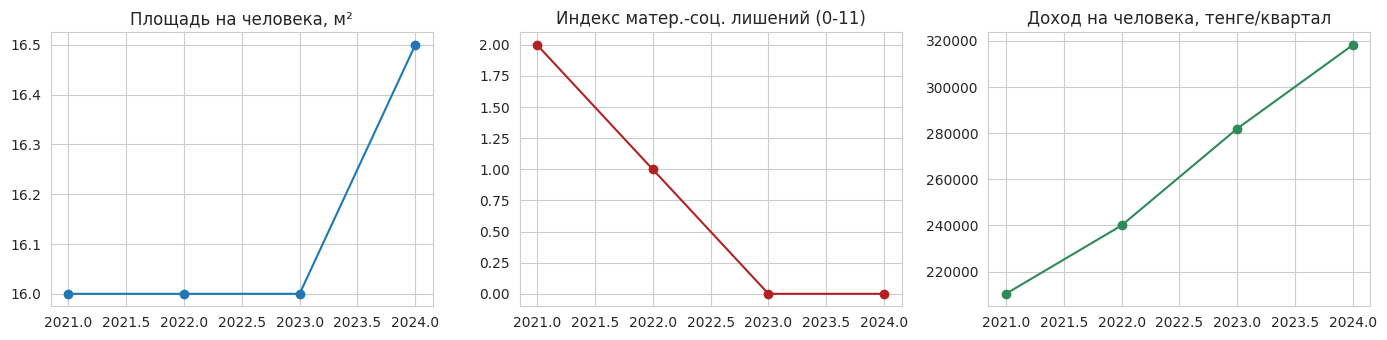

In [47]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
axes[0].plot(descriptive_dynamics["year"], descriptive_dynamics["median_area_per_person"], marker="o")
axes[0].set_title("Площадь на человека, м²")
axes[1].plot(descriptive_dynamics["year"], descriptive_dynamics["median_msd_count"], marker="o", color="firebrick")
axes[1].set_title("Индекс матер.-соц. лишений (0-11)")
axes[2].plot(descriptive_dynamics["year"], descriptive_dynamics["median_income_pc"], marker="o", color="seagreen")
axes[2].set_title("Доход на человека, тенге/квартал")
save(fig, "01_dynamics_2021_2024.png")


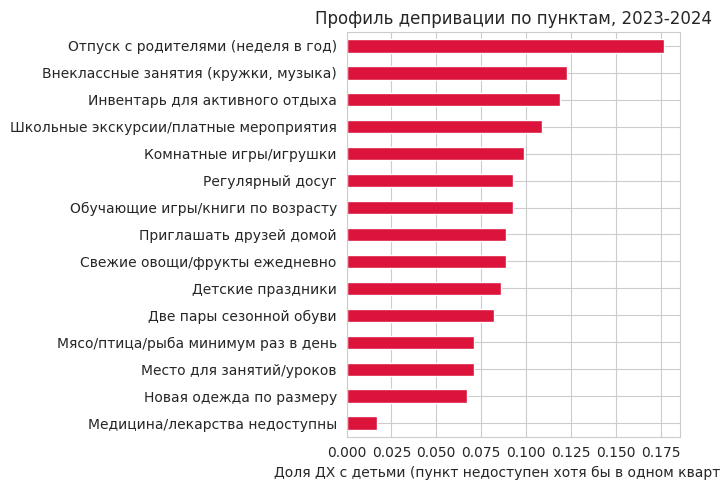

In [48]:
fig, ax = plt.subplots(figsize=(7, 5))
item_profile.sort_values().plot(kind="barh", ax=ax, color="crimson")
ax.set_xlabel("Доля ДХ с детьми (пункт недоступен хотя бы в одном квартале)"); ax.set_title("Профиль депривации по пунктам, 2023-2024")
save(fig, "02_item_level_deprivation_profile.png")


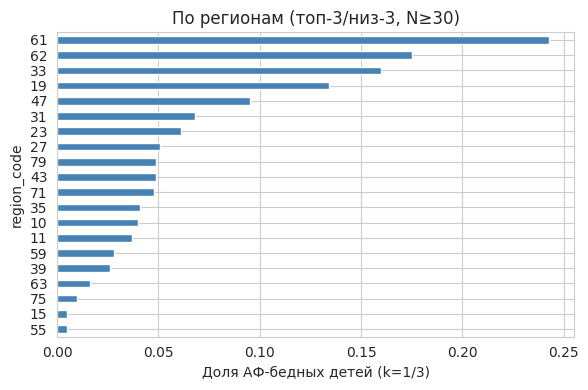

In [49]:
fig, ax = plt.subplots(figsize=(6, 4))
descriptive_by_region.sort_values("deprivation_rate")["deprivation_rate"].plot(kind="barh", ax=ax, color="steelblue")
ax.set_xlabel("Доля АФ-бедных детей (k=1/3)"); ax.set_title("По регионам (топ-3/низ-3, N≥30)")
save(fig, "03_deprivation_by_region.png")


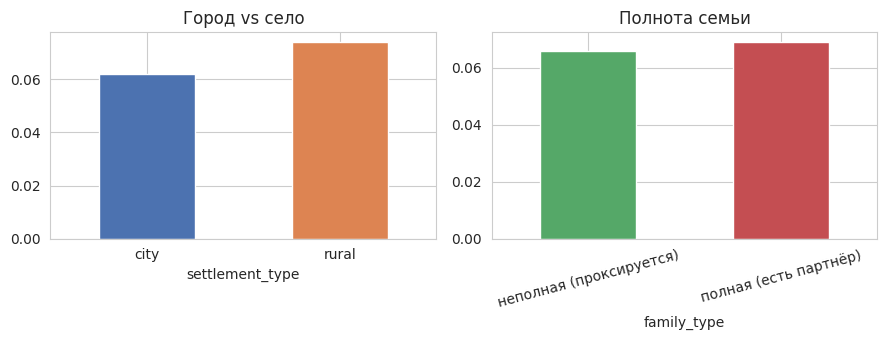

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
descriptive_by_settlement["deprivation_rate"].plot(kind="bar", ax=axes[0], color=["#4C72B0", "#DD8452"])
axes[0].set_title("Город vs село"); axes[0].tick_params(axis='x', rotation=0)
descriptive_by_family["deprivation_rate"].plot(kind="bar", ax=axes[1], color=["#55A868", "#C44E52"])
axes[1].set_title("Полнота семьи"); axes[1].tick_params(axis='x', rotation=15)
save(fig, "04_settlement_and_family.png")


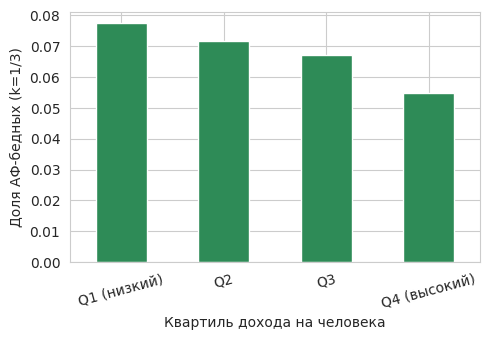

In [51]:
fig, ax = plt.subplots(figsize=(5, 3.5))
descriptive_by_income.groupby("income_quartile", observed=True)["deprivation_binary"].mean().plot(kind="bar", ax=ax, color="seagreen")
ax.set_ylabel("Доля АФ-бедных (k=1/3)"); ax.set_xlabel("Квартиль дохода на человека"); plt.xticks(rotation=15)
save(fig, "05_deprivation_by_income_quartile.png")


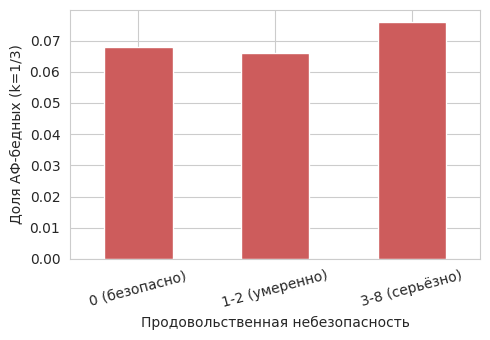

In [52]:
df_analysis["fies_group"] = pd.cut(df_analysis["food_insecurity_score"], [-0.1, 0, 2, 8],
                                    labels=["0 (безопасно)", "1-2 (умеренно)", "3-8 (серьёзно)"])
fig, ax = plt.subplots(figsize=(5, 3.5))
df_analysis.groupby("fies_group", observed=True)["deprivation_binary"].mean().plot(kind="bar", ax=ax, color="indianred")
ax.set_ylabel("Доля АФ-бедных (k=1/3)"); ax.set_xlabel("Продовольственная небезопасность"); plt.xticks(rotation=15)
save(fig, "06_deprivation_by_food_security.png")


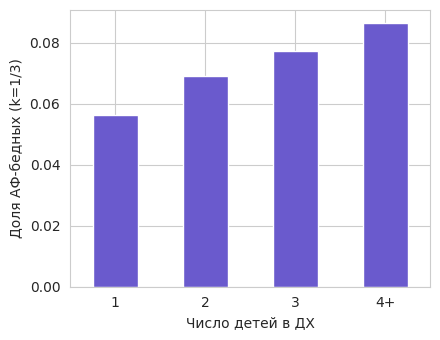

In [53]:
df_analysis["children_group"] = pd.cut(df_analysis["children_count"], [-0.1, 1, 2, 3, 20], labels=["1", "2", "3", "4+"])
fig, ax = plt.subplots(figsize=(4.5, 3.5))
df_analysis.groupby("children_group", observed=True)["deprivation_binary"].mean().plot(kind="bar", ax=ax, color="slateblue")
ax.set_xlabel("Число детей в ДХ"); ax.set_ylabel("Доля АФ-бедных (k=1/3)"); plt.xticks(rotation=0)
save(fig, "07_deprivation_by_children_count.png")


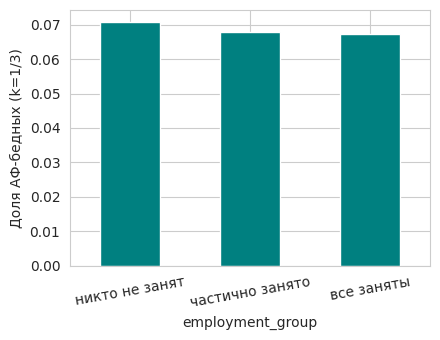

In [54]:
df_analysis["employment_group"] = pd.cut(df_analysis["employment_share"], [-0.1, 0, 0.5, 1.01],
                                          labels=["никто не занят", "частично занято", "все заняты"])
fig, ax = plt.subplots(figsize=(4.5, 3.5))
df_analysis.groupby("employment_group", observed=True)["deprivation_binary"].mean().plot(kind="bar", ax=ax, color="teal")
ax.set_ylabel("Доля АФ-бедных (k=1/3)"); plt.xticks(rotation=10)
save(fig, "08_deprivation_by_employment.png")


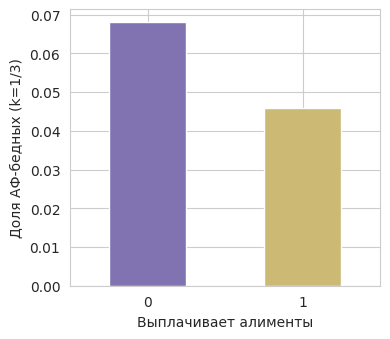

In [55]:
fig, ax = plt.subplots(figsize=(4, 3.5))
descriptive_by_alimony["deprivation_rate"].plot(kind="bar", ax=ax, color=["#8172B2", "#CCB974"])
ax.set_ylabel("Доля АФ-бедных (k=1/3)"); ax.set_xlabel("Выплачивает алименты"); plt.xticks(rotation=0)
save(fig, "09_deprivation_by_alimony.png")


## Milestone 15 — Двумерный анализ

In [56]:
from scipy import stats

def chi2_cramers_v(df, factor, outcome="deprivation_binary"):
    tab = pd.crosstab(df[factor], df[outcome])
    chi2, p, dof, _ = stats.chi2_contingency(tab)
    n = tab.sum().sum(); k = min(tab.shape) - 1
    v = np.sqrt(chi2 / (n * k)) if k > 0 else np.nan
    return pd.Series({"N": n, "chi2": round(chi2, 2), "dof": dof, "p_value": p, "cramers_v": round(v, 3)})

bivariate_categorical = pd.DataFrame({
    factor: chi2_cramers_v(df_analysis, factor)
    for factor in ["settlement_type", "region_code", "family_type", "alimony_paid", "children_group", "employment_group"]
}).T
bivariate_categorical


,N,chi2,dof,p_value,cramers_v
settlement_type,10888.0,6.89,1.0,8.677452e-03,0.025
region_code,10888.0,678.96,19.0,1.029710e-131,0.250
family_type,10888.0,0.29,1.0,5.909009e-01,0.005
alimony_paid,10888.0,1.39,1.0,2.381194e-01,0.011
children_group,10888.0,20.06,3.0,1.650834e-04,0.043
employment_group,10883.0,0.14,2.0,9.329946e-01,0.004


In [57]:
continuous_factors = ["msd_count", "food_insecurity_score", "total_income_pc", "employment_income_pc",
                      "family_benefit_income_pc", "area_per_person", "rooms_per_person",
                      "household_size", "children_count", "employment_share"]
rows = []
for f in continuous_factors:
    sub = df_analysis[[f, "deprivation_binary", "af_score_max"]].dropna()
    g0 = sub.loc[sub["deprivation_binary"] == 0, f]; g1 = sub.loc[sub["deprivation_binary"] == 1, f]
    p_mw = stats.mannwhitneyu(g0, g1, alternative="two-sided")[1] if len(g0) > 5 and len(g1) > 5 else np.nan
    rho, p_sp = stats.spearmanr(sub[f], sub["af_score_max"])      # тот же исход (АФ-счёт), что и в основной модели
    rows.append({"factor": f, "N": len(sub), "median_not_deprived": g0.median(), "median_deprived": g1.median(),
                 "mannwhitney_p": p_mw, "spearman_rho": round(rho, 3), "spearman_p": p_sp})
bivariate_continuous = pd.DataFrame(rows).set_index("factor")
bivariate_continuous


,N,median_not_deprived,median_deprived,mannwhitney_p,spearman_rho,spearman_p
factor,,,,,,
msd_count,10691,0.000000,0.000000,1.240289e-04,0.118,2.396448e-34
food_insecurity_score,10398,0.000000,0.000000,9.337553e-01,0.002,8.584394e-01
total_income_pc,10862,246992.125000,233497.170833,5.464536e-04,-0.028,3.906522e-03
employment_income_pc,10862,172765.625000,148350.000000,5.110876e-09,-0.040,3.265968e-05
family_benefit_income_pc,10862,0.000000,0.000000,2.113852e-06,0.023,1.871170e-02
area_per_person,10642,15.333333,15.600000,2.049711e-01,0.002,8.311624e-01
rooms_per_person,10642,0.666667,0.666667,6.864290e-01,-0.015,1.229020e-01
household_size,10888,4.000000,5.000000,1.244491e-10,0.037,1.268834e-04
children_count,10888,2.000000,2.000000,5.713786e-06,0.021,3.093585e-02


## Milestone 16 — Многомерная модель (логистическая регрессия)

`deprivation_binary` теперь означает АФ-бедность при k=1/3 (Milestone 6.1), а не «депривация
хотя бы по одному пункту из 14».

```
deprivation_binary ~ material_ladder + log(income_pc) + food_insecurity_score +
                      area_per_person + household_size + children_count +
                      employment_share + incomplete_family + alimony_paid +
                      family_benefit_flag + settlement_rural + year_2024 + C(region_code)
```

In [58]:
import statsmodels.api as sm
import statsmodels.formula.api as smf


def holm(pvals):
    """Поправка Холма на множественные сравнения."""
    p = np.asarray(pvals, float); n = len(p); adj = np.empty(n); running = 0.0
    for rank, idx in enumerate(np.argsort(p)):
        running = max(running, (n - rank) * p[idx]); adj[idx] = min(1.0, running)
    return adj


def fit_logit(data, f, cluster="region_code", maxiter=300):
    """Логит с ошибками, кластеризованными по региону (cluster=None — обычные)."""
    d = data.copy()
    if "region_code" in d and str(d["region_code"].dtype) == "category":
        d["region_code"] = d["region_code"].cat.remove_unused_categories()
    kw = dict(cov_type="cluster", cov_kwds={"groups": pd.factorize(d[cluster])[0]}) if cluster else {}
    try:
        m = smf.logit(f, data=d).fit(disp=0, maxiter=maxiter, **kw)
        if not m.mle_retvals.get("converged", True):
            m = smf.logit(f, data=d).fit(disp=0, method="bfgs", maxiter=3000, **kw)
        return m
    except Exception as e:
        print("fit failed:", type(e).__name__, str(e)[:120]); return None


model_vars = ["deprivation_binary", "material_ladder", "total_income_pc", "food_insecurity_score",
              "area_per_person", "household_size", "children_count", "employment_share",
              "family_type", "alimony_paid", "family_benefit_flag", "settlement_type", "region_code", "year"]
model_df = df_analysis[model_vars].dropna().copy()
model_df["settlement_rural"] = (model_df["settlement_type"] == "rural").astype(int)
model_df["incomplete_family"] = (model_df["family_type"] == "неполная (проксируется)").astype(int)
model_df["region_code"] = model_df["region_code"].astype("category")
model_df["year_2024"] = (model_df["year"] == 2024).astype(int)
model_df["log_income_pc"] = np.log1p(model_df["total_income_pc"].clip(lower=0))

formula = ("deprivation_binary ~ material_ladder + log_income_pc + food_insecurity_score + "
           "area_per_person + household_size + children_count + employment_share + "
           "incomplete_family + alimony_paid + family_benefit_flag + settlement_rural + year_2024 + C(region_code)")
logit_model = fit_logit(model_df, formula)
print("N (ДХ-годы) =", int(logit_model.nobs), "| событий:", int(model_df["deprivation_binary"].sum()),
      "| Pseudo R2 =", round(logit_model.prsquared, 3), "| кластеров (регионов):", model_df["region_code"].nunique())

model_terms = [c for c in logit_model.params.index if not c.startswith("C(region_code)") and c != "Intercept"]
ci_all = np.exp(logit_model.conf_int())
main_table = pd.concat([np.exp(logit_model.params[model_terms]).rename("OR"),
           ci_all.loc[model_terms].rename(columns={0: "CI_low", 1: "CI_high"}),
           logit_model.pvalues[model_terms].rename("p_value")], axis=1)
main_table["p_holm"] = holm(main_table["p_value"].values)
main_table.round(3)


N (ДХ-годы) = 10139 | событий: 692 | Pseudo R2 = 0.109 | кластеров (регионов): 20


,OR,CI_low,CI_high,p_value,p_holm
material_ladder,0.971,0.834,1.130,0.703,1.000
log_income_pc,1.111,0.951,1.298,0.185,1.000
food_insecurity_score,1.009,0.934,1.091,0.816,1.000
area_per_person,0.995,0.987,1.003,0.234,1.000
household_size,1.005,0.931,1.084,0.902,1.000
children_count,0.991,0.899,1.091,0.848,1.000
employment_share,1.176,0.986,1.401,0.071,0.847
incomplete_family,1.082,0.902,1.299,0.396,1.000
alimony_paid,0.899,0.416,1.943,0.787,1.000
family_benefit_flag,1.144,0.952,1.375,0.152,1.000


In [59]:
# Совместный тест региона: LR-тест на обычных (не кластерных) моделях.
# Wald-тест по 19 региональным дамми при кластеризации по тем же 20 регионам вырожден (ранг ковариации ≤ G−1).
from sklearn.metrics import roc_auc_score
from scipy import stats as _st
formula_noreg = formula.replace(" + C(region_code)", "")
m_plain = fit_logit(model_df, formula, cluster=None)
m_noreg = fit_logit(model_df, formula_noreg, cluster=None)
lr = 2 * (m_plain.llf - m_noreg.llf); dfree = model_df["region_code"].cat.remove_unused_categories().nunique() - 1
print(f"LR-тест региона: χ²={lr:.1f}, df={dfree}, p={_st.chi2.sf(lr, dfree):.3g}")
# Pseudo R² разных исходов сравнивать нельзя, поэтому — вклад региона на одном исходе
auc_table = pd.DataFrame({
    "модель": ["с регионом", "без региона"],
    "Pseudo R2": [m_plain.prsquared, m_noreg.prsquared],
    "AUC": [roc_auc_score(model_df["deprivation_binary"], m_plain.predict(model_df)),
            roc_auc_score(model_df["deprivation_binary"], m_noreg.predict(model_df))],
}).round(3)
auc_table


LR-тест региона: χ²=470.0, df=19, p=1.1e-87


,модель,Pseudo R2,AUC
0,с регионом,0.109,0.745
1,без региона,0.016,0.602


In [60]:
# Н1′: пункт × тип семьи (ДХ-год). 15 тестов → поправка Холма
rows = []
for i in range(1, 15):
    rows.append((ITEM_LABELS[i], f"dep_item_{i}"))
rows.append(("Медицина/лекарства недоступны", "dep_item_health"))
h1_rows = []
for lab, col in rows:
    sub = df_analysis[[col, "family_type"]].dropna()
    tab = pd.crosstab(sub["family_type"], sub[col])
    if tab.shape == (2, 2):
        chi2, p, _, _ = stats.chi2_contingency(tab)
    else:
        chi2, p = np.nan, np.nan
    rates = sub.groupby("family_type")[col].mean()
    h1_rows.append({"пункт": lab, "доля, полная": round(rates.get("полная (есть партнёр)", np.nan), 3),
                    "доля, неполная": round(rates.get("неполная (проксируется)", np.nan), 3), "N": len(sub), "p": p})
h1_family = pd.DataFrame(h1_rows)
h1_family["p_holm"] = holm(h1_family["p"].fillna(1).values)
h1_family.round(4)


,пункт,"доля, полная","доля, неполная",N,p,p_holm
0,Новая одежда по размеру,0.068,0.065,10856,0.6876,1.000
1,Две пары сезонной обуви,0.085,0.075,10829,0.1084,1.000
2,Свежие овощи/фрукты ежедневно,0.093,0.080,10858,0.0351,0.527
3,Мясо/птица/рыба минимум раз в день,0.073,0.066,10811,0.2230,1.000
4,Обучающие игры/книги по возрасту,0.096,0.087,10706,0.2029,1.000
5,Инвентарь для активного отдыха,0.116,0.125,10646,0.2016,1.000
6,Комнатные игры/игрушки,0.101,0.094,10603,0.3063,1.000
7,Место для занятий/уроков,0.072,0.068,10760,0.5226,1.000
8,Регулярный досуг,0.095,0.087,10568,0.2545,1.000
9,Детские праздники,0.088,0.083,10738,0.4347,1.000


**Как читать null-результаты здесь (см. раздел 0).** Если `log_income_pc` или
`area_per_person` окажутся незначимы — это **не** автоматически означает отсутствие
связи в реальных данных: пре-регистрированная проверка точности синтеза на похожей
housing-регрессии показала восстановление эффекта лишь на 12–73% в зависимости от
переменной. Значимые же коэффициенты интерпретировать увереннее — направление связи
синтез обычно не искажает.

## Milestone 17 — Сложный дизайн выборки и неопределённость оценок

In [61]:
print("Переменных весов/страт/PSU нет ни в одном источнике (Milestone 1.3).")
print("Дополнительно: это один синтетический срез без повторных версий (раздел 0) —")
print("стандартные ошибки занижены сверх обычного отсутствия весов; доверительные")
print("интервалы ниже следует читать как нижнюю границу истинной неопределённости.")


Переменных весов/страт/PSU нет ни в одном источнике (Milestone 1.3).
Дополнительно: это один синтетический срез без повторных версий (раздел 0) —
стандартные ошибки занижены сверх обычного отсутствия весов; доверительные
интервалы ниже следует читать как нижнюю границу истинной неопределённости.


## Milestone 18 — Мультиколлинеарность

In [62]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
vif_vars = ["material_ladder", "log_income_pc", "food_insecurity_score", "area_per_person",
            "household_size", "children_count", "employment_share", "incomplete_family",
            "alimony_paid", "family_benefit_flag", "settlement_rural", "year_2024"]
X_vif = sm.add_constant(model_df[vif_vars])
pd.DataFrame({"variable": vif_vars,
              "VIF": [variance_inflation_factor(X_vif.values, i + 1) for i in range(len(vif_vars))]}).round(2)


,variable,VIF
0,material_ladder,1.03
1,log_income_pc,1.48
2,food_insecurity_score,1.02
3,area_per_person,1.28
4,household_size,3.99
5,children_count,3.77
6,employment_share,1.09
7,incomplete_family,1.12
8,alimony_paid,1.00
9,family_benefit_flag,1.24


## Milestone 19 — Взаимодействия

In [63]:
formula_int = (formula + " + material_ladder:settlement_rural + log_income_pc:settlement_rural + "
               "food_insecurity_score:settlement_rural + incomplete_family:settlement_rural")
logit_int = fit_logit(model_df, formula_int)
int_terms = ["material_ladder:settlement_rural", "log_income_pc:settlement_rural",
             "food_insecurity_score:settlement_rural", "incomplete_family:settlement_rural"]
int_table = pd.concat([logit_int.params[int_terms].rename("coef"), logit_int.pvalues[int_terms].rename("p_value"),
           np.exp(logit_int.params[int_terms]).rename("OR")], axis=1)
int_table["p_holm"] = holm(int_table["p_value"].values)     # 4 взаимодействия → поправка Холма
int_table.round(3)


,coef,p_value,OR,p_holm
material_ladder:settlement_rural,0.116,0.155,1.123,0.574
log_income_pc:settlement_rural,0.149,0.489,1.161,0.883
food_insecurity_score:settlement_rural,-0.177,0.144,0.837,0.574
incomplete_family:settlement_rural,0.123,0.442,1.131,0.883


## Milestone 20 — Межгодовой анализ

**Это пулинг 4 независимых годовых срезов, не панель** (раздел 0 / Milestone 1.2) —
тренд означает «отличаются ли годовые срезы», а не «что произошло с теми же ДХ».

In [64]:
_m = material.dropna(subset=["msd_count"])
print(f"msd_count vs год: rho={stats.spearmanr(_m['year'], _m['msd_count']).statistic:.3f}, "
      f"p={stats.spearmanr(_m['year'], _m['msd_count']).pvalue:.4f}  (наблюдения — респонденты-кварталы, p ориентировочные)")
_ml = material.dropna(subset=["material_ladder"])
print(f"material_ladder vs год: rho={stats.spearmanr(_ml['year'], _ml['material_ladder']).statistic:.3f}, "
      f"p={stats.spearmanr(_ml['year'], _ml['material_ladder']).pvalue:.4f}")
# Номинальный доход растёт из-за инфляции, поэтому тест «доход vs год» бессмыслен.
# Вместо него — доход в единицах прожиточного минимума (известен для 2023 и 2024):
_inc = income_pc.dropna(subset=["total_income_pc"]).copy()
_inc = _inc[_inc["year"].isin(PM_MONTHLY)]
_inc["income_pc_in_PM"] = _inc["total_income_pc"] / (3 * _inc["year"].map(PM_MONTHLY))
print(_inc.groupby("year")["income_pc_in_PM"].median().round(3).to_dict(), "← медиана дохода на чел. в ПМ (квартальный доход / 3 ПМ)")


msd_count vs год: rho=-0.209, p=0.0000  (наблюдения — респонденты-кварталы, p ориентировочные)
material_ladder vs год: rho=0.101, p=0.0000
{2023: 2.317, 2024: 2.444} ← медиана дохода на чел. в ПМ (квартальный доход / 3 ПМ)


## Milestone 21 — Robustness checks

In [65]:
robustness_rows = [("Основная: АФ k=1/3, ДХ-год, кластеры по региону", logit_model)]

model_df2 = df_analysis[["deprivation_count", "af_score_max", "material_ladder", "total_income_pc", "food_insecurity_score",
                          "area_per_person", "household_size", "children_count", "employment_share",
                          "family_type", "alimony_paid", "family_benefit_flag", "settlement_type",
                          "region_code", "year"]].dropna().copy()
model_df2["dep_ge2"] = (model_df2["deprivation_count"] >= 2).astype(int)
for _k in (0.2, 0.4, 0.5):
    model_df2[f"dep_k{int(_k * 100)}"] = (model_df2["af_score_max"] >= _k).astype(int)
model_df2["settlement_rural"] = (model_df2["settlement_type"] == "rural").astype(int)
model_df2["incomplete_family"] = (model_df2["family_type"] == "неполная (проксируется)").astype(int)
model_df2["region_code"] = model_df2["region_code"].astype("category")
model_df2["year_2024"] = (model_df2["year"] == 2024).astype(int)
model_df2["log_income_pc"] = np.log1p(model_df2["total_income_pc"].clip(lower=0))
robustness_rows.append(("Alt. исход: простой счёт ≥2 из 14 (не АФ)", fit_logit(model_df2, formula.replace("deprivation_binary", "dep_ge2"))))
for _k in (0.2, 0.4, 0.5):
    robustness_rows.append((f"Alt. порог АФ k={_k}", fit_logit(model_df2, formula.replace("deprivation_binary", f"dep_k{int(_k * 100)}"))))

robustness_rows.append(("Без дохода (только material_ladder)", fit_logit(model_df, formula.replace(" + log_income_pc", ""))))
robustness_rows.append(("Без лестницы (только доход)", fit_logit(model_df, formula.replace("material_ladder + ", ""))))

model_df3 = df_analysis[["deprivation_binary", "material_ladder", "total_income_pc", "food_insecurity_score",
                          "rooms_per_person", "household_size", "children_count", "employment_share",
                          "family_type", "alimony_paid", "family_benefit_flag", "settlement_type",
                          "region_code", "year"]].dropna().copy()
model_df3["settlement_rural"] = (model_df3["settlement_type"] == "rural").astype(int)
model_df3["incomplete_family"] = (model_df3["family_type"] == "неполная (проксируется)").astype(int)
model_df3["region_code"] = model_df3["region_code"].astype("category")
model_df3["year_2024"] = (model_df3["year"] == 2024).astype(int)
model_df3["log_income_pc"] = np.log1p(model_df3["total_income_pc"].clip(lower=0))
robustness_rows.append(("Alt. жильё: rooms_per_person", fit_logit(model_df3, formula.replace("area_per_person", "rooms_per_person"))))

formula_no_year = formula.replace(" + year_2024", "")
for _y in AF_YEARS:
    robustness_rows.append((f"Только {_y}", fit_logit(model_df[model_df["year"] == _y], formula_no_year)))

formula_no_settlement = formula.replace(" + settlement_rural", "")
robustness_rows.append(("Только город", fit_logit(model_df[model_df["settlement_rural"] == 0], formula_no_settlement)))
robustness_rows.append(("Только село", fit_logit(model_df[model_df["settlement_rural"] == 1], formula_no_settlement)))


def key_coef(m, name):
    if m is None or name not in m.params.index:
        return (np.nan, np.nan)
    return (round(np.exp(m.params[name]), 3), round(m.pvalues[name], 4))


robustness_summary = pd.DataFrame([
    {"specification": name, "N": int(m.nobs) if m is not None else np.nan,
     "converged": bool(m.mle_retvals.get("converged", True)) if m is not None else False,
     "OR_material_ladder": key_coef(m, "material_ladder")[0], "p_material_ladder": key_coef(m, "material_ladder")[1],
     "OR_income": key_coef(m, "log_income_pc")[0], "p_income": key_coef(m, "log_income_pc")[1],
     "OR_food_insecurity": key_coef(m, "food_insecurity_score")[0], "p_food_insecurity": key_coef(m, "food_insecurity_score")[1],
     "OR_incomplete_family": key_coef(m, "incomplete_family")[0], "p_incomplete_family": key_coef(m, "incomplete_family")[1],
     "OR_employment": key_coef(m, "employment_share")[0], "p_employment": key_coef(m, "employment_share")[1]}
    for name, m in robustness_rows
])
_failed = [n for n, m in robustness_rows if m is None]
print("Спецификаций:", len(robustness_rows), "| не оценились:", _failed if _failed else "нет")
robustness_summary


/usr/local/lib/python3.13/dist-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/usr/local/lib/python3.13/dist-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/usr/local/lib/python3.13/dist-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/usr/local/lib/python3.13/dist-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


Спецификаций: 12 | не оценились: нет


,specification,N,converged,OR_material_ladder,p_material_ladder,OR_income,p_income,OR_food_insecurity,p_food_insecurity,OR_incomplete_family,p_incomplete_family,OR_employment,p_employment
0,"Основная: АФ k=1/3, ДХ-год, кластеры по региону",10139,True,0.971,0.7027,1.111,0.1845,1.009,0.8162,1.082,0.3964,1.176,0.0706
1,Alt. исход: простой счёт ≥2 из 14 (не АФ),10139,True,0.948,0.2913,0.933,0.2770,0.965,0.2336,0.984,0.7445,1.053,0.4660
2,Alt. порог АФ k=0.2,10139,True,0.921,0.2590,0.974,0.7343,0.924,0.0059,1.016,0.8312,1.141,0.0872
3,Alt. порог АФ k=0.4,10139,True,1.019,0.8317,1.212,0.0487,1.007,0.9169,1.096,0.4239,1.302,0.0554
4,Alt. порог АФ k=0.5,10139,True,0.998,0.9831,1.281,0.1497,0.869,0.0710,1.099,0.4879,1.175,0.4069
5,Без дохода (только material_ladder),10139,True,0.970,0.6958,NaN,NaN,1.008,0.8354,1.074,0.4287,1.205,0.0315
6,Без лестницы (только доход),10139,True,NaN,NaN,1.112,0.1773,1.013,0.7352,1.082,0.3977,1.174,0.0723
7,Alt. жильё: rooms_per_person,10139,True,0.971,0.7086,1.112,0.1783,1.009,0.8191,1.073,0.4547,1.177,0.0654
8,Только 2023,5007,True,1.009,0.9112,1.269,0.0145,0.980,0.6915,1.021,0.8690,1.329,0.0570
9,Только 2024,5132,True,0.992,0.9146,0.930,0.5615,1.104,0.3383,1.111,0.5446,0.964,0.8259


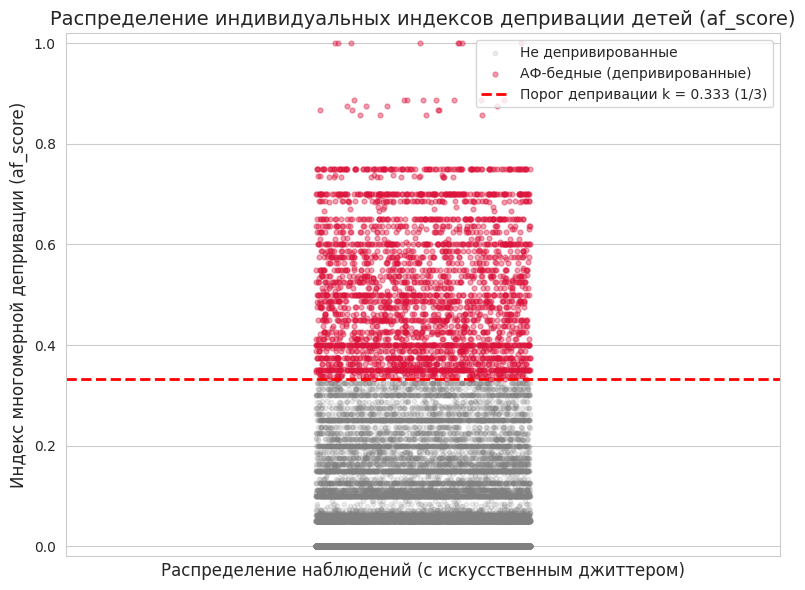

In [66]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# Подготовка данных
plot_df = af_detail.dropna(subset=['af_score']).copy()

# Создаем случайный шум (jitter) по оси X для визуального разделения точек с одинаковыми значениями af_score
np.random.seed(42)
plot_df['jitter_x'] = np.random.uniform(-0.3, 0.3, size=len(plot_df))

fig, ax = plt.subplots(figsize=(8, 6))

# Разделяем точки на бедных и небедных для покраски
poor_mask = plot_df['af_score'] >= K_DEFAULT

# Отображаем точки
ax.scatter(
    plot_df.loc[~poor_mask, 'jitter_x'],
    plot_df.loc[~poor_mask, 'af_score'],
    alpha=0.15,
    color='grey',
    s=10,
    label='Не депривированные'
)
ax.scatter(
    plot_df.loc[poor_mask, 'jitter_x'],
    plot_df.loc[poor_mask, 'af_score'],
    alpha=0.4,
    color='crimson',
    s=12,
    label='АФ-бедные (депривированные)'
)

# Добавляем линию разделения
ax.axhline(y=K_DEFAULT, color='red', linestyle='--', linewidth=2, label=f'Порог депривации k = {K_DEFAULT:.3f} (1/3)')

# Оформление графика
ax.set_title('Распределение индивидуальных индексов депривации детей (af_score)', fontsize=14)
ax.set_ylabel('Индекс многомерной депривации (af_score)', fontsize=12)
ax.set_xlabel('Распределение наблюдений (с искусственным джиттером)', fontsize=12)
ax.set_xlim(-1, 1)
ax.set_ylim(-0.02, 1.02)
ax.set_xticks([]) # Убираем деления по оси X, так как они не несут физического смысла
ax.legend(loc='upper right', frameon=True)

save(fig, '10_af_score_scatter_with_threshold.png')

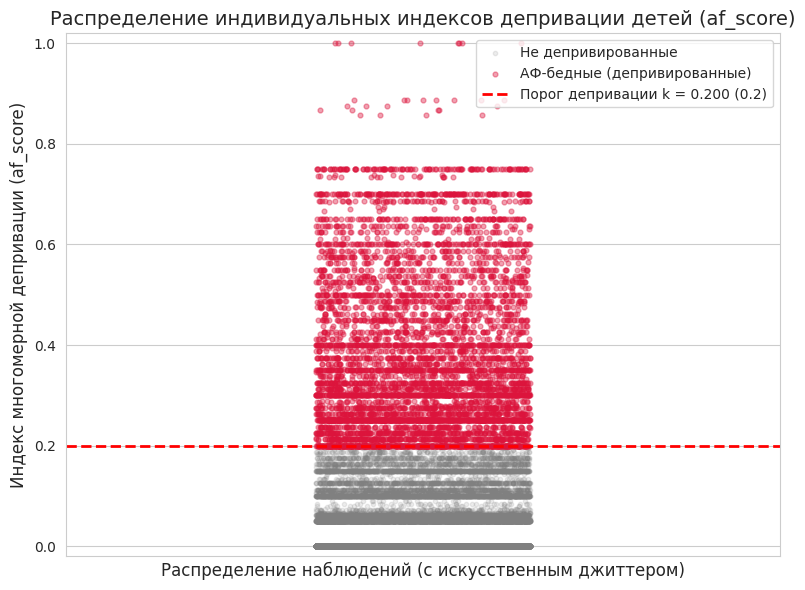

In [67]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# Подготовка данных
plot_df = af_detail.dropna(subset=['af_score']).copy()

# Создаем случайный шум (jitter) по оси X для визуального разделения точек с одинаковыми значениями af_score
np.random.seed(42)
plot_df['jitter_x'] = np.random.uniform(-0.3, 0.3, size=len(plot_df))

fig, ax = plt.subplots(figsize=(8, 6))

# Разделяем точки на бедных и небедных для покраски
poor_mask = plot_df['af_score'] >= 0.2

# Отображаем точки
ax.scatter(
    plot_df.loc[~poor_mask, 'jitter_x'],
    plot_df.loc[~poor_mask, 'af_score'],
    alpha=0.15,
    color='grey',
    s=10,
    label='Не депривированные'
)
ax.scatter(
    plot_df.loc[poor_mask, 'jitter_x'],
    plot_df.loc[poor_mask, 'af_score'],
    alpha=0.4,
    color='crimson',
    s=12,
    label='АФ-бедные (депривированные)'
)

# Добавляем линию разделения
ax.axhline(y=0.2, color='red', linestyle='--', linewidth=2, label=f'Порог депривации k = {0.2:.3f} (0.2)')

# Оформление графика
ax.set_title('Распределение индивидуальных индексов депривации детей (af_score)', fontsize=14)
ax.set_ylabel('Индекс многомерной депривации (af_score)', fontsize=12)
ax.set_xlabel('Распределение наблюдений (с искусственным джиттером)', fontsize=12)
ax.set_xlim(-1, 1)
ax.set_ylim(-0.02, 1.02)
ax.set_xticks([]) # Убираем деления по оси X, так как они не несут физического смысла
ax.legend(loc='upper right', frameon=True)

save(fig, '10b_af_score_scatter_k02.png')

In [68]:
# Только записи с ВАЛИДНЫМ индексом (раньше NaN считался «не бедным» и попадал в знаменатель)
_valid = af_detail["af_score"].dropna()
total_valid = len(_valid)
poor_count = int((_valid >= 0.2).sum())
non_poor_count = total_valid - poor_count
print(f"Всего ДХ-кварталов с валидным индексом депривации: {total_valid:,}")
print(f"Без многомерной депривации (af_score < 0.2): {non_poor_count:,} ({non_poor_count/total_valid:.1%})")
print(f"С многомерной депривацией (АФ-бедные, af_score >= 0.2): {poor_count:,} ({poor_count/total_valid:.1%})")


Всего ДХ-кварталов с валидным индексом депривации: 43,552
Без многомерной депривации (af_score < 0.2): 37,292 (85.6%)
С многомерной депривацией (АФ-бедные, af_score >= 0.2): 6,260 (14.4%)


**Дополнительная проверка: `msd_count` вместо отдельного регрессора.** Это
самый сильный двумерный коррелят (Milestone 15.2); проверяем, меняет ли его добавление
выводы по самооценке/доходу.

In [69]:
_d = df_analysis[model_vars + ["msd_count", "msd_count_core"]].dropna().copy()
_d["settlement_rural"] = (_d["settlement_type"] == "rural").astype(int)
_d["incomplete_family"] = (_d["family_type"] == "неполная (проксируется)").astype(int)
_d["region_code"] = _d["region_code"].astype("category")
_d["year_2024"] = (_d["year"] == 2024).astype(int)
_d["log_income_pc"] = np.log1p(_d["total_income_pc"].clip(lower=0))
m_msd = fit_logit(_d, formula + " + msd_count")
# msd_count_core — без пунктов, по смыслу дублирующих детские (отпуск, друзья, досуг, обувь, одежда):
# один и тот же респондент отвечает на похожие вопросы о взрослых и о детях → связь отчасти тавтологична
m_core = fit_logit(_d, formula + " + msd_count_core")
_vars = ["msd_count", "material_ladder", "log_income_pc"]
_ci = np.exp(m_msd.conf_int())
msd_check = pd.DataFrame({"OR": np.exp(m_msd.params[_vars]), "CI_low": _ci.loc[_vars, 0],
                          "CI_high": _ci.loc[_vars, 1], "p_value": m_msd.pvalues[_vars]}).round(4)
_vc = ["msd_count_core", "material_ladder", "log_income_pc"]
_cic = np.exp(m_core.conf_int())
msd_check_core = pd.DataFrame({"OR": np.exp(m_core.params[_vc]), "CI_low": _cic.loc[_vc, 0],
                               "CI_high": _cic.loc[_vc, 1], "p_value": m_core.pvalues[_vc]}).round(4)
print("N =", int(m_msd.nobs), "| Pseudo R2 =", round(m_msd.prsquared, 3), "← с полным msd_count")
display(msd_check)
print("Pseudo R2 =", round(m_core.prsquared, 3), "← с msd_count_core (без пересекающихся пунктов)")
msd_check_core


N = 9958 | Pseudo R2 = 0.124 ← с полным msd_count


,OR,CI_low,CI_high,p_value
msd_count,1.1451,1.0825,1.2113,0.0000
material_ladder,0.9716,0.8428,1.1200,0.6910
log_income_pc,1.1216,0.9700,1.2969,0.1214


Pseudo R2 = 0.125 ← с msd_count_core (без пересекающихся пунктов)


,OR,CI_low,CI_high,p_value
msd_count_core,1.2676,1.1454,1.4027,0.0000
material_ladder,0.9752,0.8474,1.1224,0.7265
log_income_pc,1.1209,0.9659,1.3007,0.1328


## Milestone 22 — Пропуски и выбросы

In [70]:
outlier_check = df_analysis[["area_per_person", "rooms_per_person", "household_size", "children_count",
                             "msd_count", "food_insecurity_score", "total_income_pc"]].describe(
    percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]).T[["min", "1%", "5%", "50%", "95%", "99%", "max"]].round(0)
outlier_check


,min,1%,5%,50%,95%,99%,max
area_per_person,2.0,6.0,8.0,15.0,35.0,52.0,115.0
rooms_per_person,0.0,0.0,0.0,1.0,1.0,2.0,4.0
household_size,2.0,2.0,3.0,5.0,8.0,9.0,12.0
children_count,1.0,1.0,1.0,2.0,4.0,5.0,9.0
msd_count,0.0,0.0,0.0,0.0,6.0,10.0,11.0
food_insecurity_score,0.0,0.0,0.0,0.0,1.0,3.0,8.0
total_income_pc,21628.0,76593.0,114246.0,246140.0,445456.0,552494.0,1418256.0


Выбросы не удаляются автоматически; доход логарифмируется, что снижает влияние
отдельных крупных значений. На синтетических данных «выброс» может означать как
правдоподобную крайнюю реальную комбинацию, скопированную генератором, так и артефакт
дерева решений — различить эти два случая по самим данным нельзя.

## Milestone 23 — Итоговая проверка гипотез

In [71]:
def sig_label(p, thresh=0.05):
    return "н/д" if p != p else ("значима" if p < thresh else "не значима")

def logit_row(label, var, note=None):
    p = logit_model.pvalues.get(var, np.nan)
    ci = [round(ci_all.loc[var, 0], 3), round(ci_all.loc[var, 1], 3)] if var in ci_all.index else "—"
    interp = f"Ассоциация {sig_label(p)}" + (f"; {note}" if note else "")
    return [label, var, "Логит (кластеры по региону), OR", round(np.exp(logit_model.params.get(var, np.nan)), 3), ci, p, interp]

hyp_rows = [
    ["Регион проживания", "region_code", "χ² (Cramér's V)", bivariate_categorical.loc["region_code", "cramers_v"], "—",
     bivariate_categorical.loc["region_code", "p_value"], f"Ассоциация {sig_label(bivariate_categorical.loc['region_code', 'p_value'])}"],
    ["Тип поселения (двумерно)", "settlement_type", "χ² (Cramér's V)", bivariate_categorical.loc["settlement_type", "cramers_v"], "—",
     bivariate_categorical.loc["settlement_type", "p_value"], f"Ассоциация {sig_label(bivariate_categorical.loc['settlement_type', 'p_value'])}"],
    logit_row("Тип поселения — село (с контролем)", "settlement_rural"),
    logit_row("Материальное положение (самооценка)", "material_ladder"),
    logit_row("Доход на человека, log (D004)", "log_income_pc", "возможно занижено синтезом — раздел 0"),
    logit_row("Продовольственная безопасность", "food_insecurity_score"),
    logit_row("Площадь жилья на человека", "area_per_person", "возможно занижено синтезом сильнее прочих — раздел 0/Milestone 9"),
    logit_row("Неполная семья (прокси)", "incomplete_family"),
    logit_row("Алименты выплачиваются (D004)", "alimony_paid", "фиксирует плательщиков, не получателей"),
    logit_row("Гос. пособие семье с детьми (D004/GR8)", "family_benefit_flag"),
    logit_row("Число детей в ДХ", "children_count"),
    logit_row("Размер ДХ", "household_size"),
    logit_row("Занятость взрослых", "employment_share"),
    logit_row("Год 2024 vs 2023", "year_2024"),
]
hypothesis_results = pd.DataFrame(hyp_rows, columns=["Hypothesis", "Variable", "Method", "Effect", "CI", "p_value", "Interpretation"])
_m = hypothesis_results["Method"].str.startswith("Логит")
hypothesis_results.loc[_m, "p_holm"] = holm(hypothesis_results.loc[_m, "p_value"].values)
hypothesis_results["Interpretation (с поправкой Холма)"] = [
    ("значима" if (p == p and p < 0.05) else "не значима") if m else "—"
    for p, m in zip(hypothesis_results["p_holm"], _m)]
hypothesis_results


,Hypothesis,Variable,Method,Effect,CI,p_value,Interpretation,p_holm,Interpretation (с поправкой Холма)
0,Регион проживания,region_code,χ² (Cramér's V),0.250,—,1.029710e-131,Ассоциация значима,NaN,—
1,Тип поселения (двумерно),settlement_type,χ² (Cramér's V),0.025,—,8.677452e-03,Ассоциация значима,NaN,—
2,Тип поселения — село (с контролем),settlement_rural,"Логит (кластеры по региону), OR",1.000,"[0.858, 1.166]",9.998553e-01,Ассоциация не значима,1.000000,не значима
3,Материальное положение (самооценка),material_ladder,"Логит (кластеры по региону), OR",0.971,"[0.834, 1.13]",7.026702e-01,Ассоциация не значима,1.000000,не значима
4,"Доход на человека, log (D004)",log_income_pc,"Логит (кластеры по региону), OR",1.111,"[0.951, 1.298]",1.845428e-01,Ассоциация не значима; возможно занижено синте...,1.000000,не значима
5,Продовольственная безопасность,food_insecurity_score,"Логит (кластеры по региону), OR",1.009,"[0.934, 1.091]",8.162120e-01,Ассоциация не значима,1.000000,не значима
6,Площадь жилья на человека,area_per_person,"Логит (кластеры по региону), OR",0.995,"[0.987, 1.003]",2.339229e-01,Ассоциация не значима; возможно занижено синте...,1.000000,не значима
7,Неполная семья (прокси),incomplete_family,"Логит (кластеры по региону), OR",1.082,"[0.902, 1.299]",3.964420e-01,Ассоциация не значима,1.000000,не значима
8,Алименты выплачиваются (D004),alimony_paid,"Логит (кластеры по региону), OR",0.899,"[0.416, 1.943]",7.865075e-01,"Ассоциация не значима; фиксирует плательщиков,...",1.000000,не значима
9,Гос. пособие семье с детьми (D004/GR8),family_benefit_flag,"Логит (кластеры по региону), OR",1.144,"[0.952, 1.375]",1.515788e-01,Ассоциация не значима,1.000000,не значима


## Milestone 24 — Интерпретация

Числа формируются кодом из уже посчитанных таблиц.

In [72]:
sig = lambda p: "значима" if p < 0.05 else "не значима"
dep_rate = df_analysis.groupby("year")["deprivation_binary"].mean()
top_items = item_profile.head(3)
def orci(var):
    return f"OR={np.exp(logit_model.params[var]):.3f} [{ci_all.loc[var,0]:.3f}; {ci_all.loc[var,1]:.3f}], p={logit_model.pvalues[var]:.3g} ({sig(logit_model.pvalues[var])})"

print("ОПИСАТЕЛЬНЫЕ ФАКТЫ")
print(f"- Доля АФ-бедных ДХ с детьми (k=1/3, хотя бы в одном квартале): 2023 — {dep_rate.get(2023, float('nan')):.1%}, 2024 — {dep_rate.get(2024, float('nan')):.1%}.")
print("- Самые частые лишения: " + "; ".join(f"{k} ({v:.1%})" for k, v in top_items.items()) + ".")
print(f"- Село vs город: {descriptive_by_settlement.loc['rural','deprivation_rate']:.1%} vs {descriptive_by_settlement.loc['city','deprivation_rate']:.1%}.")
print()
print("СТАТИСТИЧЕСКИЕ РЕЗУЛЬТАТЫ (полная модель, N=%d)" % logit_model.nobs)
for lab, var in [("Материальная лестница", "material_ladder"), ("log дохода на человека (D004)", "log_income_pc"),
                 ("Продбезопасность (FIES)", "food_insecurity_score"), ("Площадь на человека", "area_per_person"),
                 ("Неполная семья", "incomplete_family"), ("Алименты выплачиваются", "alimony_paid"),
                 ("Гос. пособие семье с детьми", "family_benefit_flag"), ("Село", "settlement_rural"),
                 ("Число детей", "children_count"), ("Размер ДХ", "household_size")]:
    print(f"- {lab}: {orci(var)}")
print(f"- Регион: двумерно Cramér's V={bivariate_categorical.loc['region_code','cramers_v']}, p={bivariate_categorical.loc['region_code','p_value']:.2g}.")
n_lad = int((robustness_summary["p_material_ladder"] < 0.05).sum()); n_lad_tot = int(robustness_summary["p_material_ladder"].notna().sum())
n_inc = int((robustness_summary["p_income"] < 0.05).sum()); n_inc_tot = int(robustness_summary["p_income"].notna().sum())
print(f"- Устойчивость: material_ladder значима в {n_lad} из {n_lad_tot} спецификаций; доход — в {n_inc} из {n_inc_tot}.")
print(f"- msd_count при добавлении: OR={np.exp(m_msd.params['msd_count']):.3f} за пункт, p={m_msd.pvalues['msd_count']:.3g} "
      f"({sig(m_msd.pvalues['msd_count'])}); при этом material_ladder p={m_msd.pvalues['material_ladder']:.3g}, доход p={m_msd.pvalues['log_income_pc']:.3g}.")
print(f"- Pseudo R² модели: {logit_model.prsquared:.3f}.")


ОПИСАТЕЛЬНЫЕ ФАКТЫ
- Доля АФ-бедных ДХ с детьми (k=1/3, хотя бы в одном квартале): 2023 — 6.9%, 2024 — 6.7%.
- Самые частые лишения: Отпуск с родителями (неделя в год) (17.7%); Внеклассные занятия (кружки, музыка) (12.3%); Инвентарь для активного отдыха (11.9%).
- Село vs город: 7.4% vs 6.2%.

СТАТИСТИЧЕСКИЕ РЕЗУЛЬТАТЫ (полная модель, N=10139)
- Материальная лестница: OR=0.971 [0.834; 1.130], p=0.703 (не значима)
- log дохода на человека (D004): OR=1.111 [0.951; 1.298], p=0.185 (не значима)
- Продбезопасность (FIES): OR=1.009 [0.934; 1.091], p=0.816 (не значима)
- Площадь на человека: OR=0.995 [0.987; 1.003], p=0.234 (не значима)
- Неполная семья: OR=1.082 [0.902; 1.299], p=0.396 (не значима)
- Алименты выплачиваются: OR=0.899 [0.416; 1.943], p=0.787 (не значима)
- Гос. пособие семье с детьми: OR=1.144 [0.952; 1.375], p=0.152 (не значима)
- Село: OR=1.000 [0.858; 1.166], p=1 (не значима)
- Число детей: OR=0.991 [0.899; 1.091], p=0.848 (не значима)
- Размер ДХ: OR=1.005 [0.931; 1.084], 

**Интерпретация с учётом синтетической природы данных (раздел 0).**
Наблюдательный дизайн: ассоциации не доказывают причинность. Синтез к тому же ослабляет связи между
столбцами, поэтому *отсутствие* связи в этих данных не равно её отсутствию в реальных. Числа ниже — по прогону
на 2023–2024 (для Части I это все данные, для Части II перезапустите ноутбук с 2022 годом).

**Что изменилось по сравнению с первой версией ноутбука (и почему прежние «значимые» эффекты исчезли).**
- Ответы на блок GR45/GR46 **одинаковы во всех четырёх кварталах** у каждого ДХ (проверено: 0% ДХ с разными
  ответами). Прежние 41 тыс. наблюдений были ~10 тыс. ДХ, скопированных по 4 раза, а p-значения считались так,
  будто наблюдения независимы. Теперь единица — ДХ-год (≈10 тыс.), ошибки кластеризованы по региону.
- Прежние «значимые» занятость (p=0.008) и `msd_count` (p≈10⁻⁶⁷) были во многом следствием этого. После
  исправления: **занятость** OR≈1.18, p≈0.07, после поправки Холма — не значима; `msd_count` остаётся значимым
  (OR≈1.15 за пункт), но см. оговорку ниже.
- Значимых предикторов после поправки Холма в основной модели нет, кроме региона.

**Что остаётся.**
- **Регион** — единственный сильный фактор (V Крамера ≈0.25; AUC 0.75 с регионом против 0.60 без него).
- **`msd_count`** (индекс лишений взрослых) связан с депривацией ДХ с детьми, но **не следует читать это как
  «фактор»**: один и тот же респондент в одной анкете отвечает на похожие взрослые и детские пункты (отпуск,
  друзья, досуг, обувь, одежда). Без этих пунктов (`msd_count_core`) связь сохраняется (OR≈1.27 за пункт), то есть
  она не только механическая, но и интерпретируется как «общая тяжесть лишений в ДХ», а не причина.
- Материальная лестница, доход на человека, продбезопасность, жильё, полнота семьи, пособие, алименты, село/город,
  число детей и размер ДХ не значимы (ни в основной модели, ни в робастности: лестница значима в 0 из 11
  спецификаций, доход — в 1 из 11, только в подвыборке 2023).
- Взаимодействия с типом поселения после поправки Холма не значимы.
- Н1′: ни один из 15 пунктов не различается между полными и неполными семьями после поправки Холма.

## Milestone 25 — Итоговые выводы

1. Модуль депривации детей есть только в 2023–2024 (ограничение анкеты).
2. Самые частые лишения — «развивающие/досуговые» (отпуск с родителями ≈18%, внеклассные занятия ≈12%,
   спортинвентарь ≈12% ДХ с детьми), а не базовые нужды.
3. Критерий — метод Алкаер–Фостера (k=1/3), доля АФ-бедных ДХ с детьми ≈6.9% (2023) и ≈6.7% (2024). Все подписи
   относятся к **ДХ с детьми**, а не к отдельным детям: ответ даёт один респондент на ДХ.
4. Из факторов основной гипотезы устойчивая связь есть у региона; связь с индексом лишений взрослых есть, но
   интерпретируется с оговоркой выше. Остальные факторы в этих данных значимой связи не показали; с учётом
   раздела 0 это не равно «связи нет в реальности».
5. Н1′: различий по пунктам между типами семьи нет (Холм); тип семьи — прокси.

### Ограничения
- Данные синтетические; один срез; ошибки занижены сверх обычного.
- ДХ-год = «хотя бы один квартал» (для GR45 кварталы идентичны, поэтому это то же, что отдельный квартал).
- «Есть дети» определяется по возрасту <18; у ~10% ДХ он расходится с флагом `GR40` (ДХ без членов <18 лет, но
  с ответами на детский блок, исключены: ≈1.7 тыс. записей в год).
- Номинальные доходы разных лет несопоставимы; сравнения лет — в единицах прожиточного минимума (известен для
  2023–2024).
- Спецификация АФ — собственная, не официальная казахстанская.
- Падение продовольственной небезопасности 2023→2024 (0.19→0.11) и ряд индикаторов Части III (1.4, 5.2, 7.3)
  может быть разрывом ряда, а не реальной динамикой: сопоставимость между годами не проверена.
- Наблюдательный дизайн.

### Направления дальнейшей работы
1. Повторить на настоящих данных; 2. сверить АФ-спецификацию с официальной; 3. словарь `kv_vopr_11` (GR9–GR23);
4. многоуровневая модель при наличии PSU/страт; 5. критерии 2.1 и 5.4 теперь считаются по фильтрующим вопросам (GR317 → причины GR318_1,2,7,9; GR315 → причины GR316_1,2,3);
набор причин, признаваемых депривацией, задан исследователем и может быть пересмотрен.


In [73]:
import csv
import gc
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf

# 1. Извлечение дополнительных переменных из D008 (инвалидность, образование, пенсионеры)
def extract_d008_features(y):
    cols = ['HOUSEHOLD_ID', 'NOMP', 'd008__GOD_ROJD', 'd008__UROV', 'd008__STATUS']
    available_cols = pd.read_csv(year_path(y), nrows=0).columns
    df = load_csv(y, usecols=[c for c in cols if c in available_cols])
    df['age'] = y - df['d008__GOD_ROJD']

    # Ребенок-инвалид (возраст < 18, статус инвалидности обычно кодируется в STATUS, проверим код 4/5 или наличие признака)
    # Предполагаем стандартное кодирование статуса инвалидности (например, статус 4 или 5 в зависимости от года, либо по значениям)
    df['is_disabled_child'] = (df['age'] < 18) & (df['d008__STATUS'].isin([4, 5]))

    # Высшее образование у взрослого (максимум по ДХ: UROV 7 или 8 означает высшее/послевузовское образование)
    df['has_higher_edu'] = (df['age'] >= 18) & (df['d008__UROV'].isin([7, 8]))

    # Число пенсионеров (возраст > 60)
    df['is_pensioner'] = df['age'] > 60

    agg = df.groupby('HOUSEHOLD_ID').agg(
        has_disabled_child=('is_disabled_child', 'any'),
        adult_higher_edu=('has_higher_edu', 'any'),
        pensioners_count=('is_pensioner', 'sum')
    ).reset_index().rename(columns={'HOUSEHOLD_ID': 'household_id'})
    agg['year'] = y
    return agg

# 2. Извлечение электронных устройств из D006
def extract_devices(y):
    # tdp10 - ноутбук; tdp11 - планшет; tdp27 - сотовый телефон
    cols = ['HOUSEHOLD_ID', 'd006__TDP10', 'd006__TDP11', 'd006__TDP27']
    available_cols = pd.read_csv(year_path(y), nrows=0).columns
    df = load_csv(y, usecols=[c for c in cols if c in available_cols])
    df = df.drop_duplicates('HOUSEHOLD_ID').fillna(0)

    # Считаем сумму устройств
    total_devices = df['d006__TDP10'] + df['d006__TDP11'] + df['d006__TDP27']
    # По наличию устройств: 1 = наличие устр < 2, 0 = наличие устр >= 2
    df['device_deficit'] = (total_devices < 2).astype(int)

    return df[['HOUSEHOLD_ID', 'device_deficit']].rename(columns={'HOUSEHOLD_ID': 'household_id'}).assign(year=y)

# 3. Извлечение заемных средств (kv_vopr_12) и доходов GR19, GR20, GR21 (kv_vopr_11)
def extract_financials(y):
    path = d004_path(y)
    debt_payments = {}
    incomes_gr = {}

    with open(path, encoding='utf-8') as f:
        reader = csv.reader(f); next(reader)
        for row in reader:
            st = row[-1]
            # Заемные средства: Платежи по кредиту/долгу (kv_vopr_12, коды 2.1.1.4.1 и 2.1.1.4.2)
            if st == 'kv_vopr_12_combined':
                code = row[2].strip().replace('.', '')
                if code in ('21141', '21142'):
                    hh = int(row[-2])
                    debt_payments[hh] = debt_payments.get(hh, 0.0) + safe_float(row[5])
            # Доходы gr19, 20 и 21 из kv_vopr_11
            elif st == 'kv_vopr_11_combined':
                key = (int(row[-2]), int(row[30])) # (household_id, quarter)
                incomes_gr[key] = [
                    safe_float(row[6 + 19]), # GR19
                    safe_float(row[6 + 20]), # GR20
                    safe_float(row[6 + 21])  # GR21
                ]

    # Агрегируем среднеквартальные доходы GR19, GR20, GR21
    inc_rows = [{'household_id': hh, 'quarter': q, 'gr19': v[0], 'gr20': v[1], 'gr21': v[2]} for (hh, q), v in incomes_gr.items()]
    inc_df = pd.DataFrame(inc_rows)
    inc_hh = inc_df.groupby('household_id')[['gr19', 'gr20', 'gr21']].mean().reset_index()

    debt_df = pd.DataFrame(list(debt_payments.items()), columns=['household_id', 'debt_payments'])

    financials = inc_hh.merge(debt_df, on='household_id', how='outer').fillna(0)
    financials['year'] = y
    return financials

# Собираем новые признаки по всем годам блока депривации (2023-2024)
features_list = []
for y in AF_YEARS:
    f_d008 = extract_d008_features(y)
    f_dev = extract_devices(y)
    f_fin = extract_financials(y)

    merged = f_d008.merge(f_dev, on=['year', 'household_id'], how='outer')
    merged = merged.merge(f_fin, on=['year', 'household_id'], how='outer')
    features_list.append(merged)

new_features = pd.concat(features_list, ignore_index=True).fillna(0)

# Присоединяем к основному аналитическому датасету
df_extended = df_analysis.merge(new_features, on=['year', 'household_id'], how='inner')

# Рассчитываем размер/долю заемных средств в доходах домохозяйства
df_extended['debt_share'] = df_extended['debt_payments'] / df_extended['total_income'].replace(0, np.nan)
df_extended['debt_share'] = df_extended['debt_share'].fillna(0).clip(0, 1)

# Подготовка переменных для регрессии
model_vars_ext = [
    'deprivation_binary', 'material_ladder', 'total_income_pc', 'food_insecurity_score',
    'area_per_person', 'household_size', 'children_count', 'employment_share',
    'family_type', 'alimony_paid', 'family_benefit_flag', 'settlement_type', 'region_code', 'year',
    'adult_higher_edu', 'pensioners_count', 'device_deficit', 'debt_share',
    'gr19', 'gr20', 'gr21', 'has_disabled_child'
]

reg_df = df_extended[model_vars_ext].dropna().copy()
reg_df['settlement_rural'] = (reg_df['settlement_type'] == 'rural').astype(int)
reg_df['incomplete_family'] = (reg_df['family_type'] == 'неполная (проксируется)').astype(int)
reg_df['region_code'] = reg_df['region_code'].astype('category')
reg_df['year_2024'] = (reg_df['year'] == 2024).astype(int)
reg_df['log_income_pc'] = np.log1p(reg_df['total_income_pc'].clip(lower=0))

# Логарифмируем доходы gr19-gr21 для стабильности модели
for col in ['gr19', 'gr20', 'gr21']:
    reg_df[f'log_{col}'] = np.log1p(reg_df[col].clip(lower=0))

# Формула регрессии с новыми переменными
formula_ext = (
    "deprivation_binary ~ material_ladder + log_income_pc + food_insecurity_score + "
    "area_per_person + household_size + children_count + employment_share + "
    "incomplete_family + alimony_paid + family_benefit_flag + settlement_rural + year_2024 + "
    "C(adult_higher_edu) + pensioners_count + C(device_deficit) + debt_share + "
    "log_gr19 + log_gr20 + log_gr21 + C(has_disabled_child) + C(region_code)"
)

# Оценка расширенной логит-модели с кластеризацией стандартных ошибок по регионам
logit_ext_model = fit_logit(reg_df, formula_ext)

print(f"N (ДХ-годы) = {int(logit_ext_model.nobs)} | Событий: {int(reg_df['deprivation_binary'].sum())}")
print(f"Pseudo R2 = {logit_ext_model.prsquared:.3f}")

# Формирование итоговой таблицы коэффициентов (Отношение шансов)
exclude_terms = [c for c in logit_ext_model.params.index if c.startswith('C(region_code)') or c == 'Intercept']
terms = [c for c in logit_ext_model.params.index if c not in exclude_terms]
ci_ext = np.exp(logit_ext_model.conf_int())

results_table = pd.concat([
    np.exp(logit_ext_model.params[terms]).rename('OR'),
    ci_ext.loc[terms].rename(columns={0: 'CI_low', 1: 'CI_high'}),
    logit_ext_model.pvalues[terms].rename('p_value')
], axis=1)

results_table['p_holm'] = holm(results_table['p_value'].values)
display(results_table.round(4))

/usr/local/lib/python3.13/dist-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


N (ДХ-годы) = 10139 | Событий: 692
Pseudo R2 = 0.113


,OR,CI_low,CI_high,p_value,p_holm
C(adult_higher_edu)[T.True],2.4622,1.0317,5.8759,0.0423,0.8041
C(device_deficit)[T.1],0.8453,0.6399,1.1166,0.2366,1.0000
C(has_disabled_child)[T.True],0.9936,0.8172,1.2081,0.9486,1.0000
material_ladder,0.9722,0.8360,1.1306,0.7142,1.0000
log_income_pc,1.1398,0.9486,1.3695,0.1625,1.0000
food_insecurity_score,1.0097,0.9340,1.0915,0.8088,1.0000
area_per_person,0.9945,0.9861,1.0030,0.2045,1.0000
household_size,1.0023,0.9245,1.0867,0.9549,1.0000
children_count,0.9924,0.8967,1.0984,0.8833,1.0000
employment_share,1.1894,0.9128,1.5497,0.1990,1.0000


---
# ЧАСТЬ II. Milestone 26 — Что связано с наличием детей в домохозяйстве (Н2)

**Гипотеза Н2:** шансы наличия детей в домохозяйстве выше при собственном благоустроенном
жилье и стабильно высоком доходе. Зависимая переменная — `has_children` (в ДХ есть член моложе 18 лет
по году рождения; **одно и то же определение для 2022, 2023 и 2024**). 2021 исключён — нет возраста.

**Спецификация (исправлена).** Раньше доход и площадь брались «на человека»: при появлении ребёнка
размер ДХ растёт, а доход и площадь — нет, поэтому показатели на человека падают механически, и знак
эффекта был предрешён. Теперь: **общий доход ДХ** (среднее по кварталам, из D004, без деления на размер),
**общая площадь жилья**, размер ДХ **не** включается. «Стабильность» дохода измеряется двумя показателями:
коэффициентом вариации квартального дохода и долей кварталов, в которых доход ДХ выше медианы года.

> ⚠️ Оговорка. Домохозяйства с детьми в среднем больше, и общий доход у них выше уже за счёт числа
> взрослых/работающих членов — это композиционный эффект в другую сторону. Раздел 0: сила связей,
> завязанных на детей и жильё, в синтетических данных занижена.


In [74]:
CP_YEARS = [y for y in (2022, 2023, 2024) if y in YEARS]


def build_children_presence(y):
    cols = ["HOUSEHOLD_ID", "NOMP", "d008__GOD_ROJD", "d006__VLAD1", "d006__OB_PL", "TE", "K"] + list(AMENITY_COLS.values())
    df = load_csv(y, usecols=cols)
    has_child = ((y - df["d008__GOD_ROJD"]) < 18).groupby(df["HOUSEHOLD_ID"]).any()
    _am = pd.concat([(df[c] == 1).astype(float).where(df[c].notna()) for c in AMENITY_COLS.values()], axis=1)
    df["amenity_score"] = _am.sum(axis=1, min_count=1)          # NaN, если D006 не заполнен
    g = df.groupby("HOUSEHOLD_ID")                              # first() берёт первое НЕпустое значение
    vlad = g["d006__VLAD1"].first()
    out = pd.DataFrame({
        "has_children": has_child.astype(int),
        "owned_housing": vlad.isin([1, 2]).astype(float).where(vlad.notna()),
        "total_area_m2": g["d006__OB_PL"].first(),
        "amenity_score": g["amenity_score"].first(),
        "region_code": g["TE"].first(),
        "settlement_type": g["K"].first().map({1: "city", 2: "rural"}),
    })
    out.index.name = "household_id"
    out = out.reset_index(); out.insert(0, "year", y)
    del df; gc.collect()
    return out

children_presence = pd.concat([build_children_presence(y) for y in CP_YEARS], ignore_index=True)

# Доход ДХ из D004: среднее по кварталам и показатели стабильности
_q = d004_income.copy()
_q["above_median"] = _q["total_income"] > _q.groupby("year")["total_income"].transform("median")
income_for_presence = (_q.groupby(["year", "household_id"])
                       .agg(total_income_hh=("total_income", "mean"), income_sd=("total_income", "std"),
                            n_quarters=("quarter", "nunique"), share_q_above_median=("above_median", "mean"))
                       .reset_index())
income_for_presence["income_cv"] = income_for_presence["income_sd"] / income_for_presence["total_income_hh"].replace(0, np.nan)
children_presence = children_presence.merge(income_for_presence, on=["year", "household_id"], how="left")
children_presence["log_income_hh"] = np.log1p(children_presence["total_income_hh"].clip(lower=0))
children_presence["log_area"] = np.log(children_presence["total_area_m2"].where(children_presence["total_area_m2"] > 0))
assert not children_presence.duplicated(["year", "household_id"]).any()
print(children_presence.groupby("year")["has_children"].agg(["mean", "size"]).round(3))
children_presence["has_children"].value_counts(normalize=True).round(3)


       mean   size
year              
2022  0.564  12000
2023  0.562  12000
2024  0.558  12000


,proportion
has_children,
1,0.562
0,0.438


### 26.1 Двумерные связи

In [75]:
cp_continuous = ["total_area_m2", "amenity_score", "total_income_hh", "income_cv", "share_q_above_median"]
rows = []
for f in cp_continuous:
    sub = children_presence[[f, "has_children"]].dropna()
    g0 = sub.loc[sub["has_children"] == 0, f]; g1 = sub.loc[sub["has_children"] == 1, f]
    u_stat, p = stats.mannwhitneyu(g0, g1, alternative="two-sided")
    rows.append({"factor": f, "N": len(sub), "median_no_children": g0.median(), "median_with_children": g1.median(), "p_value": p})
pd.DataFrame(rows).set_index("factor").round(3)


,N,median_no_children,median_with_children,p_value
factor,,,,
total_area_m2,35107,60.000,67.00,0.000
amenity_score,35107,4.000,3.00,0.000
total_income_hh,35838,754565.000,1030938.50,0.000
income_cv,35490,0.358,0.36,0.766
share_q_above_median,35838,0.250,0.75,0.000


In [76]:
_sub = children_presence[["owned_housing", "has_children"]].dropna()
tab_owned = pd.crosstab(_sub["owned_housing"], _sub["has_children"])
chi2_owned, p_owned, _, _ = stats.chi2_contingency(tab_owned)
print(f"Собственное жильё x наличие детей: χ²={chi2_owned:.2f}, p={p_owned:.4g}")
_sub.groupby("owned_housing")["has_children"].mean().round(3)


Собственное жильё x наличие детей: χ²=0.78, p=0.3785


,has_children
owned_housing,
0.0,0.576
1.0,0.564


### 26.2 Логистическая регрессия

In [77]:
cp_model_df = children_presence[["has_children", "owned_housing", "log_area", "amenity_score", "log_income_hh",
                                  "income_cv", "share_q_above_median", "settlement_type", "region_code", "year"]].dropna().copy()
cp_model_df["settlement_rural"] = (cp_model_df["settlement_type"] == "rural").astype(int)
cp_model_df["region_code"] = cp_model_df["region_code"].astype("category")
cp_model_df = pd.get_dummies(cp_model_df, columns=["year"], prefix="year", drop_first=True, dtype=int)
year_dummy_cols = [c for c in cp_model_df.columns if c.startswith("year_")]

# размер ДХ не включён; доход и площадь — общие (не «на человека»)
formula_cp = ("has_children ~ owned_housing + log_area + amenity_score + log_income_hh + "
              "settlement_rural + " + " + ".join(year_dummy_cols) + " + C(region_code)")
logit_cp = fit_logit(cp_model_df, formula_cp)
# расширенная: стабильность дохода
logit_cp_stab = fit_logit(cp_model_df, formula_cp + " + income_cv + share_q_above_median")

def _tbl(m):
    terms = [c for c in m.params.index if not c.startswith("C(region_code)") and c != "Intercept"]
    ci = np.exp(m.conf_int())
    t = pd.concat([np.exp(m.params[terms]).rename("OR"), ci.loc[terms].rename(columns={0: "CI_low", 1: "CI_high"}),
                   m.pvalues[terms].rename("p_value")], axis=1)
    t["p_holm"] = holm(t["p_value"].values)
    return t.round(3)

cp_ci = np.exp(logit_cp.conf_int())
print("N =", int(logit_cp.nobs), "| событий:", int(cp_model_df["has_children"].sum()))
display(_tbl(logit_cp))
print("Расширенная модель (+ стабильность дохода):")
_tbl(logit_cp_stab)


N = 34636 | событий: 19605


,OR,CI_low,CI_high,p_value,p_holm
owned_housing,0.912,0.814,1.023,0.115,0.115
log_area,1.529,1.413,1.656,0.000,0.000
amenity_score,1.081,1.058,1.105,0.000,0.000
log_income_hh,4.030,3.736,4.348,0.000,0.000
settlement_rural,1.145,1.051,1.247,0.002,0.004
year_2023,0.773,0.725,0.824,0.000,0.000
year_2024,0.651,0.588,0.721,0.000,0.000


Расширенная модель (+ стабильность дохода):


,OR,CI_low,CI_high,p_value,p_holm
owned_housing,0.914,0.814,1.026,0.128,0.128
log_area,1.531,1.412,1.660,0.000,0.000
amenity_score,1.083,1.060,1.106,0.000,0.000
log_income_hh,2.488,2.282,2.712,0.000,0.000
settlement_rural,1.151,1.054,1.256,0.002,0.003
year_2023,0.834,0.788,0.884,0.000,0.000
year_2024,0.743,0.672,0.821,0.000,0.000
income_cv,1.727,1.449,2.057,0.000,0.000
share_q_above_median,2.185,1.928,2.475,0.000,0.000


**Замечание по спецификации.** `household_size` не включён (решение исследователя): наличие
детей почти тавтологически увеличивает размер ДХ.

### 26.3 Мультиколлинеарность

In [78]:
vif_cp_vars = ["owned_housing", "log_area", "amenity_score", "log_income_hh", "settlement_rural"] + year_dummy_cols
X_vif_cp = sm.add_constant(cp_model_df[vif_cp_vars].astype(float))
pd.DataFrame({"variable": vif_cp_vars,
              "VIF": [variance_inflation_factor(X_vif_cp.values, i + 1) for i in range(len(vif_cp_vars))]}).round(2)


,variable,VIF
0,owned_housing,1.00
1,log_area,1.16
2,amenity_score,2.23
3,log_income_hh,1.08
4,settlement_rural,2.11
5,year_2023,1.36
6,year_2024,1.40


In [79]:
for var in ["owned_housing", "amenity_score", "log_area", "log_income_hh"]:
    p = logit_cp.pvalues[var]
    print(f"{var}: OR={np.exp(logit_cp.params[var]):.3f} [{cp_ci.loc[var,0]:.3f}; {cp_ci.loc[var,1]:.3f}], p={p:.3g} "
          f"({'значима' if p < 0.05 else 'не значима'})")


owned_housing: OR=0.912 [0.814; 1.023], p=0.115 (не значима)
amenity_score: OR=1.081 [1.058; 1.105], p=1.63e-12 (значима)
log_area: OR=1.529 [1.413; 1.656], p=1.01e-25 (значима)
log_income_hh: OR=4.030 [3.736; 4.348], p=2.05e-284 (значима)


### 26.4 Итог по Н2

Спецификация исправлена: общий доход ДХ (среднее по кварталам) и общая площадь вместо показателей «на человека»;
размер ДХ не включён; «есть дети» — по возрасту во всех годах.

**Результат (прогон 2023–2024; с 2022 числа изменятся — смотрите вывод выше):**
- **Общий доход ДХ** — сильная положительная связь с наличием детей (OR≫1), **общая площадь** и **благоустройство**
  — положительная; **собственное жильё** — не значимо. Стабильность дохода: чем выше доля кварталов с доходом выше
  медианы, тем выше шансы детей; чем больше вариация — тоже выше (оба признака значимы).
- Таким образом гипотеза Н2 в части «высокий доход» и «жильё большей площади/более благоустроенное» **согласуется
  с данными**, в части «собственное жильё» — **не подтверждается**.

**Как это читать.** (1) Размер ДХ намеренно не контролируется, а ДХ с детьми в среднем больше и имеют больше взрослых
и работающих — часть связи общего дохода и площади с наличием детей объясняется именно составом ДХ, а не
«достатком», поэтому это ассоциация, а не эффект. (2) Обратная причинность: жильё и доход могут меняться после
рождения детей; проверка возможна только на панельных данных. (3) Раздел 0: связи, завязанные на детей и жильё,
в синтетических данных занижены, значимые направления интерпретируются увереннее, чем сила эффекта.


In [80]:
DATA_DIR = next((Path(p) for p in ["/content/drive/MyDrive/Datathon2026/synthetic_microdata_2021-2024_20260921/D00X/data", "data", "."]
                 if any(Path(p).glob("master_wide_*.csv"))), Path("data"))
OUT = Path("output_depr"); OUT.mkdir(exist_ok=True)

def wide_path(y):
    return DATA_DIR / f"master_wide_{y}.csv"

In [83]:
"""Печатает распределения значений в «подозрительных» столбцах и частоты KODNU. Результат — output/diagnostics.txt.
Вставляется в ячейку ПОСЛЕ ячейки с кодом Части III (нужны build_spec, wide_path, DATA_DIR, OUT, safe_float)."""
import csv
from collections import Counter, defaultdict
import numpy as np, pandas as pd

y = 2024                                  # год для диагностики
spec = build_spec(y); names = []
def walk(cs):
    for item in cs:
        walk(item[1]) if isinstance(item[1], list) else names.append(item[0].upper())
SUSP = ["dep_2_1", "dep_2_2", "dep_3_1", "dep_4_1", "dep_4_3", "dep_4_4", "dep_5_4", "dep_7_3", "dep_8_1"]
for code in SUSP:
    if code in spec: walk(spec[code][1])
names = list(dict.fromkeys(names))
hdr = pd.read_csv(wide_path(y), nrows=0).columns
low = {h.upper().replace(".", "_"): h for h in hdr}
cols = [low[p.upper() + n] for n in names for p in ("D002_SUBJECT__", "D002_OCENKA__") if p.upper() + n in low]
df = pd.read_csv(wide_path(y), usecols=cols, low_memory=False)
out = [f"== {y}: значения столбцов (доля непустых и топ-8 значений) =="]
for col in cols:
    ser = df[col]; vc = ser.value_counts().head(8)
    out.append(f"{col}: непустых {ser.notna().mean():.3f}; " + ", ".join(f"{val}:{n}" for val, n in vc.items()))
for need in ("D008__UROV", "D008__RODSTVO", "D006__TDP10", "D006__TDP27", "D006__U1", "D006__U14"):
    if need.lower() in {h.lower() for h in hdr}:
        col = next(h for h in hdr if h.lower() == need.lower()); vc = pd.read_csv(wide_path(y), usecols=[col])[col].value_counts().head(10)
        out.append(f"{col}: " + ", ".join(f"{val}:{n}" for val, n in vc.items()))
path = DATA_DIR / f"kv_vopr_detail_{y}.csv"
if path.exists():
    cnt, tot = Counter(), defaultdict(float)
    with open(path, encoding="utf-8") as f:
        r = csv.reader(f); next(r)
        for row in r:
            if row[-1] == "kv_vopr_6_combined":
                cnt[row[3]] += 1; tot[row[3]] += safe_float(row[6])
    out.append("== kv_vopr_6: KODNU (строк, сумма STOIMK), топ-40 ==")
    out += [f"{code}: {n}, {tot[code]:.0f}" for code, n in cnt.most_common(40)]
if path.exists():
    TARGET = {"21141", "21142", "59", "60", "61", "62"}
    tabs, hits = Counter(), Counter()
    with open(path, encoding="utf-8") as f:
        r = csv.reader(f); next(r)
        for row in r:
            tabs[row[-1]] += 1
            for i, cell in enumerate(row[:12]):
                if cell.replace(".", "") in TARGET:
                    hits[(row[-1], i, cell)] += 1
    out.append("== D004: таблицы (число строк) ==")
    out += [f"{k}: {n}" for k, n in tabs.most_common()]
    out.append("== D004: где встречаются коды 2.1.1.4.1/2.1.1.4.2/59-62 (таблица, позиция столбца, значение): строк ==")
    out += [f"{k}: {n}" for k, n in hits.most_common(30)] or ["не найдены"]
    samples = []
    with open(path, encoding="utf-8") as f:
        r = csv.reader(f); next(r)
        for row in r:
            if row[-1] == "kv_vopr_12_combined" and any(cell in ("2.1.1.4.1", "2.1.1.4.2") for cell in row[:8]) and len(samples) < 12:
                samples.append(row)
    out.append("== D004: примеры строк kv_vopr_12 с кодами 2.1.1.4.1 / 2.1.1.4.2 (все поля) ==")
    out += [" | ".join(r_) for r_ in samples] or ["не найдены"]
    out.append("== D004: сколько строк с 2.1.1.4.1 и 2.1.1.4.2 в kv_vopr_12 ==")
    n41 = n42 = 0
    with open(path, encoding="utf-8") as f:
        r = csv.reader(f); next(r)
        for row in r:
            if row[-1] == "kv_vopr_12_combined":
                n41 += "2.1.1.4.1" in row[:8]; n42 += "2.1.1.4.2" in row[:8]
    out.append(f"2.1.1.4.1: {n41}; 2.1.1.4.2: {n42}")
(OUT / "diagnostics.txt").write_text("\n".join(out), encoding="utf-8"); print("\n".join(out[:12]), "\n... сохранено в", OUT / "diagnostics.txt")


== 2024: значения столбцов (доля непустых и топ-8 значений) ==
d002_ocenka__GR318_1: непустых 0.001; 1.0:204
d002_ocenka__GR318_2: непустых 0.001; 1.0:120
d002_ocenka__GR318_7: непустых 0.000; 1.0:16
d002_ocenka__GR318_9: непустых 0.001; 1.0:168
d002_subject__GR22_13: непустых 0.000; 
d002_subject__GR22_3: непустых 0.000; 1.0:28
d002_subject__GR22_8: непустых 0.000; 1.0:44
d002_ocenka__GR320_3: непустых 0.004; 1.0:740
d002_ocenka__GR320_4: непустых 0.006; 1.0:1016
d002_ocenka__GR320_8: непустых 0.001; 1.0:148
d002_ocenka__GR320_7: непустых 0.002; 1.0:268 
... сохранено в output_depr/diagnostics.txt


In [84]:
"""Строит csv_structure.md и report.html из папки output/ (результаты deprivation_af_full.py).
Вставляется отдельной ячейкой ПОСЛЕ ячейки Part III (deprivation_af_full) — оттуда берутся OUT, LABELS, DIM_NAMES.
Если выполнена ячейка профилей (household_profiles), в отчёт добавляется раздел «Профили ДХ по ветвлению»."""
import base64
from pathlib import Path
import pandas as pd

for _n in ("OUT", "LABELS", "DIM_NAMES"):
    assert _n in globals(), f"Нет «{_n}»: сначала запустите ячейку Part III (deprivation_af_full)"
OUT = Path(OUT)
DEMO = False                      # True — добавить пометку «тестовые данные»
X = {"x_household_size": "число членов ДХ (Kol_chl)", "x_area_pp_total": "общая площадь на человека, м²", "x_area_pp_living": "жилая площадь на человека, м²",
     "x_rooms_pp": "комнат на человека", "x_n_children": "детей до 18 лет", "x_n_adults": "взрослых 18+", "x_n_employed": "занятых взрослых (Status 1–2)", "x_debt_payments": "платежи по долгам за период", "x_n_elderly": "пожилых (≥ ELDERLY_AGE)",
     "x_has_children": "есть дети (1/0)", "x_many_children": "3 и более детей (1/0)", "x_has_spouse": "есть супруг(а) (1/0)",
     "x_incomplete_family": "ДХ с детьми без супруга(и) (1/0)", "x_emp_share": "доля занятых среди взрослых", "x_income_total": "доход ДХ за период, тенге",
     "x_income_pc": "доход на члена ДХ", "x_gr8_total": "пособия на детей за период", "x_gr8_per_child": "пособия на одного ребёнка",
     "x_soc_share_pct": "гос. соцвыплаты, % дохода", "x_support_share_pct": "помощь и алименты, % дохода", "x_alimony_share_pct": "алименты, % дохода",
     "x_gr8_share_pct": "пособия на детей, % дохода", "x_debt_burden": "платежи по долгам / доход"}
FILES = {
 "af_summary.csv": ("Итоги индекса Алкайр–Фостера: строка = год × порог k", {"year": "год", "N": "оценённых ДХ", "k": "порог бедности", "H": "доля бедных", "A": "интенсивность (средний счёт у бедных)", "M0": "индекс H·A", "n_indicators": "критериев в индексе"}),
 "indicator_prevalence.csv": ("Распространённость критериев: строка = критерий (индекс — код dep_*)", {"2023/2024": "доля депривированных среди определённых", "coverage_2023/2024": "доля ДХ, у которых критерий определён", "label": "подпись", "in_index": "входит ли в индекс"}),
 "indicator_contributions.csv": ("Вклад индикаторов в M0 при основном k: строка = индикатор × год", {"(индекс)": "код dep_*", "censored_H": "доля ДХ: бедны и депривированы по критерию", "weight": "вес индикатора", "вклад в M0": "доля M0", "year": "год", "dimension": "номер измерения 1–8"}),
 "household_af_scores.csv": ("Оценки по домохозяйствам: строка = ДХ × год", {"year": "год", "HOUSEHOLD_ID": "ID ДХ (уникален внутри года)", "dep_*": "бинарные критерии 1/0/пусто (dep_7_5 ещё 0.5)", "x_*": "непрерывные и вспомогательные (ниже)", "TE": "код региона", "K": "1 город, 2 село", "af_score": "взвешенная доля депривации 0–1", "af_poor": "бедно ли при k=1/3 (пусто — не оценено)"}),
 "af_by_groups.csv": ("Индекс по группам (8.3, 8.4, 9.1, 7.7): строка = группа × значение × год", {"group": "разбивка", "value": "значение", "year": "год", "N": "ДХ", "H": "доля бедных", "A": "интенсивность", "M0": "индекс"})}

def md_table(rows, head): return "\n".join(["| " + " | ".join(head) + " |", "|" + "---|" * len(head)] + ["| " + " | ".join(map(str, r)) + " |" for r in rows])
md = ["# Структура выходных CSV", "", f"Папка: `{OUT}`." + (" Размеры ниже — с тестовых данных." if DEMO else ""), ""]
for f, (title, cols) in FILES.items():
    p = OUT / f
    n = f"{len(pd.read_csv(p)):,}".replace(",", " ") + " строк" if p.exists() else "файл не найден"
    md += [f"## `{f}` ({n})", title, "", md_table(cols.items(), ["Столбец", "Что хранится"]), ""]
md += ["## Критерии `dep_*`", "", md_table([(k, v) for k, v in LABELS.items()], ["Код", "Подпись"]), "",
       "## Столбцы `x_*`", "", md_table(X.items(), ["Столбец", "Смысл"]), ""]
(OUT / "csv_structure.md").write_text("\n".join(md), encoding="utf-8")

def tbl(df, fmt=None):
    return df.to_html(index=False, border=0, float_format=lambda v: f"{v:.3f}", na_rep="—", escape=True)
s = pd.read_csv("/content/output_depr/af_summary.csv"); pv = pd.read_csv("/content/output_depr/indicator_prevalence.csv", index_col=0)
ct = pd.read_csv("/content/output_depr/indicator_contributions.csv", index_col=0); gr = pd.read_csv("/content/output_depr/af_by_groups.csv")
yrs = [c for c in pv.columns if c.isdigit()]
pv = pv.reset_index().rename(columns={"index": "код"}); main = s[abs(s.k - 1/3) < 1e-3]
dim = ct.groupby(["dimension", "year"])["вклад в M0"].sum().unstack().rename(index=lambda d: f"{d} {DIM_NAMES.get(str(d), '')}")
low = pv[pv[[c for c in pv.columns if c.startswith("coverage")]].min(axis=1) < 0.3][["код", "label"] + [c for c in pv.columns if c.startswith("coverage")]]
imgs = "".join(f'<figure><img src="data:image/png;base64,{base64.b64encode(q.read_bytes()).decode()}"></figure>' for q in sorted(OUT.glob("0*.png")))
prof_html = ""
if "profiles_counts" in globals() and "profiles_wide" in globals():     # раздел из ячейки household_profiles (если она запускалась)
    _w = profiles_wide.copy(); _w.columns = [f"{c} · {y}" for c, y in _w.columns]
    prof_html = ("<h2>Профили ДХ по ветвлению</h2><p>Код сегмента: 1 — без детей, 2 — с детьми, x.1 — с депривацией, x.2 — без; "
                 "2.1.1 / 2.1.2 / 2.1.3 — с детской депривацией / без / не определена. Значения при N &lt; 30 скрыты.</p>"
                 f'<div class="w">{tbl(profiles_counts)}</div><div class="w">{tbl(_w.reset_index())}</div>')
h = f"""<!doctype html><html lang="ru"><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1">
<title>Многомерная депривация ДХ, {yrs[0]}–{yrs[-1]}</title><style>
:root{{--bg:#fff;--fg:#1f2430;--mut:#667;--line:#dde;--acc:#4C72B0}}@media(prefers-color-scheme:dark){{:root{{--bg:#16181d;--fg:#e8e9ee;--mut:#9aa;--line:#333a47}}}}
body{{margin:0 auto;max-width:1000px;padding:20px;background:var(--bg);color:var(--fg);font:15px/1.5 system-ui,sans-serif}}
h1{{font-size:1.5em}}h2{{margin-top:2em;border-bottom:1px solid var(--line)}}.w{{overflow-x:auto}}
table{{border-collapse:collapse;font-size:13px}}th,td{{padding:4px 10px;border-bottom:1px solid var(--line);text-align:right}}th:first-child,td:first-child,td:nth-child(2){{text-align:left}}
img{{max-width:100%;background:#fff;border:1px solid var(--line)}}.demo{{background:#fff3cd;color:#664d03;padding:8px 12px;border-radius:6px}}.k{{display:flex;gap:12px;flex-wrap:wrap}}.k div{{border:1px solid var(--line);border-radius:8px;padding:10px 16px}}.k b{{font-size:1.6em;color:var(--acc)}}</style>
<h1>Многомерная депривация домохозяйств и индекс Алкайр–Фостера, {yrs[0]}–{yrs[-1]}</h1>
{'<p class="demo">Демонстрация на сгенерированных тестовых данных: числа не относятся к реальной выборке.</p>' if DEMO else ''}
<div class="k">{''.join(f'<div>{int(r.year)}, k=1/3<br>H <b>{r.H:.1%}</b> · A <b>{r.A:.2f}</b> · M0 <b>{r.M0:.3f}</b><br><small>ДХ: {int(r.N):,} · критериев: {int(r.n_indicators)}</small></div>' for r in main.itertuples())}</div>
<h2>Итоги по порогам k</h2><div class="w">{tbl(s)}</div>
<h2>Графики</h2>{imgs}
<h2>Вклад измерений в M0 (k=1/3)</h2><div class="w">{tbl(dim.reset_index().rename(columns={'dimension': 'измерение'}))}</div>
<h2>Распространённость критериев</h2><p>Колонки с годом — доля депривированных среди тех, у кого критерий определён; coverage — доля ДХ, у которых он определён.</p><div class="w">{tbl(pv.sort_values(yrs[0], ascending=False).drop(columns='in_index'))}</div>
<h2>Критерии с низким покрытием (&lt; 30%)</h2><div class="w">{tbl(low) if len(low) else '<p>Нет.</p>'}</div>
<h2>Индекс по группам</h2><div class="w">{tbl(gr)}</div>{prof_html}</html>"""
(OUT / "report.html").write_text(h, encoding="utf-8")
print("Готово:", (OUT / "report.html").resolve(), "|", (OUT / "csv_structure.md").resolve())

Готово: /content/output_depr/report.html | /content/output_depr/csv_structure.md


## Дефолтные параметры ##

In [82]:
"""
Депривация домохозяйств (2023–2024) и индекс многомерной бедности по Алкайр–Фостеру — версия 2.
Критерии — из обновлённого «Депривация_домохозяйств.docx» (группы 1–8 + территориальная разбивка 9).
Источники: D00X_master_wide_<год>.csv (D002, D006, D008) и kv_vopr_detail_<год>.csv (D004).
Вставляется в ячейку ноутбука после ячейки с DATA_DIR/OUT (или запускается как скрипт). Результаты — в OUT (output_depr/).
"""
import csv
import operator
from functools import reduce
from pathlib import Path

import numpy as np
import pandas as pd

# %% ═══════════ НАСТРОЙКИ (всё, что может менять пользователь) ═══════════
YEARS_AF = [2023, 2024]              # блок A (основной набор критериев)
YEARS_OLD = [2021, 2022]             # блок B (другая анкета: набор критериев не тот же, сравнение с блоком A — с оговоркой)
KS = (0.2, 1/3, 0.5)                 # пороги бедности AF; основной — K_MAIN
K_MAIN = 1/3
if "DATA_DIR" not in globals():          # в ноутбуке DATA_DIR и OUT уже заданы предыдущей ячейкой — не перезаписываем
    DATA_DIR = next((Path(p) for p in ["/content/drive/MyDrive/Datathon2026/synthetic_microdata_2021-2024_20260921/D00X/data", "data", "."]
                     if any(Path(p).glob("master_wide_*.csv"))), Path("data"))
if "OUT" not in globals():
    OUT = Path("output_depr"); OUT.mkdir(exist_ok=True)

INCOME_LINE = {2021: 34_302, 2022: 37_389, 2023: 40_567, 2024: 43_407}   # 7.6: прожиточный минимум на 1 чел. в месяц, тг — порог СВОЕГО года
INCOME_PERIOD = "monthly"            # "monthly" — средний месячный доход на человека; "quarter" — квартальный; "annual" — годовой
DEBT_KODNU = {"2.1.1.4.1", "2.1.1.4.2"}   # 7.8: коды погашения кредита и долга в kv_vopr_12 (поз. 2), сумма — поз. 5
SHARE_THRESHOLD = 0.5                # 7.7: доля выплат в доходе ДХ > 50% → депривация (три подпункта: госвыплаты, помощь/алименты, пособия на детей)
DEBT_THRESHOLD = 0.5                 # 7.8: нагрузка > 50% дохода (если таких мало — поставьте 0.3)
ELDERLY_AGE = 65                     # 8.4: возраст «пожилого»
# Критерии, для которых в docx НЕТ порога: пока None → считаются только непрерывные столбцы x_*,
# в индекс не входят. Задайте число — появится бинарный dep_* и он войдёт в индекс.
THRESH = {"area_pp_below": 8,             # 5.5: депривация, если площадь на человека меньше 8 м²
          "rooms_pp_below": 1}            # 5.6: депривация, если комнат на человека меньше 1
AREA_KIND = "living"                 # 5.5: "living" — жилая (J_PL) или "total" — общая (OB_PL) площадь
MIN_EMPLOYED = 1                     # 8.3: депривация, если занятых взрослых меньше 1
MIN_COVERAGE = 0.05                  # критерий исключается из индекса, если он определён менее чем у 5% ДХ хотя бы в одном году
INDEX_EXCLUDE = ()                   # считается, но в индекс не входит (7.3б теперь ВХОДИТ в индекс по решению автора)
FORCE_INCLUDE = ("dep_3_1", "dep_4_1", "dep_4_3", "dep_4_4", "dep_7_3", "dep_7_3_pens")   # входят в индекс независимо от порога покрытия MIN_COVERAGE

MULTISELECT_BLANK_AS_ZERO = False    # True: у респондентов D002 «причина не выбрана» = 0 (иначе пусто, и критерий выпадает из индекса по низкому покрытию)
MULTISELECT = ("dep_2_2", "dep_3_1", "dep_4_1", "dep_4_3", "dep_4_4", "dep_7_3", "dep_7_3_pens", "dep_8_1")   # 2.1 и 5.4 — по фильтрующему вопросу (gate)
PREFIXES = ("d002_subject__", "d002_ocenka__")   # раздел 2 за 2023–24 лежит в subject, остальное в ocenka
V3, V4 = {1, 2, 3}, {1, 2, 3, 4}
R14, R10, R9, R6 = set(range(1, 15)), set(range(1, 11)), set(range(1, 10)), set(range(1, 7))


def wide_path(y):
    return DATA_DIR / f"master_wide_{y}.csv"


def af_load_csv(y, usecols=None):
    return pd.read_csv(wide_path(y), usecols=usecols, low_memory=False)


# %% ═══════════ 1. D002: бинарные критерии по анкете ═══════════
def cond(name, hit, valid=None, gate=None):
    """Условие: столбец `name` (без префикса) ∈ hit; valid — допустимые коды ответа (None → «не пусто»).
    gate=(столбец, допустимые коды): «ответивший» определяется по фильтрующему вопросу (для чекбоксов с причинами:
    пустая причина у ответившего на фильтр = «не выбрана» = 0, а не «не отвечал»)."""
    return name, set(hit), valid, gate


def build_spec(y):
    """{код: (режим 'any'/'all', [условия])}. Условие — cond(...) или вложенная пара ('any'/'all', [условия])."""
    old, s3 = y <= 2022, (lambda n: f"GR3{n - 1 if y == 2021 else n}")   # в 2021 вопросы раздела 3 сдвинуты на 1
    sp = {}
    # 1. Продовольственная
    if old:
        sp["dep_1_1"] = ("any", [cond("GR6", {1}, V4)])
        sp["dep_1_2"] = ("all", [cond("GR7", {1}, V4), cond("GR8", {1}, V4)])
        sp["dep_1_3"] = ("any", [cond("GR9", {1}, V4)])
        sp["dep_1_4"] = ("any", [cond("GR10", {1}, V4), cond("GR11", {1}, V4)])
    else:
        sp["dep_1_1"] = ("any", [cond("GR26", {1}, V4)])
        sp["dep_1_2"] = ("all", [cond("GR27", {1}, V4), cond("GR28_1", {1})])
        sp["dep_1_3"] = ("any", [cond("GR29", {1}, V4)])
        sp["dep_1_4"] = ("any", [cond("GR210", {1}, V4), cond("GR211", {1}, V4)])
        sp["dep_1_5"] = ("any", [cond(f"GR21{k}", {1}, V4) for k in (2, 3, 4)])
    sp["dep_1_6"] = ("any", [cond(s3(4), {2}, V3)])
    # 2. Детская
    if y == 2021:
        # 2021: нумерация раздела 3 сдвинута на 1: GR316 — «есть ребёнок-дошкольник вне детсада» (1 да / 2 нет), GR317 — ОДНА причина (код 1–9).
        # Причины 1 (дорого), 2 (нет учреждений), 7 (нет прописки), 9 (другие) — как в 2023–24. Знаменатель — ответившие на GR316.
        sp["dep_2_1"] = ("any", [cond("GR317", {1, 2, 7, 9}, R9, gate=("GR316", {1, 2}))])
    elif y == 2022:
        # 2022: как в 2023–24 — GR317 (1 да / 2 нет) и чекбоксы GR318_k
        sp["dep_2_1"] = ("any", [cond(f"GR318_{k}", {1}, gate=("GR317", {1, 2})) for k in (1, 2, 7, 9)])
    elif old:
        sp["dep_2_1"] = ("any", [cond("GR317", {1, 2}, R9), cond("GR318", {1, 2}, R9)])
    else:
        # 2.1: GR317 = 1 (есть ребёнок-дошкольник вне детсада) → причины GR318_k (чекбоксы): 1 слишком дорого, 2 нет учреждений
        #      по месту жительства, 7 нет прописки, 9 другие причины. Знаменатель — все ответившие на GR317 (1/2).
        sp["dep_2_1"] = ("any", [cond(f"GR318_{k}", {1}, gate=("GR317", {1, 2})) for k in (1, 2, 7, 9)])
        sp["dep_2_2"] = ("any", [cond("GR22_13", {1})])
        for i in range(1, 15):                                   # 2.3: каждый пункт Gr45_i — отдельный столбец; 2 → 1, 1/3 → 0, 9 → пропуск
            sp[f"dep_2_3_{i:02d}"] = ("any", [cond(f"GR45_{i}", {2}, V3)])
    # 3. Образовательная
    if not old:
        sp["dep_3_1"] = ("any", [cond("GR22_3", {1}), cond("GR22_8", {1})])   # пусто = пропуск (не 0)
    a, b = ("GR172", "GR174") if old else ("GR16_2", "GR16_4")
    sp["dep_3_2"] = ("any", [cond(a, R6, set(range(1, 11))), cond(b, R6, set(range(1, 11)))])
    # 4. Медицинская
    # пустая причина = пропуск (не 0): отмеченное «1» наблюдается, пустое — нет. 2021 (сдвиг на 1): причины GR319_k, 2022–24: GR320_k
    rs = "GR319" if y == 2021 else "GR320"
    sp["dep_4_1"] = ("any", [cond(f"{rs}_{k}", {1}) for k in (3, 4, 8)])    # 4.1 лекарства и платные врачи
    sp["dep_4_3"] = ("any", [cond(f"{rs}_7", {1})])                       # географическая удалённость (в схеме автора — 4.2)
    sp["dep_4_4"] = ("any", [cond(f"{rs}_{k}", {1}) for k in (5, 6, 9)])    # инфраструктурные барьеры (в схеме автора — 4.3)
    # 5. Жилищно-цифровая (D002-часть)
    sp["dep_5_1"] = ("any", [cond(f"GR31_{k}", {1, 2}, V4) for k in ((1, 2, 3) if old else (1, 2, 3, 4))])
    if y >= 2022:
        sp["dep_5_2"] = ("any", [cond("GR32", {2}, V3)])
    sp["dep_5_3"] = ("any", [cond(s3(3), {2}, V3)])
    if not old:   # 5.4: нет интернета = выбрана любая причина GR316_1..3; в 2021–22 разбивки нет
        # GR315 = 2 (нет персонального интернета) → причины GR316_k (чекбоксы): 1 нет провайдера, 2 слишком дорого, 3 «ничего не знаю».
        # Не считаются: 4 (хватает мобильного), 5 (можем докупить устройства), 6 (другое). Знаменатель — все ответившие на GR315 (1/2).
        sp["dep_5_4"] = ("any", [cond(f"GR316_{k}", {1}, gate=("GR315", {1, 2})) for k in (1, 2, 3)])
    # 6. Социально-культурная
    for code, n in (("6_1", 6), ("6_2", 7), ("6_3", 11), ("6_4", 8), ("6_5", 12)):
        sp[f"dep_{code}"] = ("any", [cond(s3(n), {2}, V3)])
    # 7. Финансово-экономическая (D002-часть)
    sp["dep_7_1"] = ("any", [cond(s3(5), {2}, V3)])
    sp["dep_7_4"] = ("any", [cond(s3(9), {2}, V3), cond(s3(10), {2}, V3)])
    if not old:
        sp["dep_7_2"] = ("any", [cond("GR22_7", {1}), cond("GR31_3", {1, 2}, V4), cond("GR31_4", {1, 2}, V4)])
        sp["dep_7_3"] = ("any", [cond(f"GR22_{k}", {1}) for k in (1, 2, 4)])
        sp["dep_7_3_pens"] = ("any", [cond(f"GR22_{k}", {1}) for k in (5, 6)])
        sp["dep_8_1"] = ("any", [cond(f"GR22_{k}", {1}) for k in (11, 12)])
    # 8. Социально-демографические
    sp["dep_8_2"] = ("any", [cond("GR22" if old else "GR19", R6, set(range(1, 11)))])
    return sp


def _eval(df, lookup, conds, mode):
    """→ (hit, answered) или None, если какого-то столбца нет. Поддерживает вложенные группы."""
    hits, ans = [], []
    for cnd in conds:
        if isinstance(cnd[1], list):                       # вложенная группа ('any'/'all', [...])
            r = _eval(df, lookup, cnd[1], cnd[0])
        else:
            name, hit, valid, gate = cnd
            col = lookup.get(name.upper())
            if col is None:
                return None
            s = df[col]
            if gate is not None:
                gcol = lookup.get(gate[0].upper())
                if gcol is None:
                    return None
                r = (s.isin(hit), df[gcol].isin(gate[1]))
            else:
                r = (s.isin(hit), s.isin(valid) if valid else s.notna())
        if r is None:
            return None
        hits.append(r[0]); ans.append(r[1])
    if mode == "any":
        return reduce(operator.or_, hits), reduce(operator.or_, ans)
    # all: ответ «определён», если ответили на всё ИЛИ уже есть ответивший «нет» (тогда И заведомо ложно)
    definite_false = reduce(operator.or_, [a & ~h for h, a in zip(hits, ans)])
    return reduce(operator.and_, hits), reduce(operator.and_, ans) | definite_false


def _flag(df, lookup, mode, conds):
    r = _eval(df, lookup, conds, mode)
    if r is None:                                           # столбца нет → NaN, а не 0
        return pd.Series(np.nan, index=df.index)
    return r[0].astype(float).where(r[1])


def add_flags(df, y):
    lookup = {}
    # subject приоритетнее ocenka; НО в 2021–22 GR1–GR11 есть в обоих файлах как РАЗНЫЕ вопросы (subject — шкала 1–10,
    # ocenka — коды ответа 1–4/«да–нет»), а критерии раздела 1 заданы по ocenka → там приоритет у ocenka
    for p in (PREFIXES[::-1] if y <= 2022 else PREFIXES):
        for col in df.columns:
            if col.startswith(p):
                lookup.setdefault(col[len(p):].upper().replace(".", "_"), col)
    spec = build_spec(y)
    flags = pd.DataFrame({k: _flag(df, lookup, m, cs) for k, (m, cs) in spec.items()}, index=df.index)
    if MULTISELECT_BLANK_AS_ZERO:
        resp = df[[x for x in df.columns if x.startswith(PREFIXES)]].notna().any(axis=1)
        for k_ in MULTISELECT:
            if k_ in flags and flags[k_].notna().any():
                flags[k_] = flags[k_].mask(flags[k_].isna() & resp, 0.0)
    c21 = lookup.get("GR21")                                # 7.5: субъективный достаток: 1–2 → 1; 3 → 0.5; 4–6 → 0
    if c21 is not None and y >= 2023:
        s = df[c21]
        flags["dep_7_5"] = np.select([s.isin([1, 2]), s.eq(3), s.isin([4, 5, 6])], [1.0, 0.5, 0.0], np.nan)
    return pd.concat([df, flags], axis=1), list(flags.columns)


def build_d002(y):
    raw = af_load_csv(y, usecols=lambda x: x in ("HOUSEHOLD_ID", "KVARTAL") or x.startswith(PREFIXES))
    df, cols = add_flags(raw, y)
    # D002 заполнен у одного респондента на ДХ в квартал → max по строкам и кварталам («хотя бы раз депривирован»)
    return df.groupby("HOUSEHOLD_ID")[cols].max().reset_index()



# %% ═══════════ 2а. Возраст членов ДХ, если в файле года рождения нет (2021) ═══════════
# В master_wide_2021 столбцы D008__GOD_ROJD/MES_ROJD пусты. Класс возраста восстанавливается моделью, обученной на годах,
# где возраст известен (AGE_MODEL_TRAIN_YEARS), по признакам D008: родство, пол, рост, семейное положение, образование,
# статус занятости, число членов ДХ с каждым родством, возраст респондента D002 (на отложенном 2024 г.: ДХ «с детьми»
# определяются верно в 98,6%, число детей — точно в 95,5% ДХ).
AGE_MODEL_TRAIN_YEARS = [2022, 2023, 2024]
AGE_CLASS_LABELS = {0: "<18", 1: "18–60", 2: "61–64", 3: "65+"}
_AGE_CAT = ["D008__RODSTVO", "D008__POL", "D008__SEM_POL", "D008__UROV", "D008__STATUS", "D008__IZM_SOST"]
_AGE_CACHE = {}


def _age_class_from_age(a):
    return pd.Series(np.select([a < 18, a <= 60, a <= 64], [0, 1, 2], 3), index=a.index).where(a.notna())


def _age_people(y):
    """Люди (ДХ×NOMP) с признаками для модели возраста; age — по году рождения, если он есть."""
    hdr = pd.read_csv(wide_path(y), nrows=0).columns
    low = {h.upper(): h for h in hdr}
    want = ["HOUSEHOLD_ID", "NOMP", "D008__KOL_CHL", "D008__ROST", "D008__GOD_ROJD", "D002_SUBJECT__VOZ"] + _AGE_CAT
    df = pd.read_csv(wide_path(y), usecols=[low[n] for n in want if n in low], low_memory=False)
    df.columns = [c.upper() for c in df.columns]
    for n in want:
        if n not in df:
            df[n] = np.nan
    voz = df.groupby("HOUSEHOLD_ID")["D002_SUBJECT__VOZ"].first().rename("VOZ_RESP")
    p = df.drop_duplicates(["HOUSEHOLD_ID", "NOMP"]).drop(columns="D002_SUBJECT__VOZ").merge(voz, on="HOUSEHOLD_ID", how="left")
    ctx = (p.pivot_table(index="HOUSEHOLD_ID", columns="D008__RODSTVO", values="NOMP", aggfunc="count", fill_value=0)
             .reindex(columns=range(1, 10), fill_value=0).add_prefix("N_REL"))
    p = p.merge(ctx, on="HOUSEHOLD_ID", how="left")
    p["age"] = y - p["D008__GOD_ROJD"]
    return p


def _age_X(p):
    f = p[_AGE_CAT + ["D008__KOL_CHL", "D008__ROST", "VOZ_RESP"] + [f"N_REL{i}" for i in range(1, 10)]].copy()
    for c in _AGE_CAT:
        f[c] = f[c].fillna(-1).astype(int)
    f["ROST_MISSING"] = f["D008__ROST"].isna().astype(int)
    return f


def age_classes(y):
    """→ DataFrame [HOUSEHOLD_ID, NOMP, age_class(0 <18, 1 18–60, 2 61–64, 3 65+), age_imputed]. Если год рождения в файле есть — по нему."""
    if y in _AGE_CACHE:
        return _AGE_CACHE[y]
    p = _age_people(y)
    if p["age"].notna().mean() >= 0.5:
        out = p[["HOUSEHOLD_ID", "NOMP"]].assign(age_class=_age_class_from_age(p["age"]), age_imputed=0)
    else:
        from sklearn.ensemble import HistGradientBoostingClassifier
        tr = [t for t in AGE_MODEL_TRAIN_YEARS if t != y and wide_path(t).exists()]
        assert tr, "нет лет с известным возрастом для обучения модели возраста"
        T = pd.concat([_age_people(t) for t in tr], ignore_index=True)
        T = T[T["age"].notna()]
        m = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.08, random_state=0,
                                           categorical_features=list(range(len(_AGE_CAT))))
        m.fit(_age_X(T), _age_class_from_age(T["age"]).astype(int))
        out = p[["HOUSEHOLD_ID", "NOMP"]].assign(age_class=m.predict(_age_X(p)), age_imputed=1)
        print(f"[i] {y}: года рождения нет → возраст (класс) восстановлен моделью по годам {tr}; точность на отложенном году ≈ 94% по людям, 98,6% по признаку «есть дети»")
    _AGE_CACHE[y] = out
    return out


# %% ═══════════ 2. D006 + D008: жильё, цифровая, образование главы, занятость, структура семьи ═══════════
U_CATS = {"электричество": [1], "приготовление пищи": [2, 3, 4], "отопление": list(range(5, 14)),
          "водоснабжение": [14], "туалет": [19, 20], "канализация": [24], "горячая вода": [29, 30], "вывоз мусора": [32]}
DEV_58, DEV_59 = (10, 11, 27), (12, 14, 19)       # tdp: ноутбук, планшет, сотовый | холодильник, плита, стиральная машина


def _thr(s, thr):
    return (s < thr).astype(float).where(s.notna())


def build_housing_social(y):
    hdr = pd.read_csv(wide_path(y), nrows=0).columns
    low = {h.upper(): h for h in hdr}
    u_all = [u for v in U_CATS.values() for u in v]
    want = (["HOUSEHOLD_ID", "NOMP", "TE", "K"]
            + [f"D006__{n}" for n in ["OB_PL", "J_PL", "KOL_K"] + [f"U{u}" for u in u_all]
               + [f"TDP{t}" for t in DEV_58 + DEV_59]]
            + [f"D008__{n}" for n in ["KOL_CHL", "RODSTVO", "GOD_ROJD", "STATUS", "UROV"]])
    miss = [n for n in want if n.startswith("D008__") or n in ("HOUSEHOLD_ID", "NOMP", "TE", "K")
            or n in ("D006__OB_PL", "D006__J_PL", "D006__KOL_K")]
    miss = [n for n in miss if n not in low]
    if miss:
        print(f"[!] {y}: в файле нет столбцов {miss} → критерии, которым они нужны (3.3, 5.5–5.6, 8.3, 8.4), могут не посчитаться")
    for pref, names in (("U", [f"D006__U{u}" for u in u_all]), ("TDP", [f"D006__TDP{t}" for t in DEV_58 + DEV_59])):
        absent = [n for n in names if n not in low]
        if absent:
            print(f"[!] {y}: найдено {len(names) - len(absent)} из {len(names)} столбцов D006 {pref}*; нет: {absent}")
    cols = [low[n] for n in want if n in low]
    df = pd.read_csv(wide_path(y), usecols=cols, low_memory=False)
    df.columns = [x.upper() for x in df.columns]
    by = df.groupby("HOUSEHOLD_ID")
    out = by[[x for x in ("TE", "K") if x in df]].first()
    out["x_household_size"] = by["D008__KOL_CHL"].first() if "D008__KOL_CHL" in df else np.nan
    size = out["x_household_size"].replace(0, np.nan)

    # 5.5, 5.6 — непрерывные; бинарные только если задан порог
    for src, name in (("D006__OB_PL", "x_area_pp_total"), ("D006__J_PL", "x_area_pp_living"), ("D006__KOL_K", "x_rooms_pp")):
        out[name] = (by[src].max() / size) if src in df else np.nan
    if THRESH["area_pp_below"] is not None:
        out["dep_5_5"] = _thr(out[f"x_area_pp_{AREA_KIND}"], THRESH["area_pp_below"])
    if THRESH["rooms_pp_below"] is not None:
        out["dep_5_6"] = _thr(out["x_rooms_pp"], THRESH["rooms_pp_below"])

    def has(names, positive=False):                          # по ДХ: 1, если хоть в одной строке есть (U: значение ==1; tdp — количество > 0)
        names = [n for n in names if n in df]
        if not names:
            return pd.DataFrame(index=out.index)
        f = pd.DataFrame({n: ((df[n] > 0) if positive else (df[n] == 1)).astype(float).where(df[n].notna()) for n in names})
        return f.groupby(df["HOUSEHOLD_ID"]).max()

    # 5.7 благоустройство: ДХ депривировано, если ≥2 категорий удобств отсутствуют целиком
    lack, answered = [], []
    for cat, us in U_CATS.items():
        h = has([f"D006__U{u}" for u in us])
        if h.shape[1]:
            m = h.max(axis=1)
            lack.append(m.eq(0)); answered.append(m.notna())
    if lack:
        n_lack, n_ans = pd.concat(lack, axis=1).sum(axis=1), pd.concat(answered, axis=1).sum(axis=1)
        out["dep_5_7"] = (n_lack >= 2).astype(float).where(n_ans >= max(1, len(U_CATS) // 2))
    # 5.8 цифровые устройства, 5.9 бытовая техника: 1, если в наличии меньше 2 из 3 видов
    for code, devs in (("dep_5_8", DEV_58), ("dep_5_9", DEV_59)):
        h = has([f"D006__TDP{t}" for t in devs], positive=True)
        if h.shape[1]:
            out[code] = (h.sum(axis=1) < 2).astype(float).where(h.notna().any(axis=1))

    # 3.3: образование главы ДХ (Rodstvo = 1), Urov ∈ {1–4, 7}; нужны только RODSTVO и UROV
    if {"D008__RODSTVO", "D008__UROV"} <= set(df.columns):
        head = df[df["D008__RODSTVO"] == 1].groupby("HOUSEHOLD_ID")["D008__UROV"].first()
        out["dep_3_3"] = head.isin([1, 2, 3, 4, 7]).astype(float).where(head.notna())
    # D008: люди (уникально по ДХ и NOMP)
    if {"D008__GOD_ROJD", "NOMP"} <= set(df.columns):
        p = df.drop_duplicates(["HOUSEHOLD_ID", "NOMP"]).copy()
        p["age"] = y - p["D008__GOD_ROJD"]
        g = p["HOUSEHOLD_ID"]
        if p["age"].notna().mean() >= 0.5:
            is_child, is_adult, is_old = p["age"] < 18, p["age"] >= 18, p["age"] >= ELDERLY_AGE
            out["x_age_imputed"] = 0.0
        else:                                                         # года рождения нет (2021) → класс возраста из модели
            ac = age_classes(y)
            ac = p[["HOUSEHOLD_ID", "NOMP"]].merge(ac, on=["HOUSEHOLD_ID", "NOMP"], how="left")["age_class"].values
            assert ELDERLY_AGE == 65, "класс «65+» модели возраста соответствует ELDERLY_AGE = 65"
            is_child, is_adult, is_old = pd.Series(ac == 0, index=p.index), pd.Series(ac >= 1, index=p.index), pd.Series(ac == 3, index=p.index)
            p["age"] = np.where(ac == 0, 10, np.where(ac >= 1, 40, np.nan))   # условный возраст: для проверок ≥18 ниже
            out["x_age_imputed"] = 1.0
        out["x_n_children"] = is_child.groupby(g).sum()
        out["x_n_adults"] = is_adult.groupby(g).sum()
        out["x_n_elderly"] = is_old.groupby(g).sum()
        out["x_has_children"] = (out["x_n_children"] > 0).astype(float)
        out["x_many_children"] = (out["x_n_children"] >= 3).astype(float)
        if "D008__RODSTVO" in p:
            out["x_has_spouse"] = (p["D008__RODSTVO"] == 2).groupby(g).any().astype(float)
            out["x_incomplete_family"] = ((out["x_has_children"] == 1) & (out["x_has_spouse"] == 0)).astype(float)
        if "D008__STATUS" in p:                              # 8.3 занятость взрослых: Status ∈ {1, 2}
            emp = ((p["D008__STATUS"].isin([1, 2])) & (p["age"] >= 18)).groupby(g).sum()
            out["x_n_employed"] = emp
            out["x_emp_share"] = emp / out["x_n_adults"].replace(0, np.nan)
            if MIN_EMPLOYED is not None:
                out["dep_8_3"] = (emp < MIN_EMPLOYED).astype(float).where(out["x_n_adults"] > 0)
    return out.reset_index()


# %% ═══════════ 3. D004: доходы и долговая нагрузка ═══════════
def safe_float(x):
    try:
        return float(x)
    except (ValueError, TypeError):
        return 0.0


DEBT_NORM = {k.replace(".", "") for k in DEBT_KODNU}


def build_income(y):
    path = DATA_DIR / f"kv_vopr_detail_{y}.csv"
    if not path.exists():
        print(f"[!] нет {path.name} → критерии 7.6–7.8 за {y} пропущены")
        return None
    inc, debt = {}, {}
    with open(path, encoding="utf-8") as f:
        reader = csv.reader(f); next(reader)
        for row in reader:
            st = row[-1]
            if st == "kv_vopr_11_combined":                  # GRn = позиция 6+n; квартал — поз. 30; ДХ — row[-2]
                v = [safe_float(row[6 + n]) for n in range(1, 24)]
                d = inc.setdefault((row[-2], row[30]), np.zeros(5))
                d += [sum(v[n - 1] for n in range(1, 24) if n != 3),      # весь доход без GR3
                      sum(v[n - 1] for n in (6, 7, 9, 10, 11, 12)),       # гос. соц. выплаты (без GR8)
                      sum(v[n - 1] for n in (13, 14, 15, 16)),            # материальная помощь, прочее, алименты
                      v[15], v[7]]                                        # GR16 алименты; GR8 пособия на детей
            elif DEBT_NORM and st == "kv_vopr_12_combined" and row[2].replace(".", "") in DEBT_NORM:
                h_ = int(row[-2]); debt[h_] = debt.get(h_, 0.0) + safe_float(row[5])   # поз. 2 — код, поз. 5 — сумма, ДХ — row[-2]
    q = pd.DataFrame([(int(h), int(qq), *v) for (h, qq), v in inc.items()],
                     columns=["HOUSEHOLD_ID", "q", "total", "soc", "support", "alimony", "gr8"])
    s = q.groupby("HOUSEHOLD_ID")
    n_q = s["q"].nunique()
    k = {"annual": 4 / n_q, "quarter": 1 / n_q, "monthly": 1 / (3 * n_q)}[INCOME_PERIOD]   # приведение суммы к выбранному периоду
    tot = s["total"].sum()
    res = pd.DataFrame({"x_income_total": tot * k, "x_gr8_total": s["gr8"].sum() * k,
                        "x_soc_share_pct": s["soc"].sum() / tot.replace(0, np.nan) * 100,
                        "x_support_share_pct": s["support"].sum() / tot.replace(0, np.nan) * 100,
                        "x_alimony_share_pct": s["alimony"].sum() / tot.replace(0, np.nan) * 100,
                        "x_gr8_share_pct": s["gr8"].sum() / tot.replace(0, np.nan) * 100})
    for code, col in (("dep_7_7_1", "x_soc_share_pct"), ("dep_7_7_2", "x_support_share_pct"), ("dep_7_7_3", "x_gr8_share_pct")):
        res[code] = (res[col] > SHARE_THRESHOLD * 100).astype(float).where(res[col].notna())
    if DEBT_KODNU:
        res["x_debt_payments"] = pd.Series(debt, dtype=float).reindex(tot.index).fillna(0.0)   # платежи по кредитам и долгам за те же кварталы
        res["x_debt_burden"] = res["x_debt_payments"] / tot.replace(0, np.nan)
        res["dep_7_8"] = (res["x_debt_burden"] > DEBT_THRESHOLD).astype(float).where(res["x_debt_burden"].notna())
    else:
        print("[!] DEBT_KODNU пуст → критерий 7.8 (долговая нагрузка) не считается")
    return res.reset_index()


def build_year(y):
    hh = build_d002(y).merge(build_housing_social(y), on="HOUSEHOLD_ID", how="outer")
    inc = build_income(y)
    if inc is not None:
        hh = hh.merge(inc, on="HOUSEHOLD_ID", how="left")
        size = hh["x_household_size"].replace(0, np.nan)
        hh["x_income_pc"] = hh["x_income_total"] / size
        hh["dep_7_6"] = _thr(hh["x_income_pc"], INCOME_LINE[y])      # порог своего года
        if "x_n_children" in hh:
            hh["x_gr8_per_child"] = hh["x_gr8_total"] / hh["x_n_children"].replace(0, np.nan)
    hh.insert(0, "year", y)
    return hh


# %% ═══════════ 4. Индекс Алкайр–Фостера ═══════════
def af_index(dep, k=1/3, exclude=INDEX_EXCLUDE, min_obs=0.5):
    """Измерения = первая цифра кода (1..8); веса: измерения равны, внутри измерения индикаторы равны.
    Пропуски: вес перенормируется по наблюдаемым индикаторам; если наблюдается <min_obs веса — ДХ исключается.
    Бедное ДХ: взвешенная доля лишений c_i >= k."""
    cols = [x for x in dep.columns if x.startswith("dep_") and x not in exclude and dep[x].notna().any()]
    dim = pd.Series({x: x.split("_")[1] for x in cols})
    w = 1 / dim.nunique() / dim.map(dim.value_counts())
    G = dep[cols]
    w_obs = G.notna().mul(w, axis=1).sum(axis=1)
    score = (G.fillna(0).mul(w, axis=1).sum(axis=1) / w_obs.replace(0, np.nan)).where(w_obs >= min_obs)
    poor = (score >= k - 1e-9).where(score.notna())
    res = dep.copy()
    res["af_score"], res["af_poor"] = score, poor
    ok = poor.notna()
    H = poor[ok].mean()
    A = score[ok & (poor == 1)].mean()
    pk = poor[ok].astype(float)
    cens = G[ok].mul(pk, axis=0).mean()
    # вклад индикатора = w_j·g_j·poor / (отвеченный вес): c_i нормирован на отвеченный вес, иначе сумма вкладов ≠ M0
    part = G[ok].fillna(0).mul(w, axis=1).div(w_obs[ok], axis=0).mul(pk, axis=0).mean()
    if H > 0:
        assert abs(part.sum() - H * A) < 1e-9, (part.sum(), H * A)
    contrib = (part / (H * A)) if H > 0 else None
    return res, dict(N=int(ok.sum()), k=round(k, 3), H=H, A=A, M0=H * A, n_indicators=len(cols)), \
        pd.DataFrame({"censored_H": cens, "weight": w, "вклад в M0": contrib})


# %% ═══════════ 5. Разрезы: индекс по группам 8.3, 8.4, 9.1, 7.7 ═══════════
def make_groups(d):
    """Разбивки домохозяйств для расчёта H, A, M0 внутри групп (данные берутся из x_* и TE/K)."""
    g, kids = {}, (d["x_has_children"] == 1) if "x_has_children" in d else None
    if "K" in d:
        g["9.1 город/село"] = d["K"].map({1: "город", 2: "село"})
    if "TE" in d:
        g["9.1 регион (код TE)"] = d["TE"].map(lambda v: str(int(v)) if pd.notna(v) else np.nan)
    if kids is not None:
        g["8.4 дети в ДХ"] = d["x_has_children"].map({1.0: "с детьми", 0.0: "без детей"})
        if "x_n_children" in d:
            g["8.4 число детей"] = pd.cut(d["x_n_children"], [-1, 0, 1, 2, 100], labels=["0", "1", "2", "3+"])
        if "x_incomplete_family" in d:
            g["8.4 тип семьи (ДХ с детьми)"] = d["x_incomplete_family"].map({1.0: "неполная", 0.0: "полная"}).where(kids)
        if "x_gr8_total" in d:
            g["7.7 пособия на детей (ДХ с детьми)"] = (d["x_gr8_total"] > 0).map({True: "получают", False: "не получают"}).where(kids)
    if "x_n_elderly" in d:
        g["8.4 пожилые в ДХ"] = (d["x_n_elderly"] > 0).map({True: "есть", False: "нет"})
    if "x_emp_share" in d:
        g["8.3 занятость взрослых"] = pd.cut(d["x_emp_share"], [-0.01, 0, 0.999, 1], labels=["никто не занят", "частично", "все заняты"])
    return g


def af_by_groups(hh_af, min_n=30):
    rows = []
    for name, grp in make_groups(hh_af).items():
        t = hh_af.assign(_g=grp).dropna(subset=["_g", "af_poor"])
        for (y, gv), x in t.groupby(["year", "_g"], observed=True):
            poor = x["af_poor"] == 1
            H = poor.mean(); A = x.loc[poor, "af_score"].mean() if poor.any() else np.nan
            if len(x) >= min_n:
                rows.append(dict(group=name, value=str(gv), year=y, N=len(x), H=H, A=A, M0=H * (A if poor.any() else 0)))
    return pd.DataFrame(rows).round(4)


# %% ═══════════ ЗАПУСК ═══════════
import matplotlib
import matplotlib.pyplot as plt

LABELS = {
    "dep_1_1": "1.1 Беспокойство о нехватке еды", "dep_1_2": "1.2 Нет полезной пищи", "dep_1_3": "1.3 Ограниченный рацион",
    "dep_1_4": "1.4 Пропуск еды/порций", "dep_1_5": "1.5 Нет еды/голод", "dep_1_6": "1.6 Нет белковой пищи",
    "dep_2_1": "2.1 Недоступность дошк. учреждений", "dep_2_2": "2.2 Присмотр за ребёнком",
    "dep_3_1": "3.1 Дефицит образования и квалификации взрослых", "dep_3_2": "3.2 Доступность образования",
    "dep_3_3": "3.3 Низкое образование главы ДХ", "dep_4_1": "4.1 Доступ к лекарствам и платным врачам",
    "dep_4_3": "4.2 Географическая удалённость медучреждений", "dep_4_4": "4.3 Инфраструктурные барьеры (очереди, нет специалистов)",
    "dep_5_1": "5.1 Просрочки ЖКУ/аренды/ипотеки", "dep_5_2": "5.2 Тепло в жилье", "dep_5_3": "5.3 Замена мебели",
    "dep_5_4": "5.4 Нет интернета (причины)", "dep_5_5": "5.5 Площадь на человека", "dep_5_6": "5.6 Комнат на человека",
    "dep_5_7": "5.7 Неблагоустроенное жильё", "dep_5_8": "5.8 Мало цифровых устройств", "dep_5_9": "5.9 Мало быт. техники",
    "dep_6_1": "6.1 Ежегодный отпуск", "dep_6_2": "6.2 Встречи с близкими", "dep_6_3": "6.3 Карманные расходы",
    "dep_6_4": "6.4 Ритуальные обряды", "dep_6_5": "6.5 Культурный досуг", "dep_7_1": "7.1 Непредвиденные расходы",
    "dep_7_2": "7.2 Долговая нагрузка (опрос)", "dep_7_3": "7.3 Безработица/занятость",
    "dep_7_3_pens": "7.3.2 Причина невысокого достатка: низкие пенсии и пособия", "dep_7_4": "7.4 Одежда и обувь",
    "dep_7_5": "7.5 Низкий субъект. достаток",
    "dep_7_7_1": "7.7а Гос. соц. выплаты > 50% дохода", "dep_7_7_2": "7.7б Помощь/алименты > 50% дохода",
    "dep_7_7_3": "7.7в Пособия на детей > 50% дохода", "dep_7_6": "7.6 Доход ниже черты", "dep_7_8": "7.8 Долговая нагрузка (D004)",
    "dep_8_1": "8.1 Потеря имущества (ЧС, кражи)", "dep_8_2": "8.2 Нефинанс. поддержка близких",
    "dep_8_3": "8.3 Мало занятых взрослых",
    **{f"dep_2_3_{i:02d}": f"2.3.{i} Детская депривация, пункт {i}" for i in range(1, 15)},
}
DIM_NAMES = {"1": "Продовольственная", "2": "Детская", "3": "Образовательная", "4": "Медицинская",
             "5": "Жилищно-цифровая", "6": "Социально-культурная", "7": "Финансово-экономическая",
             "8": "Социально-демографическая"}
COLORS = {2021: "#55A868", 2022: "#C44E52", 2023: "#4C72B0", 2024: "#DD8452"}

def run_af(years=None, out=None):
    """Индекс по списку лет. years по умолчанию years, out — папка вывода (по умолчанию out).
    Разные наборы лет считаются ОТДЕЛЬНЫМИ запусками: набор критериев выбирается внутри запуска."""
    years = list(years or YEARS_AF); out = Path(out or OUT); out.mkdir(parents=True, exist_ok=True)
    # %% 1. Расчёт критериев по годам (уровень ДХ за год)
    hh = pd.concat([build_year(y) for y in years], ignore_index=True)
    dep_cols = [x for x in hh.columns if x.startswith("dep_")]
    print("ДХ по годам:", hh.groupby("year").size().to_dict(), "| критериев dep_*:", len(dep_cols))

    # %% 2. Индекс Алкайр–Фостера по годам и порогам
    cov_y = hh.groupby("year")[dep_cols].agg(lambda s_: s_.notna().mean())
    low_cov = [x for x in dep_cols if cov_y[x].min() < MIN_COVERAGE and x not in FORCE_INCLUDE]
    zero_prev = [x for x in dep_cols if hh[x].notna().any() and hh[x].fillna(0).max() == 0]   # индикатор, который нигде не срабатывает
    EXCLUDE_ALL = tuple(dict.fromkeys(INDEX_EXCLUDE + tuple(low_cov) + tuple(zero_prev)))      # единый набор критериев для всех лет
    print("Нулевая распространённость (исключены):", zero_prev)
    print(f"Исключены из индекса (покрытие < {MIN_COVERAGE:.0%} или вне индекса): {list(EXCLUDE_ALL)}")
    summary_rows, contrib_main, scored = [], [], []
    for y, d in hh.groupby("year"):
        d = d.reset_index(drop=True)
        for k in KS:
            res, s, contrib = af_index(d, k, exclude=EXCLUDE_ALL)
            summary_rows.append({"year": y, **s})
            if abs(k - K_MAIN) < 1e-9:
                scored.append(res); contrib_main.append(contrib.assign(year=y))
    af_table = pd.DataFrame(summary_rows).round(4)
    hh_af = pd.concat(scored, ignore_index=True)
    for lab, msk in (("ДХ с детьми", hh["x_has_children"] == 1), ("ДХ без детей", hh["x_has_children"] == 0)):
        rows_ = []
        for y_, d_ in hh[msk].groupby("year"):
            _, s_, _ = af_index(d_.reset_index(drop=True), K_MAIN, exclude=EXCLUDE_ALL)
            rows_.append({"year": y_, **s_})
        print(lab, f"(k={K_MAIN:.2f}):"); print(pd.DataFrame(rows_).round(4).to_string(index=False))
    contrib_all = pd.concat(contrib_main)
    contrib_all["dimension"] = contrib_all.index.str.split("_").str[1]
    print(af_table.to_string(index=False))

    prev = hh.groupby("year")[dep_cols].mean().T.rename(columns=str)          # доля депривированных среди ответивших
    cover = hh.groupby("year")[dep_cols].agg(lambda s: s.notna().mean()).T.rename(columns=lambda y: f"coverage_{y}")
    prev = prev.join(cover); prev["label"] = [LABELS.get(i, i) for i in prev.index]
    prev["in_index"] = [i not in EXCLUDE_ALL for i in prev.index]

    af_table.to_csv(out / "af_summary.csv", index=False)
    prev.to_csv(out / "indicator_prevalence.csv")
    contrib_all.to_csv(out / "indicator_contributions.csv")
    hh_af.drop(columns=[x for x in ("KVARTAL",) if x in hh_af]).to_csv(out / "household_af_scores.csv", index=False)

    # %% 2б. Разрезы (8.3, 8.4, 9.1, 7.7)
    grp_table = af_by_groups(hh_af)
    grp_table.to_csv(out / "af_by_groups.csv", index=False)

    # %% 3. Графики
    plt.rcParams.update({"figure.dpi": 130, "axes.spines.top": False, "axes.spines.right": False})
    fmt = matplotlib.ticker.PercentFormatter(1.0)

    p = prev.dropna(subset=[str(years[0])]).sort_values(str(years[0]))
    fig, ax = plt.subplots(figsize=(8, 0.3 * len(p) + 1.5)); yy = np.arange(len(p))
    for j, y in enumerate(years):
        ax.barh(yy + (j - 0.5) * 0.38, p[str(y)], height=0.36, color=COLORS[y], label=str(y))
    ax.set_yticks(yy); ax.set_yticklabels(p["label"], fontsize=7); ax.xaxis.set_major_formatter(fmt)
    ax.set_title("Доля домохозяйств с депривацией по критериям"); ax.legend(frameon=False)
    fig.tight_layout(); fig.savefig(out / "01_prevalence_by_indicator.png"); plt.close(fig)

    fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
    for ax, (col, title) in zip(axes, [("H", "Доля бедных, H"), ("A", "Интенсивность, A"), ("M0", "Индекс M0 = H·A")]):
        t = af_table.pivot(index="k", columns="year", values=col); x = np.arange(len(t))
        for j, y in enumerate(years):
            b = ax.bar(x + (j - 0.5) * 0.38, t[y], width=0.36, color=COLORS[y], label=str(y)); ax.bar_label(b, fmt="%.2f", fontsize=7)
        ax.set_xticks(x); ax.set_xticklabels([f"k={k:.2f}" for k in t.index]); ax.set_title(title)
    axes[0].legend(frameon=False); fig.suptitle("Многомерная бедность (Алкайр–Фостер) при разных порогах k", y=1.02)
    fig.tight_layout(); fig.savefig(out / "02_H_A_M0_by_k.png", bbox_inches="tight"); plt.close(fig)

    dim_c = contrib_all.groupby(["year", "dimension"])["вклад в M0"].sum().unstack(0).fillna(0)
    dim_c.index = [DIM_NAMES.get(i, i) for i in dim_c.index]
    fig, ax = plt.subplots(figsize=(8, 4.5))
    dim_c.sort_values(years[0]).plot.barh(ax=ax, color=[COLORS[y] for y in years], width=0.75)
    ax.xaxis.set_major_formatter(fmt); ax.set_title(f"Вклад измерений в M0 (k={K_MAIN:.2f})"); ax.legend(frameon=False, title="")
    fig.tight_layout(); fig.savefig(out / "03_dimension_contribution.png"); plt.close(fig)

    fig, ax = plt.subplots(figsize=(8, 4))
    for y in years:
        s_ = hh_af.loc[hh_af.year == y, "af_score"].dropna()
        ax.hist(s_, bins=30, alpha=0.55, color=COLORS[y], label=f"{y} (n={len(s_):,})")
    ax.axvline(K_MAIN, color="k", ls="--", lw=1); ax.text(K_MAIN, ax.get_ylim()[1] * 0.95, " порог k", fontsize=8)
    ax.set_xlabel("Взвешенная доля депривации c_i"); ax.set_ylabel("Число ДХ"); ax.legend(frameon=False)
    ax.set_title("Распределение счёта депривации домохозяйств")
    fig.tight_layout(); fig.savefig(out / "04_score_distribution.png"); plt.close(fig)

    if "TE" in hh_af.columns:
        fig, axes = plt.subplots(1, 2 if "K" in hh_af.columns else 1, figsize=(11, 5), squeeze=False)
        g = (hh_af.dropna(subset=["af_poor"]).groupby("TE")["af_poor"].agg(["mean", "size"]).query("size >= 30").sort_values("mean"))
        axes[0, 0].barh(g.index.astype(str), g["mean"], color="steelblue")
        axes[0, 0].set_title("Доля бедных (H) по регионам, код TE"); axes[0, 0].xaxis.set_major_formatter(fmt)
        if "K" in hh_af.columns:
            t = hh_af.dropna(subset=["af_poor"]).groupby(["K", "year"])["af_poor"].mean().unstack()
            t.index = [{1: "город", 2: "село"}.get(i, str(i)) for i in t.index]
            t.plot.bar(ax=axes[0, 1], color=[COLORS[y] for y in years], rot=0)
            axes[0, 1].yaxis.set_major_formatter(fmt); axes[0, 1].set_title("Доля бедных (H): город / село"); axes[0, 1].legend(frameon=False, title="")
        fig.tight_layout(); fig.savefig(out / "05_poverty_by_region_settlement.png"); plt.close(fig)

    gt = grp_table[grp_table["group"] != "9.1 регион (код TE)"]
    names = list(dict.fromkeys(gt["group"]))
    if names:                                                 # 06: доля бедных по группам (кроме регионов — они на графике 05)
        ncol = 2; nrow = (len(names) + 1) // 2
        fig, axes = plt.subplots(nrow, ncol, figsize=(11, 3.1 * nrow), squeeze=False)
        for ax, nm in zip(axes.ravel(), names):
            t = gt[gt["group"] == nm].pivot(index="value", columns="year", values="H")
            t.plot.bar(ax=ax, color=[COLORS[y] for y in t.columns], rot=0, width=0.75, legend=False)
            ax.set_title(nm, fontsize=9); ax.set_xlabel(""); ax.yaxis.set_major_formatter(fmt)
        for ax in axes.ravel()[len(names):]:
            ax.axis("off")
        axes[0, 0].legend(frameon=False, title="")
        fig.suptitle(f"Доля бедных (H) по группам, k={K_MAIN:.2f}", y=1.0)
        fig.tight_layout(); fig.savefig(out / "06_poverty_by_groups.png", bbox_inches="tight"); plt.close(fig)

    print("Готово. Файлы в", out.resolve())
    return hh, hh_af, af_table, prev, grp_table


# блок A: 2023–2024 (результаты те же, что и раньше)
hh, hh_af, af_table, prev, grp_table = run_af()
# блок B: 2021–2022 — отдельный запуск и отдельная папка вывода
hh_old, hh_af_old, af_table_old, prev_old, grp_table_old = run_af(YEARS_OLD, OUT / "block_2021_2022")

ДХ по годам: {2023: 12000, 2024: 12000} | критериев dep_*: 56
Нулевая распространённость (исключены): []
Исключены из индекса (покрытие < 5% или вне индекса): ['dep_2_2', 'dep_8_1']
ДХ с детьми (k=0.33):
 year    N     k      H      A     M0  n_indicators
 2023 6728 0.333 0.0648 0.4055 0.0263            54
 2024 6667 0.333 0.0358 0.3836 0.0137            54
ДХ без детей (k=0.33):
 year    N     k      H      A     M0  n_indicators
 2023 5225 0.333 0.0988 0.3943 0.0389            54
 2024 5264 0.333 0.0693 0.3921 0.0272            54
 year     N     k      H      A     M0  n_indicators
 2023 11953 0.200 0.3630 0.2853 0.1036            54
 2023 11953 0.333 0.0796 0.3994 0.0318            54
 2023 11953 0.500 0.0058 0.5505 0.0032            54
 2024 11931 0.200 0.3097 0.2729 0.0845            54
 2024 11931 0.333 0.0506 0.3887 0.0197            54
 2024 11931 0.500 0.0015 0.5517 0.0008            54
Готово. Файлы в /content/output_depr
[i] 2021: года рождения нет → возраст (класс) восстан

In [85]:
# %% ═══════════════════════════════════════════════════════════════════════════
# ПРОДОЛЖЕНИЕ НОУТБУКА: профиль домохозяйств (8 показателей) по ветвлению
#   все ДХ → с детьми / без детей → (с депривацией / без) → у «с детьми и депривацией»:
#   с детской депривацией / без детской депривации
#
# ВЕРСИЯ 2: два блока лет — A (2023–2024) и B (2021–2022, другая анкета и набор критериев; сравнивать только динамику внутри блока).
# Возраст членов ДХ в 2021 (в файле нет года рождения) — из модели возраста (age_classes) в Part III v2.
# Запускать ПОСЛЕ ячейки с deprivation_af_full (нужны: DATA_DIR, wide_path, YEARS_AF,
# U_CATS, DEBT_KODNU, safe_float, hh_af — ДХ-уровень с af_poor, x_has_children, x_household_size,
# TE, K) и после Milestone 6.1 (нужен af_detail — детская депривация с af_poor).
# ═══════════════════════════════════════════════════════════════════════════════
import csv
from pathlib import Path

import numpy as np
import pandas as pd

# ───────────── ПРОВЕРКА ЗАВИСИМОСТЕЙ ─────────────
for _n in ("DATA_DIR", "wide_path", "YEARS_AF", "U_CATS", "DEBT_KODNU", "safe_float", "hh_af", "hh_af_old", "af_detail", "age_classes", "INCOME_LINE"):
    assert _n in globals(), f"Нет «{_n}»: сначала запустите ячейку Part III v2 (блоки 2023–2024 и 2021–2022) и Part I (af_detail)"
assert {"year", "HOUSEHOLD_ID", "af_poor"} <= set(hh_af.columns), "hh_af без year/HOUSEHOLD_ID/af_poor"
assert {"year", "household_id", "af_poor"} <= set(af_detail.columns), "af_detail без year/household_id/af_poor"

# ───────────── НАСТРОЙКИ ─────────────
PROFILE_BLOCKS = {"A (2023–2024)": [2023, 2024],
                  "B (2021–2022, другой набор критериев)": [2021, 2022]}
PROFILE_YEARS = [y for ys in PROFILE_BLOCKS.values() for y in ys]
BLOCK_NOTE = {"A (2023–2024)": "",
              "B (2021–2022, другой набор критериев)": "В 2021–2022 нет детской (2.3), медицинской (4.x) и ряда других критериев, веса оставшихся выше: уровень депривации "
                                                       "НЕ сопоставим с блоком A, сравнивайте только 2021 с 2022. В 2021 возраст членов ДХ восстановлен моделью (см. Part III v2)."}
ADULT_MIN, ADULT_MAX, PENSIONER_MIN = 18, 60, 61   # взрослые [18;60], пенсионеры > 60, дети < 18
CHILD_AGE_MAX = 18                         # ребёнок: возраст < 18
INCOME_PERIOD_P = "monthly"                # "monthly" | "quarter" | "annual" (как в основном скрипте)

# D004, kv_vopr_12: коды в позиции 2, сумма — позиция 5.
PAYMENT_KODNU = set(DEBT_KODNU)            # платежи (погашение кредитов и долгов): 2.1.1.4.1, 2.1.1.4.2
LOAN_KODNU = {"59", "61"}                  # займы взятые: 59 — кредит, полученный в квартале; 61 — деньги, полученные в долг

# Социальные пособия в доходе (D004 kv_vopr_11, GRn = позиция 6+n):
SOCIAL_GR = (6, 7, 8, 9, 10, 11, 12)       # адресная помощь, жилищная, пособия на детей, гос. соц., спец., др. трансферты, натуральные
PENSION_GR = (4,)                          # пенсии по возрасту
CHILD_BENEFIT_GR = (8,)                    # пособия семьям с детьми
TOTAL_GR_EXCLUDE = (3,)                    # GR3 — подкатегория GR2, в сумму не входит

# Источник признака «есть дети»: "age" — по возрасту членов ДХ (<18, D008), "gr40" — флаг D002 GR40==1
CHILD_FLAG_SOURCE = "age"
# Детская депривация на уровне ДХ: «хотя бы у одного ребёнка-респондента af_poor==1» за год
CHILD_DEP_RULE = "any"                     # "any" | "all"

LADDER_COL_P = {2021: "GR1", 2022: "GR1", 2023: "GR21", 2024: "GR21"}   # материальная лестница 1–6 (1 — беднейшие)


# %% ───────────── 0. ДИАГНОСТИКА: какие коды есть в kv_vopr_12 (чтобы выбрать LOAN_KODNU) ─────────────
def list_kv12_codes(y=2024, top=60):
    """Частота и суммы по кодам kv_vopr_12 (позиция 2 — код, позиция 5 — сумма). Выберите коды «получено кредитов/займов»."""
    from collections import Counter, defaultdict
    cnt, tot = Counter(), defaultdict(float)
    with open(DATA_DIR / f"kv_vopr_detail_{y}.csv", encoding="utf-8") as f:
        r = csv.reader(f); next(r)
        for row in r:
            if row[-1] == "kv_vopr_12_combined":
                cnt[row[2]] += 1; tot[row[2]] += safe_float(row[5])
    return pd.DataFrame([(c, n, tot[c], tot[c] / n) for c, n in cnt.most_common(top)],
                        columns=["KODNU (поз.2)", "строк", "сумма (поз.5)", "средняя сумма"])

# list_kv12_codes(2024)    # ← раскомментируйте, посмотрите, затем впишите LOAN_KODNU = {"...", "..."}


# %% ───────────── 1. D004: доход, соцпособия, займы, платежи (уровень ДХ за год) ─────────────
def build_d004_profile(y):
    path = DATA_DIR / f"kv_vopr_detail_{y}.csv"
    norm = lambda s: s.replace(".", "")
    pay_n, loan_n = {norm(c) for c in PAYMENT_KODNU}, {norm(c) for c in LOAN_KODNU}
    inc, pay, loan = {}, {}, {}
    with open(path, encoding="utf-8") as f:
        r = csv.reader(f); next(r)
        for row in r:
            st = row[-1]
            if st == "kv_vopr_11_combined":
                v = {n: safe_float(row[6 + n]) for n in range(1, 24)}
                d = inc.setdefault((int(row[-2]), row[30]), np.zeros(4))
                d += [sum(x for n, x in v.items() if n not in TOTAL_GR_EXCLUDE),
                      sum(v[n] for n in SOCIAL_GR), sum(v[n] for n in PENSION_GR), sum(v[n] for n in CHILD_BENEFIT_GR)]
            elif st == "kv_vopr_12_combined":
                code = norm(row[2])
                if code in pay_n:
                    h = int(row[-2]); pay[h] = pay.get(h, 0.0) + safe_float(row[5])
                if code in loan_n:
                    h = int(row[-2]); loan[h] = loan.get(h, 0.0) + safe_float(row[5])
    if loan_n and not loan:
        print(f"[!] {y}: по LOAN_KODNU={sorted(LOAN_KODNU)} в kv_vopr_12 строк не найдено — проверьте коды (list_kv12_codes)")
    q = pd.DataFrame([(h, int(qq), *v) for (h, qq), v in inc.items()],
                     columns=["HOUSEHOLD_ID", "q", "total", "social", "pension", "child_benefit"])
    s = q.groupby("HOUSEHOLD_ID")
    n_q = s["q"].nunique()
    k = {"annual": 4 / n_q, "quarter": 1 / n_q, "monthly": 1 / (3 * n_q)}[INCOME_PERIOD_P]   # приведение к периоду
    tot = s["total"].sum()
    out = pd.DataFrame({"p_income_hh": tot * k,
                        "p_social_hh": s["social"].sum() * k, "p_pension_hh": s["pension"].sum() * k,
                        "p_child_benefit_hh": s["child_benefit"].sum() * k})
    t0 = tot.replace(0, np.nan)
    out["p_social_share"] = s["social"].sum() / t0 * 100                    # соцпособия (GR6–12), % дохода ДХ
    out["p_child_benefit_share"] = s["child_benefit"].sum() / t0 * 100
    out["p_pension_share"] = s["pension"].sum() / t0 * 100
    out["p_social_pension_share"] = (s["social"].sum() + s["pension"].sum()) / t0 * 100
    out["p_payments_hh"] = pd.Series(pay, dtype=float).reindex(out.index).fillna(0.0) * k
    if loan_n:
        out["p_loans_hh"] = pd.Series(loan, dtype=float).reindex(out.index).fillna(0.0) * k
    else:
        out["p_loans_hh"] = np.nan
    out["p_payments_to_income_pct"] = out["p_payments_hh"] / out["p_income_hh"].replace(0, np.nan) * 100
    return out.reset_index()


# %% ───────────── 2. D006/D008/D002: состав, жильё, благоустройство, самооценка ─────────────
def build_composition_housing(y):
    hdr = pd.read_csv(wide_path(y), nrows=0).columns
    low = {h.upper(): h for h in hdr}
    u_all = [u for v in U_CATS.values() for u in v]
    want = (["HOUSEHOLD_ID", "NOMP", "D008__KOL_CHL", "D008__GOD_ROJD", "D006__OB_PL", "D006__J_PL", "D006__KOL_K"]
            + [f"D006__U{u}" for u in u_all])
    ladder_cols = [h for h in hdr if h.upper().endswith("__" + LADDER_COL_P[y])]
    ladder_cols.sort(key=lambda h: 0 if "ocenka" in h.lower() else 1)   # в 2021–22 GR1 есть и в subject (шкала 1–10, другой вопрос), и в ocenka (лестница 1–6) → берём ocenka   # subject/ocenka — берём любой имеющийся
    flag_cols = [h for h in hdr if h.upper() == "D002_OCENKA__GR40"]
    cols = [low[n] for n in want if n in low] + ladder_cols + flag_cols
    df = pd.read_csv(wide_path(y), usecols=cols, low_memory=False)
    df.columns = [c.upper() for c in df.columns]
    by = df.groupby("HOUSEHOLD_ID")
    out = pd.DataFrame(index=by.size().index)
    out["p_size"] = by["D008__KOL_CHL"].first()
    size = out["p_size"].replace(0, np.nan)

    # состав по возрасту (люди уникальны по ДХ×NOMP)
    p = df.drop_duplicates(["HOUSEHOLD_ID", "NOMP"]).copy()
    p["age"] = y - p["D008__GOD_ROJD"]
    g = p["HOUSEHOLD_ID"]
    if p["age"].notna().mean() >= 0.5:
        known = p["age"].notna()
        is_child, is_adult, is_pens = (p["age"] < CHILD_AGE_MAX) & known, (p["age"] >= ADULT_MIN) & (p["age"] <= ADULT_MAX), p["age"] >= PENSIONER_MIN
        out["p_age_imputed"] = 0.0
    else:                                                  # года рождения нет (2021) → класс возраста из модели (Part III v2)
        assert (CHILD_AGE_MAX, ADULT_MIN, ADULT_MAX, PENSIONER_MIN) == (18, 18, 60, 61), "классы модели возраста: <18, 18–60, 61+"
        ac = p[["HOUSEHOLD_ID", "NOMP"]].merge(age_classes(y), on=["HOUSEHOLD_ID", "NOMP"], how="left")["age_class"].values
        known = pd.Series(~np.isnan(ac), index=p.index)
        is_child, is_adult, is_pens = pd.Series(ac == 0, index=p.index), pd.Series(ac == 1, index=p.index), pd.Series(ac >= 2, index=p.index)
        out["p_age_imputed"] = 1.0
    out["p_n_children"] = is_child.groupby(g).sum()
    out["p_n_adults"] = is_adult.groupby(g).sum()
    out["p_n_pensioners"] = is_pens.groupby(g).sum()
    out["p_n_known_age"] = known.groupby(g).sum()
    out["p_has_children_age"] = (out["p_n_children"] > 0).astype(float).where(out["p_n_known_age"] > 0)

    if "D002_OCENKA__GR40" in df:
        out["p_has_children_gr40"] = (df["D002_OCENKA__GR40"] == 1).groupby(df["HOUSEHOLD_ID"]).any().astype(float)

    # жильё: площадь (общая/жилая), комнаты — в целом и на 1 человека
    for src, name in (("D006__OB_PL", "area_total"), ("D006__J_PL", "area_living"), ("D006__KOL_K", "rooms")):
        out[f"p_{name}"] = by[src].max() if src in df else np.nan
        out[f"p_{name}_pc"] = out[f"p_{name}"] / size

    # благоустройство: сколько из 8 категорий удобств отсутствует целиком (1 деление vs 2 деления → ≥1 / ≥2)
    lack, answered = [], []
    for cat, us in U_CATS.items():
        names = [f"D006__U{u}" for u in us if f"D006__U{u}" in df]
        if not names:
            continue
        has = (df[names] == 1).astype(float).where(df[names].notna()).groupby(df["HOUSEHOLD_ID"]).max().max(axis=1)
        lack.append(has.eq(0)); answered.append(has.notna())
    if lack:
        n_lack, n_ans = pd.concat(lack, axis=1).sum(axis=1), pd.concat(answered, axis=1).sum(axis=1)
        ok = n_ans >= max(1, len(U_CATS) // 2)
        out["p_n_lack"] = n_lack.where(ok)
        out["p_lack_ge1"] = (n_lack >= 1).astype(float).where(ok)
        out["p_lack_ge2"] = (n_lack >= 2).astype(float).where(ok)

    # самооценка материального положения (лестница 1–6; D002 заполнен у одного респондента на ДХ → берём заполненное)
    if ladder_cols:
        lc = ladder_cols[0].upper()
        lad = df[lc].where(df[lc].isin(range(1, 7))).groupby(df["HOUSEHOLD_ID"]).first()
        out["p_ladder"] = lad
    return out.reset_index()


# %% ───────────── 3. Сборка таблицы ДХ (год × ДХ) и признаков ветвления ─────────────
def build_profile_frame():
    parts = []
    for y in PROFILE_YEARS:
        a = build_composition_housing(y)
        b = build_d004_profile(y)
        parts.append(a.merge(b, on="HOUSEHOLD_ID", how="left").assign(year=y))
    prof = pd.concat(parts, ignore_index=True)
    prof["p_income_pc"] = prof["p_income_hh"] / prof["p_size"].replace(0, np.nan)
    prof["p_payments_pc"] = prof["p_payments_hh"] / prof["p_size"].replace(0, np.nan)
    prof["p_income_pc_pm"] = prof["p_income_pc"] / prof["year"].map(INCOME_LINE)      # доход на человека / прожиточный минимум СВОЕГО года (сопоставимо между годами)
    prof["p_loans_pc"] = prof["p_loans_hh"] / prof["p_size"].replace(0, np.nan)
    prof["p_has_payments"] = (prof["p_payments_hh"] > 0).astype(float)
    prof["p_has_loans"] = (prof["p_loans_hh"] > 0).astype(float).where(prof["p_loans_hh"].notna())
    for c in range(1, 7):
        prof[f"p_ladder_{c}"] = (prof["p_ladder"] == c).astype(float).where(prof["p_ladder"].notna())
    prof["p_ladder_low12"] = prof["p_ladder"].isin([1, 2]).astype(float).where(prof["p_ladder"].notna())
    return prof


def attach_branching(prof, hh_af, af_detail):
    """Добавляет: has_children (0/1), hh_dep (0/1, AF-депривация ДХ), child_dep (0/1, детская депривация, только у ДХ с детьми)."""
    base = pd.concat([hh_af, hh_af_old], ignore_index=True)[["year", "HOUSEHOLD_ID", "af_poor"]].rename(columns={"af_poor": "hh_dep"})
    d = prof.merge(base, on=["year", "HOUSEHOLD_ID"], how="left")
    src = {"age": "p_has_children_age", "gr40": "p_has_children_gr40"}[CHILD_FLAG_SOURCE]
    d["has_children"] = d[src]
    cd = af_detail.dropna(subset=["af_poor"]).copy()
    cd["af_poor"] = cd["af_poor"].astype(float)
    agg = "max" if CHILD_DEP_RULE == "any" else "min"
    cd = (cd.groupby(["year", "household_id"])["af_poor"].agg(agg).rename("child_dep").reset_index()
            .rename(columns={"household_id": "HOUSEHOLD_ID"}))
    d = d.merge(cd, on=["year", "HOUSEHOLD_ID"], how="left")
    d["child_dep"] = d["child_dep"].where(d["has_children"] == 1)        # детская депривация определена только для ДХ с детьми
    d["hh_dep"] = d["hh_dep"].astype(float)
    return d


# %% ───────────── 4. Описание ветвления и показателей ─────────────
SEGMENTS = [   # (код, уровень, название, условие)
    ("00", 0, "Все ДХ",                                         lambda d: d["hh_dep"].notna()),
    ("1",  1, "ДХ без детей",                                   lambda d: (d["has_children"] == 0) & d["hh_dep"].notna()),
    ("1.1", 2, "  без детей, с депривацией",                    lambda d: (d["has_children"] == 0) & (d["hh_dep"] == 1)),
    ("1.2", 2, "  без детей, без депривации",                   lambda d: (d["has_children"] == 0) & (d["hh_dep"] == 0)),
    ("2",  1, "ДХ с детьми",                                    lambda d: (d["has_children"] == 1) & d["hh_dep"].notna()),
    ("2.1", 2, "  с детьми, с депривацией",                     lambda d: (d["has_children"] == 1) & (d["hh_dep"] == 1)),
    ("2.1.1", 3, "    с детьми, депривация + детская депривация",    lambda d: (d["has_children"] == 1) & (d["hh_dep"] == 1) & (d["child_dep"] == 1)),
    ("2.1.2", 3, "    с детьми, депривация, без детской депривации", lambda d: (d["has_children"] == 1) & (d["hh_dep"] == 1) & (d["child_dep"] == 0)),
    ("2.1.3", 3, "    с детьми, депривация, детская депривация не определена", lambda d: (d["has_children"] == 1) & (d["hh_dep"] == 1) & d["child_dep"].isna()),
    ("2.2", 2, "  с детьми, без депривации",                    lambda d: (d["has_children"] == 1) & (d["hh_dep"] == 0)),
]

# (блок, колонка, подпись, функция агрегации)
_M = "mean"
INDICATORS = [
    # 1. Численность ДХ — считается отдельно (N, доля от родителя)
    # 2. Состав
    ("2. Состав ДХ", "p_size", "Среднее число членов ДХ (всего)", _M),
    ("2. Состав ДХ", "p_n_adults", "Взрослые 18–60", _M),
    ("2. Состав ДХ", "p_n_children", "Дети < 18", _M),
    ("2. Состав ДХ", "p_n_pensioners", "Лица старше 60 лет", _M),
    # 3. Доходы
    ("3. Доходы", "p_income_hh", "Средний доход на 1 ДХ, тенге/мес", _M),
    ("3. Доходы", "p_income_pc", "Средний доход на 1 человека, тенге/мес", _M),
    ("3. Доходы", "p_income_pc_pm", "Доход на 1 человека / прожиточный минимум года, раз", _M),
    # 4. Займы и платежи
    ("4. Займы и платежи", "p_loans_hh", "Займы взятые на 1 ДХ, тенге/мес", _M),
    ("4. Займы и платежи", "p_loans_pc", "Займы взятые на 1 человека, тенге/мес", _M),
    ("4. Займы и платежи", "p_has_loans", "Доля ДХ, бравших займы", _M),
    ("4. Займы и платежи", "p_payments_hh", "Платежи по кредитам/долгам на 1 ДХ, тенге/мес", _M),
    ("4. Займы и платежи", "p_payments_pc", "Платежи на 1 человека, тенге/мес", _M),
    ("4. Займы и платежи", "p_has_payments", "Доля ДХ с платежами", _M),
    ("4. Займы и платежи", "p_payments_to_income_pct", "Платежи / доход ДХ, % (среднее по ДХ)", _M),
    # 5. Соцпособия в доходе
    ("5. Соцпособия в доходе", "p_social_share", "Соцпособия (GR6–12), % дохода (среднее по ДХ)", _M),
    ("5. Соцпособия в доходе", "p_child_benefit_share", "  из них пособия на детей (GR8), %", _M),
    ("5. Соцпособия в доходе", "p_pension_share", "Пенсии (GR4), %", _M),
    ("5. Соцпособия в доходе", "p_social_pension_share", "Соцпособия + пенсии, %", _M),
    # 6. Жильё
    ("6. Жильё", "p_area_total", "Общая площадь, м² (в целом)", _M),
    ("6. Жильё", "p_area_total_pc", "Общая площадь на 1 человека, м²", _M),
    ("6. Жильё", "p_area_living", "Жилая площадь, м² (в целом)", _M),
    ("6. Жильё", "p_area_living_pc", "Жилая площадь на 1 человека, м²", _M),
    ("6. Жильё", "p_rooms", "Комнат (в целом)", _M),
    ("6. Жильё", "p_rooms_pc", "Комнат на 1 человека", _M),
    # 7. Благоустройство
    ("7. Благоустройство", "p_lack_ge1", "Доля ДХ без ≥1 категории удобств (1 деление)", _M),
    ("7. Благоустройство", "p_lack_ge2", "Доля ДХ без ≥2 категорий удобств (2 деления)", _M),
    ("7. Благоустройство", "p_n_lack", "Среднее число отсутствующих категорий из 8", _M),
    # 8. Самооценка материального положения
    ("8. Самооценка", "p_ladder", "Средняя оценка по лестнице (1 — беднейшие … 6)", _M),
    ("8. Самооценка", "p_ladder_low12", "Доля оценивших себя на ступенях 1–2", _M),
    *[("8. Самооценка", f"p_ladder_{c}", f"Доля, ступень {c}", _M) for c in range(1, 7)],
]


# сводной колонки «все годы» нет: тенге разных лет несопоставимы, а блоки A и B построены на разных наборах критериев


def compute_profiles(d, min_n=30):
    """→ (long: сегмент×год×показатель; counts: численность ДХ с долями)."""
    rows, cnt = [], []
    parent = {"1": "00", "2": "00", "1.1": "1", "1.2": "1", "2.1": "2", "2.2": "2",
              "2.1.1": "2.1", "2.1.2": "2.1", "2.1.3": "2.1"}
    sizes = {}
    periods = [(str(y), dy) for y, dy in d.groupby("year")]   # только отдельные годы
    for code, lvl, name, cond in SEGMENTS:          # родители стоят в SEGMENTS раньше детей, поэтому sizes уже заполнен
        for y, dy in periods:
            sub = dy[cond(dy)]
            n = len(sub)
            sizes[(code, y)] = n
            cnt.append({"код": code, "сегмент": name.strip(), "год": y, "N ДХ": n,
                        "% от родителя": np.nan if code == "00"
                            else n / sizes[(parent[code], y)] * 100 if sizes.get((parent[code], y)) else np.nan,
                        "% от всех ДХ": n / sizes[("00", y)] * 100 if sizes.get(("00", y)) else np.nan})
            for blk, col, label, agg in INDICATORS:
                s = sub[col] if col in sub else pd.Series(dtype=float)
                rows.append({"код": code, "сегмент": name.strip(), "год": y, "блок": blk, "показатель": label,
                             "N ДХ": n, "N с данными": int(s.notna().sum()),
                             "значение": s.mean() if s.notna().sum() else np.nan,
                             "медиана": s.median() if s.notna().sum() else np.nan,
                             "малая_выборка": n < min_n})
    return pd.DataFrame(rows), pd.DataFrame(cnt)


# %% ───────────── 5. ЗАПУСК ─────────────
if not LOAN_KODNU:
    print("[!] LOAN_KODNU пуст → «займы взятые» будут пустыми. Запустите list_kv12_codes(2024), выберите коды и задайте LOAN_KODNU.")

profile_frame = build_profile_frame()
hh_profile = attach_branching(profile_frame, hh_af, af_detail)
_cov = hh_profile.groupby("year")["hh_dep"].apply(lambda s_: s_.notna().mean())
assert (_cov >= 0.9).all(), f"нет признака депривации (hh_dep) по годам: {_cov.round(3).to_dict()} — пересчитайте Part III для этих лет"
for _b, _ys in PROFILE_BLOCKS.items():
    if BLOCK_NOTE[_b]:
        print(f"[!] Блок {_b}: {BLOCK_NOTE[_b]}")

print("Контроль ветвления (год × признак):")
print(hh_profile.groupby("year").agg(
    ДХ=("HOUSEHOLD_ID", "size"),
    без_признака_депривации=("hh_dep", lambda s: s.isna().sum()),
    без_признака_детей=("has_children", lambda s: s.isna().sum()),
    с_детьми=("has_children", lambda s: (s == 1).sum()),
))
_k = hh_profile[(hh_profile.has_children == 1) & (hh_profile.hh_dep == 1)]
print("ДХ с детьми и депривацией:", len(_k), "| из них детская депривация определена:", int(_k.child_dep.notna().sum()),
      "| не определена (нет валидного af у ребёнка-респондента):", int(_k.child_dep.isna().sum()))

profiles_long, profiles_counts = compute_profiles(hh_profile)

# широкие таблицы: строки — показатели, столбцы — сегмент×год
# консистентность ветвления
for _y in map(str, PROFILE_YEARS):
    _c = profiles_counts[profiles_counts["год"] == _y].set_index("код")["N ДХ"]
    assert _c["1.1"] + _c["1.2"] == _c["1"] and _c["2.1"] + _c["2.2"] == _c["2"], f"ветвление не сходится ({_y})"
    assert _c["2.1.1"] + _c["2.1.2"] + _c["2.1.3"] == _c["2.1"], f"2.1.x не сходится ({_y})"
MIN_N = 30
_pl = profiles_long.assign(значение=profiles_long["значение"].where(~profiles_long["малая_выборка"]),
                           медиана=profiles_long["медиана"].where(~profiles_long["малая_выборка"]))   # N<30 — не показываем
def _wide(block_years, col):
    t = _pl[_pl["год"].isin(map(str, block_years))]
    return t.pivot_table(index=["блок", "показатель"], columns=["код", "год"], values=col, sort=False).sort_index(axis=1)
profiles_wide = {b: _wide(ys, "значение") for b, ys in PROFILE_BLOCKS.items()}
profiles_wide_median = {b: _wide(ys, "медиана") for b, ys in PROFILE_BLOCKS.items()}
for _b, _ys in PROFILE_BLOCKS.items():
    print(f"\n══════ Блок {_b} ══════" + (f"\n{BLOCK_NOTE[_b]}" if BLOCK_NOTE[_b] else ""))
    display(profiles_counts[profiles_counts["год"].isin(map(str, _ys))].round(2))
    display(profiles_wide[_b].round(2))
    print("Медианы (для денежных показателей надёжнее среднего):")
    display(profiles_wide_median[_b].round(2))

# выгрузка
OUT_P = (Path(OUT) if "OUT" in globals() else Path("output")) / "profiles"; OUT_P.mkdir(parents=True, exist_ok=True)
profiles_long.to_csv(OUT_P / "profiles_long.csv", index=False, encoding="utf-8-sig")
hh_profile.to_csv(OUT_P / "household_profile_frame.csv", index=False, encoding="utf-8-sig")
with pd.ExcelWriter(OUT_P / "household_profiles.xlsx") as xw:
    pd.DataFrame({"Оговорка": ["Блок A (2023–2024) и блок B (2021–2022) считаются отдельно; сводной колонки «все годы» нет.",
                               BLOCK_NOTE["B (2021–2022, другой набор критериев)"],
                               "Денежные показатели в тенге номинальные; для сопоставимости смотрите «Доход на 1 человека / прожиточный минимум года».",
                               "Сегменты с N < 30 не показываются. Среднее по ДХ без весов."]}).to_excel(xw, sheet_name="Оговорки", index=False)
    profiles_counts.round(2).to_excel(xw, sheet_name="Численность ДХ", index=False)
    for _b in PROFILE_BLOCKS:
        _k = _b[0]
        profiles_wide[_b].round(2).to_excel(xw, sheet_name=f"{_k} Все показатели (среднее)")
        profiles_wide_median[_b].round(2).to_excel(xw, sheet_name=f"{_k} Все показатели (медиана)")
    pd.DataFrame([(c, n.strip()) for c, _, n, _ in SEGMENTS], columns=["код", "сегмент"]).to_excel(xw, sheet_name="Легенда сегментов", index=False)
print("Сохранено в", OUT_P.resolve())

[!] Блок B (2021–2022, другой набор критериев): В 2021–2022 нет детской (2.3), медицинской (4.x) и ряда других критериев, веса оставшихся выше: уровень депривации НЕ сопоставим с блоком A, сравнивайте только 2021 с 2022. В 2021 возраст членов ДХ восстановлен моделью (см. Part III v2).
Контроль ветвления (год × признак):
         ДХ  без_признака_депривации  без_признака_детей  с_детьми
year                                                              
2021  12000                       47                   0      6496
2022  12000                       66                   0      6773
2023  12000                       47                   0      6750
2024  12000                       69                   0      6700
ДХ с детьми и депривацией: 1979 | из них детская депривация определена: 499 | не определена (нет валидного af у ребёнка-респондента): 1480

══════ Блок A (2023–2024) ══════


,код,сегмент,год,N ДХ,% от родителя,% от всех ДХ
2,00,Все ДХ,2023,11953,NaN,100.00
3,00,Все ДХ,2024,11931,NaN,100.00
6,1,ДХ без детей,2023,5225,43.71,43.71
7,1,ДХ без детей,2024,5264,44.12,44.12
10,1.1,"без детей, с депривацией",2023,516,9.88,4.32
11,1.1,"без детей, с депривацией",2024,365,6.93,3.06
14,1.2,"без детей, без депривации",2023,4709,90.12,39.40
15,1.2,"без детей, без депривации",2024,4899,93.07,41.06
18,2,ДХ с детьми,2023,6728,56.29,56.29
19,2,ДХ с детьми,2024,6667,55.88,55.88


код                                                                               00                     1                   1.1  \
год                                                                             2023       2024       2023       2024       2023   
блок                   показатель                                                                                                  
2. Состав ДХ           Среднее число членов ДХ (всего)                          3.56       3.49       1.97       1.92       1.70   
                       Взрослые 18–60                                           1.87       1.82       1.32       1.26       0.82   
                       Дети < 18                                                1.19       1.17       0.00       0.00       0.00   
                       Лица старше 60 лет                                       0.49       0.50       0.65       0.66       0.88   
3. Доходы              Средний доход на 1 ДХ, тенге/мес                    328026.28  365204.76  274551.73  301489.87  230269.13   
                       Средний доход на 1 человека, тенге/мес              107988.73  122146.32  143106.06  160705.84  138402.51   
                       Доход на 1 человека / прожиточный минимум года,...       2.66       2.81       3.53       3.70       3.41   
4. Займы и платежи     Займы взятые на 1 ДХ, тенге/мес                       8235.29    9459.08    5964.97    6116.80    7073.55   
                       Займы взятые на 1 человека, тенге/мес                 2747.50    3068.66    3377.30    3457.51    4499.49   
                       Доля ДХ, бравших займы                                   0.15       0.16       0.12       0.12       0.12   
                       Платежи по кредитам/долгам на 1 ДХ, тенге/мес        19532.65   24292.35   13360.44   16339.03   13035.06   
                       Платежи на 1 человека, тенге/мес                      6195.42    7998.99    7118.12    9350.78    8247.80   
                       Доля ДХ с платежами                                      0.44       0.45       0.38       0.38       0.38   
                       Платежи / доход ДХ, % (среднее по ДХ)                    7.14       7.61       5.46       6.40       6.50   
5. Соцпособия в доходе Соцпособия (GR6–12), % дохода (среднее по ДХ)            4.08       4.19       2.59       2.71       2.07   
                         из них пособия на детей (GR8), %                       1.48       1.61       0.28       0.33       0.17   
                       Пенсии (GR4), %                                         21.02      21.45      32.48      33.12      52.57   
                       Соцпособия + пенсии, %                                  25.10      25.64      35.07      35.82      54.64   
6. Жильё               Общая площадь, м² (в целом)                             71.33      72.98      65.64      66.31      61.38   
                       Общая площадь на 1 человека, м²                         26.70      27.91      39.11      40.59      42.35   
                       Жилая площадь, м² (в целом)                             49.71      50.91      45.23      45.67      42.31   
                       Жилая площадь на 1 человека, м²                         18.43      19.34      26.79      27.93      29.04   
                       Комнат (в целом)                                         2.91       2.94       2.72       2.74       2.62   
                       Комнат на 1 человека                                     1.10       1.14       1.62       1.68       1.82   
7. Благоустройство     Доля ДХ без ≥1 категории удобств (1 деление)             0.59       0.59       0.55       0.56       0.56   
                       Доля ДХ без ≥2 категорий удобств (2 деления)             0.36       0.37       0.36       0.37       0.42   
                       Среднее число отсутствующих категорий из 8               1.26       1.28       1.29       1.29       1.45   
8. Самооценка          Средняя оценка по

Медианы (для денежных показателей надёжнее среднего):


код                                                                               00                     1                   1.1  \
год                                                                             2023       2024       2023       2024       2023   
блок                   показатель                                                                                                  
2. Состав ДХ           Среднее число членов ДХ (всего)                          3.00       3.00       2.00       2.00       2.00   
                       Взрослые 18–60                                           2.00       2.00       1.00       1.00       0.50   
                       Дети < 18                                                1.00       1.00       0.00       0.00       0.00   
                       Лица старше 60 лет                                       0.00       0.00       1.00       1.00       1.00   
3. Доходы              Средний доход на 1 ДХ, тенге/мес                    308637.29  342915.75  258195.83  284704.83  208730.83   
                       Средний доход на 1 человека, тенге/мес              101625.12  114864.11  136306.54  153333.23  133557.00   
                       Доход на 1 человека / прожиточный минимум года,...       2.51       2.65       3.36       3.53       3.29   
4. Займы и платежи     Займы взятые на 1 ДХ, тенге/мес                          0.00       0.00       0.00       0.00       0.00   
                       Займы взятые на 1 человека, тенге/мес                    0.00       0.00       0.00       0.00       0.00   
                       Доля ДХ, бравших займы                                   0.00       0.00       0.00       0.00       0.00   
                       Платежи по кредитам/долгам на 1 ДХ, тенге/мес            0.00       0.00       0.00       0.00       0.00   
                       Платежи на 1 человека, тенге/мес                         0.00       0.00       0.00       0.00       0.00   
                       Доля ДХ с платежами                                      0.00       0.00       0.00       0.00       0.00   
                       Платежи / доход ДХ, % (среднее по ДХ)                    0.00       0.00       0.00       0.00       0.00   
5. Соцпособия в доходе Соцпособия (GR6–12), % дохода (среднее по ДХ)            0.00       0.00       0.00       0.00       0.00   
                         из них пособия на детей (GR8), %                       0.00       0.00       0.00       0.00       0.00   
                       Пенсии (GR4), %                                          0.00       0.00      22.74      24.27      55.71   
                       Соцпособия + пенсии, %                                  11.86      12.68      25.31      27.50      59.37   
6. Жильё               Общая площадь, м² (в целом)                             63.00      64.00      60.00      60.00      57.00   
                       Общая площадь на 1 человека, м²                         20.50      21.50      32.50      33.50      37.00   
                       Жилая площадь, м² (в целом)                             43.00      44.00      41.00      41.00      39.00   
                       Жилая площадь на 1 человека, м²                         14.00      14.75      22.00      22.50      25.00   
                       Комнат (в целом)                                         3.00       3.00       3.00       3.00       3.00   
                       Комнат на 1 человека                                     1.00       1.00       1.50       1.50       1.50   
7. Благоустройство     Доля ДХ без ≥1 категории удобств (1 деление)             1.00       1.00       1.00       1.00       1.00   
                       Доля ДХ без ≥2 категорий удобств (2 деления)             0.00       0.00       0.00       0.00       0.00   
                       Среднее число отсутствующих категорий из 8               1.00       1.00       1.00       1.00       1.00   
8. Самооценка          Средняя оценка по

...

,код,сегмент,год,N ДХ,% от родителя,% от всех ДХ
0,00,Все ДХ,2021,11953,NaN,100.00
1,00,Все ДХ,2022,11934,NaN,100.00
4,1,ДХ без детей,2021,5475,45.80,45.80
5,1,ДХ без детей,2022,5179,43.40,43.40
8,1.1,"без детей, с депривацией",2021,651,11.89,5.45
9,1.1,"без детей, с депривацией",2022,389,7.51,3.26
12,1.2,"без детей, без депривации",2021,4824,88.11,40.36
13,1.2,"без детей, без депривации",2022,4790,92.49,40.14
16,2,ДХ с детьми,2021,6478,54.20,54.20
17,2,ДХ с детьми,2022,6755,56.60,56.60


код                                                                               00                     1                   1.1  \
год                                                                             2021       2022       2021       2022       2021   
блок                   показатель                                                                                                  
2. Состав ДХ           Среднее число членов ДХ (всего)                          3.49       3.56       2.03       1.97       1.92   
                       Взрослые 18–60                                           1.88       1.89       1.38       1.31       1.13   
                       Дети < 18                                                1.11       1.17       0.00       0.00       0.00   
                       Лица старше 60 лет                                       0.51       0.50       0.65       0.66       0.79   
3. Доходы              Средний доход на 1 ДХ, тенге/мес                    235233.32  278091.77  193952.12  235085.65  185089.72   
                       Средний доход на 1 человека, тенге/мес               79090.09   91530.73  100892.75  122499.25  101475.88   
                       Доход на 1 человека / прожиточный минимум года,...       2.31       2.45       2.94       3.28       2.96   
4. Займы и платежи     Займы взятые на 1 ДХ, тенге/мес                       6087.51    5814.78    4401.13    4458.22    4599.74   
                       Займы взятые на 1 человека, тенге/мес                 1954.89    1909.58    2274.14    2446.27    2537.08   
                       Доля ДХ, бравших займы                                   0.13       0.13       0.11       0.10       0.11   
                       Платежи по кредитам/долгам на 1 ДХ, тенге/мес        12994.48   16387.32   10131.90   11127.24   12035.28   
                       Платежи на 1 человека, тенге/мес                      4332.83    5152.73    5275.52    5967.67    6465.88   
                       Доля ДХ с платежами                                      0.40       0.42       0.36       0.35       0.37   
                       Платежи / доход ДХ, % (среднее по ДХ)                    6.23       6.55       5.80       5.31       6.82   
5. Соцпособия в доходе Соцпособия (GR6–12), % дохода (среднее по ДХ)            3.92       4.08       2.69       2.73       2.51   
                         из них пособия на детей (GR8), %                       1.21       1.35       0.17       0.27       0.10   
                       Пенсии (GR4), %                                         25.32      22.09      37.94      33.61      40.10   
                       Соцпособия + пенсии, %                                  29.24      26.17      40.63      36.34      42.60   
6. Жильё               Общая площадь, м² (в целом)                             69.88      72.01      63.92      66.11      61.85   
                       Общая площадь на 1 человека, м²                         26.41      26.63      37.32      38.92      39.29   
                       Жилая площадь, м² (в целом)                             48.73      50.12      44.09      45.84      42.74   
                       Жилая площадь на 1 человека, м²                         18.31      18.42      25.75      26.84      27.25   
                       Комнат (в целом)                                         2.88       2.94       2.68       2.74       2.62   
                       Комнат на 1 человека                                     1.10       1.10       1.57       1.62       1.66   
7. Благоустройство     Доля ДХ без ≥1 категории удобств (1 деление)             0.60       0.61       0.56       0.57       0.65   
                       Доля ДХ без ≥2 категорий удобств (2 деления)             0.44       0.42       0.41       0.39       0.51   
                       Среднее число отсутствующих категорий из 8               1.55       1.44       1.50       1.39       1.90   
8. Самооценка          Средняя оценка по

Медианы (для денежных показателей надёжнее среднего):


код                                                                               00                     1                   1.1  \
год                                                                             2021       2022       2021       2022       2021   
блок                   показатель                                                                                                  
2. Состав ДХ           Среднее число членов ДХ (всего)                          3.00       3.00       2.00       2.00       2.00   
                       Взрослые 18–60                                           2.00       2.00       1.00       1.00       1.00   
                       Дети < 18                                                1.00       1.00       0.00       0.00       0.00   
                       Лица старше 60 лет                                       0.00       0.00       1.00       1.00       1.00   
3. Доходы              Средний доход на 1 ДХ, тенге/мес                    220965.42  261442.58  188308.67  220211.08  184236.33   
                       Средний доход на 1 человека, тенге/мес               74691.02   86138.38   99400.33  117666.24  100934.44   
                       Доход на 1 человека / прожиточный минимум года,...       2.18       2.30       2.90       3.15       2.94   
4. Займы и платежи     Займы взятые на 1 ДХ, тенге/мес                          0.00       0.00       0.00       0.00       0.00   
                       Займы взятые на 1 человека, тенге/мес                    0.00       0.00       0.00       0.00       0.00   
                       Доля ДХ, бравших займы                                   0.00       0.00       0.00       0.00       0.00   
                       Платежи по кредитам/долгам на 1 ДХ, тенге/мес            0.00       0.00       0.00       0.00       0.00   
                       Платежи на 1 человека, тенге/мес                         0.00       0.00       0.00       0.00       0.00   
                       Доля ДХ с платежами                                      0.00       0.00       0.00       0.00       0.00   
                       Платежи / доход ДХ, % (среднее по ДХ)                    0.00       0.00       0.00       0.00       0.00   
5. Соцпособия в доходе Соцпособия (GR6–12), % дохода (среднее по ДХ)            0.00       0.00       0.00       0.00       0.00   
                         из них пособия на детей (GR8), %                       0.00       0.00       0.00       0.00       0.00   
                       Пенсии (GR4), %                                         19.59       0.00      35.61      24.81      38.53   
                       Соцпособия + пенсии, %                                  24.43      13.31      38.59      28.05      41.76   
6. Жильё               Общая площадь, м² (в целом)                             62.00      63.00      58.00      60.00      58.00   
                       Общая площадь на 1 человека, м²                         20.50      20.67      31.00      32.50      33.00   
                       Жилая площадь, м² (в целом)                             43.00      44.00      40.00      41.00      39.00   
                       Жилая площадь на 1 человека, м²                         14.00      14.00      21.00      22.00      22.00   
                       Комнат (в целом)                                         3.00       3.00       3.00       3.00       3.00   
                       Комнат на 1 человека                                     1.00       1.00       1.50       1.50       1.50   
7. Благоустройство     Доля ДХ без ≥1 категории удобств (1 деление)             1.00       1.00       1.00       1.00       1.00   
                       Доля ДХ без ≥2 категорий удобств (2 деления)             0.00       0.00       0.00       0.00       1.00   
                       Среднее число отсутствующих категорий из 8               1.00       1.00       1.00       1.00       2.00   
8. Самооценка          Средняя оценка по

Сохранено в /content/output_depr/profiles


##Порог k=0.25 ##

In [86]:
"""
Депривация домохозяйств (2023–2024) и индекс многомерной бедности по Алкайр–Фостеру — версия 2.
Критерии — из обновлённого «Депривация_домохозяйств.docx» (группы 1–8 + территориальная разбивка 9).
Источники: D00X_master_wide_<год>.csv (D002, D006, D008) и kv_vopr_detail_<год>.csv (D004).
Вставляется в ячейку ноутбука после ячейки с DATA_DIR/OUT (или запускается как скрипт). Результаты — в OUT (output_depr/).
"""
import csv
import operator
from functools import reduce
from pathlib import Path

import numpy as np
import pandas as pd

# %% ═══════════ НАСТРОЙКИ (всё, что может менять пользователь) ═══════════
YEARS_AF = [2023, 2024]              # блок A (основной набор критериев)
YEARS_OLD = [2021, 2022]             # блок B (другая анкета: набор критериев не тот же, сравнение с блоком A — с оговоркой)
K_MAIN = 0.25
KS = tuple(sorted({0.2, K_MAIN, 1/3, 0.5}))      # K_MAIN гарантированно в списке
if "DATA_DIR" not in globals():          # в ноутбуке DATA_DIR и OUT уже заданы предыдущей ячейкой — не перезаписываем
    DATA_DIR = next((Path(p) for p in ["/content/drive/MyDrive/Datathon2026/synthetic_microdata_2021-2024_20260921/D00X/data", "data", "."]
                     if any(Path(p).glob("master_wide_*.csv"))), Path("data"))
if "OUT" not in globals():
    OUT = Path("output_depr_custom_weights"); OUT.mkdir(exist_ok=True)

INCOME_LINE = {2021: 34_302, 2022: 37_389, 2023: 40_567, 2024: 43_407}   # 7.6: прожиточный минимум на 1 чел. в месяц, тг — порог СВОЕГО года
INCOME_PERIOD = "monthly"            # "monthly" — средний месячный доход на человека; "quarter" — квартальный; "annual" — годовой
DEBT_KODNU = {"2.1.1.4.1", "2.1.1.4.2"}   # 7.8: коды погашения кредита и долга в kv_vopr_12 (поз. 2), сумма — поз. 5
SHARE_THRESHOLD = 0.5                # 7.7: доля выплат в доходе ДХ > 50% → депривация (три подпункта: госвыплаты, помощь/алименты, пособия на детей)
DEBT_THRESHOLD = 0.5                 # 7.8: нагрузка > 50% дохода (если таких мало — поставьте 0.3)
ELDERLY_AGE = 65                     # 8.4: возраст «пожилого»
# Критерии, для которых в docx НЕТ порога: пока None → считаются только непрерывные столбцы x_*,
# в индекс не входят. Задайте число — появится бинарный dep_* и он войдёт в индекс.
THRESH = {"area_pp_below": 8,             # 5.5: депривация, если площадь на человека меньше 8 м²
          "rooms_pp_below": 1}            # 5.6: депривация, если комнат на человека меньше 1
AREA_KIND = "living"                 # 5.5: "living" — жилая (J_PL) или "total" — общая (OB_PL) площадь
MIN_EMPLOYED = 1                     # 8.3: депривация, если занятых взрослых меньше 1
MIN_COVERAGE = 0.05                  # критерий исключается из индекса, если он определён менее чем у 5% ДХ хотя бы в одном году
INDEX_EXCLUDE = ()                   # считается, но в индекс не входит (7.3б теперь ВХОДИТ в индекс по решению автора)
FORCE_INCLUDE = ("dep_3_1", "dep_4_1", "dep_4_3", "dep_4_4", "dep_7_3", "dep_7_3_pens")   # входят в индекс независимо от порога покрытия MIN_COVERAGE

# ── СОБСТВЕННЫЕ ВЕСА ПОКАЗАТЕЛЕЙ (столбец «Итоговый вес» из таблицы автора) ───────────────────────────────────────────
# True: вес индикатора берётся из CUSTOM_WEIGHTS, False: прежние равные веса (измерения равны, внутри измерения индикаторы равны).
# Индикаторы, которых нет в индексе года (исключены по покрытию/нет в анкете), выпадают, остальные веса перенормируются на 1;
# пропуск по ДХ — перенормировка по наблюдаемому весу (как раньше). Соответствие кодов автора → кодам скрипта:
#   4.2 → dep_4_3 (удалённость), 4.3 → dep_4_4 (барьеры); 7.3.1 → dep_7_3; 7.3.2 → dep_7_3_pens;
#   7.7 → dep_7_7_1, 7.8 → dep_7_7_2, 7.9 → dep_7_7_3 (три доли выплат), 7.10 → dep_7_8 (долговая нагрузка по D004).
USE_CUSTOM_WEIGHTS = True
CUSTOM_WEIGHTS = {
    "dep_1_1": 0.023523, "dep_1_2": 0.020102, "dep_1_3": 0.019888, "dep_1_4": 0.023737, "dep_1_5": 0.024378, "dep_1_6": 0.020743,
    "dep_2_1": 0.009278, "dep_2_3_01": 0.009474, "dep_2_3_02": 0.009864, "dep_2_3_03": 0.009376, "dep_2_3_04": 0.010060,
    "dep_2_3_05": 0.008595, "dep_2_3_06": 0.007423, "dep_2_3_07": 0.008595, "dep_2_3_08": 0.009767, "dep_2_3_09": 0.008595,
    "dep_2_3_10": 0.008302, "dep_2_3_11": 0.007325, "dep_2_3_12": 0.008106, "dep_2_3_13": 0.008106, "dep_2_3_14": 0.008302,
    "dep_3_1": 0.042409, "dep_3_2": 0.041972, "dep_3_3": 0.041972,
    "dep_4_1": 0.045716, "dep_4_3": 0.041103, "dep_4_4": 0.041942,
    "dep_5_1": 0.015007, "dep_5_2": 0.015431, "dep_5_3": 0.010901, "dep_5_4": 0.013874, "dep_5_5": 0.013449,
    "dep_5_6": 0.012742, "dep_5_7": 0.015290, "dep_5_8": 0.013591, "dep_5_9": 0.014865,
    "dep_6_1": 0.018750, "dep_6_2": 0.021022, "dep_6_3": 0.023579, "dep_6_4": 0.022443, "dep_6_5": 0.021306,
    "dep_7_1": 0.011202, "dep_7_2": 0.012888, "dep_7_3": 0.012768, "dep_7_3_pens": 0.011563, "dep_7_4": 0.011684,
    "dep_7_5": 0.011443, "dep_7_6": 0.010600, "dep_7_7_1": 0.011563, "dep_7_7_2": 0.010720, "dep_7_7_3": 0.010720, "dep_7_8": 0.012406,
    "dep_8_2": 0.058519, "dep_8_3": 0.063021,
}
MULTISELECT_BLANK_AS_ZERO = False    # True: у респондентов D002 «причина не выбрана» = 0 (иначе пусто, и критерий выпадает из индекса по низкому покрытию)
MULTISELECT = ("dep_2_2", "dep_3_1", "dep_4_1", "dep_4_3", "dep_4_4", "dep_7_3", "dep_7_3_pens", "dep_8_1")   # 2.1 и 5.4 — по фильтрующему вопросу (gate)
PREFIXES = ("d002_subject__", "d002_ocenka__")   # раздел 2 за 2023–24 лежит в subject, остальное в ocenka
V3, V4 = {1, 2, 3}, {1, 2, 3, 4}
R14, R10, R9, R6 = set(range(1, 15)), set(range(1, 11)), set(range(1, 10)), set(range(1, 7))


def wide_path(y):
    return DATA_DIR / f"master_wide_{y}.csv"


def af_load_csv(y, usecols=None):
    return pd.read_csv(wide_path(y), usecols=usecols, low_memory=False)


# %% ═══════════ 1. D002: бинарные критерии по анкете ═══════════
def cond(name, hit, valid=None, gate=None):
    """Условие: столбец `name` (без префикса) ∈ hit; valid — допустимые коды ответа (None → «не пусто»).
    gate=(столбец, допустимые коды): «ответивший» определяется по фильтрующему вопросу (для чекбоксов с причинами:
    пустая причина у ответившего на фильтр = «не выбрана» = 0, а не «не отвечал»)."""
    return name, set(hit), valid, gate


def build_spec(y):
    """{код: (режим 'any'/'all', [условия])}. Условие — cond(...) или вложенная пара ('any'/'all', [условия])."""
    old, s3 = y <= 2022, (lambda n: f"GR3{n - 1 if y == 2021 else n}")   # в 2021 вопросы раздела 3 сдвинуты на 1
    sp = {}
    # 1. Продовольственная
    if old:
        sp["dep_1_1"] = ("any", [cond("GR6", {1}, V4)])
        sp["dep_1_2"] = ("all", [cond("GR7", {1}, V4), cond("GR8", {1}, V4)])
        sp["dep_1_3"] = ("any", [cond("GR9", {1}, V4)])
        sp["dep_1_4"] = ("any", [cond("GR10", {1}, V4), cond("GR11", {1}, V4)])
    else:
        sp["dep_1_1"] = ("any", [cond("GR26", {1}, V4)])
        sp["dep_1_2"] = ("all", [cond("GR27", {1}, V4), cond("GR28_1", {1})])
        sp["dep_1_3"] = ("any", [cond("GR29", {1}, V4)])
        sp["dep_1_4"] = ("any", [cond("GR210", {1}, V4), cond("GR211", {1}, V4)])
        sp["dep_1_5"] = ("any", [cond(f"GR21{k}", {1}, V4) for k in (2, 3, 4)])
    sp["dep_1_6"] = ("any", [cond(s3(4), {2}, V3)])
    # 2. Детская
    if y == 2021:
        # 2021: нумерация раздела 3 сдвинута на 1: GR316 — «есть ребёнок-дошкольник вне детсада» (1 да / 2 нет), GR317 — ОДНА причина (код 1–9).
        # Причины 1 (дорого), 2 (нет учреждений), 7 (нет прописки), 9 (другие) — как в 2023–24. Знаменатель — ответившие на GR316.
        sp["dep_2_1"] = ("any", [cond("GR317", {1, 2, 7, 9}, R9, gate=("GR316", {1, 2}))])
    elif y == 2022:
        # 2022: как в 2023–24 — GR317 (1 да / 2 нет) и чекбоксы GR318_k
        sp["dep_2_1"] = ("any", [cond(f"GR318_{k}", {1}, gate=("GR317", {1, 2})) for k in (1, 2, 7, 9)])
    elif old:
        sp["dep_2_1"] = ("any", [cond("GR317", {1, 2}, R9), cond("GR318", {1, 2}, R9)])
    else:
        # 2.1: GR317 = 1 (есть ребёнок-дошкольник вне детсада) → причины GR318_k (чекбоксы): 1 слишком дорого, 2 нет учреждений
        #      по месту жительства, 7 нет прописки, 9 другие причины. Знаменатель — все ответившие на GR317 (1/2).
        sp["dep_2_1"] = ("any", [cond(f"GR318_{k}", {1}, gate=("GR317", {1, 2})) for k in (1, 2, 7, 9)])
        sp["dep_2_2"] = ("any", [cond("GR22_13", {1})])
        for i in range(1, 15):                                   # 2.3: каждый пункт Gr45_i — отдельный столбец; 2 → 1, 1/3 → 0, 9 → пропуск
            sp[f"dep_2_3_{i:02d}"] = ("any", [cond(f"GR45_{i}", {2}, V3)])
    # 3. Образовательная
    if not old:
        sp["dep_3_1"] = ("any", [cond("GR22_3", {1}), cond("GR22_8", {1})])   # пусто = пропуск (не 0)
    a, b = ("GR172", "GR174") if old else ("GR16_2", "GR16_4")
    sp["dep_3_2"] = ("any", [cond(a, R6, set(range(1, 11))), cond(b, R6, set(range(1, 11)))])
    # 4. Медицинская
    # пустая причина = пропуск (не 0): отмеченное «1» наблюдается, пустое — нет. 2021 (сдвиг на 1): причины GR319_k, 2022–24: GR320_k
    rs = "GR319" if y == 2021 else "GR320"
    sp["dep_4_1"] = ("any", [cond(f"{rs}_{k}", {1}) for k in (3, 4, 8)])    # 4.1 лекарства и платные врачи
    sp["dep_4_3"] = ("any", [cond(f"{rs}_7", {1})])                       # географическая удалённость (в схеме автора — 4.2)
    sp["dep_4_4"] = ("any", [cond(f"{rs}_{k}", {1}) for k in (5, 6, 9)])    # инфраструктурные барьеры (в схеме автора — 4.3)
    # 5. Жилищно-цифровая (D002-часть)
    sp["dep_5_1"] = ("any", [cond(f"GR31_{k}", {1, 2}, V4) for k in ((1, 2, 3) if old else (1, 2, 3, 4))])
    if y >= 2022:
        sp["dep_5_2"] = ("any", [cond("GR32", {2}, V3)])
    sp["dep_5_3"] = ("any", [cond(s3(3), {2}, V3)])
    if not old:   # 5.4: нет интернета = выбрана любая причина GR316_1..3; в 2021–22 разбивки нет
        # GR315 = 2 (нет персонального интернета) → причины GR316_k (чекбоксы): 1 нет провайдера, 2 слишком дорого, 3 «ничего не знаю».
        # Не считаются: 4 (хватает мобильного), 5 (можем докупить устройства), 6 (другое). Знаменатель — все ответившие на GR315 (1/2).
        sp["dep_5_4"] = ("any", [cond(f"GR316_{k}", {1}, gate=("GR315", {1, 2})) for k in (1, 2, 3)])
    # 6. Социально-культурная
    for code, n in (("6_1", 6), ("6_2", 7), ("6_3", 11), ("6_4", 8), ("6_5", 12)):
        sp[f"dep_{code}"] = ("any", [cond(s3(n), {2}, V3)])
    # 7. Финансово-экономическая (D002-часть)
    sp["dep_7_1"] = ("any", [cond(s3(5), {2}, V3)])
    sp["dep_7_4"] = ("any", [cond(s3(9), {2}, V3), cond(s3(10), {2}, V3)])
    if not old:
        sp["dep_7_2"] = ("any", [cond("GR22_7", {1}), cond("GR31_3", {1, 2}, V4), cond("GR31_4", {1, 2}, V4)])
        sp["dep_7_3"] = ("any", [cond(f"GR22_{k}", {1}) for k in (1, 2, 4)])
        sp["dep_7_3_pens"] = ("any", [cond(f"GR22_{k}", {1}) for k in (5, 6)])
        sp["dep_8_1"] = ("any", [cond(f"GR22_{k}", {1}) for k in (11, 12)])
    # 8. Социально-демографические
    sp["dep_8_2"] = ("any", [cond("GR22" if old else "GR19", R6, set(range(1, 11)))])
    return sp


def _eval(df, lookup, conds, mode):
    """→ (hit, answered) или None, если какого-то столбца нет. Поддерживает вложенные группы."""
    hits, ans = [], []
    for cnd in conds:
        if isinstance(cnd[1], list):                       # вложенная группа ('any'/'all', [...])
            r = _eval(df, lookup, cnd[1], cnd[0])
        else:
            name, hit, valid, gate = cnd
            col = lookup.get(name.upper())
            if col is None:
                return None
            s = df[col]
            if gate is not None:
                gcol = lookup.get(gate[0].upper())
                if gcol is None:
                    return None
                r = (s.isin(hit), df[gcol].isin(gate[1]))
            else:
                r = (s.isin(hit), s.isin(valid) if valid else s.notna())
        if r is None:
            return None
        hits.append(r[0]); ans.append(r[1])
    if mode == "any":
        return reduce(operator.or_, hits), reduce(operator.or_, ans)
    # all: ответ «определён», если ответили на всё ИЛИ уже есть ответивший «нет» (тогда И заведомо ложно)
    definite_false = reduce(operator.or_, [a & ~h for h, a in zip(hits, ans)])
    return reduce(operator.and_, hits), reduce(operator.and_, ans) | definite_false


def _flag(df, lookup, mode, conds):
    r = _eval(df, lookup, conds, mode)
    if r is None:                                           # столбца нет → NaN, а не 0
        return pd.Series(np.nan, index=df.index)
    return r[0].astype(float).where(r[1])


def add_flags(df, y):
    lookup = {}
    # subject приоритетнее ocenka; НО в 2021–22 GR1–GR11 есть в обоих файлах как РАЗНЫЕ вопросы (subject — шкала 1–10,
    # ocenka — коды ответа 1–4/«да–нет»), а критерии раздела 1 заданы по ocenka → там приоритет у ocenka
    for p in (PREFIXES[::-1] if y <= 2022 else PREFIXES):
        for col in df.columns:
            if col.startswith(p):
                lookup.setdefault(col[len(p):].upper().replace(".", "_"), col)
    spec = build_spec(y)
    flags = pd.DataFrame({k: _flag(df, lookup, m, cs) for k, (m, cs) in spec.items()}, index=df.index)
    if MULTISELECT_BLANK_AS_ZERO:
        resp = df[[x for x in df.columns if x.startswith(PREFIXES)]].notna().any(axis=1)
        for k_ in MULTISELECT:
            if k_ in flags and flags[k_].notna().any():
                flags[k_] = flags[k_].mask(flags[k_].isna() & resp, 0.0)
    c21 = lookup.get("GR21")                                # 7.5: субъективный достаток: 1–2 → 1; 3 → 0.5; 4–6 → 0
    if c21 is not None and y >= 2023:
        s = df[c21]
        flags["dep_7_5"] = np.select([s.isin([1, 2]), s.eq(3), s.isin([4, 5, 6])], [1.0, 0.5, 0.0], np.nan)
    return pd.concat([df, flags], axis=1), list(flags.columns)


def build_d002(y):
    raw = af_load_csv(y, usecols=lambda x: x in ("HOUSEHOLD_ID", "KVARTAL") or x.startswith(PREFIXES))
    df, cols = add_flags(raw, y)
    # D002 заполнен у одного респондента на ДХ в квартал → max по строкам и кварталам («хотя бы раз депривирован»)
    return df.groupby("HOUSEHOLD_ID")[cols].max().reset_index()



# %% ═══════════ 2а. Возраст членов ДХ, если в файле года рождения нет (2021) ═══════════
# В master_wide_2021 столбцы D008__GOD_ROJD/MES_ROJD пусты. Класс возраста восстанавливается моделью, обученной на годах,
# где возраст известен (AGE_MODEL_TRAIN_YEARS), по признакам D008: родство, пол, рост, семейное положение, образование,
# статус занятости, число членов ДХ с каждым родством, возраст респондента D002 (на отложенном 2024 г.: ДХ «с детьми»
# определяются верно в 98,6%, число детей — точно в 95,5% ДХ).
AGE_MODEL_TRAIN_YEARS = [2022, 2023, 2024]
AGE_CLASS_LABELS = {0: "<18", 1: "18–60", 2: "61–64", 3: "65+"}
_AGE_CAT = ["D008__RODSTVO", "D008__POL", "D008__SEM_POL", "D008__UROV", "D008__STATUS", "D008__IZM_SOST"]
_AGE_CACHE = {}


def _age_class_from_age(a):
    return pd.Series(np.select([a < 18, a <= 60, a <= 64], [0, 1, 2], 3), index=a.index).where(a.notna())


def _age_people(y):
    """Люди (ДХ×NOMP) с признаками для модели возраста; age — по году рождения, если он есть."""
    hdr = pd.read_csv(wide_path(y), nrows=0).columns
    low = {h.upper(): h for h in hdr}
    want = ["HOUSEHOLD_ID", "NOMP", "D008__KOL_CHL", "D008__ROST", "D008__GOD_ROJD", "D002_SUBJECT__VOZ"] + _AGE_CAT
    df = pd.read_csv(wide_path(y), usecols=[low[n] for n in want if n in low], low_memory=False)
    df.columns = [c.upper() for c in df.columns]
    for n in want:
        if n not in df:
            df[n] = np.nan
    voz = df.groupby("HOUSEHOLD_ID")["D002_SUBJECT__VOZ"].first().rename("VOZ_RESP")
    p = df.drop_duplicates(["HOUSEHOLD_ID", "NOMP"]).drop(columns="D002_SUBJECT__VOZ").merge(voz, on="HOUSEHOLD_ID", how="left")
    ctx = (p.pivot_table(index="HOUSEHOLD_ID", columns="D008__RODSTVO", values="NOMP", aggfunc="count", fill_value=0)
             .reindex(columns=range(1, 10), fill_value=0).add_prefix("N_REL"))
    p = p.merge(ctx, on="HOUSEHOLD_ID", how="left")
    p["age"] = y - p["D008__GOD_ROJD"]
    return p


def _age_X(p):
    f = p[_AGE_CAT + ["D008__KOL_CHL", "D008__ROST", "VOZ_RESP"] + [f"N_REL{i}" for i in range(1, 10)]].copy()
    for c in _AGE_CAT:
        f[c] = f[c].fillna(-1).astype(int)
    f["ROST_MISSING"] = f["D008__ROST"].isna().astype(int)
    return f


def age_classes(y):
    """→ DataFrame [HOUSEHOLD_ID, NOMP, age_class(0 <18, 1 18–60, 2 61–64, 3 65+), age_imputed]. Если год рождения в файле есть — по нему."""
    if y in _AGE_CACHE:
        return _AGE_CACHE[y]
    p = _age_people(y)
    if p["age"].notna().mean() >= 0.5:
        out = p[["HOUSEHOLD_ID", "NOMP"]].assign(age_class=_age_class_from_age(p["age"]), age_imputed=0)
    else:
        from sklearn.ensemble import HistGradientBoostingClassifier
        tr = [t for t in AGE_MODEL_TRAIN_YEARS if t != y and wide_path(t).exists()]
        assert tr, "нет лет с известным возрастом для обучения модели возраста"
        T = pd.concat([_age_people(t) for t in tr], ignore_index=True)
        T = T[T["age"].notna()]
        m = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.08, random_state=0,
                                           categorical_features=list(range(len(_AGE_CAT))))
        m.fit(_age_X(T), _age_class_from_age(T["age"]).astype(int))
        out = p[["HOUSEHOLD_ID", "NOMP"]].assign(age_class=m.predict(_age_X(p)), age_imputed=1)
        print(f"[i] {y}: года рождения нет → возраст (класс) восстановлен моделью по годам {tr}; точность на отложенном году ≈ 94% по людям, 98,6% по признаку «есть дети»")
    _AGE_CACHE[y] = out
    return out


# %% ═══════════ 2. D006 + D008: жильё, цифровая, образование главы, занятость, структура семьи ═══════════
U_CATS = {"электричество": [1], "приготовление пищи": [2, 3, 4], "отопление": list(range(5, 14)),
          "водоснабжение": [14], "туалет": [19, 20], "канализация": [24], "горячая вода": [29, 30], "вывоз мусора": [32]}
DEV_58, DEV_59 = (10, 11, 27), (12, 14, 19)       # tdp: ноутбук, планшет, сотовый | холодильник, плита, стиральная машина


def _thr(s, thr):
    return (s < thr).astype(float).where(s.notna())


def build_housing_social(y):
    hdr = pd.read_csv(wide_path(y), nrows=0).columns
    low = {h.upper(): h for h in hdr}
    u_all = [u for v in U_CATS.values() for u in v]
    want = (["HOUSEHOLD_ID", "NOMP", "TE", "K"]
            + [f"D006__{n}" for n in ["OB_PL", "J_PL", "KOL_K"] + [f"U{u}" for u in u_all]
               + [f"TDP{t}" for t in DEV_58 + DEV_59]]
            + [f"D008__{n}" for n in ["KOL_CHL", "RODSTVO", "GOD_ROJD", "STATUS", "UROV"]])
    miss = [n for n in want if n.startswith("D008__") or n in ("HOUSEHOLD_ID", "NOMP", "TE", "K")
            or n in ("D006__OB_PL", "D006__J_PL", "D006__KOL_K")]
    miss = [n for n in miss if n not in low]
    if miss:
        print(f"[!] {y}: в файле нет столбцов {miss} → критерии, которым они нужны (3.3, 5.5–5.6, 8.3, 8.4), могут не посчитаться")
    for pref, names in (("U", [f"D006__U{u}" for u in u_all]), ("TDP", [f"D006__TDP{t}" for t in DEV_58 + DEV_59])):
        absent = [n for n in names if n not in low]
        if absent:
            print(f"[!] {y}: найдено {len(names) - len(absent)} из {len(names)} столбцов D006 {pref}*; нет: {absent}")
    cols = [low[n] for n in want if n in low]
    df = pd.read_csv(wide_path(y), usecols=cols, low_memory=False)
    df.columns = [x.upper() for x in df.columns]
    by = df.groupby("HOUSEHOLD_ID")
    out = by[[x for x in ("TE", "K") if x in df]].first()
    out["x_household_size"] = by["D008__KOL_CHL"].first() if "D008__KOL_CHL" in df else np.nan
    size = out["x_household_size"].replace(0, np.nan)

    # 5.5, 5.6 — непрерывные; бинарные только если задан порог
    for src, name in (("D006__OB_PL", "x_area_pp_total"), ("D006__J_PL", "x_area_pp_living"), ("D006__KOL_K", "x_rooms_pp")):
        out[name] = (by[src].max() / size) if src in df else np.nan
    if THRESH["area_pp_below"] is not None:
        out["dep_5_5"] = _thr(out[f"x_area_pp_{AREA_KIND}"], THRESH["area_pp_below"])
    if THRESH["rooms_pp_below"] is not None:
        out["dep_5_6"] = _thr(out["x_rooms_pp"], THRESH["rooms_pp_below"])

    def has(names, positive=False):                          # по ДХ: 1, если хоть в одной строке есть (U: значение ==1; tdp — количество > 0)
        names = [n for n in names if n in df]
        if not names:
            return pd.DataFrame(index=out.index)
        f = pd.DataFrame({n: ((df[n] > 0) if positive else (df[n] == 1)).astype(float).where(df[n].notna()) for n in names})
        return f.groupby(df["HOUSEHOLD_ID"]).max()

    # 5.7 благоустройство: ДХ депривировано, если ≥2 категорий удобств отсутствуют целиком
    lack, answered = [], []
    for cat, us in U_CATS.items():
        h = has([f"D006__U{u}" for u in us])
        if h.shape[1]:
            m = h.max(axis=1)
            lack.append(m.eq(0)); answered.append(m.notna())
    if lack:
        n_lack, n_ans = pd.concat(lack, axis=1).sum(axis=1), pd.concat(answered, axis=1).sum(axis=1)
        out["dep_5_7"] = (n_lack >= 2).astype(float).where(n_ans >= max(1, len(U_CATS) // 2))
    # 5.8 цифровые устройства, 5.9 бытовая техника: 1, если в наличии меньше 2 из 3 видов
    for code, devs in (("dep_5_8", DEV_58), ("dep_5_9", DEV_59)):
        h = has([f"D006__TDP{t}" for t in devs], positive=True)
        if h.shape[1]:
            out[code] = (h.sum(axis=1) < 2).astype(float).where(h.notna().any(axis=1))

    # 3.3: образование главы ДХ (Rodstvo = 1), Urov ∈ {1–4, 7}; нужны только RODSTVO и UROV
    if {"D008__RODSTVO", "D008__UROV"} <= set(df.columns):
        head = df[df["D008__RODSTVO"] == 1].groupby("HOUSEHOLD_ID")["D008__UROV"].first()
        out["dep_3_3"] = head.isin([1, 2, 3, 4, 7]).astype(float).where(head.notna())
    # D008: люди (уникально по ДХ и NOMP)
    if {"D008__GOD_ROJD", "NOMP"} <= set(df.columns):
        p = df.drop_duplicates(["HOUSEHOLD_ID", "NOMP"]).copy()
        p["age"] = y - p["D008__GOD_ROJD"]
        g = p["HOUSEHOLD_ID"]
        if p["age"].notna().mean() >= 0.5:
            is_child, is_adult, is_old = p["age"] < 18, p["age"] >= 18, p["age"] >= ELDERLY_AGE
            out["x_age_imputed"] = 0.0
        else:                                                         # года рождения нет (2021) → класс возраста из модели
            ac = age_classes(y)
            ac = p[["HOUSEHOLD_ID", "NOMP"]].merge(ac, on=["HOUSEHOLD_ID", "NOMP"], how="left")["age_class"].values
            assert ELDERLY_AGE == 65, "класс «65+» модели возраста соответствует ELDERLY_AGE = 65"
            is_child, is_adult, is_old = pd.Series(ac == 0, index=p.index), pd.Series(ac >= 1, index=p.index), pd.Series(ac == 3, index=p.index)
            p["age"] = np.where(ac == 0, 10, np.where(ac >= 1, 40, np.nan))   # условный возраст: для проверок ≥18 ниже
            out["x_age_imputed"] = 1.0
        out["x_n_children"] = is_child.groupby(g).sum()
        out["x_n_adults"] = is_adult.groupby(g).sum()
        out["x_n_elderly"] = is_old.groupby(g).sum()
        out["x_has_children"] = (out["x_n_children"] > 0).astype(float)
        out["x_many_children"] = (out["x_n_children"] >= 3).astype(float)
        if "D008__RODSTVO" in p:
            out["x_has_spouse"] = (p["D008__RODSTVO"] == 2).groupby(g).any().astype(float)
            out["x_incomplete_family"] = ((out["x_has_children"] == 1) & (out["x_has_spouse"] == 0)).astype(float)
        if "D008__STATUS" in p:                              # 8.3 занятость взрослых: Status ∈ {1, 2}
            emp = ((p["D008__STATUS"].isin([1, 2])) & (p["age"] >= 18)).groupby(g).sum()
            out["x_n_employed"] = emp
            out["x_emp_share"] = emp / out["x_n_adults"].replace(0, np.nan)
            if MIN_EMPLOYED is not None:
                out["dep_8_3"] = (emp < MIN_EMPLOYED).astype(float).where(out["x_n_adults"] > 0)
    return out.reset_index()


# %% ═══════════ 3. D004: доходы и долговая нагрузка ═══════════
def safe_float(x):
    try:
        return float(x)
    except (ValueError, TypeError):
        return 0.0


DEBT_NORM = {k.replace(".", "") for k in DEBT_KODNU}


def build_income(y):
    path = DATA_DIR / f"kv_vopr_detail_{y}.csv"
    if not path.exists():
        print(f"[!] нет {path.name} → критерии 7.6–7.8 за {y} пропущены")
        return None
    inc, debt = {}, {}
    with open(path, encoding="utf-8") as f:
        reader = csv.reader(f); next(reader)
        for row in reader:
            st = row[-1]
            if st == "kv_vopr_11_combined":                  # GRn = позиция 6+n; квартал — поз. 30; ДХ — row[-2]
                v = [safe_float(row[6 + n]) for n in range(1, 24)]
                d = inc.setdefault((row[-2], row[30]), np.zeros(5))
                d += [sum(v[n - 1] for n in range(1, 24) if n != 3),      # весь доход без GR3
                      sum(v[n - 1] for n in (6, 7, 9, 10, 11, 12)),       # гос. соц. выплаты (без GR8)
                      sum(v[n - 1] for n in (13, 14, 15, 16)),            # материальная помощь, прочее, алименты
                      v[15], v[7]]                                        # GR16 алименты; GR8 пособия на детей
            elif DEBT_NORM and st == "kv_vopr_12_combined" and row[2].replace(".", "") in DEBT_NORM:
                h_ = int(row[-2]); debt[h_] = debt.get(h_, 0.0) + safe_float(row[5])   # поз. 2 — код, поз. 5 — сумма, ДХ — row[-2]
    q = pd.DataFrame([(int(h), int(qq), *v) for (h, qq), v in inc.items()],
                     columns=["HOUSEHOLD_ID", "q", "total", "soc", "support", "alimony", "gr8"])
    s = q.groupby("HOUSEHOLD_ID")
    n_q = s["q"].nunique()
    k = {"annual": 4 / n_q, "quarter": 1 / n_q, "monthly": 1 / (3 * n_q)}[INCOME_PERIOD]   # приведение суммы к выбранному периоду
    tot = s["total"].sum()
    res = pd.DataFrame({"x_income_total": tot * k, "x_gr8_total": s["gr8"].sum() * k,
                        "x_soc_share_pct": s["soc"].sum() / tot.replace(0, np.nan) * 100,
                        "x_support_share_pct": s["support"].sum() / tot.replace(0, np.nan) * 100,
                        "x_alimony_share_pct": s["alimony"].sum() / tot.replace(0, np.nan) * 100,
                        "x_gr8_share_pct": s["gr8"].sum() / tot.replace(0, np.nan) * 100})
    for code, col in (("dep_7_7_1", "x_soc_share_pct"), ("dep_7_7_2", "x_support_share_pct"), ("dep_7_7_3", "x_gr8_share_pct")):
        res[code] = (res[col] > SHARE_THRESHOLD * 100).astype(float).where(res[col].notna())
    if DEBT_KODNU:
        res["x_debt_payments"] = pd.Series(debt, dtype=float).reindex(tot.index).fillna(0.0)   # платежи по кредитам и долгам за те же кварталы
        res["x_debt_burden"] = res["x_debt_payments"] / tot.replace(0, np.nan)
        res["dep_7_8"] = (res["x_debt_burden"] > DEBT_THRESHOLD).astype(float).where(res["x_debt_burden"].notna())
    else:
        print("[!] DEBT_KODNU пуст → критерий 7.8 (долговая нагрузка) не считается")
    return res.reset_index()


def build_year(y):
    hh = build_d002(y).merge(build_housing_social(y), on="HOUSEHOLD_ID", how="outer")
    inc = build_income(y)
    if inc is not None:
        hh = hh.merge(inc, on="HOUSEHOLD_ID", how="left")
        size = hh["x_household_size"].replace(0, np.nan)
        hh["x_income_pc"] = hh["x_income_total"] / size
        hh["dep_7_6"] = _thr(hh["x_income_pc"], INCOME_LINE[y])      # порог своего года
        if "x_n_children" in hh:
            hh["x_gr8_per_child"] = hh["x_gr8_total"] / hh["x_n_children"].replace(0, np.nan)
    hh.insert(0, "year", y)
    return hh


# %% ═══════════ 4. Индекс Алкайр–Фостера ═══════════
def af_index(dep, k=1/3, exclude=INDEX_EXCLUDE, min_obs=0.5):
    """Измерения = первая цифра кода (1..8); веса: измерения равны, внутри измерения индикаторы равны.
    Пропуски: вес перенормируется по наблюдаемым индикаторам; если наблюдается <min_obs веса — ДХ исключается.
    Бедное ДХ: взвешенная доля лишений c_i >= k."""
    cols = [x for x in dep.columns if x.startswith("dep_") and x not in exclude and dep[x].notna().any()]
    if USE_CUSTOM_WEIGHTS:
        miss = [x for x in cols if x not in CUSTOM_WEIGHTS]
        if miss:
            print("[!] нет собственного веса → индикатор не входит в расчёт:", miss)
        cols = [x for x in cols if x in CUSTOM_WEIGHTS]
        w = pd.Series({x: CUSTOM_WEIGHTS[x] for x in cols}, dtype=float)
        w = w / w.sum()                                   # доли от суммы весов индикаторов, вошедших в индекс
    else:
        dim = pd.Series({x: x.split("_")[1] for x in cols})
        w = 1 / dim.nunique() / dim.map(dim.value_counts())
    G = dep[cols]
    w_obs = G.notna().mul(w, axis=1).sum(axis=1)
    score = (G.fillna(0).mul(w, axis=1).sum(axis=1) / w_obs.replace(0, np.nan)).where(w_obs >= min_obs)
    poor = (score >= k - 1e-9).where(score.notna())
    res = dep.copy()
    res["af_score"], res["af_poor"] = score, poor
    ok = poor.notna()
    H = poor[ok].mean()
    A = score[ok & (poor == 1)].mean()
    pk = poor[ok].astype(float)
    cens = G[ok].mul(pk, axis=0).mean()
    # вклад индикатора = w_j·g_j·poor / (отвеченный вес): c_i нормирован на отвеченный вес, иначе сумма вкладов ≠ M0
    part = G[ok].fillna(0).mul(w, axis=1).div(w_obs[ok], axis=0).mul(pk, axis=0).mean()
    if H > 0:
        assert abs(part.sum() - H * A) < 1e-9, (part.sum(), H * A)
    contrib = (part / (H * A)) if H > 0 else None
    return res, dict(N=int(ok.sum()), k=round(k, 3), H=H, A=A, M0=H * A, n_indicators=len(cols)), \
        pd.DataFrame({"censored_H": cens, "weight": w, "вклад в M0": contrib})


# %% ═══════════ 5. Разрезы: индекс по группам 8.3, 8.4, 9.1, 7.7 ═══════════
def make_groups(d):
    """Разбивки домохозяйств для расчёта H, A, M0 внутри групп (данные берутся из x_* и TE/K)."""
    g, kids = {}, (d["x_has_children"] == 1) if "x_has_children" in d else None
    if "K" in d:
        g["9.1 город/село"] = d["K"].map({1: "город", 2: "село"})
    if "TE" in d:
        g["9.1 регион (код TE)"] = d["TE"].map(lambda v: str(int(v)) if pd.notna(v) else np.nan)
    if kids is not None:
        g["8.4 дети в ДХ"] = d["x_has_children"].map({1.0: "с детьми", 0.0: "без детей"})
        if "x_n_children" in d:
            g["8.4 число детей"] = pd.cut(d["x_n_children"], [-1, 0, 1, 2, 100], labels=["0", "1", "2", "3+"])
        if "x_incomplete_family" in d:
            g["8.4 тип семьи (ДХ с детьми)"] = d["x_incomplete_family"].map({1.0: "неполная", 0.0: "полная"}).where(kids)
        if "x_gr8_total" in d:
            g["7.7 пособия на детей (ДХ с детьми)"] = (d["x_gr8_total"] > 0).map({True: "получают", False: "не получают"}).where(kids)
    if "x_n_elderly" in d:
        g["8.4 пожилые в ДХ"] = (d["x_n_elderly"] > 0).map({True: "есть", False: "нет"})
    if "x_emp_share" in d:
        g["8.3 занятость взрослых"] = pd.cut(d["x_emp_share"], [-0.01, 0, 0.999, 1], labels=["никто не занят", "частично", "все заняты"])
    return g


def af_by_groups(hh_af, min_n=30):
    rows = []
    for name, grp in make_groups(hh_af).items():
        t = hh_af.assign(_g=grp).dropna(subset=["_g", "af_poor"])
        for (y, gv), x in t.groupby(["year", "_g"], observed=True):
            poor = x["af_poor"] == 1
            H = poor.mean(); A = x.loc[poor, "af_score"].mean() if poor.any() else np.nan
            if len(x) >= min_n:
                rows.append(dict(group=name, value=str(gv), year=y, N=len(x), H=H, A=A, M0=H * (A if poor.any() else 0)))
    return pd.DataFrame(rows).round(4)


# %% ═══════════ ЗАПУСК ═══════════
import matplotlib
import matplotlib.pyplot as plt

LABELS = {
    "dep_1_1": "1.1 Беспокойство о нехватке еды", "dep_1_2": "1.2 Нет полезной пищи", "dep_1_3": "1.3 Ограниченный рацион",
    "dep_1_4": "1.4 Пропуск еды/порций", "dep_1_5": "1.5 Нет еды/голод", "dep_1_6": "1.6 Нет белковой пищи",
    "dep_2_1": "2.1 Недоступность дошк. учреждений", "dep_2_2": "2.2 Присмотр за ребёнком",
    "dep_3_1": "3.1 Дефицит образования и квалификации взрослых", "dep_3_2": "3.2 Доступность образования",
    "dep_3_3": "3.3 Низкое образование главы ДХ", "dep_4_1": "4.1 Доступ к лекарствам и платным врачам",
    "dep_4_3": "4.2 Географическая удалённость медучреждений", "dep_4_4": "4.3 Инфраструктурные барьеры (очереди, нет специалистов)",
    "dep_5_1": "5.1 Просрочки ЖКУ/аренды/ипотеки", "dep_5_2": "5.2 Тепло в жилье", "dep_5_3": "5.3 Замена мебели",
    "dep_5_4": "5.4 Нет интернета (причины)", "dep_5_5": "5.5 Площадь на человека", "dep_5_6": "5.6 Комнат на человека",
    "dep_5_7": "5.7 Неблагоустроенное жильё", "dep_5_8": "5.8 Мало цифровых устройств", "dep_5_9": "5.9 Мало быт. техники",
    "dep_6_1": "6.1 Ежегодный отпуск", "dep_6_2": "6.2 Встречи с близкими", "dep_6_3": "6.3 Карманные расходы",
    "dep_6_4": "6.4 Ритуальные обряды", "dep_6_5": "6.5 Культурный досуг", "dep_7_1": "7.1 Непредвиденные расходы",
    "dep_7_2": "7.2 Долговая нагрузка (опрос)", "dep_7_3": "7.3 Безработица/занятость",
    "dep_7_3_pens": "7.3.2 Причина невысокого достатка: низкие пенсии и пособия", "dep_7_4": "7.4 Одежда и обувь",
    "dep_7_5": "7.5 Низкий субъект. достаток",
    "dep_7_7_1": "7.7а Гос. соц. выплаты > 50% дохода", "dep_7_7_2": "7.7б Помощь/алименты > 50% дохода",
    "dep_7_7_3": "7.7в Пособия на детей > 50% дохода", "dep_7_6": "7.6 Доход ниже черты", "dep_7_8": "7.8 Долговая нагрузка (D004)",
    "dep_8_1": "8.1 Потеря имущества (ЧС, кражи)", "dep_8_2": "8.2 Нефинанс. поддержка близких",
    "dep_8_3": "8.3 Мало занятых взрослых",
    **{f"dep_2_3_{i:02d}": f"2.3.{i} Детская депривация, пункт {i}" for i in range(1, 15)},
}
DIM_NAMES = {"1": "Продовольственная", "2": "Детская", "3": "Образовательная", "4": "Медицинская",
             "5": "Жилищно-цифровая", "6": "Социально-культурная", "7": "Финансово-экономическая",
             "8": "Социально-демографическая"}
COLORS = {2021: "#55A868", 2022: "#C44E52", 2023: "#4C72B0", 2024: "#DD8452"}

def run_af(years=None, out=None):
    """Индекс по списку лет. years по умолчанию years, out — папка вывода (по умолчанию out).
    Разные наборы лет считаются ОТДЕЛЬНЫМИ запусками: набор критериев выбирается внутри запуска."""
    years = list(years or YEARS_AF); out = Path(out or OUT); out.mkdir(parents=True, exist_ok=True)
    # %% 1. Расчёт критериев по годам (уровень ДХ за год)
    hh = pd.concat([build_year(y) for y in years], ignore_index=True)
    dep_cols = [x for x in hh.columns if x.startswith("dep_")]
    print("ДХ по годам:", hh.groupby("year").size().to_dict(), "| критериев dep_*:", len(dep_cols))

    # %% 2. Индекс Алкайр–Фостера по годам и порогам
    cov_y = hh.groupby("year")[dep_cols].agg(lambda s_: s_.notna().mean())
    low_cov = [x for x in dep_cols if cov_y[x].min() < MIN_COVERAGE and x not in FORCE_INCLUDE]
    zero_prev = [x for x in dep_cols if hh[x].notna().any() and hh[x].fillna(0).max() == 0]   # индикатор, который нигде не срабатывает
    EXCLUDE_ALL = tuple(dict.fromkeys(INDEX_EXCLUDE + tuple(low_cov) + tuple(zero_prev)))      # единый набор критериев для всех лет
    print("Нулевая распространённость (исключены):", zero_prev)
    print(f"Исключены из индекса (покрытие < {MIN_COVERAGE:.0%} или вне индекса): {list(EXCLUDE_ALL)}")
    summary_rows, contrib_main, scored = [], [], []
    for y, d in hh.groupby("year"):
        d = d.reset_index(drop=True)
        for k in KS:
            res, s, contrib = af_index(d, k, exclude=EXCLUDE_ALL)
            summary_rows.append({"year": y, **s})
            if abs(k - K_MAIN) < 1e-9:
                scored.append(res); contrib_main.append(contrib.assign(year=y))
    af_table = pd.DataFrame(summary_rows).round(4)
    hh_af = pd.concat(scored, ignore_index=True)
    for lab, msk in (("ДХ с детьми", hh["x_has_children"] == 1), ("ДХ без детей", hh["x_has_children"] == 0)):
        rows_ = []
        for y_, d_ in hh[msk].groupby("year"):
            _, s_, _ = af_index(d_.reset_index(drop=True), K_MAIN, exclude=EXCLUDE_ALL)
            rows_.append({"year": y_, **s_})
        print(lab, f"(k={K_MAIN:.2f}):"); print(pd.DataFrame(rows_).round(4).to_string(index=False))
    contrib_all = pd.concat(contrib_main)
    contrib_all["dimension"] = contrib_all.index.str.split("_").str[1]
    print(af_table.to_string(index=False))

    prev = hh.groupby("year")[dep_cols].mean().T.rename(columns=str)          # доля депривированных среди ответивших
    cover = hh.groupby("year")[dep_cols].agg(lambda s: s.notna().mean()).T.rename(columns=lambda y: f"coverage_{y}")
    prev = prev.join(cover); prev["label"] = [LABELS.get(i, i) for i in prev.index]
    prev["in_index"] = [i not in EXCLUDE_ALL for i in prev.index]

    af_table.to_csv(out / "af_summary.csv", index=False)
    prev.to_csv(out / "indicator_prevalence.csv")
    contrib_all.to_csv(out / "indicator_contributions.csv")
    hh_af.drop(columns=[x for x in ("KVARTAL",) if x in hh_af]).to_csv(out / "household_af_scores.csv", index=False)

    # %% 2б. Разрезы (8.3, 8.4, 9.1, 7.7)
    grp_table = af_by_groups(hh_af)
    grp_table.to_csv(out / "af_by_groups.csv", index=False)

    # %% 3. Графики
    plt.rcParams.update({"figure.dpi": 130, "axes.spines.top": False, "axes.spines.right": False})
    fmt = matplotlib.ticker.PercentFormatter(1.0)

    p = prev.dropna(subset=[str(years[0])]).sort_values(str(years[0]))
    fig, ax = plt.subplots(figsize=(8, 0.3 * len(p) + 1.5)); yy = np.arange(len(p))
    for j, y in enumerate(years):
        ax.barh(yy + (j - 0.5) * 0.38, p[str(y)], height=0.36, color=COLORS[y], label=str(y))
    ax.set_yticks(yy); ax.set_yticklabels(p["label"], fontsize=7); ax.xaxis.set_major_formatter(fmt)
    ax.set_title("Доля домохозяйств с депривацией по критериям"); ax.legend(frameon=False)
    fig.tight_layout(); fig.savefig(out / "01_prevalence_by_indicator.png"); plt.close(fig)

    fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
    for ax, (col, title) in zip(axes, [("H", "Доля бедных, H"), ("A", "Интенсивность, A"), ("M0", "Индекс M0 = H·A")]):
        t = af_table.pivot(index="k", columns="year", values=col); x = np.arange(len(t))
        for j, y in enumerate(years):
            b = ax.bar(x + (j - 0.5) * 0.38, t[y], width=0.36, color=COLORS[y], label=str(y)); ax.bar_label(b, fmt="%.2f", fontsize=7)
        ax.set_xticks(x); ax.set_xticklabels([f"k={k:.2f}" for k in t.index]); ax.set_title(title)
    axes[0].legend(frameon=False); fig.suptitle("Многомерная бедность (Алкайр–Фостер) при разных порогах k", y=1.02)
    fig.tight_layout(); fig.savefig(out / "02_H_A_M0_by_k.png", bbox_inches="tight"); plt.close(fig)

    dim_c = contrib_all.groupby(["year", "dimension"])["вклад в M0"].sum().unstack(0).fillna(0)
    dim_c.index = [DIM_NAMES.get(i, i) for i in dim_c.index]
    fig, ax = plt.subplots(figsize=(8, 4.5))
    dim_c.sort_values(years[0]).plot.barh(ax=ax, color=[COLORS[y] for y in years], width=0.75)
    ax.xaxis.set_major_formatter(fmt); ax.set_title(f"Вклад измерений в M0 (k={K_MAIN:.2f})"); ax.legend(frameon=False, title="")
    fig.tight_layout(); fig.savefig(out / "03_dimension_contribution.png"); plt.close(fig)

    fig, ax = plt.subplots(figsize=(8, 4))
    for y in years:
        s_ = hh_af.loc[hh_af.year == y, "af_score"].dropna()
        ax.hist(s_, bins=30, alpha=0.55, color=COLORS[y], label=f"{y} (n={len(s_):,})")
    ax.axvline(K_MAIN, color="k", ls="--", lw=1); ax.text(K_MAIN, ax.get_ylim()[1] * 0.95, " порог k", fontsize=8)
    ax.set_xlabel("Взвешенная доля депривации c_i"); ax.set_ylabel("Число ДХ"); ax.legend(frameon=False)
    ax.set_title("Распределение счёта депривации домохозяйств")
    fig.tight_layout(); fig.savefig(out / "04_score_distribution.png"); plt.close(fig)

    if "TE" in hh_af.columns:
        fig, axes = plt.subplots(1, 2 if "K" in hh_af.columns else 1, figsize=(11, 5), squeeze=False)
        g = (hh_af.dropna(subset=["af_poor"]).groupby("TE")["af_poor"].agg(["mean", "size"]).query("size >= 30").sort_values("mean"))
        axes[0, 0].barh(g.index.astype(str), g["mean"], color="steelblue")
        axes[0, 0].set_title("Доля бедных (H) по регионам, код TE"); axes[0, 0].xaxis.set_major_formatter(fmt)
        if "K" in hh_af.columns:
            t = hh_af.dropna(subset=["af_poor"]).groupby(["K", "year"])["af_poor"].mean().unstack()
            t.index = [{1: "город", 2: "село"}.get(i, str(i)) for i in t.index]
            t.plot.bar(ax=axes[0, 1], color=[COLORS[y] for y in years], rot=0)
            axes[0, 1].yaxis.set_major_formatter(fmt); axes[0, 1].set_title("Доля бедных (H): город / село"); axes[0, 1].legend(frameon=False, title="")
        fig.tight_layout(); fig.savefig(out / "05_poverty_by_region_settlement.png"); plt.close(fig)

    gt = grp_table[grp_table["group"] != "9.1 регион (код TE)"]
    names = list(dict.fromkeys(gt["group"]))
    if names:                                                 # 06: доля бедных по группам (кроме регионов — они на графике 05)
        ncol = 2; nrow = (len(names) + 1) // 2
        fig, axes = plt.subplots(nrow, ncol, figsize=(11, 3.1 * nrow), squeeze=False)
        for ax, nm in zip(axes.ravel(), names):
            t = gt[gt["group"] == nm].pivot(index="value", columns="year", values="H")
            t.plot.bar(ax=ax, color=[COLORS[y] for y in t.columns], rot=0, width=0.75, legend=False)
            ax.set_title(nm, fontsize=9); ax.set_xlabel(""); ax.yaxis.set_major_formatter(fmt)
        for ax in axes.ravel()[len(names):]:
            ax.axis("off")
        axes[0, 0].legend(frameon=False, title="")
        fig.suptitle(f"Доля бедных (H) по группам, k={K_MAIN:.2f}", y=1.0)
        fig.tight_layout(); fig.savefig(out / "06_poverty_by_groups.png", bbox_inches="tight"); plt.close(fig)

    print("Готово. Файлы в", out.resolve())
    return hh, hh_af, af_table, prev, grp_table


# блок A: 2023–2024 (результаты те же, что и раньше)
OUT_RUN = OUT / "custom_weights" if USE_CUSTOM_WEIGHTS else OUT     # результаты по собственным весам — в отдельной папке
hh, hh_af, af_table, prev, grp_table = run_af(None, OUT_RUN)
# блок B: 2021–2022 — отдельный запуск и отдельная папка вывода
hh_old, hh_af_old, af_table_old, prev_old, grp_table_old = run_af(YEARS_OLD, OUT_RUN / "block_2021_2022")

ДХ по годам: {2023: 12000, 2024: 12000} | критериев dep_*: 56
Нулевая распространённость (исключены): []
Исключены из индекса (покрытие < 5% или вне индекса): ['dep_2_2', 'dep_8_1']
ДХ с детьми (k=0.25):
 year    N    k      H      A     M0  n_indicators
 2023 6728 0.25 0.1739 0.3232 0.0562            54
 2024 6667 0.25 0.1188 0.3078 0.0366            54
ДХ без детей (k=0.25):
 year    N    k      H      A     M0  n_indicators
 2023 5225 0.25 0.2538 0.3225 0.0818            54
 2024 5264 0.25 0.2014 0.3173 0.0639            54
 year     N     k      H      A     M0  n_indicators
 2023 11953 0.200 0.3594 0.2810 0.1010            54
 2023 11953 0.250 0.2088 0.3228 0.0674            54
 2023 11953 0.333 0.0706 0.3973 0.0281            54
 2023 11953 0.500 0.0045 0.5524 0.0025            54
 2024 11931 0.200 0.3053 0.2687 0.0821            54
 2024 11931 0.250 0.1552 0.3132 0.0486            54
 2024 11931 0.333 0.0438 0.3860 0.0169            54
 2024 11931 0.500 0.0011 0.5527 0.0006     

In [87]:
d = pd.read_csv(OUT_RUN / "household_af_scores.csv")
d.groupby("year")["af_score"].describe()

,count,mean,std,min,25%,50%,75%,max
year,,,,,,,,
2023,11953.0,0.178964,0.094900,0.0,0.110493,0.163951,0.234345,0.730757
2024,11931.0,0.164836,0.086084,0.0,0.102748,0.152422,0.215531,0.655837


In [88]:
# %% ═══════════════════════════════════════════════════════════════════════════
# ПРОДОЛЖЕНИЕ НОУТБУКА: профиль домохозяйств (8 показателей) по ветвлению
#   все ДХ → с детьми / без детей → (с депривацией / без) → у «с детьми и депривацией»:
#   с детской депривацией / без детской депривации
#
# ВЕРСИЯ 2 (с контролем порога k): два блока лет — A (2023–2024) и B (2021–2022, другая анкета и набор критериев;
# сравнивать только динамику внутри блока).
# Возраст членов ДХ в 2021 (в файле нет года рождения) — из модели возраста (age_classes) в Part III v2.
# Запускать ПОСЛЕ ячейки с deprivation_af_full (нужны: DATA_DIR, wide_path, YEARS_AF, K_MAIN,
# U_CATS, DEBT_KODNU, safe_float, hh_af, hh_af_old — ДХ-уровень с af_poor, x_has_children, x_household_size,
# TE, K) и после Milestone 6.1 (нужен af_detail — детская депривация с af_poor).
#
# ИЗМЕНЕНИЯ ОТНОСИТЕЛЬНО ПРЕДЫДУЩЕЙ ВЕРСИИ:
#   1) проверка, что hh_af / hh_af_old посчитаны при текущем K_MAIN (нужна колонка af_k — см. af_index в Part III);
#   2) папка вывода содержит k, чтобы не затирать результаты при другом пороге;
#   3) в лист «Оговорки» добавлена строка с порогом k;
#   4) переменная _k переименована (_kd для таблицы ДХ, _blk для буквы блока).
# ═══════════════════════════════════════════════════════════════════════════════
import csv
from pathlib import Path

import numpy as np
import pandas as pd

# ───────────── ПРОВЕРКА ЗАВИСИМОСТЕЙ ─────────────
for _n in ("DATA_DIR", "wide_path", "YEARS_AF", "K_MAIN", "U_CATS", "DEBT_KODNU", "safe_float",
           "hh_af", "hh_af_old", "af_detail", "age_classes", "INCOME_LINE"):
    assert _n in globals(), f"Нет «{_n}»: сначала запустите ячейку Part III v2 (блоки 2023–2024 и 2021–2022) и Part I (af_detail)"
assert {"year", "HOUSEHOLD_ID", "af_poor"} <= set(hh_af.columns), "hh_af без year/HOUSEHOLD_ID/af_poor"
assert {"year", "HOUSEHOLD_ID", "af_poor"} <= set(hh_af_old.columns), "hh_af_old без year/HOUSEHOLD_ID/af_poor"
assert {"year", "household_id", "af_poor"} <= set(af_detail.columns), "af_detail без year/household_id/af_poor"

# Контроль порога: hh_af и hh_af_old должны быть посчитаны при текущем K_MAIN.
# Колонка af_k появляется, если в af_index (Part III) после строки с af_score/af_poor добавить:  res["af_k"] = k
for _name, _d in (("hh_af", hh_af), ("hh_af_old", hh_af_old)):
    if "af_k" in _d.columns:
        assert (_d["af_k"].round(4) == round(K_MAIN, 4)).all(), \
            f"{_name} посчитан при другом k (в данных {sorted(_d['af_k'].round(4).unique())}), а K_MAIN = {K_MAIN:.4f}: перезапустите Part III"
    else:
        print(f"[!] В {_name} нет колонки af_k — порог не проверить. Убедитесь, что Part III запускался при K_MAIN = {K_MAIN:.4f} "
              f"(или добавьте res[\"af_k\"] = k в af_index).")

# ───────────── НАСТРОЙКИ ─────────────
PROFILE_BLOCKS = {"A (2023–2024)": [2023, 2024],
                  "B (2021–2022, другой набор критериев)": [2021, 2022]}
PROFILE_YEARS = [y for ys in PROFILE_BLOCKS.values() for y in ys]
BLOCK_NOTE = {"A (2023–2024)": "",
              "B (2021–2022, другой набор критериев)": "В 2021–2022 нет детской (2.3), медицинской (4.x) и ряда других критериев, веса оставшихся выше: уровень депривации "
                                                       "НЕ сопоставим с блоком A, сравнивайте только 2021 с 2022. В 2021 возраст членов ДХ восстановлен моделью (см. Part III v2)."}
ADULT_MIN, ADULT_MAX, PENSIONER_MIN = 18, 60, 61   # взрослые [18;60], пенсионеры > 60, дети < 18
CHILD_AGE_MAX = 18                         # ребёнок: возраст < 18
INCOME_PERIOD_P = "monthly"                # "monthly" | "quarter" | "annual" (как в основном скрипте)

# D004, kv_vopr_12: коды в позиции 2, сумма — позиция 5.
PAYMENT_KODNU = set(DEBT_KODNU)            # платежи (погашение кредитов и долгов): 2.1.1.4.1, 2.1.1.4.2
LOAN_KODNU = {"59", "61"}                  # займы взятые: 59 — кредит, полученный в квартале; 61 — деньги, полученные в долг

# Социальные пособия в доходе (D004 kv_vopr_11, GRn = позиция 6+n):
SOCIAL_GR = (6, 7, 8, 9, 10, 11, 12)       # адресная помощь, жилищная, пособия на детей, гос. соц., спец., др. трансферты, натуральные
PENSION_GR = (4,)                          # пенсии по возрасту
CHILD_BENEFIT_GR = (8,)                    # пособия семьям с детьми
TOTAL_GR_EXCLUDE = (3,)                    # GR3 — подкатегория GR2, в сумму не входит

# Источник признака «есть дети»: "age" — по возрасту членов ДХ (<18, D008), "gr40" — флаг D002 GR40==1
CHILD_FLAG_SOURCE = "age"
# Детская депривация на уровне ДХ: «хотя бы у одного ребёнка-респондента af_poor==1» за год
CHILD_DEP_RULE = "any"                     # "any" | "all"

LADDER_COL_P = {2021: "GR1", 2022: "GR1", 2023: "GR21", 2024: "GR21"}   # материальная лестница 1–6 (1 — беднейшие)


# %% ───────────── 0. ДИАГНОСТИКА: какие коды есть в kv_vopr_12 (чтобы выбрать LOAN_KODNU) ─────────────
def list_kv12_codes(y=2024, top=60):
    """Частота и суммы по кодам kv_vopr_12 (позиция 2 — код, позиция 5 — сумма). Выберите коды «получено кредитов/займов»."""
    from collections import Counter, defaultdict
    cnt, tot = Counter(), defaultdict(float)
    with open(DATA_DIR / f"kv_vopr_detail_{y}.csv", encoding="utf-8") as f:
        r = csv.reader(f); next(r)
        for row in r:
            if row[-1] == "kv_vopr_12_combined":
                cnt[row[2]] += 1; tot[row[2]] += safe_float(row[5])
    return pd.DataFrame([(c, n, tot[c], tot[c] / n) for c, n in cnt.most_common(top)],
                        columns=["KODNU (поз.2)", "строк", "сумма (поз.5)", "средняя сумма"])

# list_kv12_codes(2024)    # ← раскомментируйте, посмотрите, затем впишите LOAN_KODNU = {"...", "..."}


# %% ───────────── 1. D004: доход, соцпособия, займы, платежи (уровень ДХ за год) ─────────────
def build_d004_profile(y):
    path = DATA_DIR / f"kv_vopr_detail_{y}.csv"
    norm = lambda s: s.replace(".", "")
    pay_n, loan_n = {norm(c) for c in PAYMENT_KODNU}, {norm(c) for c in LOAN_KODNU}
    inc, pay, loan = {}, {}, {}
    with open(path, encoding="utf-8") as f:
        r = csv.reader(f); next(r)
        for row in r:
            st = row[-1]
            if st == "kv_vopr_11_combined":
                v = {n: safe_float(row[6 + n]) for n in range(1, 24)}
                d = inc.setdefault((int(row[-2]), row[30]), np.zeros(4))
                d += [sum(x for n, x in v.items() if n not in TOTAL_GR_EXCLUDE),
                      sum(v[n] for n in SOCIAL_GR), sum(v[n] for n in PENSION_GR), sum(v[n] for n in CHILD_BENEFIT_GR)]
            elif st == "kv_vopr_12_combined":
                code = norm(row[2])
                if code in pay_n:
                    h = int(row[-2]); pay[h] = pay.get(h, 0.0) + safe_float(row[5])
                if code in loan_n:
                    h = int(row[-2]); loan[h] = loan.get(h, 0.0) + safe_float(row[5])
    if loan_n and not loan:
        print(f"[!] {y}: по LOAN_KODNU={sorted(LOAN_KODNU)} в kv_vopr_12 строк не найдено — проверьте коды (list_kv12_codes)")
    q = pd.DataFrame([(h, int(qq), *v) for (h, qq), v in inc.items()],
                     columns=["HOUSEHOLD_ID", "q", "total", "social", "pension", "child_benefit"])
    s = q.groupby("HOUSEHOLD_ID")
    n_q = s["q"].nunique()
    k = {"annual": 4 / n_q, "quarter": 1 / n_q, "monthly": 1 / (3 * n_q)}[INCOME_PERIOD_P]   # приведение к периоду
    tot = s["total"].sum()
    out = pd.DataFrame({"p_income_hh": tot * k,
                        "p_social_hh": s["social"].sum() * k, "p_pension_hh": s["pension"].sum() * k,
                        "p_child_benefit_hh": s["child_benefit"].sum() * k})
    t0 = tot.replace(0, np.nan)
    out["p_social_share"] = s["social"].sum() / t0 * 100                    # соцпособия (GR6–12), % дохода ДХ
    out["p_child_benefit_share"] = s["child_benefit"].sum() / t0 * 100
    out["p_pension_share"] = s["pension"].sum() / t0 * 100
    out["p_social_pension_share"] = (s["social"].sum() + s["pension"].sum()) / t0 * 100
    out["p_payments_hh"] = pd.Series(pay, dtype=float).reindex(out.index).fillna(0.0) * k
    if loan_n:
        out["p_loans_hh"] = pd.Series(loan, dtype=float).reindex(out.index).fillna(0.0) * k
    else:
        out["p_loans_hh"] = np.nan
    out["p_payments_to_income_pct"] = out["p_payments_hh"] / out["p_income_hh"].replace(0, np.nan) * 100
    return out.reset_index()


# %% ───────────── 2. D006/D008/D002: состав, жильё, благоустройство, самооценка ─────────────
def build_composition_housing(y):
    hdr = pd.read_csv(wide_path(y), nrows=0).columns
    low = {h.upper(): h for h in hdr}
    u_all = [u for v in U_CATS.values() for u in v]
    want = (["HOUSEHOLD_ID", "NOMP", "D008__KOL_CHL", "D008__GOD_ROJD", "D006__OB_PL", "D006__J_PL", "D006__KOL_K"]
            + [f"D006__U{u}" for u in u_all])
    ladder_cols = [h for h in hdr if h.upper().endswith("__" + LADDER_COL_P[y])]
    # в 2021–22 GR1 есть и в subject (шкала 1–10, другой вопрос), и в ocenka (лестница 1–6) → берём ocenka первым
    ladder_cols.sort(key=lambda h: 0 if "ocenka" in h.lower() else 1)
    flag_cols = [h for h in hdr if h.upper() == "D002_OCENKA__GR40"]
    cols = [low[n] for n in want if n in low] + ladder_cols + flag_cols
    df = pd.read_csv(wide_path(y), usecols=cols, low_memory=False)
    df.columns = [c.upper() for c in df.columns]
    by = df.groupby("HOUSEHOLD_ID")
    out = pd.DataFrame(index=by.size().index)
    out["p_size"] = by["D008__KOL_CHL"].first()
    size = out["p_size"].replace(0, np.nan)

    # состав по возрасту (люди уникальны по ДХ×NOMP)
    p = df.drop_duplicates(["HOUSEHOLD_ID", "NOMP"]).copy()
    p["age"] = y - p["D008__GOD_ROJD"]
    g = p["HOUSEHOLD_ID"]
    if p["age"].notna().mean() >= 0.5:
        known = p["age"].notna()
        is_child, is_adult, is_pens = (p["age"] < CHILD_AGE_MAX) & known, (p["age"] >= ADULT_MIN) & (p["age"] <= ADULT_MAX), p["age"] >= PENSIONER_MIN
        out["p_age_imputed"] = 0.0
    else:                                                  # года рождения нет (2021) → класс возраста из модели (Part III v2)
        assert (CHILD_AGE_MAX, ADULT_MIN, ADULT_MAX, PENSIONER_MIN) == (18, 18, 60, 61), "классы модели возраста: <18, 18–60, 61+"
        ac = p[["HOUSEHOLD_ID", "NOMP"]].merge(age_classes(y), on=["HOUSEHOLD_ID", "NOMP"], how="left")["age_class"].values
        known = pd.Series(~np.isnan(ac), index=p.index)
        is_child, is_adult, is_pens = pd.Series(ac == 0, index=p.index), pd.Series(ac == 1, index=p.index), pd.Series(ac >= 2, index=p.index)
        out["p_age_imputed"] = 1.0
    out["p_n_children"] = is_child.groupby(g).sum()
    out["p_n_adults"] = is_adult.groupby(g).sum()
    out["p_n_pensioners"] = is_pens.groupby(g).sum()
    out["p_n_known_age"] = known.groupby(g).sum()
    out["p_has_children_age"] = (out["p_n_children"] > 0).astype(float).where(out["p_n_known_age"] > 0)

    if "D002_OCENKA__GR40" in df:
        out["p_has_children_gr40"] = (df["D002_OCENKA__GR40"] == 1).groupby(df["HOUSEHOLD_ID"]).any().astype(float)

    # жильё: площадь (общая/жилая), комнаты — в целом и на 1 человека
    for src, name in (("D006__OB_PL", "area_total"), ("D006__J_PL", "area_living"), ("D006__KOL_K", "rooms")):
        out[f"p_{name}"] = by[src].max() if src in df else np.nan
        out[f"p_{name}_pc"] = out[f"p_{name}"] / size

    # благоустройство: сколько из 8 категорий удобств отсутствует целиком (1 деление vs 2 деления → ≥1 / ≥2)
    lack, answered = [], []
    for cat, us in U_CATS.items():
        names = [f"D006__U{u}" for u in us if f"D006__U{u}" in df]
        if not names:
            continue
        has = (df[names] == 1).astype(float).where(df[names].notna()).groupby(df["HOUSEHOLD_ID"]).max().max(axis=1)
        lack.append(has.eq(0)); answered.append(has.notna())
    if lack:
        n_lack, n_ans = pd.concat(lack, axis=1).sum(axis=1), pd.concat(answered, axis=1).sum(axis=1)
        ok = n_ans >= max(1, len(U_CATS) // 2)
        out["p_n_lack"] = n_lack.where(ok)
        out["p_lack_ge1"] = (n_lack >= 1).astype(float).where(ok)
        out["p_lack_ge2"] = (n_lack >= 2).astype(float).where(ok)

    # самооценка материального положения (лестница 1–6; D002 заполнен у одного респондента на ДХ → берём заполненное)
    if ladder_cols:
        lc = ladder_cols[0].upper()
        lad = df[lc].where(df[lc].isin(range(1, 7))).groupby(df["HOUSEHOLD_ID"]).first()
        out["p_ladder"] = lad
    return out.reset_index()


# %% ───────────── 3. Сборка таблицы ДХ (год × ДХ) и признаков ветвления ─────────────
def build_profile_frame():
    parts = []
    for y in PROFILE_YEARS:
        a = build_composition_housing(y)
        b = build_d004_profile(y)
        parts.append(a.merge(b, on="HOUSEHOLD_ID", how="left").assign(year=y))
    prof = pd.concat(parts, ignore_index=True)
    prof["p_income_pc"] = prof["p_income_hh"] / prof["p_size"].replace(0, np.nan)
    prof["p_payments_pc"] = prof["p_payments_hh"] / prof["p_size"].replace(0, np.nan)
    prof["p_income_pc_pm"] = prof["p_income_pc"] / prof["year"].map(INCOME_LINE)      # доход на человека / прожиточный минимум СВОЕГО года (сопоставимо между годами)
    prof["p_loans_pc"] = prof["p_loans_hh"] / prof["p_size"].replace(0, np.nan)
    prof["p_has_payments"] = (prof["p_payments_hh"] > 0).astype(float)
    prof["p_has_loans"] = (prof["p_loans_hh"] > 0).astype(float).where(prof["p_loans_hh"].notna())
    for c in range(1, 7):
        prof[f"p_ladder_{c}"] = (prof["p_ladder"] == c).astype(float).where(prof["p_ladder"].notna())
    prof["p_ladder_low12"] = prof["p_ladder"].isin([1, 2]).astype(float).where(prof["p_ladder"].notna())
    return prof


def attach_branching(prof, hh_af, af_detail):
    """Добавляет: has_children (0/1), hh_dep (0/1, AF-депривация ДХ), child_dep (0/1, детская депривация, только у ДХ с детьми)."""
    base = pd.concat([hh_af, hh_af_old], ignore_index=True)[["year", "HOUSEHOLD_ID", "af_poor"]].rename(columns={"af_poor": "hh_dep"})
    d = prof.merge(base, on=["year", "HOUSEHOLD_ID"], how="left")
    src = {"age": "p_has_children_age", "gr40": "p_has_children_gr40"}[CHILD_FLAG_SOURCE]
    d["has_children"] = d[src]
    cd = af_detail.dropna(subset=["af_poor"]).copy()
    cd["af_poor"] = cd["af_poor"].astype(float)
    agg = "max" if CHILD_DEP_RULE == "any" else "min"
    cd = (cd.groupby(["year", "household_id"])["af_poor"].agg(agg).rename("child_dep").reset_index()
            .rename(columns={"household_id": "HOUSEHOLD_ID"}))
    d = d.merge(cd, on=["year", "HOUSEHOLD_ID"], how="left")
    d["child_dep"] = d["child_dep"].where(d["has_children"] == 1)        # детская депривация определена только для ДХ с детьми
    d["hh_dep"] = d["hh_dep"].astype(float)
    return d


# %% ───────────── 4. Описание ветвления и показателей ─────────────
SEGMENTS = [   # (код, уровень, название, условие)
    ("00", 0, "Все ДХ",                                         lambda d: d["hh_dep"].notna()),
    ("1",  1, "ДХ без детей",                                   lambda d: (d["has_children"] == 0) & d["hh_dep"].notna()),
    ("1.1", 2, "  без детей, с депривацией",                    lambda d: (d["has_children"] == 0) & (d["hh_dep"] == 1)),
    ("1.2", 2, "  без детей, без депривации",                   lambda d: (d["has_children"] == 0) & (d["hh_dep"] == 0)),
    ("2",  1, "ДХ с детьми",                                    lambda d: (d["has_children"] == 1) & d["hh_dep"].notna()),
    ("2.1", 2, "  с детьми, с депривацией",                     lambda d: (d["has_children"] == 1) & (d["hh_dep"] == 1)),
    ("2.1.1", 3, "    с детьми, депривация + детская депривация",    lambda d: (d["has_children"] == 1) & (d["hh_dep"] == 1) & (d["child_dep"] == 1)),
    ("2.1.2", 3, "    с детьми, депривация, без детской депривации", lambda d: (d["has_children"] == 1) & (d["hh_dep"] == 1) & (d["child_dep"] == 0)),
    ("2.1.3", 3, "    с детьми, депривация, детская депривация не определена", lambda d: (d["has_children"] == 1) & (d["hh_dep"] == 1) & d["child_dep"].isna()),
    ("2.2", 2, "  с детьми, без депривации",                    lambda d: (d["has_children"] == 1) & (d["hh_dep"] == 0)),
]

# (блок, колонка, подпись, функция агрегации)
_M = "mean"
INDICATORS = [
    # 1. Численность ДХ — считается отдельно (N, доля от родителя)
    # 2. Состав
    ("2. Состав ДХ", "p_size", "Среднее число членов ДХ (всего)", _M),
    ("2. Состав ДХ", "p_n_adults", "Взрослые 18–60", _M),
    ("2. Состав ДХ", "p_n_children", "Дети < 18", _M),
    ("2. Состав ДХ", "p_n_pensioners", "Лица старше 60 лет", _M),
    # 3. Доходы
    ("3. Доходы", "p_income_hh", "Средний доход на 1 ДХ, тенге/мес", _M),
    ("3. Доходы", "p_income_pc", "Средний доход на 1 человека, тенге/мес", _M),
    ("3. Доходы", "p_income_pc_pm", "Доход на 1 человека / прожиточный минимум года, раз", _M),
    # 4. Займы и платежи
    ("4. Займы и платежи", "p_loans_hh", "Займы взятые на 1 ДХ, тенге/мес", _M),
    ("4. Займы и платежи", "p_loans_pc", "Займы взятые на 1 человека, тенге/мес", _M),
    ("4. Займы и платежи", "p_has_loans", "Доля ДХ, бравших займы", _M),
    ("4. Займы и платежи", "p_payments_hh", "Платежи по кредитам/долгам на 1 ДХ, тенге/мес", _M),
    ("4. Займы и платежи", "p_payments_pc", "Платежи на 1 человека, тенге/мес", _M),
    ("4. Займы и платежи", "p_has_payments", "Доля ДХ с платежами", _M),
    ("4. Займы и платежи", "p_payments_to_income_pct", "Платежи / доход ДХ, % (среднее по ДХ)", _M),
    # 5. Соцпособия в доходе
    ("5. Соцпособия в доходе", "p_social_share", "Соцпособия (GR6–12), % дохода (среднее по ДХ)", _M),
    ("5. Соцпособия в доходе", "p_child_benefit_share", "  из них пособия на детей (GR8), %", _M),
    ("5. Соцпособия в доходе", "p_pension_share", "Пенсии (GR4), %", _M),
    ("5. Соцпособия в доходе", "p_social_pension_share", "Соцпособия + пенсии, %", _M),
    # 6. Жильё
    ("6. Жильё", "p_area_total", "Общая площадь, м² (в целом)", _M),
    ("6. Жильё", "p_area_total_pc", "Общая площадь на 1 человека, м²", _M),
    ("6. Жильё", "p_area_living", "Жилая площадь, м² (в целом)", _M),
    ("6. Жильё", "p_area_living_pc", "Жилая площадь на 1 человека, м²", _M),
    ("6. Жильё", "p_rooms", "Комнат (в целом)", _M),
    ("6. Жильё", "p_rooms_pc", "Комнат на 1 человека", _M),
    # 7. Благоустройство
    ("7. Благоустройство", "p_lack_ge1", "Доля ДХ без ≥1 категории удобств (1 деление)", _M),
    ("7. Благоустройство", "p_lack_ge2", "Доля ДХ без ≥2 категорий удобств (2 деления)", _M),
    ("7. Благоустройство", "p_n_lack", "Среднее число отсутствующих категорий из 8", _M),
    # 8. Самооценка материального положения
    ("8. Самооценка", "p_ladder", "Средняя оценка по лестнице (1 — беднейшие … 6)", _M),
    ("8. Самооценка", "p_ladder_low12", "Доля оценивших себя на ступенях 1–2", _M),
    *[("8. Самооценка", f"p_ladder_{c}", f"Доля, ступень {c}", _M) for c in range(1, 7)],
]


# сводной колонки «все годы» нет: тенге разных лет несопоставимы, а блоки A и B построены на разных наборах критериев


def compute_profiles(d, min_n=30):
    """→ (long: сегмент×год×показатель; counts: численность ДХ с долями)."""
    rows, cnt = [], []
    parent = {"1": "00", "2": "00", "1.1": "1", "1.2": "1", "2.1": "2", "2.2": "2",
              "2.1.1": "2.1", "2.1.2": "2.1", "2.1.3": "2.1"}
    sizes = {}
    periods = [(str(y), dy) for y, dy in d.groupby("year")]   # только отдельные годы
    for code, lvl, name, cond in SEGMENTS:          # родители стоят в SEGMENTS раньше детей, поэтому sizes уже заполнен
        for y, dy in periods:
            sub = dy[cond(dy)]
            n = len(sub)
            sizes[(code, y)] = n
            cnt.append({"код": code, "сегмент": name.strip(), "год": y, "N ДХ": n,
                        "% от родителя": np.nan if code == "00"
                            else n / sizes[(parent[code], y)] * 100 if sizes.get((parent[code], y)) else np.nan,
                        "% от всех ДХ": n / sizes[("00", y)] * 100 if sizes.get(("00", y)) else np.nan})
            for blk, col, label, agg in INDICATORS:
                s = sub[col] if col in sub else pd.Series(dtype=float)
                rows.append({"код": code, "сегмент": name.strip(), "год": y, "блок": blk, "показатель": label,
                             "N ДХ": n, "N с данными": int(s.notna().sum()),
                             "значение": s.mean() if s.notna().sum() else np.nan,
                             "медиана": s.median() if s.notna().sum() else np.nan,
                             "малая_выборка": n < min_n})
    return pd.DataFrame(rows), pd.DataFrame(cnt)


# %% ───────────── 5. ЗАПУСК ─────────────
if not LOAN_KODNU:
    print("[!] LOAN_KODNU пуст → «займы взятые» будут пустыми. Запустите list_kv12_codes(2024), выберите коды и задайте LOAN_KODNU.")

print(f"Порог бедности AF для признака депривации ДХ (hh_dep): k = {K_MAIN:.4f}")
profile_frame = build_profile_frame()
hh_profile = attach_branching(profile_frame, hh_af, af_detail)
_cov = hh_profile.groupby("year")["hh_dep"].apply(lambda s_: s_.notna().mean())
assert (_cov >= 0.9).all(), f"нет признака депривации (hh_dep) по годам: {_cov.round(3).to_dict()} — пересчитайте Part III для этих лет"
for _b, _ys in PROFILE_BLOCKS.items():
    if BLOCK_NOTE[_b]:
        print(f"[!] Блок {_b}: {BLOCK_NOTE[_b]}")

print("Контроль ветвления (год × признак):")
print(hh_profile.groupby("year").agg(
    ДХ=("HOUSEHOLD_ID", "size"),
    без_признака_депривации=("hh_dep", lambda s: s.isna().sum()),
    без_признака_детей=("has_children", lambda s: s.isna().sum()),
    с_детьми=("has_children", lambda s: (s == 1).sum()),
))
_kd = hh_profile[(hh_profile.has_children == 1) & (hh_profile.hh_dep == 1)]
print("ДХ с детьми и депривацией:", len(_kd), "| из них детская депривация определена:", int(_kd.child_dep.notna().sum()),
      "| не определена (нет валидного af у ребёнка-респондента):", int(_kd.child_dep.isna().sum()))

profiles_long, profiles_counts = compute_profiles(hh_profile)

# консистентность ветвления
for _y in map(str, PROFILE_YEARS):
    _c = profiles_counts[profiles_counts["год"] == _y].set_index("код")["N ДХ"]
    assert _c["1.1"] + _c["1.2"] == _c["1"] and _c["2.1"] + _c["2.2"] == _c["2"], f"ветвление не сходится ({_y})"
    assert _c["2.1.1"] + _c["2.1.2"] + _c["2.1.3"] == _c["2.1"], f"2.1.x не сходится ({_y})"

# широкие таблицы: строки — показатели, столбцы — сегмент×год
MIN_N = 30
_pl = profiles_long.assign(значение=profiles_long["значение"].where(~profiles_long["малая_выборка"]),
                           медиана=profiles_long["медиана"].where(~profiles_long["малая_выборка"]))   # N<30 — не показываем
def _wide(block_years, col):
    t = _pl[_pl["год"].isin(map(str, block_years))]
    return t.pivot_table(index=["блок", "показатель"], columns=["код", "год"], values=col, sort=False).sort_index(axis=1)
profiles_wide = {b: _wide(ys, "значение") for b, ys in PROFILE_BLOCKS.items()}
profiles_wide_median = {b: _wide(ys, "медиана") for b, ys in PROFILE_BLOCKS.items()}
for _b, _ys in PROFILE_BLOCKS.items():
    print(f"\n══════ Блок {_b} ══════" + (f"\n{BLOCK_NOTE[_b]}" if BLOCK_NOTE[_b] else ""))
    display(profiles_counts[profiles_counts["год"].isin(map(str, _ys))].round(2))
    display(profiles_wide[_b].round(2))
    print("Медианы (для денежных показателей надёжнее среднего):")
    display(profiles_wide_median[_b].round(2))

# выгрузка (папка зависит от k, чтобы не затирать результаты при другом пороге)
OUT_P = (Path(OUT) if "OUT" in globals() else Path("output")) / f"profiles/custom_weights_k{K_MAIN:.2f}"
OUT_P.mkdir(parents=True, exist_ok=True)
profiles_long.to_csv(OUT_P / "profiles_long.csv", index=False, encoding="utf-8-sig")
hh_profile.to_csv(OUT_P / "household_profile_frame.csv", index=False, encoding="utf-8-sig")
with pd.ExcelWriter(OUT_P / "household_profiles.xlsx") as xw:
    pd.DataFrame({"Оговорка": ["Блок A (2023–2024) и блок B (2021–2022) считаются отдельно; сводной колонки «все годы» нет.",
                               BLOCK_NOTE["B (2021–2022, другой набор критериев)"],
                               "Денежные показатели в тенге номинальные; для сопоставимости смотрите «Доход на 1 человека / прожиточный минимум года».",
                               "Сегменты с N < 30 не показываются. Среднее по ДХ без весов.",
                               f"Порог бедности AF для признака депривации ДХ: k = {K_MAIN:.2f} (в обоих блоках)."]}
                 ).to_excel(xw, sheet_name="Оговорки", index=False)
    profiles_counts.round(2).to_excel(xw, sheet_name="Численность ДХ", index=False)
    for _b in PROFILE_BLOCKS:
        _blk = _b[0]
        profiles_wide[_b].round(2).to_excel(xw, sheet_name=f"{_blk} Все показатели (среднее)")
        profiles_wide_median[_b].round(2).to_excel(xw, sheet_name=f"{_blk} Все показатели (медиана)")
    pd.DataFrame([(c, n.strip()) for c, _, n, _ in SEGMENTS], columns=["код", "сегмент"]).to_excel(xw, sheet_name="Легенда сегментов", index=False)
print("Сохранено в", OUT_P.resolve())

[!] В hh_af нет колонки af_k — порог не проверить. Убедитесь, что Part III запускался при K_MAIN = 0.2500 (или добавьте res["af_k"] = k в af_index).
[!] В hh_af_old нет колонки af_k — порог не проверить. Убедитесь, что Part III запускался при K_MAIN = 0.2500 (или добавьте res["af_k"] = k в af_index).
Порог бедности AF для признака депривации ДХ (hh_dep): k = 0.2500
[!] Блок B (2021–2022, другой набор критериев): В 2021–2022 нет детской (2.3), медицинской (4.x) и ряда других критериев, веса оставшихся выше: уровень депривации НЕ сопоставим с блоком A, сравнивайте только 2021 с 2022. В 2021 возраст членов ДХ восстановлен моделью (см. Part III v2).
Контроль ветвления (год × признак):
         ДХ  без_признака_депривации  без_признака_детей  с_детьми
year                                                              
2021  12000                       47                   0      6496
2022  12000                       66                   0      6773
2023  12000                       47      

,код,сегмент,год,N ДХ,% от родителя,% от всех ДХ
2,00,Все ДХ,2023,11953,NaN,100.00
3,00,Все ДХ,2024,11931,NaN,100.00
6,1,ДХ без детей,2023,5225,43.71,43.71
7,1,ДХ без детей,2024,5264,44.12,44.12
10,1.1,"без детей, с депривацией",2023,1326,25.38,11.09
11,1.1,"без детей, с депривацией",2024,1060,20.14,8.88
14,1.2,"без детей, без депривации",2023,3899,74.62,32.62
15,1.2,"без детей, без депривации",2024,4204,79.86,35.24
18,2,ДХ с детьми,2023,6728,56.29,56.29
19,2,ДХ с детьми,2024,6667,55.88,55.88


код                                                                               00                     1                   1.1  \
год                                                                             2023       2024       2023       2024       2023   
блок                   показатель                                                                                                  
2. Состав ДХ           Среднее число членов ДХ (всего)                          3.56       3.49       1.97       1.92       1.77   
                       Взрослые 18–60                                           1.87       1.82       1.32       1.26       0.92   
                       Дети < 18                                                1.19       1.17       0.00       0.00       0.00   
                       Лица старше 60 лет                                       0.49       0.50       0.65       0.66       0.85   
3. Доходы              Средний доход на 1 ДХ, тенге/мес                    328026.28  365204.76  274551.73  301489.87  246600.37   
                       Средний доход на 1 человека, тенге/мес              107988.73  122146.32  143106.06  160705.84  140559.75   
                       Доход на 1 человека / прожиточный минимум года,...       2.66       2.81       3.53       3.70       3.46   
4. Займы и платежи     Займы взятые на 1 ДХ, тенге/мес                       8235.29    9459.08    5964.97    6116.80    6978.53   
                       Займы взятые на 1 человека, тенге/мес                 2747.50    3068.66    3377.30    3457.51    4416.37   
                       Доля ДХ, бравших займы                                   0.15       0.16       0.12       0.12       0.13   
                       Платежи по кредитам/долгам на 1 ДХ, тенге/мес        19532.65   24292.35   13360.44   16339.03   12532.71   
                       Платежи на 1 человека, тенге/мес                      6195.42    7998.99    7118.12    9350.78    7446.69   
                       Доля ДХ с платежами                                      0.44       0.45       0.38       0.38       0.37   
                       Платежи / доход ДХ, % (среднее по ДХ)                    7.14       7.61       5.46       6.40       5.70   
5. Соцпособия в доходе Соцпособия (GR6–12), % дохода (среднее по ДХ)            4.08       4.19       2.59       2.71       2.22   
                         из них пособия на детей (GR8), %                       1.48       1.61       0.28       0.33       0.21   
                       Пенсии (GR4), %                                         21.02      21.45      32.48      33.12      48.30   
                       Соцпособия + пенсии, %                                  25.10      25.64      35.07      35.82      50.51   
6. Жильё               Общая площадь, м² (в целом)                             71.33      72.98      65.64      66.31      62.74   
                       Общая площадь на 1 человека, м²                         26.70      27.91      39.11      40.59      41.85   
                       Жилая площадь, м² (в целом)                             49.71      50.91      45.23      45.67      43.06   
                       Жилая площадь на 1 человека, м²                         18.43      19.34      26.79      27.93      28.62   
                       Комнат (в целом)                                         2.91       2.94       2.72       2.74       2.65   
                       Комнат на 1 человека                                     1.10       1.14       1.62       1.68       1.77   
7. Благоустройство     Доля ДХ без ≥1 категории удобств (1 деление)             0.59       0.59       0.55       0.56       0.58   
                       Доля ДХ без ≥2 категорий удобств (2 деления)             0.36       0.37       0.36       0.37       0.42   
                       Среднее число отсутствующих категорий из 8               1.26       1.28       1.29       1.29       1.48   
8. Самооценка          Средняя оценка по

Медианы (для денежных показателей надёжнее среднего):


код                                                                               00                     1                   1.1  \
год                                                                             2023       2024       2023       2024       2023   
блок                   показатель                                                                                                  
2. Состав ДХ           Среднее число членов ДХ (всего)                          3.00       3.00       2.00       2.00       2.00   
                       Взрослые 18–60                                           2.00       2.00       1.00       1.00       1.00   
                       Дети < 18                                                1.00       1.00       0.00       0.00       0.00   
                       Лица старше 60 лет                                       0.00       0.00       1.00       1.00       1.00   
3. Доходы              Средний доход на 1 ДХ, тенге/мес                    308637.29  342915.75  258195.83  284704.83  222508.50   
                       Средний доход на 1 человека, тенге/мес              101625.12  114864.11  136306.54  153333.23  134262.38   
                       Доход на 1 человека / прожиточный минимум года,...       2.51       2.65       3.36       3.53       3.31   
4. Займы и платежи     Займы взятые на 1 ДХ, тенге/мес                          0.00       0.00       0.00       0.00       0.00   
                       Займы взятые на 1 человека, тенге/мес                    0.00       0.00       0.00       0.00       0.00   
                       Доля ДХ, бравших займы                                   0.00       0.00       0.00       0.00       0.00   
                       Платежи по кредитам/долгам на 1 ДХ, тенге/мес            0.00       0.00       0.00       0.00       0.00   
                       Платежи на 1 человека, тенге/мес                         0.00       0.00       0.00       0.00       0.00   
                       Доля ДХ с платежами                                      0.00       0.00       0.00       0.00       0.00   
                       Платежи / доход ДХ, % (среднее по ДХ)                    0.00       0.00       0.00       0.00       0.00   
5. Соцпособия в доходе Соцпособия (GR6–12), % дохода (среднее по ДХ)            0.00       0.00       0.00       0.00       0.00   
                         из них пособия на детей (GR8), %                       0.00       0.00       0.00       0.00       0.00   
                       Пенсии (GR4), %                                          0.00       0.00      22.74      24.27      47.01   
                       Соцпособия + пенсии, %                                  11.86      12.68      25.31      27.50      49.49   
6. Жильё               Общая площадь, м² (в целом)                             63.00      64.00      60.00      60.00      57.00   
                       Общая площадь на 1 человека, м²                         20.50      21.50      32.50      33.50      35.00   
                       Жилая площадь, м² (в целом)                             43.00      44.00      41.00      41.00      40.00   
                       Жилая площадь на 1 человека, м²                         14.00      14.75      22.00      22.50      24.00   
                       Комнат (в целом)                                         3.00       3.00       3.00       3.00       3.00   
                       Комнат на 1 человека                                     1.00       1.00       1.50       1.50       1.50   
7. Благоустройство     Доля ДХ без ≥1 категории удобств (1 деление)             1.00       1.00       1.00       1.00       1.00   
                       Доля ДХ без ≥2 категорий удобств (2 деления)             0.00       0.00       0.00       0.00       0.00   
                       Среднее число отсутствующих категорий из 8               1.00       1.00       1.00       1.00       1.00   
8. Самооценка          Средняя оценка по

...

,код,сегмент,год,N ДХ,% от родителя,% от всех ДХ
0,00,Все ДХ,2021,11953,NaN,100.00
1,00,Все ДХ,2022,11934,NaN,100.00
4,1,ДХ без детей,2021,5475,45.80,45.80
5,1,ДХ без детей,2022,5179,43.40,43.40
8,1.1,"без детей, с депривацией",2021,2703,49.37,22.61
9,1.1,"без детей, с депривацией",2022,1825,35.24,15.29
12,1.2,"без детей, без депривации",2021,2772,50.63,23.19
13,1.2,"без детей, без депривации",2022,3354,64.76,28.10
16,2,ДХ с детьми,2021,6478,54.20,54.20
17,2,ДХ с детьми,2022,6755,56.60,56.60


код                                                                               00                     1                   1.1  \
год                                                                             2021       2022       2021       2022       2021   
блок                   показатель                                                                                                  
2. Состав ДХ           Среднее число членов ДХ (всего)                          3.49       3.56       2.03       1.97       1.95   
                       Взрослые 18–60                                           1.88       1.89       1.38       1.31       1.22   
                       Дети < 18                                                1.11       1.17       0.00       0.00       0.00   
                       Лица старше 60 лет                                       0.51       0.50       0.65       0.66       0.74   
3. Доходы              Средний доход на 1 ДХ, тенге/мес                    235233.32  278091.77  193952.12  235085.65  189093.65   
                       Средний доход на 1 человека, тенге/мес               79090.09   91530.73  100892.75  122499.25  102372.80   
                       Доход на 1 человека / прожиточный минимум года,...       2.31       2.45       2.94       3.28       2.98   
4. Займы и платежи     Займы взятые на 1 ДХ, тенге/мес                       6087.51    5814.78    4401.13    4458.22    4139.86   
                       Займы взятые на 1 человека, тенге/мес                 1954.89    1909.58    2274.14    2446.27    2097.32   
                       Доля ДХ, бравших займы                                   0.13       0.13       0.11       0.10       0.11   
                       Платежи по кредитам/долгам на 1 ДХ, тенге/мес        12994.48   16387.32   10131.90   11127.24   10513.90   
                       Платежи на 1 человека, тенге/мес                      4332.83    5152.73    5275.52    5967.67    5598.95   
                       Доля ДХ с платежами                                      0.40       0.42       0.36       0.35       0.36   
                       Платежи / доход ДХ, % (среднее по ДХ)                    6.23       6.55       5.80       5.31       6.12   
5. Соцпособия в доходе Соцпособия (GR6–12), % дохода (среднее по ДХ)            3.92       4.08       2.69       2.73       2.64   
                         из них пособия на детей (GR8), %                       1.21       1.35       0.17       0.27       0.17   
                       Пенсии (GR4), %                                         25.32      22.09      37.94      33.61      39.87   
                       Соцпособия + пенсии, %                                  29.24      26.17      40.63      36.34      42.51   
6. Жильё               Общая площадь, м² (в целом)                             69.88      72.01      63.92      66.11      63.51   
                       Общая площадь на 1 человека, м²                         26.41      26.63      37.32      38.92      39.30   
                       Жилая площадь, м² (в целом)                             48.73      50.12      44.09      45.84      43.69   
                       Жилая площадь на 1 человека, м²                         18.31      18.42      25.75      26.84      27.12   
                       Комнат (в целом)                                         2.88       2.94       2.68       2.74       2.68   
                       Комнат на 1 человека                                     1.10       1.10       1.57       1.62       1.65   
7. Благоустройство     Доля ДХ без ≥1 категории удобств (1 деление)             0.60       0.61       0.56       0.57       0.61   
                       Доля ДХ без ≥2 категорий удобств (2 деления)             0.44       0.42       0.41       0.39       0.47   
                       Среднее число отсутствующих категорий из 8               1.55       1.44       1.50       1.39       1.73   
8. Самооценка          Средняя оценка по

Медианы (для денежных показателей надёжнее среднего):


код                                                                               00                     1                   1.1  \
год                                                                             2021       2022       2021       2022       2021   
блок                   показатель                                                                                                  
2. Состав ДХ           Среднее число членов ДХ (всего)                          3.00       3.00       2.00       2.00       2.00   
                       Взрослые 18–60                                           2.00       2.00       1.00       1.00       1.00   
                       Дети < 18                                                1.00       1.00       0.00       0.00       0.00   
                       Лица старше 60 лет                                       0.00       0.00       1.00       1.00       1.00   
3. Доходы              Средний доход на 1 ДХ, тенге/мес                    220965.42  261442.58  188308.67  220211.08  182249.67   
                       Средний доход на 1 человека, тенге/мес               74691.02   86138.38   99400.33  117666.24  100493.52   
                       Доход на 1 человека / прожиточный минимум года,...       2.18       2.30       2.90       3.15       2.93   
4. Займы и платежи     Займы взятые на 1 ДХ, тенге/мес                          0.00       0.00       0.00       0.00       0.00   
                       Займы взятые на 1 человека, тенге/мес                    0.00       0.00       0.00       0.00       0.00   
                       Доля ДХ, бравших займы                                   0.00       0.00       0.00       0.00       0.00   
                       Платежи по кредитам/долгам на 1 ДХ, тенге/мес            0.00       0.00       0.00       0.00       0.00   
                       Платежи на 1 человека, тенге/мес                         0.00       0.00       0.00       0.00       0.00   
                       Доля ДХ с платежами                                      0.00       0.00       0.00       0.00       0.00   
                       Платежи / доход ДХ, % (среднее по ДХ)                    0.00       0.00       0.00       0.00       0.00   
5. Соцпособия в доходе Соцпособия (GR6–12), % дохода (среднее по ДХ)            0.00       0.00       0.00       0.00       0.00   
                         из них пособия на детей (GR8), %                       0.00       0.00       0.00       0.00       0.00   
                       Пенсии (GR4), %                                         19.59       0.00      35.61      24.81      37.95   
                       Соцпособия + пенсии, %                                  24.43      13.31      38.59      28.05      41.05   
6. Жильё               Общая площадь, м² (в целом)                             62.00      63.00      58.00      60.00      58.00   
                       Общая площадь на 1 человека, м²                         20.50      20.67      31.00      32.50      32.33   
                       Жилая площадь, м² (в целом)                             43.00      44.00      40.00      41.00      40.00   
                       Жилая площадь на 1 человека, м²                         14.00      14.00      21.00      22.00      22.00   
                       Комнат (в целом)                                         3.00       3.00       3.00       3.00       3.00   
                       Комнат на 1 человека                                     1.00       1.00       1.50       1.50       1.50   
7. Благоустройство     Доля ДХ без ≥1 категории удобств (1 деление)             1.00       1.00       1.00       1.00       1.00   
                       Доля ДХ без ≥2 категорий удобств (2 деления)             0.00       0.00       0.00       0.00       0.00   
                       Среднее число отсутствующих категорий из 8               1.00       1.00       1.00       1.00       1.00   
8. Самооценка          Средняя оценка по

Сохранено в /content/output_depr/profiles/custom_weights_k0.25


In [89]:
for name, d in (("hh_af", hh_af), ("hh_af_old", hh_af_old)):
    for y, x in d.dropna(subset=["af_poor"]).groupby("year"):
        lo = x.loc[x.af_poor == 1, "af_score"].min()   # минимум среди бедных
        hi = x.loc[x.af_poor == 0, "af_score"].max()   # максимум среди небедных
        print(name, y, f"min c_i бедных = {lo:.4f}, max c_i небедных = {hi:.4f}")

hh_af 2023 min c_i бедных = 0.2500, max c_i небедных = 0.2500
hh_af 2024 min c_i бедных = 0.2500, max c_i небедных = 0.2500
hh_af_old 2021 min c_i бедных = 0.2500, max c_i небедных = 0.2500
hh_af_old 2022 min c_i бедных = 0.2501, max c_i небедных = 0.2500


## Адаптивный порог k ##

In [90]:
"""
Депривация домохозяйств и индекс многомерной бедности по Алкайр–Фостеру — версия 2 с АДАПТИВНЫМ порогом k.
Критерии — из обновлённого «Депривация_домохозяйств.docx» (группы 1–8 + территориальная разбивка 9).
Источники: D00X_master_wide_<год>.csv (D002, D006, D008) и kv_vopr_detail_<год>.csv (D004).
Вставляется в ячейку ноутбука после ячейки с DATA_DIR/OUT (или запускается как скрипт). Результаты — в OUT.

РЕЖИМЫ ПОРОГА БЕДНОСТИ (K_MODE):
  "fixed"      — один и тот же k = K_MAIN для всех лет (абсолютный порог, динамика H интерпретируема);
  "percentile" — k_y = K_PCT-квантиль взвешенного счёта c_i по ВСЕМ ДХ года y (относительный порог:
                 бедными считаются ~25% самых депривированных ДХ каждого года при K_PCT = 0.75;
                 H по построению ≈ 0.25 в любом году, информативны сам порог k_y, интенсивность A, состав бедных).
В любом режиме фиксированные пороги KS считаются «для справки» (строки mode = "fixed" в af_summary.csv).
Для разрезов (с детьми / без детей, регионы и т.д.) берутся уже посчитанные af_score и af_poor полного запуска,
то есть порог группы = порог всех ДХ этого года.
"""
import csv
import operator
from functools import reduce
from pathlib import Path

import numpy as np
import pandas as pd

# %% ═══════════ НАСТРОЙКИ (всё, что может менять пользователь) ═══════════
YEARS_AF = [2023, 2024]              # блок A (основной набор критериев)
YEARS_OLD = [2021, 2022]             # блок B (другая анкета: набор критериев не тот же, сравнение с блоком A — с оговоркой)

K_MODE = "percentile"                # "fixed" — один k на все годы; "percentile" — k_y = квантиль c_i в году y
K_PCT = 0.75                         # квантиль для режима "percentile"
K_MAIN = 0.25                        # порог для режима "fixed" (и для сравнения в таблице чувствительности)
KS = tuple(sorted({0.2, K_MAIN, 1/3, 0.5}))      # фиксированные пороги для справки; K_MAIN гарантированно в списке
assert K_MODE in ("fixed", "percentile"), "K_MODE: 'fixed' или 'percentile'"
assert 0 < K_PCT < 1, "K_PCT должен быть в (0, 1)"
K_TAG = f"p{int(round(K_PCT * 100))}" if K_MODE == "percentile" else f"k{K_MAIN:.2f}"          # для имён папок
K_LABEL = f"P{int(round(K_PCT * 100))} года" if K_MODE == "percentile" else f"k={K_MAIN:.2f}"   # для заголовков графиков

if "DATA_DIR" not in globals():          # в ноутбуке DATA_DIR и OUT уже заданы предыдущей ячейкой — не перезаписываем
    DATA_DIR = next((Path(p) for p in ["/content/drive/MyDrive/Datathon2026/synthetic_microdata_2021-2024_20260921/D00X/data", "data", "."]
                     if any(Path(p).glob("master_wide_*.csv"))), Path("data"))
if "OUT" not in globals():
    OUT = Path("output_depr_custom_weights"); OUT.mkdir(exist_ok=True)

INCOME_LINE = {2021: 34_302, 2022: 37_389, 2023: 40_567, 2024: 43_407}   # 7.6: прожиточный минимум на 1 чел. в месяц, тг — порог СВОЕГО года
INCOME_PERIOD = "monthly"            # "monthly" — средний месячный доход на человека; "quarter" — квартальный; "annual" — годовой
DEBT_KODNU = {"2.1.1.4.1", "2.1.1.4.2"}   # 7.8: коды погашения кредита и долга в kv_vopr_12 (поз. 2), сумма — поз. 5
SHARE_THRESHOLD = 0.5                # 7.7: доля выплат в доходе ДХ > 50% → депривация (три подпункта: госвыплаты, помощь/алименты, пособия на детей)
DEBT_THRESHOLD = 0.5                 # 7.8: нагрузка > 50% дохода (если таких мало — поставьте 0.3)
ELDERLY_AGE = 65                     # 8.4: возраст «пожилого»
# Критерии, для которых в docx НЕТ порога: пока None → считаются только непрерывные столбцы x_*,
# в индекс не входят. Задайте число — появится бинарный dep_* и он войдёт в индекс.
THRESH = {"area_pp_below": 8,             # 5.5: депривация, если площадь на человека меньше 8 м²
          "rooms_pp_below": 1}            # 5.6: депривация, если комнат на человека меньше 1
AREA_KIND = "living"                 # 5.5: "living" — жилая (J_PL) или "total" — общая (OB_PL) площадь
MIN_EMPLOYED = 1                     # 8.3: депривация, если занятых взрослых меньше 1
MIN_COVERAGE = 0.05                  # критерий исключается из индекса, если он определён менее чем у 5% ДХ хотя бы в одном году
INDEX_EXCLUDE = ()                   # считается, но в индекс не входит (7.3б теперь ВХОДИТ в индекс по решению автора)
FORCE_INCLUDE = ("dep_3_1", "dep_4_1", "dep_4_3", "dep_4_4", "dep_7_3", "dep_7_3_pens")   # входят в индекс независимо от порога покрытия MIN_COVERAGE

# ── СОБСТВЕННЫЕ ВЕСА ПОКАЗАТЕЛЕЙ (столбец «Итоговый вес» из таблицы автора) ───────────────────────────────────────────
# True: вес индикатора берётся из CUSTOM_WEIGHTS, False: прежние равные веса (измерения равны, внутри измерения индикаторы равны).
# Индикаторы, которых нет в индексе года (исключены по покрытию/нет в анкете), выпадают, остальные веса перенормируются на 1;
# пропуск по ДХ — перенормировка по наблюдаемому весу (как раньше). Соответствие кодов автора → кодам скрипта:
#   4.2 → dep_4_3 (удалённость), 4.3 → dep_4_4 (барьеры); 7.3.1 → dep_7_3; 7.3.2 → dep_7_3_pens;
#   7.7 → dep_7_7_1, 7.8 → dep_7_7_2, 7.9 → dep_7_7_3 (три доли выплат), 7.10 → dep_7_8 (долговая нагрузка по D004).
USE_CUSTOM_WEIGHTS = True
CUSTOM_WEIGHTS = {
    "dep_1_1": 0.023523, "dep_1_2": 0.020102, "dep_1_3": 0.019888, "dep_1_4": 0.023737, "dep_1_5": 0.024378, "dep_1_6": 0.020743,
    "dep_2_1": 0.009278, "dep_2_3_01": 0.009474, "dep_2_3_02": 0.009864, "dep_2_3_03": 0.009376, "dep_2_3_04": 0.010060,
    "dep_2_3_05": 0.008595, "dep_2_3_06": 0.007423, "dep_2_3_07": 0.008595, "dep_2_3_08": 0.009767, "dep_2_3_09": 0.008595,
    "dep_2_3_10": 0.008302, "dep_2_3_11": 0.007325, "dep_2_3_12": 0.008106, "dep_2_3_13": 0.008106, "dep_2_3_14": 0.008302,
    "dep_3_1": 0.042409, "dep_3_2": 0.041972, "dep_3_3": 0.041972,
    "dep_4_1": 0.045716, "dep_4_3": 0.041103, "dep_4_4": 0.041942,
    "dep_5_1": 0.015007, "dep_5_2": 0.015431, "dep_5_3": 0.010901, "dep_5_4": 0.013874, "dep_5_5": 0.013449,
    "dep_5_6": 0.012742, "dep_5_7": 0.015290, "dep_5_8": 0.013591, "dep_5_9": 0.014865,
    "dep_6_1": 0.018750, "dep_6_2": 0.021022, "dep_6_3": 0.023579, "dep_6_4": 0.022443, "dep_6_5": 0.021306,
    "dep_7_1": 0.011202, "dep_7_2": 0.012888, "dep_7_3": 0.012768, "dep_7_3_pens": 0.011563, "dep_7_4": 0.011684,
    "dep_7_5": 0.011443, "dep_7_6": 0.010600, "dep_7_7_1": 0.011563, "dep_7_7_2": 0.010720, "dep_7_7_3": 0.010720, "dep_7_8": 0.012406,
    "dep_8_2": 0.058519, "dep_8_3": 0.063021,
}
MULTISELECT_BLANK_AS_ZERO = False    # True: у респондентов D002 «причина не выбрана» = 0 (иначе пусто, и критерий выпадает из индекса по низкому покрытию)
MULTISELECT = ("dep_2_2", "dep_3_1", "dep_4_1", "dep_4_3", "dep_4_4", "dep_7_3", "dep_7_3_pens", "dep_8_1")   # 2.1 и 5.4 — по фильтрующему вопросу (gate)
PREFIXES = ("d002_subject__", "d002_ocenka__")   # раздел 2 за 2023–24 лежит в subject, остальное в ocenka
V3, V4 = {1, 2, 3}, {1, 2, 3, 4}
R14, R10, R9, R6 = set(range(1, 15)), set(range(1, 11)), set(range(1, 10)), set(range(1, 7))


def wide_path(y):
    return DATA_DIR / f"master_wide_{y}.csv"


def af_load_csv(y, usecols=None):
    return pd.read_csv(wide_path(y), usecols=usecols, low_memory=False)


# %% ═══════════ 1. D002: бинарные критерии по анкете ═══════════
def cond(name, hit, valid=None, gate=None):
    """Условие: столбец `name` (без префикса) ∈ hit; valid — допустимые коды ответа (None → «не пусто»).
    gate=(столбец, допустимые коды): «ответивший» определяется по фильтрующему вопросу (для чекбоксов с причинами:
    пустая причина у ответившего на фильтр = «не выбрана» = 0, а не «не отвечал»)."""
    return name, set(hit), valid, gate


def build_spec(y):
    """{код: (режим 'any'/'all', [условия])}. Условие — cond(...) или вложенная пара ('any'/'all', [условия])."""
    old, s3 = y <= 2022, (lambda n: f"GR3{n - 1 if y == 2021 else n}")   # в 2021 вопросы раздела 3 сдвинуты на 1
    sp = {}
    # 1. Продовольственная
    if old:
        sp["dep_1_1"] = ("any", [cond("GR6", {1}, V4)])
        sp["dep_1_2"] = ("all", [cond("GR7", {1}, V4), cond("GR8", {1}, V4)])
        sp["dep_1_3"] = ("any", [cond("GR9", {1}, V4)])
        sp["dep_1_4"] = ("any", [cond("GR10", {1}, V4), cond("GR11", {1}, V4)])
    else:
        sp["dep_1_1"] = ("any", [cond("GR26", {1}, V4)])
        sp["dep_1_2"] = ("all", [cond("GR27", {1}, V4), cond("GR28_1", {1})])
        sp["dep_1_3"] = ("any", [cond("GR29", {1}, V4)])
        sp["dep_1_4"] = ("any", [cond("GR210", {1}, V4), cond("GR211", {1}, V4)])
        sp["dep_1_5"] = ("any", [cond(f"GR21{k}", {1}, V4) for k in (2, 3, 4)])
    sp["dep_1_6"] = ("any", [cond(s3(4), {2}, V3)])
    # 2. Детская
    if y == 2021:
        # 2021: нумерация раздела 3 сдвинута на 1: GR316 — «есть ребёнок-дошкольник вне детсада» (1 да / 2 нет), GR317 — ОДНА причина (код 1–9).
        # Причины 1 (дорого), 2 (нет учреждений), 7 (нет прописки), 9 (другие) — как в 2023–24. Знаменатель — ответившие на GR316.
        sp["dep_2_1"] = ("any", [cond("GR317", {1, 2, 7, 9}, R9, gate=("GR316", {1, 2}))])
    elif y == 2022:
        # 2022: как в 2023–24 — GR317 (1 да / 2 нет) и чекбоксы GR318_k
        sp["dep_2_1"] = ("any", [cond(f"GR318_{k}", {1}, gate=("GR317", {1, 2})) for k in (1, 2, 7, 9)])
    elif old:
        sp["dep_2_1"] = ("any", [cond("GR317", {1, 2}, R9), cond("GR318", {1, 2}, R9)])
    else:
        # 2.1: GR317 = 1 (есть ребёнок-дошкольник вне детсада) → причины GR318_k (чекбоксы): 1 слишком дорого, 2 нет учреждений
        #      по месту жительства, 7 нет прописки, 9 другие причины. Знаменатель — все ответившие на GR317 (1/2).
        sp["dep_2_1"] = ("any", [cond(f"GR318_{k}", {1}, gate=("GR317", {1, 2})) for k in (1, 2, 7, 9)])
        sp["dep_2_2"] = ("any", [cond("GR22_13", {1})])
        for i in range(1, 15):                                   # 2.3: каждый пункт Gr45_i — отдельный столбец; 2 → 1, 1/3 → 0, 9 → пропуск
            sp[f"dep_2_3_{i:02d}"] = ("any", [cond(f"GR45_{i}", {2}, V3)])
    # 3. Образовательная
    if not old:
        sp["dep_3_1"] = ("any", [cond("GR22_3", {1}), cond("GR22_8", {1})])   # пусто = пропуск (не 0)
    a, b = ("GR172", "GR174") if old else ("GR16_2", "GR16_4")
    sp["dep_3_2"] = ("any", [cond(a, R6, set(range(1, 11))), cond(b, R6, set(range(1, 11)))])
    # 4. Медицинская
    # пустая причина = пропуск (не 0): отмеченное «1» наблюдается, пустое — нет. 2021 (сдвиг на 1): причины GR319_k, 2022–24: GR320_k
    rs = "GR319" if y == 2021 else "GR320"
    sp["dep_4_1"] = ("any", [cond(f"{rs}_{k}", {1}) for k in (3, 4, 8)])    # 4.1 лекарства и платные врачи
    sp["dep_4_3"] = ("any", [cond(f"{rs}_7", {1})])                       # географическая удалённость (в схеме автора — 4.2)
    sp["dep_4_4"] = ("any", [cond(f"{rs}_{k}", {1}) for k in (5, 6, 9)])    # инфраструктурные барьеры (в схеме автора — 4.3)
    # 5. Жилищно-цифровая (D002-часть)
    sp["dep_5_1"] = ("any", [cond(f"GR31_{k}", {1, 2}, V4) for k in ((1, 2, 3) if old else (1, 2, 3, 4))])
    if y >= 2022:
        sp["dep_5_2"] = ("any", [cond("GR32", {2}, V3)])
    sp["dep_5_3"] = ("any", [cond(s3(3), {2}, V3)])
    if not old:   # 5.4: нет интернета = выбрана любая причина GR316_1..3; в 2021–22 разбивки нет
        # GR315 = 2 (нет персонального интернета) → причины GR316_k (чекбоксы): 1 нет провайдера, 2 слишком дорого, 3 «ничего не знаю».
        # Не считаются: 4 (хватает мобильного), 5 (можем докупить устройства), 6 (другое). Знаменатель — все ответившие на GR315 (1/2).
        sp["dep_5_4"] = ("any", [cond(f"GR316_{k}", {1}, gate=("GR315", {1, 2})) for k in (1, 2, 3)])
    # 6. Социально-культурная
    for code, n in (("6_1", 6), ("6_2", 7), ("6_3", 11), ("6_4", 8), ("6_5", 12)):
        sp[f"dep_{code}"] = ("any", [cond(s3(n), {2}, V3)])
    # 7. Финансово-экономическая (D002-часть)
    sp["dep_7_1"] = ("any", [cond(s3(5), {2}, V3)])
    sp["dep_7_4"] = ("any", [cond(s3(9), {2}, V3), cond(s3(10), {2}, V3)])
    if not old:
        sp["dep_7_2"] = ("any", [cond("GR22_7", {1}), cond("GR31_3", {1, 2}, V4), cond("GR31_4", {1, 2}, V4)])
        sp["dep_7_3"] = ("any", [cond(f"GR22_{k}", {1}) for k in (1, 2, 4)])
        sp["dep_7_3_pens"] = ("any", [cond(f"GR22_{k}", {1}) for k in (5, 6)])
        sp["dep_8_1"] = ("any", [cond(f"GR22_{k}", {1}) for k in (11, 12)])
    # 8. Социально-демографические
    sp["dep_8_2"] = ("any", [cond("GR22" if old else "GR19", R6, set(range(1, 11)))])
    return sp


def _eval(df, lookup, conds, mode):
    """→ (hit, answered) или None, если какого-то столбца нет. Поддерживает вложенные группы."""
    hits, ans = [], []
    for cnd in conds:
        if isinstance(cnd[1], list):                       # вложенная группа ('any'/'all', [...])
            r = _eval(df, lookup, cnd[1], cnd[0])
        else:
            name, hit, valid, gate = cnd
            col = lookup.get(name.upper())
            if col is None:
                return None
            s = df[col]
            if gate is not None:
                gcol = lookup.get(gate[0].upper())
                if gcol is None:
                    return None
                r = (s.isin(hit), df[gcol].isin(gate[1]))
            else:
                r = (s.isin(hit), s.isin(valid) if valid else s.notna())
        if r is None:
            return None
        hits.append(r[0]); ans.append(r[1])
    if mode == "any":
        return reduce(operator.or_, hits), reduce(operator.or_, ans)
    # all: ответ «определён», если ответили на всё ИЛИ уже есть ответивший «нет» (тогда И заведомо ложно)
    definite_false = reduce(operator.or_, [a & ~h for h, a in zip(hits, ans)])
    return reduce(operator.and_, hits), reduce(operator.and_, ans) | definite_false


def _flag(df, lookup, mode, conds):
    r = _eval(df, lookup, conds, mode)
    if r is None:                                           # столбца нет → NaN, а не 0
        return pd.Series(np.nan, index=df.index)
    return r[0].astype(float).where(r[1])


def add_flags(df, y):
    lookup = {}
    # subject приоритетнее ocenka; НО в 2021–22 GR1–GR11 есть в обоих файлах как РАЗНЫЕ вопросы (subject — шкала 1–10,
    # ocenka — коды ответа 1–4/«да–нет»), а критерии раздела 1 заданы по ocenka → там приоритет у ocenka
    for p in (PREFIXES[::-1] if y <= 2022 else PREFIXES):
        for col in df.columns:
            if col.startswith(p):
                lookup.setdefault(col[len(p):].upper().replace(".", "_"), col)
    spec = build_spec(y)
    flags = pd.DataFrame({k: _flag(df, lookup, m, cs) for k, (m, cs) in spec.items()}, index=df.index)
    if MULTISELECT_BLANK_AS_ZERO:
        resp = df[[x for x in df.columns if x.startswith(PREFIXES)]].notna().any(axis=1)
        for k_ in MULTISELECT:
            if k_ in flags and flags[k_].notna().any():
                flags[k_] = flags[k_].mask(flags[k_].isna() & resp, 0.0)
    c21 = lookup.get("GR21")                                # 7.5: субъективный достаток: 1–2 → 1; 3 → 0.5; 4–6 → 0
    if c21 is not None and y >= 2023:
        s = df[c21]
        flags["dep_7_5"] = np.select([s.isin([1, 2]), s.eq(3), s.isin([4, 5, 6])], [1.0, 0.5, 0.0], np.nan)
    return pd.concat([df, flags], axis=1), list(flags.columns)


def build_d002(y):
    raw = af_load_csv(y, usecols=lambda x: x in ("HOUSEHOLD_ID", "KVARTAL") or x.startswith(PREFIXES))
    df, cols = add_flags(raw, y)
    # D002 заполнен у одного респондента на ДХ в квартал → max по строкам и кварталам («хотя бы раз депривирован»)
    return df.groupby("HOUSEHOLD_ID")[cols].max().reset_index()



# %% ═══════════ 2а. Возраст членов ДХ, если в файле года рождения нет (2021) ═══════════
# В master_wide_2021 столбцы D008__GOD_ROJD/MES_ROJD пусты. Класс возраста восстанавливается моделью, обученной на годах,
# где возраст известен (AGE_MODEL_TRAIN_YEARS), по признакам D008: родство, пол, рост, семейное положение, образование,
# статус занятости, число членов ДХ с каждым родством, возраст респондента D002 (на отложенном 2024 г.: ДХ «с детьми»
# определяются верно в 98,6%, число детей — точно в 95,5% ДХ).
AGE_MODEL_TRAIN_YEARS = [2022, 2023, 2024]
AGE_CLASS_LABELS = {0: "<18", 1: "18–60", 2: "61–64", 3: "65+"}
_AGE_CAT = ["D008__RODSTVO", "D008__POL", "D008__SEM_POL", "D008__UROV", "D008__STATUS", "D008__IZM_SOST"]
_AGE_CACHE = {}


def _age_class_from_age(a):
    return pd.Series(np.select([a < 18, a <= 60, a <= 64], [0, 1, 2], 3), index=a.index).where(a.notna())


def _age_people(y):
    """Люди (ДХ×NOMP) с признаками для модели возраста; age — по году рождения, если он есть."""
    hdr = pd.read_csv(wide_path(y), nrows=0).columns
    low = {h.upper(): h for h in hdr}
    want = ["HOUSEHOLD_ID", "NOMP", "D008__KOL_CHL", "D008__ROST", "D008__GOD_ROJD", "D002_SUBJECT__VOZ"] + _AGE_CAT
    df = pd.read_csv(wide_path(y), usecols=[low[n] for n in want if n in low], low_memory=False)
    df.columns = [c.upper() for c in df.columns]
    for n in want:
        if n not in df:
            df[n] = np.nan
    voz = df.groupby("HOUSEHOLD_ID")["D002_SUBJECT__VOZ"].first().rename("VOZ_RESP")
    p = df.drop_duplicates(["HOUSEHOLD_ID", "NOMP"]).drop(columns="D002_SUBJECT__VOZ").merge(voz, on="HOUSEHOLD_ID", how="left")
    ctx = (p.pivot_table(index="HOUSEHOLD_ID", columns="D008__RODSTVO", values="NOMP", aggfunc="count", fill_value=0)
             .reindex(columns=range(1, 10), fill_value=0).add_prefix("N_REL"))
    p = p.merge(ctx, on="HOUSEHOLD_ID", how="left")
    p["age"] = y - p["D008__GOD_ROJD"]
    return p


def _age_X(p):
    f = p[_AGE_CAT + ["D008__KOL_CHL", "D008__ROST", "VOZ_RESP"] + [f"N_REL{i}" for i in range(1, 10)]].copy()
    for c in _AGE_CAT:
        f[c] = f[c].fillna(-1).astype(int)
    f["ROST_MISSING"] = f["D008__ROST"].isna().astype(int)
    return f


def age_classes(y):
    """→ DataFrame [HOUSEHOLD_ID, NOMP, age_class(0 <18, 1 18–60, 2 61–64, 3 65+), age_imputed]. Если год рождения в файле есть — по нему."""
    if y in _AGE_CACHE:
        return _AGE_CACHE[y]
    p = _age_people(y)
    if p["age"].notna().mean() >= 0.5:
        out = p[["HOUSEHOLD_ID", "NOMP"]].assign(age_class=_age_class_from_age(p["age"]), age_imputed=0)
    else:
        from sklearn.ensemble import HistGradientBoostingClassifier
        tr = [t for t in AGE_MODEL_TRAIN_YEARS if t != y and wide_path(t).exists()]
        assert tr, "нет лет с известным возрастом для обучения модели возраста"
        T = pd.concat([_age_people(t) for t in tr], ignore_index=True)
        T = T[T["age"].notna()]
        m = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.08, random_state=0,
                                           categorical_features=list(range(len(_AGE_CAT))))
        m.fit(_age_X(T), _age_class_from_age(T["age"]).astype(int))
        out = p[["HOUSEHOLD_ID", "NOMP"]].assign(age_class=m.predict(_age_X(p)), age_imputed=1)
        print(f"[i] {y}: года рождения нет → возраст (класс) восстановлен моделью по годам {tr}; точность на отложенном году ≈ 94% по людям, 98,6% по признаку «есть дети»")
    _AGE_CACHE[y] = out
    return out


# %% ═══════════ 2. D006 + D008: жильё, цифровая, образование главы, занятость, структура семьи ═══════════
U_CATS = {"электричество": [1], "приготовление пищи": [2, 3, 4], "отопление": list(range(5, 14)),
          "водоснабжение": [14], "туалет": [19, 20], "канализация": [24], "горячая вода": [29, 30], "вывоз мусора": [32]}
DEV_58, DEV_59 = (10, 11, 27), (12, 14, 19)       # tdp: ноутбук, планшет, сотовый | холодильник, плита, стиральная машина


def _thr(s, thr):
    return (s < thr).astype(float).where(s.notna())


def build_housing_social(y):
    hdr = pd.read_csv(wide_path(y), nrows=0).columns
    low = {h.upper(): h for h in hdr}
    u_all = [u for v in U_CATS.values() for u in v]
    want = (["HOUSEHOLD_ID", "NOMP", "TE", "K"]
            + [f"D006__{n}" for n in ["OB_PL", "J_PL", "KOL_K"] + [f"U{u}" for u in u_all]
               + [f"TDP{t}" for t in DEV_58 + DEV_59]]
            + [f"D008__{n}" for n in ["KOL_CHL", "RODSTVO", "GOD_ROJD", "STATUS", "UROV"]])
    miss = [n for n in want if n.startswith("D008__") or n in ("HOUSEHOLD_ID", "NOMP", "TE", "K")
            or n in ("D006__OB_PL", "D006__J_PL", "D006__KOL_K")]
    miss = [n for n in miss if n not in low]
    if miss:
        print(f"[!] {y}: в файле нет столбцов {miss} → критерии, которым они нужны (3.3, 5.5–5.6, 8.3, 8.4), могут не посчитаться")
    for pref, names in (("U", [f"D006__U{u}" for u in u_all]), ("TDP", [f"D006__TDP{t}" for t in DEV_58 + DEV_59])):
        absent = [n for n in names if n not in low]
        if absent:
            print(f"[!] {y}: найдено {len(names) - len(absent)} из {len(names)} столбцов D006 {pref}*; нет: {absent}")
    cols = [low[n] for n in want if n in low]
    df = pd.read_csv(wide_path(y), usecols=cols, low_memory=False)
    df.columns = [x.upper() for x in df.columns]
    by = df.groupby("HOUSEHOLD_ID")
    out = by[[x for x in ("TE", "K") if x in df]].first()
    out["x_household_size"] = by["D008__KOL_CHL"].first() if "D008__KOL_CHL" in df else np.nan
    size = out["x_household_size"].replace(0, np.nan)

    # 5.5, 5.6 — непрерывные; бинарные только если задан порог
    for src, name in (("D006__OB_PL", "x_area_pp_total"), ("D006__J_PL", "x_area_pp_living"), ("D006__KOL_K", "x_rooms_pp")):
        out[name] = (by[src].max() / size) if src in df else np.nan
    if THRESH["area_pp_below"] is not None:
        out["dep_5_5"] = _thr(out[f"x_area_pp_{AREA_KIND}"], THRESH["area_pp_below"])
    if THRESH["rooms_pp_below"] is not None:
        out["dep_5_6"] = _thr(out["x_rooms_pp"], THRESH["rooms_pp_below"])

    def has(names, positive=False):                          # по ДХ: 1, если хоть в одной строке есть (U: значение ==1; tdp — количество > 0)
        names = [n for n in names if n in df]
        if not names:
            return pd.DataFrame(index=out.index)
        f = pd.DataFrame({n: ((df[n] > 0) if positive else (df[n] == 1)).astype(float).where(df[n].notna()) for n in names})
        return f.groupby(df["HOUSEHOLD_ID"]).max()

    # 5.7 благоустройство: ДХ депривировано, если ≥2 категорий удобств отсутствуют целиком
    lack, answered = [], []
    for cat, us in U_CATS.items():
        h = has([f"D006__U{u}" for u in us])
        if h.shape[1]:
            m = h.max(axis=1)
            lack.append(m.eq(0)); answered.append(m.notna())
    if lack:
        n_lack, n_ans = pd.concat(lack, axis=1).sum(axis=1), pd.concat(answered, axis=1).sum(axis=1)
        out["dep_5_7"] = (n_lack >= 2).astype(float).where(n_ans >= max(1, len(U_CATS) // 2))
    # 5.8 цифровые устройства, 5.9 бытовая техника: 1, если в наличии меньше 2 из 3 видов
    for code, devs in (("dep_5_8", DEV_58), ("dep_5_9", DEV_59)):
        h = has([f"D006__TDP{t}" for t in devs], positive=True)
        if h.shape[1]:
            out[code] = (h.sum(axis=1) < 2).astype(float).where(h.notna().any(axis=1))

    # 3.3: образование главы ДХ (Rodstvo = 1), Urov ∈ {1–4, 7}; нужны только RODSTVO и UROV
    if {"D008__RODSTVO", "D008__UROV"} <= set(df.columns):
        head = df[df["D008__RODSTVO"] == 1].groupby("HOUSEHOLD_ID")["D008__UROV"].first()
        out["dep_3_3"] = head.isin([1, 2, 3, 4, 7]).astype(float).where(head.notna())
    # D008: люди (уникально по ДХ и NOMP)
    if {"D008__GOD_ROJD", "NOMP"} <= set(df.columns):
        p = df.drop_duplicates(["HOUSEHOLD_ID", "NOMP"]).copy()
        p["age"] = y - p["D008__GOD_ROJD"]
        g = p["HOUSEHOLD_ID"]
        if p["age"].notna().mean() >= 0.5:
            is_child, is_adult, is_old = p["age"] < 18, p["age"] >= 18, p["age"] >= ELDERLY_AGE
            out["x_age_imputed"] = 0.0
        else:                                                         # года рождения нет (2021) → класс возраста из модели
            ac = age_classes(y)
            ac = p[["HOUSEHOLD_ID", "NOMP"]].merge(ac, on=["HOUSEHOLD_ID", "NOMP"], how="left")["age_class"].values
            assert ELDERLY_AGE == 65, "класс «65+» модели возраста соответствует ELDERLY_AGE = 65"
            is_child, is_adult, is_old = pd.Series(ac == 0, index=p.index), pd.Series(ac >= 1, index=p.index), pd.Series(ac == 3, index=p.index)
            p["age"] = np.where(ac == 0, 10, np.where(ac >= 1, 40, np.nan))   # условный возраст: для проверок ≥18 ниже
            out["x_age_imputed"] = 1.0
        out["x_n_children"] = is_child.groupby(g).sum()
        out["x_n_adults"] = is_adult.groupby(g).sum()
        out["x_n_elderly"] = is_old.groupby(g).sum()
        out["x_has_children"] = (out["x_n_children"] > 0).astype(float)
        out["x_many_children"] = (out["x_n_children"] >= 3).astype(float)
        if "D008__RODSTVO" in p:
            out["x_has_spouse"] = (p["D008__RODSTVO"] == 2).groupby(g).any().astype(float)
            out["x_incomplete_family"] = ((out["x_has_children"] == 1) & (out["x_has_spouse"] == 0)).astype(float)
        if "D008__STATUS" in p:                              # 8.3 занятость взрослых: Status ∈ {1, 2}
            emp = ((p["D008__STATUS"].isin([1, 2])) & (p["age"] >= 18)).groupby(g).sum()
            out["x_n_employed"] = emp
            out["x_emp_share"] = emp / out["x_n_adults"].replace(0, np.nan)
            if MIN_EMPLOYED is not None:
                out["dep_8_3"] = (emp < MIN_EMPLOYED).astype(float).where(out["x_n_adults"] > 0)
    return out.reset_index()


# %% ═══════════ 3. D004: доходы и долговая нагрузка ═══════════
def safe_float(x):
    try:
        return float(x)
    except (ValueError, TypeError):
        return 0.0


DEBT_NORM = {k.replace(".", "") for k in DEBT_KODNU}


def build_income(y):
    path = DATA_DIR / f"kv_vopr_detail_{y}.csv"
    if not path.exists():
        print(f"[!] нет {path.name} → критерии 7.6–7.8 за {y} пропущены")
        return None
    inc, debt = {}, {}
    with open(path, encoding="utf-8") as f:
        reader = csv.reader(f); next(reader)
        for row in reader:
            st = row[-1]
            if st == "kv_vopr_11_combined":                  # GRn = позиция 6+n; квартал — поз. 30; ДХ — row[-2]
                v = [safe_float(row[6 + n]) for n in range(1, 24)]
                d = inc.setdefault((row[-2], row[30]), np.zeros(5))
                d += [sum(v[n - 1] for n in range(1, 24) if n != 3),      # весь доход без GR3
                      sum(v[n - 1] for n in (6, 7, 9, 10, 11, 12)),       # гос. соц. выплаты (без GR8)
                      sum(v[n - 1] for n in (13, 14, 15, 16)),            # материальная помощь, прочее, алименты
                      v[15], v[7]]                                        # GR16 алименты; GR8 пособия на детей
            elif DEBT_NORM and st == "kv_vopr_12_combined" and row[2].replace(".", "") in DEBT_NORM:
                h_ = int(row[-2]); debt[h_] = debt.get(h_, 0.0) + safe_float(row[5])   # поз. 2 — код, поз. 5 — сумма, ДХ — row[-2]
    q = pd.DataFrame([(int(h), int(qq), *v) for (h, qq), v in inc.items()],
                     columns=["HOUSEHOLD_ID", "q", "total", "soc", "support", "alimony", "gr8"])
    s = q.groupby("HOUSEHOLD_ID")
    n_q = s["q"].nunique()
    k = {"annual": 4 / n_q, "quarter": 1 / n_q, "monthly": 1 / (3 * n_q)}[INCOME_PERIOD]   # приведение суммы к выбранному периоду
    tot = s["total"].sum()
    res = pd.DataFrame({"x_income_total": tot * k, "x_gr8_total": s["gr8"].sum() * k,
                        "x_soc_share_pct": s["soc"].sum() / tot.replace(0, np.nan) * 100,
                        "x_support_share_pct": s["support"].sum() / tot.replace(0, np.nan) * 100,
                        "x_alimony_share_pct": s["alimony"].sum() / tot.replace(0, np.nan) * 100,
                        "x_gr8_share_pct": s["gr8"].sum() / tot.replace(0, np.nan) * 100})
    for code, col in (("dep_7_7_1", "x_soc_share_pct"), ("dep_7_7_2", "x_support_share_pct"), ("dep_7_7_3", "x_gr8_share_pct")):
        res[code] = (res[col] > SHARE_THRESHOLD * 100).astype(float).where(res[col].notna())
    if DEBT_KODNU:
        res["x_debt_payments"] = pd.Series(debt, dtype=float).reindex(tot.index).fillna(0.0)   # платежи по кредитам и долгам за те же кварталы
        res["x_debt_burden"] = res["x_debt_payments"] / tot.replace(0, np.nan)
        res["dep_7_8"] = (res["x_debt_burden"] > DEBT_THRESHOLD).astype(float).where(res["x_debt_burden"].notna())
    else:
        print("[!] DEBT_KODNU пуст → критерий 7.8 (долговая нагрузка) не считается")
    return res.reset_index()


def build_year(y):
    hh = build_d002(y).merge(build_housing_social(y), on="HOUSEHOLD_ID", how="outer")
    inc = build_income(y)
    if inc is not None:
        hh = hh.merge(inc, on="HOUSEHOLD_ID", how="left")
        size = hh["x_household_size"].replace(0, np.nan)
        hh["x_income_pc"] = hh["x_income_total"] / size
        hh["dep_7_6"] = _thr(hh["x_income_pc"], INCOME_LINE[y])      # порог своего года
        if "x_n_children" in hh:
            hh["x_gr8_per_child"] = hh["x_gr8_total"] / hh["x_n_children"].replace(0, np.nan)
    hh.insert(0, "year", y)
    return hh


# %% ═══════════ 4. Индекс Алкайр–Фостера ═══════════
def af_index(dep, k=1/3, exclude=INDEX_EXCLUDE, min_obs=0.5, pct=None):
    """Веса: при USE_CUSTOM_WEIGHTS — собственные (нормируются на индикаторы, вошедшие в индекс), иначе измерения равны,
    внутри измерения индикаторы равны.
    Пропуски: вес перенормируется по наблюдаемым индикаторам; если наблюдается <min_obs веса — ДХ исключается.
    Порог бедности: если pct задан — k = pct-квантиль c_i по ДХ переданной выборки (адаптивный порог), иначе фиксированный k.
    Бедное ДХ: взвешенная доля лишений c_i >= k. Использованный порог пишется в колонку af_k."""
    cols = [x for x in dep.columns if x.startswith("dep_") and x not in exclude and dep[x].notna().any()]
    if USE_CUSTOM_WEIGHTS:
        miss = [x for x in cols if x not in CUSTOM_WEIGHTS]
        if miss:
            print("[!] нет собственного веса → индикатор не входит в расчёт:", miss)
        cols = [x for x in cols if x in CUSTOM_WEIGHTS]
        w = pd.Series({x: CUSTOM_WEIGHTS[x] for x in cols}, dtype=float)
        w = w / w.sum()                                   # доли от суммы весов индикаторов, вошедших в индекс
    else:
        dim = pd.Series({x: x.split("_")[1] for x in cols})
        w = 1 / dim.nunique() / dim.map(dim.value_counts())
    G = dep[cols]
    w_obs = G.notna().mul(w, axis=1).sum(axis=1)
    score = (G.fillna(0).mul(w, axis=1).sum(axis=1) / w_obs.replace(0, np.nan)).where(w_obs >= min_obs)
    if pct is not None:                                   # адаптивный порог: квантиль c_i по ДХ этой выборки
        k = float(score.quantile(pct))
    poor = (score >= k - 1e-9).where(score.notna())
    res = dep.copy()
    res["af_score"], res["af_poor"], res["af_k"] = score, poor, k
    ok = poor.notna()
    H = poor[ok].mean()
    A = score[ok & (poor == 1)].mean()
    pk = poor[ok].astype(float)
    cens = G[ok].mul(pk, axis=0).mean()
    # вклад индикатора = w_j·g_j·poor / (отвеченный вес): c_i нормирован на отвеченный вес, иначе сумма вкладов ≠ M0
    part = G[ok].fillna(0).mul(w, axis=1).div(w_obs[ok], axis=0).mul(pk, axis=0).mean()
    if H > 0:
        assert abs(part.sum() - H * A) < 1e-9, (part.sum(), H * A)
    contrib = (part / (H * A)) if H > 0 else None
    return res, dict(N=int(ok.sum()), k=round(k, 4), H=H, A=A, M0=H * A, n_indicators=len(cols)), \
        pd.DataFrame({"censored_H": cens, "weight": w, "вклад в M0": contrib})


# %% ═══════════ 5. Разрезы: индекс по группам 8.3, 8.4, 9.1, 7.7 ═══════════
def make_groups(d):
    """Разбивки домохозяйств для расчёта H, A, M0 внутри групп (данные берутся из x_* и TE/K)."""
    g, kids = {}, (d["x_has_children"] == 1) if "x_has_children" in d else None
    if "K" in d:
        g["9.1 город/село"] = d["K"].map({1: "город", 2: "село"})
    if "TE" in d:
        g["9.1 регион (код TE)"] = d["TE"].map(lambda v: str(int(v)) if pd.notna(v) else np.nan)
    if kids is not None:
        g["8.4 дети в ДХ"] = d["x_has_children"].map({1.0: "с детьми", 0.0: "без детей"})
        if "x_n_children" in d:
            g["8.4 число детей"] = pd.cut(d["x_n_children"], [-1, 0, 1, 2, 100], labels=["0", "1", "2", "3+"])
        if "x_incomplete_family" in d:
            g["8.4 тип семьи (ДХ с детьми)"] = d["x_incomplete_family"].map({1.0: "неполная", 0.0: "полная"}).where(kids)
        if "x_gr8_total" in d:
            g["7.7 пособия на детей (ДХ с детьми)"] = (d["x_gr8_total"] > 0).map({True: "получают", False: "не получают"}).where(kids)
    if "x_n_elderly" in d:
        g["8.4 пожилые в ДХ"] = (d["x_n_elderly"] > 0).map({True: "есть", False: "нет"})
    if "x_emp_share" in d:
        g["8.3 занятость взрослых"] = pd.cut(d["x_emp_share"], [-0.01, 0, 0.999, 1], labels=["никто не занят", "частично", "все заняты"])
    return g


def af_by_groups(hh_af, min_n=30):
    """H, A, M0 внутри групп по уже посчитанным af_score / af_poor полного запуска (порог группы = порог всех ДХ года)."""
    rows = []
    for name, grp in make_groups(hh_af).items():
        t = hh_af.assign(_g=grp).dropna(subset=["_g", "af_poor"])
        for (y, gv), x in t.groupby(["year", "_g"], observed=True):
            poor = x["af_poor"] == 1
            H = poor.mean(); A = x.loc[poor, "af_score"].mean() if poor.any() else np.nan
            if len(x) >= min_n:
                rows.append(dict(group=name, value=str(gv), year=y, N=len(x), k=round(float(x["af_k"].iloc[0]), 4),
                                 H=H, A=A, M0=H * (A if poor.any() else 0)))
    return pd.DataFrame(rows).round(4)


# %% ═══════════ ЗАПУСК ═══════════
import matplotlib
import matplotlib.pyplot as plt

LABELS = {
    "dep_1_1": "1.1 Беспокойство о нехватке еды", "dep_1_2": "1.2 Нет полезной пищи", "dep_1_3": "1.3 Ограниченный рацион",
    "dep_1_4": "1.4 Пропуск еды/порций", "dep_1_5": "1.5 Нет еды/голод", "dep_1_6": "1.6 Нет белковой пищи",
    "dep_2_1": "2.1 Недоступность дошк. учреждений", "dep_2_2": "2.2 Присмотр за ребёнком",
    "dep_3_1": "3.1 Дефицит образования и квалификации взрослых", "dep_3_2": "3.2 Доступность образования",
    "dep_3_3": "3.3 Низкое образование главы ДХ", "dep_4_1": "4.1 Доступ к лекарствам и платным врачам",
    "dep_4_3": "4.2 Географическая удалённость медучреждений", "dep_4_4": "4.3 Инфраструктурные барьеры (очереди, нет специалистов)",
    "dep_5_1": "5.1 Просрочки ЖКУ/аренды/ипотеки", "dep_5_2": "5.2 Тепло в жилье", "dep_5_3": "5.3 Замена мебели",
    "dep_5_4": "5.4 Нет интернета (причины)", "dep_5_5": "5.5 Площадь на человека", "dep_5_6": "5.6 Комнат на человека",
    "dep_5_7": "5.7 Неблагоустроенное жильё", "dep_5_8": "5.8 Мало цифровых устройств", "dep_5_9": "5.9 Мало быт. техники",
    "dep_6_1": "6.1 Ежегодный отпуск", "dep_6_2": "6.2 Встречи с близкими", "dep_6_3": "6.3 Карманные расходы",
    "dep_6_4": "6.4 Ритуальные обряды", "dep_6_5": "6.5 Культурный досуг", "dep_7_1": "7.1 Непредвиденные расходы",
    "dep_7_2": "7.2 Долговая нагрузка (опрос)", "dep_7_3": "7.3 Безработица/занятость",
    "dep_7_3_pens": "7.3.2 Причина невысокого достатка: низкие пенсии и пособия", "dep_7_4": "7.4 Одежда и обувь",
    "dep_7_5": "7.5 Низкий субъект. достаток",
    "dep_7_7_1": "7.7а Гос. соц. выплаты > 50% дохода", "dep_7_7_2": "7.7б Помощь/алименты > 50% дохода",
    "dep_7_7_3": "7.7в Пособия на детей > 50% дохода", "dep_7_6": "7.6 Доход ниже черты", "dep_7_8": "7.8 Долговая нагрузка (D004)",
    "dep_8_1": "8.1 Потеря имущества (ЧС, кражи)", "dep_8_2": "8.2 Нефинанс. поддержка близких",
    "dep_8_3": "8.3 Мало занятых взрослых",
    **{f"dep_2_3_{i:02d}": f"2.3.{i} Детская депривация, пункт {i}" for i in range(1, 15)},
}
DIM_NAMES = {"1": "Продовольственная", "2": "Детская", "3": "Образовательная", "4": "Медицинская",
             "5": "Жилищно-цифровая", "6": "Социально-культурная", "7": "Финансово-экономическая",
             "8": "Социально-демографическая"}
COLORS = {2021: "#55A868", 2022: "#C44E52", 2023: "#4C72B0", 2024: "#DD8452"}

def run_af(years=None, out=None):
    """Индекс по списку лет. years по умолчанию YEARS_AF, out — папка вывода (по умолчанию OUT).
    Разные наборы лет считаются ОТДЕЛЬНЫМИ запусками: набор критериев выбирается внутри запуска.
    Порог бедности: K_MODE = "fixed" → K_MAIN для всех лет; "percentile" → K_PCT-квантиль c_i по ДХ каждого года."""
    years = list(years or YEARS_AF); out = Path(out or OUT); out.mkdir(parents=True, exist_ok=True)
    # %% 1. Расчёт критериев по годам (уровень ДХ за год)
    hh = pd.concat([build_year(y) for y in years], ignore_index=True)
    dep_cols = [x for x in hh.columns if x.startswith("dep_")]
    print("ДХ по годам:", hh.groupby("year").size().to_dict(), "| критериев dep_*:", len(dep_cols))

    # %% 2. Индекс Алкайр–Фостера по годам и порогам
    cov_y = hh.groupby("year")[dep_cols].agg(lambda s_: s_.notna().mean())
    low_cov = [x for x in dep_cols if cov_y[x].min() < MIN_COVERAGE and x not in FORCE_INCLUDE]
    zero_prev = [x for x in dep_cols if hh[x].notna().any() and hh[x].fillna(0).max() == 0]   # индикатор, который нигде не срабатывает
    EXCLUDE_ALL = tuple(dict.fromkeys(INDEX_EXCLUDE + tuple(low_cov) + tuple(zero_prev)))      # единый набор критериев для всех лет
    print("Нулевая распространённость (исключены):", zero_prev)
    print(f"Исключены из индекса (покрытие < {MIN_COVERAGE:.0%} или вне индекса): {list(EXCLUDE_ALL)}")
    summary_rows, contrib_main, scored, k_by_year = [], [], [], {}
    for y, d in hh.groupby("year"):
        d = d.reset_index(drop=True)
        for k in KS:                                                  # фиксированные пороги — для справки / основной режим "fixed"
            res, s, contrib = af_index(d, k, exclude=EXCLUDE_ALL)
            summary_rows.append({"year": y, "mode": "fixed", **s})
            if K_MODE == "fixed" and abs(k - K_MAIN) < 1e-9:
                scored.append(res); contrib_main.append(contrib.assign(year=y)); k_by_year[y] = float(k)
        if K_MODE == "percentile":                                    # адаптивный порог: k_y = квантиль c_i по ДХ года y
            res, s, contrib = af_index(d, None, exclude=EXCLUDE_ALL, pct=K_PCT)
            summary_rows.append({"year": y, "mode": K_TAG, **s})
            scored.append(res); contrib_main.append(contrib.assign(year=y)); k_by_year[y] = float(res["af_k"].iloc[0])
    af_table = pd.DataFrame(summary_rows).round(4)
    hh_af = pd.concat(scored, ignore_index=True)
    print(f"Порог бедности ({K_LABEL}) по годам:", {y: round(v, 4) for y, v in k_by_year.items()})
    print("Доля бедных (H) в основном режиме:", {y: round(float(x["af_poor"].mean()), 4) for y, x in hh_af.dropna(subset=["af_poor"]).groupby("year")})

    # разрезы «с детьми / без детей»: срез уже посчитанных af_score / af_poor (порог = порог всех ДХ года, веса те же)
    for lab, msk in (("ДХ с детьми", hh_af["x_has_children"] == 1), ("ДХ без детей", hh_af["x_has_children"] == 0)):
        rows_ = []
        for y_, x in hh_af[msk].dropna(subset=["af_poor"]).groupby("year"):
            poor = x["af_poor"] == 1
            H_, A_ = poor.mean(), (x.loc[poor, "af_score"].mean() if poor.any() else np.nan)
            rows_.append({"year": y_, "N": len(x), "k": round(float(x["af_k"].iloc[0]), 4), "H": H_, "A": A_, "M0": H_ * (A_ if poor.any() else 0)})
        print(lab, f"({K_LABEL}):"); print(pd.DataFrame(rows_).round(4).to_string(index=False))
    contrib_all = pd.concat(contrib_main)
    contrib_all["dimension"] = contrib_all.index.str.split("_").str[1]
    print(af_table.to_string(index=False))

    prev = hh.groupby("year")[dep_cols].mean().T.rename(columns=str)          # доля депривированных среди ответивших
    cover = hh.groupby("year")[dep_cols].agg(lambda s: s.notna().mean()).T.rename(columns=lambda y: f"coverage_{y}")
    prev = prev.join(cover); prev["label"] = [LABELS.get(i, i) for i in prev.index]
    prev["in_index"] = [i not in EXCLUDE_ALL for i in prev.index]

    af_table.to_csv(out / "af_summary.csv", index=False)
    prev.to_csv(out / "indicator_prevalence.csv")
    contrib_all.to_csv(out / "indicator_contributions.csv")
    hh_af.drop(columns=[x for x in ("KVARTAL",) if x in hh_af]).to_csv(out / "household_af_scores.csv", index=False)

    # %% 2б. Разрезы (8.3, 8.4, 9.1, 7.7)
    grp_table = af_by_groups(hh_af)
    grp_table.to_csv(out / "af_by_groups.csv", index=False)

    # %% 3. Графики
    plt.rcParams.update({"figure.dpi": 130, "axes.spines.top": False, "axes.spines.right": False})
    fmt = matplotlib.ticker.PercentFormatter(1.0)

    p = prev.dropna(subset=[str(years[0])]).sort_values(str(years[0]))
    fig, ax = plt.subplots(figsize=(8, 0.3 * len(p) + 1.5)); yy = np.arange(len(p))
    for j, y in enumerate(years):
        ax.barh(yy + (j - 0.5) * 0.38, p[str(y)], height=0.36, color=COLORS[y], label=str(y))
    ax.set_yticks(yy); ax.set_yticklabels(p["label"], fontsize=7); ax.xaxis.set_major_formatter(fmt)
    ax.set_title("Доля домохозяйств с депривацией по критериям"); ax.legend(frameon=False)
    fig.tight_layout(); fig.savefig(out / "01_prevalence_by_indicator.png"); plt.close(fig)

    # 02: H, A, M0 при фиксированных порогах (для справки; адаптивный порог в годах разный, поэтому он здесь не рисуется)
    af_fixed = af_table[af_table["mode"] == "fixed"]
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
    for ax, (col, title) in zip(axes, [("H", "Доля бедных, H"), ("A", "Интенсивность, A"), ("M0", "Индекс M0 = H·A")]):
        t = af_fixed.pivot(index="k", columns="year", values=col); x = np.arange(len(t))
        for j, y in enumerate(years):
            b = ax.bar(x + (j - 0.5) * 0.38, t[y], width=0.36, color=COLORS[y], label=str(y)); ax.bar_label(b, fmt="%.2f", fontsize=7)
        ax.set_xticks(x); ax.set_xticklabels([f"k={k:.2f}" for k in t.index]); ax.set_title(title)
    axes[0].legend(frameon=False); fig.suptitle("Многомерная бедность (Алкайр–Фостер) при фиксированных порогах k", y=1.02)
    fig.tight_layout(); fig.savefig(out / "02_H_A_M0_by_k.png", bbox_inches="tight"); plt.close(fig)

    dim_c = contrib_all.groupby(["year", "dimension"])["вклад в M0"].sum().unstack(0).fillna(0)
    dim_c.index = [DIM_NAMES.get(i, i) for i in dim_c.index]
    fig, ax = plt.subplots(figsize=(8, 4.5))
    dim_c.sort_values(years[0]).plot.barh(ax=ax, color=[COLORS[y] for y in years], width=0.75)
    ax.xaxis.set_major_formatter(fmt); ax.set_title(f"Вклад измерений в M0 ({K_LABEL})"); ax.legend(frameon=False, title="")
    fig.tight_layout(); fig.savefig(out / "03_dimension_contribution.png"); plt.close(fig)

    fig, ax = plt.subplots(figsize=(8, 4))
    for y in years:
        s_ = hh_af.loc[hh_af.year == y, "af_score"].dropna()
        ax.hist(s_, bins=30, alpha=0.55, color=COLORS[y], label=f"{y} (n={len(s_):,}), порог {k_by_year[y]:.3f}")
        ax.axvline(k_by_year[y], color=COLORS[y], ls="--", lw=1)
    ax.set_xlabel("Взвешенная доля депривации c_i"); ax.set_ylabel("Число ДХ"); ax.legend(frameon=False)
    ax.set_title(f"Распределение счёта депривации домохозяйств (порог: {K_LABEL})")
    fig.tight_layout(); fig.savefig(out / "04_score_distribution.png"); plt.close(fig)

    if "TE" in hh_af.columns:
        fig, axes = plt.subplots(1, 2 if "K" in hh_af.columns else 1, figsize=(11, 5), squeeze=False)
        g = (hh_af.dropna(subset=["af_poor"]).groupby("TE")["af_poor"].agg(["mean", "size"]).query("size >= 30").sort_values("mean"))
        axes[0, 0].barh(g.index.astype(str), g["mean"], color="steelblue")
        axes[0, 0].set_title("Доля бедных (H) по регионам, код TE"); axes[0, 0].xaxis.set_major_formatter(fmt)
        if "K" in hh_af.columns:
            t = hh_af.dropna(subset=["af_poor"]).groupby(["K", "year"])["af_poor"].mean().unstack()
            t.index = [{1: "город", 2: "село"}.get(i, str(i)) for i in t.index]
            t.plot.bar(ax=axes[0, 1], color=[COLORS[y] for y in years], rot=0)
            axes[0, 1].yaxis.set_major_formatter(fmt); axes[0, 1].set_title("Доля бедных (H): город / село"); axes[0, 1].legend(frameon=False, title="")
        fig.tight_layout(); fig.savefig(out / "05_poverty_by_region_settlement.png"); plt.close(fig)

    gt = grp_table[grp_table["group"] != "9.1 регион (код TE)"]
    names = list(dict.fromkeys(gt["group"]))
    if names:                                                 # 06: доля бедных по группам (кроме регионов — они на графике 05)
        ncol = 2; nrow = (len(names) + 1) // 2
        fig, axes = plt.subplots(nrow, ncol, figsize=(11, 3.1 * nrow), squeeze=False)
        for ax, nm in zip(axes.ravel(), names):
            t = gt[gt["group"] == nm].pivot(index="value", columns="year", values="H")
            t.plot.bar(ax=ax, color=[COLORS[y] for y in t.columns], rot=0, width=0.75, legend=False)
            ax.set_title(nm, fontsize=9); ax.set_xlabel(""); ax.yaxis.set_major_formatter(fmt)
        for ax in axes.ravel()[len(names):]:
            ax.axis("off")
        axes[0, 0].legend(frameon=False, title="")
        fig.suptitle(f"Доля бедных (H) по группам, {K_LABEL}", y=1.0)
        fig.tight_layout(); fig.savefig(out / "06_poverty_by_groups.png", bbox_inches="tight"); plt.close(fig)

    print("Готово. Файлы в", out.resolve())
    return hh, hh_af, af_table, prev, grp_table


# блок A: 2023–2024
OUT_RUN = OUT / (f"custom_weights_{K_TAG}" if USE_CUSTOM_WEIGHTS else f"equal_weights_{K_TAG}")   # папка зависит от режима порога
hh, hh_af, af_table, prev, grp_table = run_af(None, OUT_RUN)
# блок B: 2021–2022 — отдельный запуск и отдельная папка вывода
hh_old, hh_af_old, af_table_old, prev_old, grp_table_old = run_af(YEARS_OLD, OUT_RUN / "block_2021_2022")

ДХ по годам: {2023: 12000, 2024: 12000} | критериев dep_*: 56
Нулевая распространённость (исключены): []
Исключены из индекса (покрытие < 5% или вне индекса): ['dep_2_2', 'dep_8_1']
Порог бедности (P75 года) по годам: {2023: 0.2343, 2024: 0.2155}
Доля бедных (H) в основном режиме: {2023: 0.2501, 2024: 0.2501}
ДХ с детьми (P75 года):
 year    N      k      H      A     M0
 2023 6728 0.2343 0.2152 0.3076 0.0662
 2024 6667 0.2155 0.2026 0.2761 0.0560
ДХ без детей (P75 года):
 year    N      k      H      A     M0
 2023 5225 0.2343 0.2949 0.3112 0.0918
 2024 5264 0.2155 0.3102 0.2874 0.0892
 year  mode     N      k      H      A     M0  n_indicators
 2023 fixed 11953 0.2000 0.3594 0.2810 0.1010            54
 2023 fixed 11953 0.2500 0.2088 0.3228 0.0674            54
 2023 fixed 11953 0.3333 0.0706 0.3973 0.0281            54
 2023 fixed 11953 0.5000 0.0045 0.5524 0.0025            54
 2023   p75 11953 0.2343 0.2501 0.3095 0.0774            54
 2024 fixed 11931 0.2000 0.3053 0.2687 0.0821 

In [91]:
# %% ═══════════════════════════════════════════════════════════════════════════
# ПРОДОЛЖЕНИЕ НОУТБУКА: профиль домохозяйств (8 показателей) по ветвлению
#   все ДХ → с детьми / без детей → (с депривацией / без) → у «с детьми и депривацией»:
#   с детской депривацией / без детской депривации
#
# ВЕРСИЯ 3 (адаптивный порог k): два блока лет — A (2023–2024) и B (2021–2022, другая анкета и набор критериев;
# сравнивать только динамику внутри блока).
# Возраст членов ДХ в 2021 (в файле нет года рождения) — из модели возраста (age_classes) в Part III v2.
# Запускать ПОСЛЕ ячейки Part III с адаптивным порогом (deprivation_af_adaptive_k.py): нужны DATA_DIR, wide_path,
# YEARS_AF, K_MODE, K_MAIN, K_TAG, K_LABEL, U_CATS, DEBT_KODNU, safe_float, hh_af, hh_af_old (ДХ-уровень с af_poor, af_k,
# x_has_children, x_household_size, TE, K), а также после Milestone 6.1 (нужен af_detail — детская депривация с af_poor).
#
# ИЗМЕНЕНИЯ ОТНОСИТЕЛЬНО ВЕРСИИ 2:
#   1) контроль порога учитывает режим: "fixed" — af_k == K_MAIN; "percentile" — выводятся k и доля бедных по годам;
#   2) папка вывода и лист «Оговорки» содержат режим порога (K_TAG / K_LABEL) и значения k по годам;
#   3) в оговорки добавлено предупреждение, что при адаптивном пороге доля депривированных ≈ (1 − K_PCT) по построению;
#   4) предупреждение про детскую депривацию: child_dep считается в af_detail (Milestone 6.1) со своим порогом.
# ═══════════════════════════════════════════════════════════════════════════════
import csv
from pathlib import Path

import numpy as np
import pandas as pd

# ───────────── ПРОВЕРКА ЗАВИСИМОСТЕЙ ─────────────
for _n in ("DATA_DIR", "wide_path", "YEARS_AF", "K_MODE", "K_MAIN", "K_TAG", "K_LABEL", "U_CATS", "DEBT_KODNU", "safe_float",
           "hh_af", "hh_af_old", "af_detail", "age_classes", "INCOME_LINE"):
    assert _n in globals(), f"Нет «{_n}»: сначала запустите ячейку Part III (адаптивный порог, блоки 2023–2024 и 2021–2022) и Part I (af_detail)"
assert {"year", "HOUSEHOLD_ID", "af_poor"} <= set(hh_af.columns), "hh_af без year/HOUSEHOLD_ID/af_poor"
assert {"year", "HOUSEHOLD_ID", "af_poor"} <= set(hh_af_old.columns), "hh_af_old без year/HOUSEHOLD_ID/af_poor"
assert {"year", "household_id", "af_poor"} <= set(af_detail.columns), "af_detail без year/household_id/af_poor"

# Контроль порога. Колонка af_k создаётся в af_index (Part III с адаптивным порогом).
for _name, _d in (("hh_af", hh_af), ("hh_af_old", hh_af_old)):
    assert "af_k" in _d.columns, f"В {_name} нет колонки af_k: запустите Part III из deprivation_af_adaptive_k.py"
    print(f"{_name}: k по годам =", _d.groupby("year")["af_k"].first().round(4).to_dict())
    if K_MODE == "fixed":
        assert (_d["af_k"].round(4) == round(K_MAIN, 4)).all(), \
            f"{_name} посчитан при другом k (в данных {sorted(_d['af_k'].round(4).unique())}), а K_MAIN = {K_MAIN:.4f}: перезапустите Part III"
    else:
        print(f"{_name}: доля ДХ с депривацией (af_poor = 1) по годам =",
              _d.dropna(subset=["af_poor"]).groupby("year")["af_poor"].mean().round(3).to_dict())
K_BY_YEAR = {**hh_af.groupby("year")["af_k"].first().round(4).to_dict(),
             **hh_af_old.groupby("year")["af_k"].first().round(4).to_dict()}

# ───────────── НАСТРОЙКИ ─────────────
PROFILE_BLOCKS = {"A (2023–2024)": [2023, 2024],
                  "B (2021–2022, другой набор критериев)": [2021, 2022]}
PROFILE_YEARS = [y for ys in PROFILE_BLOCKS.values() for y in ys]
BLOCK_NOTE = {"A (2023–2024)": "",
              "B (2021–2022, другой набор критериев)": "В 2021–2022 нет детской (2.3), медицинской (4.x) и ряда других критериев, веса оставшихся выше: уровень депривации "
                                                       "НЕ сопоставим с блоком A, сравнивайте только 2021 с 2022. В 2021 возраст членов ДХ восстановлен моделью (см. Part III v2)."
                                                       + (" При адаптивном пороге доли депривированных в блоках сопоставимы по построению, но содержание индекса различается."
                                                          if K_MODE == "percentile" else "")}
ADULT_MIN, ADULT_MAX, PENSIONER_MIN = 18, 60, 61   # взрослые [18;60], пенсионеры > 60, дети < 18
CHILD_AGE_MAX = 18                         # ребёнок: возраст < 18
INCOME_PERIOD_P = "monthly"                # "monthly" | "quarter" | "annual" (как в основном скрипте)

# D004, kv_vopr_12: коды в позиции 2, сумма — позиция 5.
PAYMENT_KODNU = set(DEBT_KODNU)            # платежи (погашение кредитов и долгов): 2.1.1.4.1, 2.1.1.4.2
LOAN_KODNU = {"59", "61"}                  # займы взятые: 59 — кредит, полученный в квартале; 61 — деньги, полученные в долг

# Социальные пособия в доходе (D004 kv_vopr_11, GRn = позиция 6+n):
SOCIAL_GR = (6, 7, 8, 9, 10, 11, 12)       # адресная помощь, жилищная, пособия на детей, гос. соц., спец., др. трансферты, натуральные
PENSION_GR = (4,)                          # пенсии по возрасту
CHILD_BENEFIT_GR = (8,)                    # пособия семьям с детьми
TOTAL_GR_EXCLUDE = (3,)                    # GR3 — подкатегория GR2, в сумму не входит

# Источник признака «есть дети»: "age" — по возрасту членов ДХ (<18, D008), "gr40" — флаг D002 GR40==1
CHILD_FLAG_SOURCE = "age"
# Детская депривация на уровне ДХ: «хотя бы у одного ребёнка-респондента af_poor==1» за год
CHILD_DEP_RULE = "any"                     # "any" | "all"

LADDER_COL_P = {2021: "GR1", 2022: "GR1", 2023: "GR21", 2024: "GR21"}   # материальная лестница 1–6 (1 — беднейшие)


# %% ───────────── 0. ДИАГНОСТИКА: какие коды есть в kv_vopr_12 (чтобы выбрать LOAN_KODNU) ─────────────
def list_kv12_codes(y=2024, top=60):
    """Частота и суммы по кодам kv_vopr_12 (позиция 2 — код, позиция 5 — сумма). Выберите коды «получено кредитов/займов»."""
    from collections import Counter, defaultdict
    cnt, tot = Counter(), defaultdict(float)
    with open(DATA_DIR / f"kv_vopr_detail_{y}.csv", encoding="utf-8") as f:
        r = csv.reader(f); next(r)
        for row in r:
            if row[-1] == "kv_vopr_12_combined":
                cnt[row[2]] += 1; tot[row[2]] += safe_float(row[5])
    return pd.DataFrame([(c, n, tot[c], tot[c] / n) for c, n in cnt.most_common(top)],
                        columns=["KODNU (поз.2)", "строк", "сумма (поз.5)", "средняя сумма"])

# list_kv12_codes(2024)    # ← раскомментируйте, посмотрите, затем впишите LOAN_KODNU = {"...", "..."}


# %% ───────────── 1. D004: доход, соцпособия, займы, платежи (уровень ДХ за год) ─────────────
def build_d004_profile(y):
    path = DATA_DIR / f"kv_vopr_detail_{y}.csv"
    norm = lambda s: s.replace(".", "")
    pay_n, loan_n = {norm(c) for c in PAYMENT_KODNU}, {norm(c) for c in LOAN_KODNU}
    inc, pay, loan = {}, {}, {}
    with open(path, encoding="utf-8") as f:
        r = csv.reader(f); next(r)
        for row in r:
            st = row[-1]
            if st == "kv_vopr_11_combined":
                v = {n: safe_float(row[6 + n]) for n in range(1, 24)}
                d = inc.setdefault((int(row[-2]), row[30]), np.zeros(4))
                d += [sum(x for n, x in v.items() if n not in TOTAL_GR_EXCLUDE),
                      sum(v[n] for n in SOCIAL_GR), sum(v[n] for n in PENSION_GR), sum(v[n] for n in CHILD_BENEFIT_GR)]
            elif st == "kv_vopr_12_combined":
                code = norm(row[2])
                if code in pay_n:
                    h = int(row[-2]); pay[h] = pay.get(h, 0.0) + safe_float(row[5])
                if code in loan_n:
                    h = int(row[-2]); loan[h] = loan.get(h, 0.0) + safe_float(row[5])
    if loan_n and not loan:
        print(f"[!] {y}: по LOAN_KODNU={sorted(LOAN_KODNU)} в kv_vopr_12 строк не найдено — проверьте коды (list_kv12_codes)")
    q = pd.DataFrame([(h, int(qq), *v) for (h, qq), v in inc.items()],
                     columns=["HOUSEHOLD_ID", "q", "total", "social", "pension", "child_benefit"])
    s = q.groupby("HOUSEHOLD_ID")
    n_q = s["q"].nunique()
    k = {"annual": 4 / n_q, "quarter": 1 / n_q, "monthly": 1 / (3 * n_q)}[INCOME_PERIOD_P]   # приведение к периоду
    tot = s["total"].sum()
    out = pd.DataFrame({"p_income_hh": tot * k,
                        "p_social_hh": s["social"].sum() * k, "p_pension_hh": s["pension"].sum() * k,
                        "p_child_benefit_hh": s["child_benefit"].sum() * k})
    t0 = tot.replace(0, np.nan)
    out["p_social_share"] = s["social"].sum() / t0 * 100                    # соцпособия (GR6–12), % дохода ДХ
    out["p_child_benefit_share"] = s["child_benefit"].sum() / t0 * 100
    out["p_pension_share"] = s["pension"].sum() / t0 * 100
    out["p_social_pension_share"] = (s["social"].sum() + s["pension"].sum()) / t0 * 100
    out["p_payments_hh"] = pd.Series(pay, dtype=float).reindex(out.index).fillna(0.0) * k
    if loan_n:
        out["p_loans_hh"] = pd.Series(loan, dtype=float).reindex(out.index).fillna(0.0) * k
    else:
        out["p_loans_hh"] = np.nan
    out["p_payments_to_income_pct"] = out["p_payments_hh"] / out["p_income_hh"].replace(0, np.nan) * 100
    return out.reset_index()


# %% ───────────── 2. D006/D008/D002: состав, жильё, благоустройство, самооценка ─────────────
def build_composition_housing(y):
    hdr = pd.read_csv(wide_path(y), nrows=0).columns
    low = {h.upper(): h for h in hdr}
    u_all = [u for v in U_CATS.values() for u in v]
    want = (["HOUSEHOLD_ID", "NOMP", "D008__KOL_CHL", "D008__GOD_ROJD", "D006__OB_PL", "D006__J_PL", "D006__KOL_K"]
            + [f"D006__U{u}" for u in u_all])
    ladder_cols = [h for h in hdr if h.upper().endswith("__" + LADDER_COL_P[y])]
    # в 2021–22 GR1 есть и в subject (шкала 1–10, другой вопрос), и в ocenka (лестница 1–6) → берём ocenka первым
    ladder_cols.sort(key=lambda h: 0 if "ocenka" in h.lower() else 1)
    flag_cols = [h for h in hdr if h.upper() == "D002_OCENKA__GR40"]
    cols = [low[n] for n in want if n in low] + ladder_cols + flag_cols
    df = pd.read_csv(wide_path(y), usecols=cols, low_memory=False)
    df.columns = [c.upper() for c in df.columns]
    by = df.groupby("HOUSEHOLD_ID")
    out = pd.DataFrame(index=by.size().index)
    out["p_size"] = by["D008__KOL_CHL"].first()
    size = out["p_size"].replace(0, np.nan)

    # состав по возрасту (люди уникальны по ДХ×NOMP)
    p = df.drop_duplicates(["HOUSEHOLD_ID", "NOMP"]).copy()
    p["age"] = y - p["D008__GOD_ROJD"]
    g = p["HOUSEHOLD_ID"]
    if p["age"].notna().mean() >= 0.5:
        known = p["age"].notna()
        is_child, is_adult, is_pens = (p["age"] < CHILD_AGE_MAX) & known, (p["age"] >= ADULT_MIN) & (p["age"] <= ADULT_MAX), p["age"] >= PENSIONER_MIN
        out["p_age_imputed"] = 0.0
    else:                                                  # года рождения нет (2021) → класс возраста из модели (Part III v2)
        assert (CHILD_AGE_MAX, ADULT_MIN, ADULT_MAX, PENSIONER_MIN) == (18, 18, 60, 61), "классы модели возраста: <18, 18–60, 61+"
        ac = p[["HOUSEHOLD_ID", "NOMP"]].merge(age_classes(y), on=["HOUSEHOLD_ID", "NOMP"], how="left")["age_class"].values
        known = pd.Series(~np.isnan(ac), index=p.index)
        is_child, is_adult, is_pens = pd.Series(ac == 0, index=p.index), pd.Series(ac == 1, index=p.index), pd.Series(ac >= 2, index=p.index)
        out["p_age_imputed"] = 1.0
    out["p_n_children"] = is_child.groupby(g).sum()
    out["p_n_adults"] = is_adult.groupby(g).sum()
    out["p_n_pensioners"] = is_pens.groupby(g).sum()
    out["p_n_known_age"] = known.groupby(g).sum()
    out["p_has_children_age"] = (out["p_n_children"] > 0).astype(float).where(out["p_n_known_age"] > 0)

    if "D002_OCENKA__GR40" in df:
        out["p_has_children_gr40"] = (df["D002_OCENKA__GR40"] == 1).groupby(df["HOUSEHOLD_ID"]).any().astype(float)

    # жильё: площадь (общая/жилая), комнаты — в целом и на 1 человека
    for src, name in (("D006__OB_PL", "area_total"), ("D006__J_PL", "area_living"), ("D006__KOL_K", "rooms")):
        out[f"p_{name}"] = by[src].max() if src in df else np.nan
        out[f"p_{name}_pc"] = out[f"p_{name}"] / size

    # благоустройство: сколько из 8 категорий удобств отсутствует целиком (1 деление vs 2 деления → ≥1 / ≥2)
    lack, answered = [], []
    for cat, us in U_CATS.items():
        names = [f"D006__U{u}" for u in us if f"D006__U{u}" in df]
        if not names:
            continue
        has = (df[names] == 1).astype(float).where(df[names].notna()).groupby(df["HOUSEHOLD_ID"]).max().max(axis=1)
        lack.append(has.eq(0)); answered.append(has.notna())
    if lack:
        n_lack, n_ans = pd.concat(lack, axis=1).sum(axis=1), pd.concat(answered, axis=1).sum(axis=1)
        ok = n_ans >= max(1, len(U_CATS) // 2)
        out["p_n_lack"] = n_lack.where(ok)
        out["p_lack_ge1"] = (n_lack >= 1).astype(float).where(ok)
        out["p_lack_ge2"] = (n_lack >= 2).astype(float).where(ok)

    # самооценка материального положения (лестница 1–6; D002 заполнен у одного респондента на ДХ → берём заполненное)
    if ladder_cols:
        lc = ladder_cols[0].upper()
        lad = df[lc].where(df[lc].isin(range(1, 7))).groupby(df["HOUSEHOLD_ID"]).first()
        out["p_ladder"] = lad
    return out.reset_index()


# %% ───────────── 3. Сборка таблицы ДХ (год × ДХ) и признаков ветвления ─────────────
def build_profile_frame():
    parts = []
    for y in PROFILE_YEARS:
        a = build_composition_housing(y)
        b = build_d004_profile(y)
        parts.append(a.merge(b, on="HOUSEHOLD_ID", how="left").assign(year=y))
    prof = pd.concat(parts, ignore_index=True)
    prof["p_income_pc"] = prof["p_income_hh"] / prof["p_size"].replace(0, np.nan)
    prof["p_payments_pc"] = prof["p_payments_hh"] / prof["p_size"].replace(0, np.nan)
    prof["p_income_pc_pm"] = prof["p_income_pc"] / prof["year"].map(INCOME_LINE)      # доход на человека / прожиточный минимум СВОЕГО года (сопоставимо между годами)
    prof["p_loans_pc"] = prof["p_loans_hh"] / prof["p_size"].replace(0, np.nan)
    prof["p_has_payments"] = (prof["p_payments_hh"] > 0).astype(float)
    prof["p_has_loans"] = (prof["p_loans_hh"] > 0).astype(float).where(prof["p_loans_hh"].notna())
    for c in range(1, 7):
        prof[f"p_ladder_{c}"] = (prof["p_ladder"] == c).astype(float).where(prof["p_ladder"].notna())
    prof["p_ladder_low12"] = prof["p_ladder"].isin([1, 2]).astype(float).where(prof["p_ladder"].notna())
    return prof


def attach_branching(prof, hh_af, af_detail):
    """Добавляет: has_children (0/1), hh_dep (0/1, AF-депривация ДХ), child_dep (0/1, детская депривация, только у ДХ с детьми)."""
    base = pd.concat([hh_af, hh_af_old], ignore_index=True)[["year", "HOUSEHOLD_ID", "af_poor"]].rename(columns={"af_poor": "hh_dep"})
    d = prof.merge(base, on=["year", "HOUSEHOLD_ID"], how="left")
    src = {"age": "p_has_children_age", "gr40": "p_has_children_gr40"}[CHILD_FLAG_SOURCE]
    d["has_children"] = d[src]
    cd = af_detail.dropna(subset=["af_poor"]).copy()
    cd["af_poor"] = cd["af_poor"].astype(float)
    agg = "max" if CHILD_DEP_RULE == "any" else "min"
    cd = (cd.groupby(["year", "household_id"])["af_poor"].agg(agg).rename("child_dep").reset_index()
            .rename(columns={"household_id": "HOUSEHOLD_ID"}))
    d = d.merge(cd, on=["year", "HOUSEHOLD_ID"], how="left")
    d["child_dep"] = d["child_dep"].where(d["has_children"] == 1)        # детская депривация определена только для ДХ с детьми
    d["hh_dep"] = d["hh_dep"].astype(float)
    return d


# %% ───────────── 4. Описание ветвления и показателей ─────────────
SEGMENTS = [   # (код, уровень, название, условие)
    ("00", 0, "Все ДХ",                                         lambda d: d["hh_dep"].notna()),
    ("1",  1, "ДХ без детей",                                   lambda d: (d["has_children"] == 0) & d["hh_dep"].notna()),
    ("1.1", 2, "  без детей, с депривацией",                    lambda d: (d["has_children"] == 0) & (d["hh_dep"] == 1)),
    ("1.2", 2, "  без детей, без депривации",                   lambda d: (d["has_children"] == 0) & (d["hh_dep"] == 0)),
    ("2",  1, "ДХ с детьми",                                    lambda d: (d["has_children"] == 1) & d["hh_dep"].notna()),
    ("2.1", 2, "  с детьми, с депривацией",                     lambda d: (d["has_children"] == 1) & (d["hh_dep"] == 1)),
    ("2.1.1", 3, "    с детьми, депривация + детская депривация",    lambda d: (d["has_children"] == 1) & (d["hh_dep"] == 1) & (d["child_dep"] == 1)),
    ("2.1.2", 3, "    с детьми, депривация, без детской депривации", lambda d: (d["has_children"] == 1) & (d["hh_dep"] == 1) & (d["child_dep"] == 0)),
    ("2.1.3", 3, "    с детьми, депривация, детская депривация не определена", lambda d: (d["has_children"] == 1) & (d["hh_dep"] == 1) & d["child_dep"].isna()),
    ("2.2", 2, "  с детьми, без депривации",                    lambda d: (d["has_children"] == 1) & (d["hh_dep"] == 0)),
]

# (блок, колонка, подпись, функция агрегации)
_M = "mean"
INDICATORS = [
    # 1. Численность ДХ — считается отдельно (N, доля от родителя)
    # 2. Состав
    ("2. Состав ДХ", "p_size", "Среднее число членов ДХ (всего)", _M),
    ("2. Состав ДХ", "p_n_adults", "Взрослые 18–60", _M),
    ("2. Состав ДХ", "p_n_children", "Дети < 18", _M),
    ("2. Состав ДХ", "p_n_pensioners", "Лица старше 60 лет", _M),
    # 3. Доходы
    ("3. Доходы", "p_income_hh", "Средний доход на 1 ДХ, тенге/мес", _M),
    ("3. Доходы", "p_income_pc", "Средний доход на 1 человека, тенге/мес", _M),
    ("3. Доходы", "p_income_pc_pm", "Доход на 1 человека / прожиточный минимум года, раз", _M),
    # 4. Займы и платежи
    ("4. Займы и платежи", "p_loans_hh", "Займы взятые на 1 ДХ, тенге/мес", _M),
    ("4. Займы и платежи", "p_loans_pc", "Займы взятые на 1 человека, тенге/мес", _M),
    ("4. Займы и платежи", "p_has_loans", "Доля ДХ, бравших займы", _M),
    ("4. Займы и платежи", "p_payments_hh", "Платежи по кредитам/долгам на 1 ДХ, тенге/мес", _M),
    ("4. Займы и платежи", "p_payments_pc", "Платежи на 1 человека, тенге/мес", _M),
    ("4. Займы и платежи", "p_has_payments", "Доля ДХ с платежами", _M),
    ("4. Займы и платежи", "p_payments_to_income_pct", "Платежи / доход ДХ, % (среднее по ДХ)", _M),
    # 5. Соцпособия в доходе
    ("5. Соцпособия в доходе", "p_social_share", "Соцпособия (GR6–12), % дохода (среднее по ДХ)", _M),
    ("5. Соцпособия в доходе", "p_child_benefit_share", "  из них пособия на детей (GR8), %", _M),
    ("5. Соцпособия в доходе", "p_pension_share", "Пенсии (GR4), %", _M),
    ("5. Соцпособия в доходе", "p_social_pension_share", "Соцпособия + пенсии, %", _M),
    # 6. Жильё
    ("6. Жильё", "p_area_total", "Общая площадь, м² (в целом)", _M),
    ("6. Жильё", "p_area_total_pc", "Общая площадь на 1 человека, м²", _M),
    ("6. Жильё", "p_area_living", "Жилая площадь, м² (в целом)", _M),
    ("6. Жильё", "p_area_living_pc", "Жилая площадь на 1 человека, м²", _M),
    ("6. Жильё", "p_rooms", "Комнат (в целом)", _M),
    ("6. Жильё", "p_rooms_pc", "Комнат на 1 человека", _M),
    # 7. Благоустройство
    ("7. Благоустройство", "p_lack_ge1", "Доля ДХ без ≥1 категории удобств (1 деление)", _M),
    ("7. Благоустройство", "p_lack_ge2", "Доля ДХ без ≥2 категорий удобств (2 деления)", _M),
    ("7. Благоустройство", "p_n_lack", "Среднее число отсутствующих категорий из 8", _M),
    # 8. Самооценка материального положения
    ("8. Самооценка", "p_ladder", "Средняя оценка по лестнице (1 — беднейшие … 6)", _M),
    ("8. Самооценка", "p_ladder_low12", "Доля оценивших себя на ступенях 1–2", _M),
    *[("8. Самооценка", f"p_ladder_{c}", f"Доля, ступень {c}", _M) for c in range(1, 7)],
]


# сводной колонки «все годы» нет: тенге разных лет несопоставимы, а блоки A и B построены на разных наборах критериев


def compute_profiles(d, min_n=30):
    """→ (long: сегмент×год×показатель; counts: численность ДХ с долями)."""
    rows, cnt = [], []
    parent = {"1": "00", "2": "00", "1.1": "1", "1.2": "1", "2.1": "2", "2.2": "2",
              "2.1.1": "2.1", "2.1.2": "2.1", "2.1.3": "2.1"}
    sizes = {}
    periods = [(str(y), dy) for y, dy in d.groupby("year")]   # только отдельные годы
    for code, lvl, name, cond in SEGMENTS:          # родители стоят в SEGMENTS раньше детей, поэтому sizes уже заполнен
        for y, dy in periods:
            sub = dy[cond(dy)]
            n = len(sub)
            sizes[(code, y)] = n
            cnt.append({"код": code, "сегмент": name.strip(), "год": y, "N ДХ": n,
                        "% от родителя": np.nan if code == "00"
                            else n / sizes[(parent[code], y)] * 100 if sizes.get((parent[code], y)) else np.nan,
                        "% от всех ДХ": n / sizes[("00", y)] * 100 if sizes.get(("00", y)) else np.nan})
            for blk, col, label, agg in INDICATORS:
                s = sub[col] if col in sub else pd.Series(dtype=float)
                rows.append({"код": code, "сегмент": name.strip(), "год": y, "блок": blk, "показатель": label,
                             "N ДХ": n, "N с данными": int(s.notna().sum()),
                             "значение": s.mean() if s.notna().sum() else np.nan,
                             "медиана": s.median() if s.notna().sum() else np.nan,
                             "малая_выборка": n < min_n})
    return pd.DataFrame(rows), pd.DataFrame(cnt)


# %% ───────────── 5. ЗАПУСК ─────────────
if not LOAN_KODNU:
    print("[!] LOAN_KODNU пуст → «займы взятые» будут пустыми. Запустите list_kv12_codes(2024), выберите коды и задайте LOAN_KODNU.")

print(f"Порог бедности AF для признака депривации ДХ (hh_dep): {K_LABEL}; k по годам: {K_BY_YEAR}")
print("[!] Детская депривация (child_dep) берётся из af_detail (Milestone 6.1): убедитесь, что там порог согласован с порогом ДХ "
      f"({K_LABEL}); иначе в ветке 2.1.x смешаны два разных порога.")
profile_frame = build_profile_frame()
hh_profile = attach_branching(profile_frame, hh_af, af_detail)
_cov = hh_profile.groupby("year")["hh_dep"].apply(lambda s_: s_.notna().mean())
assert (_cov >= 0.9).all(), f"нет признака депривации (hh_dep) по годам: {_cov.round(3).to_dict()} — пересчитайте Part III для этих лет"
for _b, _ys in PROFILE_BLOCKS.items():
    if BLOCK_NOTE[_b]:
        print(f"[!] Блок {_b}: {BLOCK_NOTE[_b]}")

print("Контроль ветвления (год × признак):")
print(hh_profile.groupby("year").agg(
    ДХ=("HOUSEHOLD_ID", "size"),
    без_признака_депривации=("hh_dep", lambda s: s.isna().sum()),
    без_признака_детей=("has_children", lambda s: s.isna().sum()),
    с_детьми=("has_children", lambda s: (s == 1).sum()),
    доля_депривации=("hh_dep", "mean"),
))
_kd = hh_profile[(hh_profile.has_children == 1) & (hh_profile.hh_dep == 1)]
print("ДХ с детьми и депривацией:", len(_kd), "| из них детская депривация определена:", int(_kd.child_dep.notna().sum()),
      "| не определена (нет валидного af у ребёнка-респондента):", int(_kd.child_dep.isna().sum()))

profiles_long, profiles_counts = compute_profiles(hh_profile)

# консистентность ветвления
for _y in map(str, PROFILE_YEARS):
    _c = profiles_counts[profiles_counts["год"] == _y].set_index("код")["N ДХ"]
    assert _c["1.1"] + _c["1.2"] == _c["1"] and _c["2.1"] + _c["2.2"] == _c["2"], f"ветвление не сходится ({_y})"
    assert _c["2.1.1"] + _c["2.1.2"] + _c["2.1.3"] == _c["2.1"], f"2.1.x не сходится ({_y})"

# широкие таблицы: строки — показатели, столбцы — сегмент×год
MIN_N = 30
_pl = profiles_long.assign(значение=profiles_long["значение"].where(~profiles_long["малая_выборка"]),
                           медиана=profiles_long["медиана"].where(~profiles_long["малая_выборка"]))   # N<30 — не показываем
def _wide(block_years, col):
    t = _pl[_pl["год"].isin(map(str, block_years))]
    return t.pivot_table(index=["блок", "показатель"], columns=["код", "год"], values=col, sort=False).sort_index(axis=1)
profiles_wide = {b: _wide(ys, "значение") for b, ys in PROFILE_BLOCKS.items()}
profiles_wide_median = {b: _wide(ys, "медиана") for b, ys in PROFILE_BLOCKS.items()}
for _b, _ys in PROFILE_BLOCKS.items():
    print(f"\n══════ Блок {_b} ══════" + (f"\n{BLOCK_NOTE[_b]}" if BLOCK_NOTE[_b] else ""))
    display(profiles_counts[profiles_counts["год"].isin(map(str, _ys))].round(2))
    display(profiles_wide[_b].round(2))
    print("Медианы (для денежных показателей надёжнее среднего):")
    display(profiles_wide_median[_b].round(2))

# выгрузка (папка зависит от режима порога, чтобы не затирать результаты)
OUT_P = (Path(OUT) if "OUT" in globals() else Path("output")) / f"profiles/custom_weights_{K_TAG}"
OUT_P.mkdir(parents=True, exist_ok=True)
profiles_long.to_csv(OUT_P / "profiles_long.csv", index=False, encoding="utf-8-sig")
hh_profile.to_csv(OUT_P / "household_profile_frame.csv", index=False, encoding="utf-8-sig")
_notes = ["Блок A (2023–2024) и блок B (2021–2022) считаются отдельно; сводной колонки «все годы» нет.",
          BLOCK_NOTE["B (2021–2022, другой набор критериев)"],
          "Денежные показатели в тенге номинальные; для сопоставимости смотрите «Доход на 1 человека / прожиточный минимум года».",
          "Сегменты с N < 30 не показываются. Среднее по ДХ без весов.",
          f"Порог бедности AF для признака депривации ДХ: {K_LABEL}; k по годам: {K_BY_YEAR}."]
if K_MODE == "percentile":
    _notes.append("При адаптивном пороге доля ДХ с депривацией ≈ (1 − квантиль) в каждом году по построению: динамику этой доли "
                  "не интерпретировать, сравнивайте состав и профиль депривированных ДХ.")
_notes.append("Детская депривация (ветка 2.1.x) берётся из af_detail (Milestone 6.1) со своим порогом; проверьте согласованность с порогом ДХ.")
with pd.ExcelWriter(OUT_P / "household_profiles.xlsx") as xw:
    pd.DataFrame({"Оговорка": _notes}).to_excel(xw, sheet_name="Оговорки", index=False)
    profiles_counts.round(2).to_excel(xw, sheet_name="Численность ДХ", index=False)
    for _b in PROFILE_BLOCKS:
        _blk = _b[0]
        profiles_wide[_b].round(2).to_excel(xw, sheet_name=f"{_blk} Все показатели (среднее)")
        profiles_wide_median[_b].round(2).to_excel(xw, sheet_name=f"{_blk} Все показатели (медиана)")
    pd.DataFrame([(c, n.strip()) for c, _, n, _ in SEGMENTS], columns=["код", "сегмент"]).to_excel(xw, sheet_name="Легенда сегментов", index=False)
print("Сохранено в", OUT_P.resolve())

hh_af: k по годам = {2023: 0.2343, 2024: 0.2155}
hh_af: доля ДХ с депривацией (af_poor = 1) по годам = {2023: 0.25006274575420395, 2024: 0.250104769088928}
hh_af_old: k по годам = {2021: 0.3233, 2022: 0.2775}
hh_af_old: доля ДХ с депривацией (af_poor = 1) по годам = {2021: 0.25006274575420395, 2022: 0.2500418971007206}
Порог бедности AF для признака депривации ДХ (hh_dep): P75 года; k по годам: {2023: 0.2343, 2024: 0.2155, 2021: 0.3233, 2022: 0.2775}
[!] Детская депривация (child_dep) берётся из af_detail (Milestone 6.1): убедитесь, что там порог согласован с порогом ДХ (P75 года); иначе в ветке 2.1.x смешаны два разных порога.
[!] Блок B (2021–2022, другой набор критериев): В 2021–2022 нет детской (2.3), медицинской (4.x) и ряда других критериев, веса оставшихся выше: уровень депривации НЕ сопоставим с блоком A, сравнивайте только 2021 с 2022. В 2021 возраст членов ДХ восстановлен моделью (см. Part III v2). При адаптивном пороге доли депривированных в блоках сопоставимы по построению,

,код,сегмент,год,N ДХ,% от родителя,% от всех ДХ
2,00,Все ДХ,2023,11953,NaN,100.00
3,00,Все ДХ,2024,11931,NaN,100.00
6,1,ДХ без детей,2023,5225,43.71,43.71
7,1,ДХ без детей,2024,5264,44.12,44.12
10,1.1,"без детей, с депривацией",2023,1541,29.49,12.89
11,1.1,"без детей, с депривацией",2024,1633,31.02,13.69
14,1.2,"без детей, без депривации",2023,3684,70.51,30.82
15,1.2,"без детей, без депривации",2024,3631,68.98,30.43
18,2,ДХ с детьми,2023,6728,56.29,56.29
19,2,ДХ с детьми,2024,6667,55.88,55.88


код                                                                               00                     1                   1.1  \
год                                                                             2023       2024       2023       2024       2023   
блок                   показатель                                                                                                  
2. Состав ДХ           Среднее число членов ДХ (всего)                          3.56       3.49       1.97       1.92       1.77   
                       Взрослые 18–60                                           1.87       1.82       1.32       1.26       0.93   
                       Дети < 18                                                1.19       1.17       0.00       0.00       0.00   
                       Лица старше 60 лет                                       0.49       0.50       0.65       0.66       0.84   
3. Доходы              Средний доход на 1 ДХ, тенге/мес                    328026.28  365204.76  274551.73  301489.87  247273.61   
                       Средний доход на 1 человека, тенге/мес              107988.73  122146.32  143106.06  160705.84  141678.12   
                       Доход на 1 человека / прожиточный минимум года,...       2.66       2.81       3.53       3.70       3.49   
4. Займы и платежи     Займы взятые на 1 ДХ, тенге/мес                       8235.29    9459.08    5964.97    6116.80    6465.61   
                       Займы взятые на 1 человека, тенге/мес                 2747.50    3068.66    3377.30    3457.51    4076.88   
                       Доля ДХ, бравших займы                                   0.15       0.16       0.12       0.12       0.12   
                       Платежи по кредитам/долгам на 1 ДХ, тенге/мес        19532.65   24292.35   13360.44   16339.03   12426.77   
                       Платежи на 1 человека, тенге/мес                      6195.42    7998.99    7118.12    9350.78    7367.40   
                       Доля ДХ с платежами                                      0.44       0.45       0.38       0.38       0.37   
                       Платежи / доход ДХ, % (среднее по ДХ)                    7.14       7.61       5.46       6.40       5.60   
5. Соцпособия в доходе Соцпособия (GR6–12), % дохода (среднее по ДХ)            4.08       4.19       2.59       2.71       2.18   
                         из них пособия на детей (GR8), %                       1.48       1.61       0.28       0.33       0.21   
                       Пенсии (GR4), %                                         21.02      21.45      32.48      33.12      47.50   
                       Соцпособия + пенсии, %                                  25.10      25.64      35.07      35.82      49.69   
6. Жильё               Общая площадь, м² (в целом)                             71.33      72.98      65.64      66.31      63.37   
                       Общая площадь на 1 человека, м²                         26.70      27.91      39.11      40.59      42.35   
                       Жилая площадь, м² (в целом)                             49.71      50.91      45.23      45.67      43.52   
                       Жилая площадь на 1 человека, м²                         18.43      19.34      26.79      27.93      28.97   
                       Комнат (в целом)                                         2.91       2.94       2.72       2.74       2.65   
                       Комнат на 1 человека                                     1.10       1.14       1.62       1.68       1.77   
7. Благоустройство     Доля ДХ без ≥1 категории удобств (1 деление)             0.59       0.59       0.55       0.56       0.58   
                       Доля ДХ без ≥2 категорий удобств (2 деления)             0.36       0.37       0.36       0.37       0.41   
                       Среднее число отсутствующих категорий из 8               1.26       1.28       1.29       1.29       1.46   
8. Самооценка          Средняя оценка по

Медианы (для денежных показателей надёжнее среднего):


код                                                                               00                     1                   1.1  \
год                                                                             2023       2024       2023       2024       2023   
блок                   показатель                                                                                                  
2. Состав ДХ           Среднее число членов ДХ (всего)                          3.00       3.00       2.00       2.00       2.00   
                       Взрослые 18–60                                           2.00       2.00       1.00       1.00       1.00   
                       Дети < 18                                                1.00       1.00       0.00       0.00       0.00   
                       Лица старше 60 лет                                       0.00       0.00       1.00       1.00       1.00   
3. Доходы              Средний доход на 1 ДХ, тенге/мес                    308637.29  342915.75  258195.83  284704.83  224098.58   
                       Средний доход на 1 человека, тенге/мес              101625.12  114864.11  136306.54  153333.23  134267.50   
                       Доход на 1 человека / прожиточный минимум года,...       2.51       2.65       3.36       3.53       3.31   
4. Займы и платежи     Займы взятые на 1 ДХ, тенге/мес                          0.00       0.00       0.00       0.00       0.00   
                       Займы взятые на 1 человека, тенге/мес                    0.00       0.00       0.00       0.00       0.00   
                       Доля ДХ, бравших займы                                   0.00       0.00       0.00       0.00       0.00   
                       Платежи по кредитам/долгам на 1 ДХ, тенге/мес            0.00       0.00       0.00       0.00       0.00   
                       Платежи на 1 человека, тенге/мес                         0.00       0.00       0.00       0.00       0.00   
                       Доля ДХ с платежами                                      0.00       0.00       0.00       0.00       0.00   
                       Платежи / доход ДХ, % (среднее по ДХ)                    0.00       0.00       0.00       0.00       0.00   
5. Соцпособия в доходе Соцпособия (GR6–12), % дохода (среднее по ДХ)            0.00       0.00       0.00       0.00       0.00   
                         из них пособия на детей (GR8), %                       0.00       0.00       0.00       0.00       0.00   
                       Пенсии (GR4), %                                          0.00       0.00      22.74      24.27      44.93   
                       Соцпособия + пенсии, %                                  11.86      12.68      25.31      27.50      48.40   
6. Жильё               Общая площадь, м² (в целом)                             63.00      64.00      60.00      60.00      58.00   
                       Общая площадь на 1 человека, м²                         20.50      21.50      32.50      33.50      36.00   
                       Жилая площадь, м² (в целом)                             43.00      44.00      41.00      41.00      40.00   
                       Жилая площадь на 1 человека, м²                         14.00      14.75      22.00      22.50      24.00   
                       Комнат (в целом)                                         3.00       3.00       3.00       3.00       3.00   
                       Комнат на 1 человека                                     1.00       1.00       1.50       1.50       1.50   
7. Благоустройство     Доля ДХ без ≥1 категории удобств (1 деление)             1.00       1.00       1.00       1.00       1.00   
                       Доля ДХ без ≥2 категорий удобств (2 деления)             0.00       0.00       0.00       0.00       0.00   
                       Среднее число отсутствующих категорий из 8               1.00       1.00       1.00       1.00       1.00   
8. Самооценка          Средняя оценка по

...

,код,сегмент,год,N ДХ,% от родителя,% от всех ДХ
0,00,Все ДХ,2021,11953,NaN,100.00
1,00,Все ДХ,2022,11934,NaN,100.00
4,1,ДХ без детей,2021,5475,45.80,45.80
5,1,ДХ без детей,2022,5179,43.40,43.40
8,1.1,"без детей, с депривацией",2021,1417,25.88,11.85
9,1.1,"без детей, с депривацией",2022,1414,27.30,11.85
12,1.2,"без детей, без депривации",2021,4058,74.12,33.95
13,1.2,"без детей, без депривации",2022,3765,72.70,31.55
16,2,ДХ с детьми,2021,6478,54.20,54.20
17,2,ДХ с детьми,2022,6755,56.60,56.60


код                                                                               00                     1                   1.1  \
год                                                                             2021       2022       2021       2022       2021   
блок                   показатель                                                                                                  
2. Состав ДХ           Среднее число членов ДХ (всего)                          3.49       3.56       2.03       1.97       1.89   
                       Взрослые 18–60                                           1.88       1.89       1.38       1.31       1.08   
                       Дети < 18                                                1.11       1.17       0.00       0.00       0.00   
                       Лица старше 60 лет                                       0.51       0.50       0.65       0.66       0.81   
3. Доходы              Средний доход на 1 ДХ, тенге/мес                    235233.32  278091.77  193952.12  235085.65  182992.37   
                       Средний доход на 1 человека, тенге/мес               79090.09   91530.73  100892.75  122499.25  101685.64   
                       Доход на 1 человека / прожиточный минимум года,...       2.31       2.45       2.94       3.28       2.96   
4. Займы и платежи     Займы взятые на 1 ДХ, тенге/мес                       6087.51    5814.78    4401.13    4458.22    3904.42   
                       Займы взятые на 1 человека, тенге/мес                 1954.89    1909.58    2274.14    2446.27    2128.19   
                       Доля ДХ, бравших займы                                   0.13       0.13       0.11       0.10       0.11   
                       Платежи по кредитам/долгам на 1 ДХ, тенге/мес        12994.48   16387.32   10131.90   11127.24   10501.45   
                       Платежи на 1 человека, тенге/мес                      4332.83    5152.73    5275.52    5967.67    5670.21   
                       Доля ДХ с платежами                                      0.40       0.42       0.36       0.35       0.35   
                       Платежи / доход ДХ, % (среднее по ДХ)                    6.23       6.55       5.80       5.31       6.12   
5. Соцпособия в доходе Соцпособия (GR6–12), % дохода (среднее по ДХ)            3.92       4.08       2.69       2.73       2.53   
                         из них пособия на детей (GR8), %                       1.21       1.35       0.17       0.27       0.12   
                       Пенсии (GR4), %                                         25.32      22.09      37.94      33.61      41.65   
                       Соцпособия + пенсии, %                                  29.24      26.17      40.63      36.34      44.18   
6. Жильё               Общая площадь, м² (в целом)                             69.88      72.01      63.92      66.11      63.18   
                       Общая площадь на 1 человека, м²                         26.41      26.63      37.32      38.92      40.44   
                       Жилая площадь, м² (в целом)                             48.73      50.12      44.09      45.84      43.41   
                       Жилая площадь на 1 человека, м²                         18.31      18.42      25.75      26.84      27.84   
                       Комнат (в целом)                                         2.88       2.94       2.68       2.74       2.68   
                       Комнат на 1 человека                                     1.10       1.10       1.57       1.62       1.71   
7. Благоустройство     Доля ДХ без ≥1 категории удобств (1 деление)             0.60       0.61       0.56       0.57       0.64   
                       Доля ДХ без ≥2 категорий удобств (2 деления)             0.44       0.42       0.41       0.39       0.50   
                       Среднее число отсутствующих категорий из 8               1.55       1.44       1.50       1.39       1.83   
8. Самооценка          Средняя оценка по

Медианы (для денежных показателей надёжнее среднего):


код                                                                               00                     1                   1.1  \
год                                                                             2021       2022       2021       2022       2021   
блок                   показатель                                                                                                  
2. Состав ДХ           Среднее число членов ДХ (всего)                          3.00       3.00       2.00       2.00       2.00   
                       Взрослые 18–60                                           2.00       2.00       1.00       1.00       1.00   
                       Дети < 18                                                1.00       1.00       0.00       0.00       0.00   
                       Лица старше 60 лет                                       0.00       0.00       1.00       1.00       1.00   
3. Доходы              Средний доход на 1 ДХ, тенге/мес                    220965.42  261442.58  188308.67  220211.08  176364.58   
                       Средний доход на 1 человека, тенге/мес               74691.02   86138.38   99400.33  117666.24  100859.62   
                       Доход на 1 человека / прожиточный минимум года,...       2.18       2.30       2.90       3.15       2.94   
4. Займы и платежи     Займы взятые на 1 ДХ, тенге/мес                          0.00       0.00       0.00       0.00       0.00   
                       Займы взятые на 1 человека, тенге/мес                    0.00       0.00       0.00       0.00       0.00   
                       Доля ДХ, бравших займы                                   0.00       0.00       0.00       0.00       0.00   
                       Платежи по кредитам/долгам на 1 ДХ, тенге/мес            0.00       0.00       0.00       0.00       0.00   
                       Платежи на 1 человека, тенге/мес                         0.00       0.00       0.00       0.00       0.00   
                       Доля ДХ с платежами                                      0.00       0.00       0.00       0.00       0.00   
                       Платежи / доход ДХ, % (среднее по ДХ)                    0.00       0.00       0.00       0.00       0.00   
5. Соцпособия в доходе Соцпособия (GR6–12), % дохода (среднее по ДХ)            0.00       0.00       0.00       0.00       0.00   
                         из них пособия на детей (GR8), %                       0.00       0.00       0.00       0.00       0.00   
                       Пенсии (GR4), %                                         19.59       0.00      35.61      24.81      39.85   
                       Соцпособия + пенсии, %                                  24.43      13.31      38.59      28.05      43.04   
6. Жильё               Общая площадь, м² (в целом)                             62.00      63.00      58.00      60.00      58.00   
                       Общая площадь на 1 человека, м²                         20.50      20.67      31.00      32.50      33.50   
                       Жилая площадь, м² (в целом)                             43.00      44.00      40.00      41.00      40.00   
                       Жилая площадь на 1 человека, м²                         14.00      14.00      21.00      22.00      23.00   
                       Комнат (в целом)                                         3.00       3.00       3.00       3.00       3.00   
                       Комнат на 1 человека                                     1.00       1.00       1.50       1.50       1.50   
7. Благоустройство     Доля ДХ без ≥1 категории удобств (1 деление)             1.00       1.00       1.00       1.00       1.00   
                       Доля ДХ без ≥2 категорий удобств (2 деления)             0.00       0.00       0.00       0.00       0.00   
                       Среднее число отсутствующих категорий из 8               1.00       1.00       1.00       1.00       1.00   
8. Самооценка          Средняя оценка по

Сохранено в /content/output_depr/profiles/custom_weights_p75


по регионам

In [92]:
# %% ═══════════════════════════════════════════════════════════════════════════
# ПРОДОЛЖЕНИЕ НОУТБУКА: профиль домохозяйств (8 показателей) по ветвлению
#   все ДХ → с детьми / без детей → (с депривацией / без) → у «с детьми и депривацией»:
#   с детской депривацией / без детской депривации
#
# ВЕРСИЯ 5 (адаптивный порог k + разбивка численности ДХ по регионам и по городу/селу внутри региона):
# два блока лет — A (2023–2024) и B (2021–2022, другая анкета и набор критериев; сравнивать только динамику внутри блока).
# Возраст членов ДХ в 2021 (в файле нет года рождения) — из модели возраста (age_classes) в Part III v2.
# Запускать ПОСЛЕ ячейки Part III с адаптивным порогом (deprivation_af_adaptive_k.py): нужны DATA_DIR, wide_path,
# YEARS_AF, K_MODE, K_MAIN, K_TAG, K_LABEL, U_CATS, DEBT_KODNU, safe_float, hh_af, hh_af_old (ДХ-уровень с af_poor, af_k,
# x_has_children, x_household_size, TE, K), а также после Milestone 6.1 (нужен af_detail — детская депривация с af_poor).
#
# ИЗМЕНЕНИЯ ОТНОСИТЕЛЬНО ВЕРСИИ 4:
#   1) в лист «Численность ДХ» (и в profiles_counts) внутри каждого региона добавлены столбцы
#      «N ДХ: <регион>, город» и «N ДХ: <регион>, село» (признак URBAN_COL = "K": 1 — город, 2 — село);
#      столбец «N ДХ: <регион>» остаётся итогом по региону;
#   2) признак город/село (settlement) добавлен в hh_profile и в household_profile_frame.csv;
#   3) проверки: город + село (+ «тип не указан») = итог региона; сумма по регионам = N ДХ в каждой строке.
# ═══════════════════════════════════════════════════════════════════════════════
import csv
from pathlib import Path

import numpy as np
import pandas as pd

# ───────────── ПРОВЕРКА ЗАВИСИМОСТЕЙ ─────────────
for _n in ("DATA_DIR", "wide_path", "YEARS_AF", "K_MODE", "K_MAIN", "K_TAG", "K_LABEL", "U_CATS", "DEBT_KODNU", "safe_float",
           "hh_af", "hh_af_old", "af_detail", "age_classes", "INCOME_LINE"):
    assert _n in globals(), f"Нет «{_n}»: сначала запустите ячейку Part III (адаптивный порог, блоки 2023–2024 и 2021–2022) и Part I (af_detail)"
assert {"year", "HOUSEHOLD_ID", "af_poor"} <= set(hh_af.columns), "hh_af без year/HOUSEHOLD_ID/af_poor"
assert {"year", "HOUSEHOLD_ID", "af_poor"} <= set(hh_af_old.columns), "hh_af_old без year/HOUSEHOLD_ID/af_poor"
assert {"year", "household_id", "af_poor"} <= set(af_detail.columns), "af_detail без year/household_id/af_poor"

# Контроль порога. Колонка af_k создаётся в af_index (Part III с адаптивным порогом).
for _name, _d in (("hh_af", hh_af), ("hh_af_old", hh_af_old)):
    assert "af_k" in _d.columns, f"В {_name} нет колонки af_k: запустите Part III из deprivation_af_adaptive_k.py"
    print(f"{_name}: k по годам =", _d.groupby("year")["af_k"].first().round(4).to_dict())
    if K_MODE == "fixed":
        assert (_d["af_k"].round(4) == round(K_MAIN, 4)).all(), \
            f"{_name} посчитан при другом k (в данных {sorted(_d['af_k'].round(4).unique())}), а K_MAIN = {K_MAIN:.4f}: перезапустите Part III"
    else:
        print(f"{_name}: доля ДХ с депривацией (af_poor = 1) по годам =",
              _d.dropna(subset=["af_poor"]).groupby("year")["af_poor"].mean().round(3).to_dict())
K_BY_YEAR = {**hh_af.groupby("year")["af_k"].first().round(4).to_dict(),
             **hh_af_old.groupby("year")["af_k"].first().round(4).to_dict()}

# ───────────── НАСТРОЙКИ ─────────────
PROFILE_BLOCKS = {"A (2023–2024)": [2023, 2024],
                  "B (2021–2022, другой набор критериев)": [2021, 2022]}
PROFILE_YEARS = [y for ys in PROFILE_BLOCKS.values() for y in ys]
BLOCK_NOTE = {"A (2023–2024)": "",
              "B (2021–2022, другой набор критериев)": "В 2021–2022 нет детской (2.3), медицинской (4.x) и ряда других критериев, веса оставшихся выше: уровень депривации "
                                                       "НЕ сопоставим с блоком A, сравнивайте только 2021 с 2022. В 2021 возраст членов ДХ восстановлен моделью (см. Part III v2)."
                                                       + (" При адаптивном пороге доли депривированных в блоках сопоставимы по построению, но содержание индекса различается."
                                                          if K_MODE == "percentile" else "")}
ADULT_MIN, ADULT_MAX, PENSIONER_MIN = 18, 60, 61   # взрослые [18;60], пенсионеры > 60, дети < 18
CHILD_AGE_MAX = 18                         # ребёнок: возраст < 18
INCOME_PERIOD_P = "monthly"                # "monthly" | "quarter" | "annual" (как в основном скрипте)

# Регион: колонка в hh_af / hh_af_old и необязательные названия регионов для заголовков столбцов.
REGION_COL = "TE"                          # код региона в данных
REGION_NAMES = {}                          # например {1: "Астана", 2: "Алматы"}; пусто → в заголовке будет сам код TE

# Город/село: колонка в hh_af / hh_af_old (при отсутствии — ищется в wide-файле).
URBAN_COL = "K"                            # 1 — город, 2 — село (аналог df["K"].map({1: "city", 2: "rural"}))
URBAN_NAMES = {1: "город", 2: "село"}      # расшифровка кодов; другие коды попадут в заголовок как «тип <код>»

# D004, kv_vopr_12: коды в позиции 2, сумма — позиция 5.
PAYMENT_KODNU = set(DEBT_KODNU)            # платежи (погашение кредитов и долгов): 2.1.1.4.1, 2.1.1.4.2
LOAN_KODNU = {"59", "61"}                  # займы взятые: 59 — кредит, полученный в квартале; 61 — деньги, полученные в долг

# Социальные пособия в доходе (D004 kv_vopr_11, GRn = позиция 6+n):
SOCIAL_GR = (6, 7, 8, 9, 10, 11, 12)       # адресная помощь, жилищная, пособия на детей, гос. соц., спец., др. трансферты, натуральные
PENSION_GR = (4,)                          # пенсии по возрасту
CHILD_BENEFIT_GR = (8,)                    # пособия семьям с детьми
TOTAL_GR_EXCLUDE = (3,)                    # GR3 — подкатегория GR2, в сумму не входит

# Источник признака «есть дети»: "age" — по возрасту членов ДХ (<18, D008), "gr40" — флаг D002 GR40==1
CHILD_FLAG_SOURCE = "age"
# Детская депривация на уровне ДХ: «хотя бы у одного ребёнка-респондента af_poor==1» за год
CHILD_DEP_RULE = "any"                     # "any" | "all"

LADDER_COL_P = {2021: "GR1", 2022: "GR1", 2023: "GR21", 2024: "GR21"}   # материальная лестница 1–6 (1 — беднейшие)


def _find_urban_col(columns):
    """Имя колонки город/село среди columns (точное совпадение или суффикс «__URBAN_COL»), иначе None."""
    up = {str(c).upper(): c for c in columns}
    key = URBAN_COL.upper()
    if key in up:
        return up[key]
    for k, orig in up.items():
        if k.endswith("__" + key):
            return orig
    return None


# %% ───────────── 0. ДИАГНОСТИКА: какие коды есть в kv_vopr_12 (чтобы выбрать LOAN_KODNU) ─────────────
def list_kv12_codes(y=2024, top=60):
    """Частота и суммы по кодам kv_vopr_12 (позиция 2 — код, позиция 5 — сумма). Выберите коды «получено кредитов/займов»."""
    from collections import Counter, defaultdict
    cnt, tot = Counter(), defaultdict(float)
    with open(DATA_DIR / f"kv_vopr_detail_{y}.csv", encoding="utf-8") as f:
        r = csv.reader(f); next(r)
        for row in r:
            if row[-1] == "kv_vopr_12_combined":
                cnt[row[2]] += 1; tot[row[2]] += safe_float(row[5])
    return pd.DataFrame([(c, n, tot[c], tot[c] / n) for c, n in cnt.most_common(top)],
                        columns=["KODNU (поз.2)", "строк", "сумма (поз.5)", "средняя сумма"])

# list_kv12_codes(2024)    # ← раскомментируйте, посмотрите, затем впишите LOAN_KODNU = {"...", "..."}


# %% ───────────── 1. D004: доход, соцпособия, займы, платежи (уровень ДХ за год) ─────────────
def build_d004_profile(y):
    path = DATA_DIR / f"kv_vopr_detail_{y}.csv"
    norm = lambda s: s.replace(".", "")
    pay_n, loan_n = {norm(c) for c in PAYMENT_KODNU}, {norm(c) for c in LOAN_KODNU}
    inc, pay, loan = {}, {}, {}
    with open(path, encoding="utf-8") as f:
        r = csv.reader(f); next(r)
        for row in r:
            st = row[-1]
            if st == "kv_vopr_11_combined":
                v = {n: safe_float(row[6 + n]) for n in range(1, 24)}
                d = inc.setdefault((int(row[-2]), row[30]), np.zeros(4))
                d += [sum(x for n, x in v.items() if n not in TOTAL_GR_EXCLUDE),
                      sum(v[n] for n in SOCIAL_GR), sum(v[n] for n in PENSION_GR), sum(v[n] for n in CHILD_BENEFIT_GR)]
            elif st == "kv_vopr_12_combined":
                code = norm(row[2])
                if code in pay_n:
                    h = int(row[-2]); pay[h] = pay.get(h, 0.0) + safe_float(row[5])
                if code in loan_n:
                    h = int(row[-2]); loan[h] = loan.get(h, 0.0) + safe_float(row[5])
    if loan_n and not loan:
        print(f"[!] {y}: по LOAN_KODNU={sorted(LOAN_KODNU)} в kv_vopr_12 строк не найдено — проверьте коды (list_kv12_codes)")
    q = pd.DataFrame([(h, int(qq), *v) for (h, qq), v in inc.items()],
                     columns=["HOUSEHOLD_ID", "q", "total", "social", "pension", "child_benefit"])
    s = q.groupby("HOUSEHOLD_ID")
    n_q = s["q"].nunique()
    k = {"annual": 4 / n_q, "quarter": 1 / n_q, "monthly": 1 / (3 * n_q)}[INCOME_PERIOD_P]   # приведение к периоду
    tot = s["total"].sum()
    out = pd.DataFrame({"p_income_hh": tot * k,
                        "p_social_hh": s["social"].sum() * k, "p_pension_hh": s["pension"].sum() * k,
                        "p_child_benefit_hh": s["child_benefit"].sum() * k})
    t0 = tot.replace(0, np.nan)
    out["p_social_share"] = s["social"].sum() / t0 * 100                    # соцпособия (GR6–12), % дохода ДХ
    out["p_child_benefit_share"] = s["child_benefit"].sum() / t0 * 100
    out["p_pension_share"] = s["pension"].sum() / t0 * 100
    out["p_social_pension_share"] = (s["social"].sum() + s["pension"].sum()) / t0 * 100
    out["p_payments_hh"] = pd.Series(pay, dtype=float).reindex(out.index).fillna(0.0) * k
    if loan_n:
        out["p_loans_hh"] = pd.Series(loan, dtype=float).reindex(out.index).fillna(0.0) * k
    else:
        out["p_loans_hh"] = np.nan
    out["p_payments_to_income_pct"] = out["p_payments_hh"] / out["p_income_hh"].replace(0, np.nan) * 100
    return out.reset_index()


# %% ───────────── 2. D006/D008/D002: состав, жильё, благоустройство, самооценка ─────────────
def build_composition_housing(y):
    hdr = pd.read_csv(wide_path(y), nrows=0).columns
    low = {h.upper(): h for h in hdr}
    u_all = [u for v in U_CATS.values() for u in v]
    want = (["HOUSEHOLD_ID", "NOMP", "D008__KOL_CHL", "D008__GOD_ROJD", "D006__OB_PL", "D006__J_PL", "D006__KOL_K"]
            + [f"D006__U{u}" for u in u_all])
    ladder_cols = [h for h in hdr if h.upper().endswith("__" + LADDER_COL_P[y])]
    # в 2021–22 GR1 есть и в subject (шкала 1–10, другой вопрос), и в ocenka (лестница 1–6) → берём ocenka первым
    ladder_cols.sort(key=lambda h: 0 if "ocenka" in h.lower() else 1)
    flag_cols = [h for h in hdr if h.upper() == "D002_OCENKA__GR40"]
    urban_w = _find_urban_col(hdr)                          # город/село из wide-файла (запасной источник)
    urban_cols = [urban_w] if urban_w is not None else []
    cols = [low[n] for n in want if n in low] + ladder_cols + flag_cols + urban_cols
    cols = list(dict.fromkeys(cols))                        # без дублей
    df = pd.read_csv(wide_path(y), usecols=cols, low_memory=False)
    df.columns = [c.upper() for c in df.columns]
    by = df.groupby("HOUSEHOLD_ID")
    out = pd.DataFrame(index=by.size().index)
    out["p_size"] = by["D008__KOL_CHL"].first()
    out["p_urban"] = by[urban_w.upper()].first() if urban_w is not None else np.nan   # first() — первое заполненное по ДХ
    size = out["p_size"].replace(0, np.nan)

    # состав по возрасту (люди уникальны по ДХ×NOMP)
    p = df.drop_duplicates(["HOUSEHOLD_ID", "NOMP"]).copy()
    p["age"] = y - p["D008__GOD_ROJD"]
    g = p["HOUSEHOLD_ID"]
    if p["age"].notna().mean() >= 0.5:
        known = p["age"].notna()
        is_child, is_adult, is_pens = (p["age"] < CHILD_AGE_MAX) & known, (p["age"] >= ADULT_MIN) & (p["age"] <= ADULT_MAX), p["age"] >= PENSIONER_MIN
        out["p_age_imputed"] = 0.0
    else:                                                  # года рождения нет (2021) → класс возраста из модели (Part III v2)
        assert (CHILD_AGE_MAX, ADULT_MIN, ADULT_MAX, PENSIONER_MIN) == (18, 18, 60, 61), "классы модели возраста: <18, 18–60, 61+"
        ac = p[["HOUSEHOLD_ID", "NOMP"]].merge(age_classes(y), on=["HOUSEHOLD_ID", "NOMP"], how="left")["age_class"].values
        known = pd.Series(~np.isnan(ac), index=p.index)
        is_child, is_adult, is_pens = pd.Series(ac == 0, index=p.index), pd.Series(ac == 1, index=p.index), pd.Series(ac >= 2, index=p.index)
        out["p_age_imputed"] = 1.0
    out["p_n_children"] = is_child.groupby(g).sum()
    out["p_n_adults"] = is_adult.groupby(g).sum()
    out["p_n_pensioners"] = is_pens.groupby(g).sum()
    out["p_n_known_age"] = known.groupby(g).sum()
    out["p_has_children_age"] = (out["p_n_children"] > 0).astype(float).where(out["p_n_known_age"] > 0)

    if "D002_OCENKA__GR40" in df:
        out["p_has_children_gr40"] = (df["D002_OCENKA__GR40"] == 1).groupby(df["HOUSEHOLD_ID"]).any().astype(float)

    # жильё: площадь (общая/жилая), комнаты — в целом и на 1 человека
    for src, name in (("D006__OB_PL", "area_total"), ("D006__J_PL", "area_living"), ("D006__KOL_K", "rooms")):
        out[f"p_{name}"] = by[src].max() if src in df else np.nan
        out[f"p_{name}_pc"] = out[f"p_{name}"] / size

    # благоустройство: сколько из 8 категорий удобств отсутствует целиком (1 деление vs 2 деления → ≥1 / ≥2)
    lack, answered = [], []
    for cat, us in U_CATS.items():
        names = [f"D006__U{u}" for u in us if f"D006__U{u}" in df]
        if not names:
            continue
        has = (df[names] == 1).astype(float).where(df[names].notna()).groupby(df["HOUSEHOLD_ID"]).max().max(axis=1)
        lack.append(has.eq(0)); answered.append(has.notna())
    if lack:
        n_lack, n_ans = pd.concat(lack, axis=1).sum(axis=1), pd.concat(answered, axis=1).sum(axis=1)
        ok = n_ans >= max(1, len(U_CATS) // 2)
        out["p_n_lack"] = n_lack.where(ok)
        out["p_lack_ge1"] = (n_lack >= 1).astype(float).where(ok)
        out["p_lack_ge2"] = (n_lack >= 2).astype(float).where(ok)

    # самооценка материального положения (лестница 1–6; D002 заполнен у одного респондента на ДХ → берём заполненное)
    if ladder_cols:
        lc = ladder_cols[0].upper()
        lad = df[lc].where(df[lc].isin(range(1, 7))).groupby(df["HOUSEHOLD_ID"]).first()
        out["p_ladder"] = lad
    return out.reset_index()


# %% ───────────── 3. Сборка таблицы ДХ (год × ДХ) и признаков ветвления ─────────────
def build_profile_frame():
    parts = []
    for y in PROFILE_YEARS:
        a = build_composition_housing(y)
        b = build_d004_profile(y)
        parts.append(a.merge(b, on="HOUSEHOLD_ID", how="left").assign(year=y))
    prof = pd.concat(parts, ignore_index=True)
    prof["p_income_pc"] = prof["p_income_hh"] / prof["p_size"].replace(0, np.nan)
    prof["p_payments_pc"] = prof["p_payments_hh"] / prof["p_size"].replace(0, np.nan)
    prof["p_income_pc_pm"] = prof["p_income_pc"] / prof["year"].map(INCOME_LINE)      # доход на человека / прожиточный минимум СВОЕГО года (сопоставимо между годами)
    prof["p_loans_pc"] = prof["p_loans_hh"] / prof["p_size"].replace(0, np.nan)
    prof["p_has_payments"] = (prof["p_payments_hh"] > 0).astype(float)
    prof["p_has_loans"] = (prof["p_loans_hh"] > 0).astype(float).where(prof["p_loans_hh"].notna())
    for c in range(1, 7):
        prof[f"p_ladder_{c}"] = (prof["p_ladder"] == c).astype(float).where(prof["p_ladder"].notna())
    prof["p_ladder_low12"] = prof["p_ladder"].isin([1, 2]).astype(float).where(prof["p_ladder"].notna())
    return prof


def attach_branching(prof, hh_af, af_detail):
    """Добавляет: has_children (0/1), hh_dep (0/1, AF-депривация ДХ), child_dep (0/1, детская депривация, только у ДХ с детьми),
    регион (REGION_COL) и settlement (город/село; из hh_af / hh_af_old, недостающее — из wide-файла)."""
    both = pd.concat([hh_af, hh_af_old], ignore_index=True)
    urban_af = _find_urban_col(both.columns)
    keep = ["year", "HOUSEHOLD_ID", "af_poor"] + ([REGION_COL] if REGION_COL in both.columns else [])
    if urban_af is not None and urban_af not in keep:
        keep.append(urban_af)
    base = both[keep].rename(columns={"af_poor": "hh_dep"})
    if urban_af is not None:
        base = base.rename(columns={urban_af: "p_urban_af"})
    d = prof.merge(base, on=["year", "HOUSEHOLD_ID"], how="left")
    d["settlement"] = d["p_urban_af"].combine_first(d["p_urban"]) if "p_urban_af" in d.columns else d["p_urban"]
    src = {"age": "p_has_children_age", "gr40": "p_has_children_gr40"}[CHILD_FLAG_SOURCE]
    d["has_children"] = d[src]
    cd = af_detail.dropna(subset=["af_poor"]).copy()
    cd["af_poor"] = cd["af_poor"].astype(float)
    agg = "max" if CHILD_DEP_RULE == "any" else "min"
    cd = (cd.groupby(["year", "household_id"])["af_poor"].agg(agg).rename("child_dep").reset_index()
            .rename(columns={"household_id": "HOUSEHOLD_ID"}))
    d = d.merge(cd, on=["year", "HOUSEHOLD_ID"], how="left")
    d["child_dep"] = d["child_dep"].where(d["has_children"] == 1)        # детская депривация определена только для ДХ с детьми
    d["hh_dep"] = d["hh_dep"].astype(float)
    return d


# %% ───────────── 4. Описание ветвления и показателей ─────────────
SEGMENTS = [   # (код, уровень, название, условие)
    ("00", 0, "Все ДХ",                                         lambda d: d["hh_dep"].notna()),
    ("1",  1, "ДХ без детей",                                   lambda d: (d["has_children"] == 0) & d["hh_dep"].notna()),
    ("1.1", 2, "  без детей, с депривацией",                    lambda d: (d["has_children"] == 0) & (d["hh_dep"] == 1)),
    ("1.2", 2, "  без детей, без депривации",                   lambda d: (d["has_children"] == 0) & (d["hh_dep"] == 0)),
    ("2",  1, "ДХ с детьми",                                    lambda d: (d["has_children"] == 1) & d["hh_dep"].notna()),
    ("2.1", 2, "  с детьми, с депривацией",                     lambda d: (d["has_children"] == 1) & (d["hh_dep"] == 1)),
    ("2.1.1", 3, "    с детьми, депривация + детская депривация",    lambda d: (d["has_children"] == 1) & (d["hh_dep"] == 1) & (d["child_dep"] == 1)),
    ("2.1.2", 3, "    с детьми, депривация, без детской депривации", lambda d: (d["has_children"] == 1) & (d["hh_dep"] == 1) & (d["child_dep"] == 0)),
    ("2.1.3", 3, "    с детьми, депривация, детская депривация не определена", lambda d: (d["has_children"] == 1) & (d["hh_dep"] == 1) & d["child_dep"].isna()),
    ("2.2", 2, "  с детьми, без депривации",                    lambda d: (d["has_children"] == 1) & (d["hh_dep"] == 0)),
]

# (блок, колонка, подпись, функция агрегации)
_M = "mean"
INDICATORS = [
    # 1. Численность ДХ — считается отдельно (N, доля от родителя, N по регионам и городу/селу)
    # 2. Состав
    ("2. Состав ДХ", "p_size", "Среднее число членов ДХ (всего)", _M),
    ("2. Состав ДХ", "p_n_adults", "Взрослые 18–60", _M),
    ("2. Состав ДХ", "p_n_children", "Дети < 18", _M),
    ("2. Состав ДХ", "p_n_pensioners", "Лица старше 60 лет", _M),
    # 3. Доходы
    ("3. Доходы", "p_income_hh", "Средний доход на 1 ДХ, тенге/мес", _M),
    ("3. Доходы", "p_income_pc", "Средний доход на 1 человека, тенге/мес", _M),
    ("3. Доходы", "p_income_pc_pm", "Доход на 1 человека / прожиточный минимум года, раз", _M),
    # 4. Займы и платежи
    ("4. Займы и платежи", "p_loans_hh", "Займы взятые на 1 ДХ, тенге/мес", _M),
    ("4. Займы и платежи", "p_loans_pc", "Займы взятые на 1 человека, тенге/мес", _M),
    ("4. Займы и платежи", "p_has_loans", "Доля ДХ, бравших займы", _M),
    ("4. Займы и платежи", "p_payments_hh", "Платежи по кредитам/долгам на 1 ДХ, тенге/мес", _M),
    ("4. Займы и платежи", "p_payments_pc", "Платежи на 1 человека, тенге/мес", _M),
    ("4. Займы и платежи", "p_has_payments", "Доля ДХ с платежами", _M),
    ("4. Займы и платежи", "p_payments_to_income_pct", "Платежи / доход ДХ, % (среднее по ДХ)", _M),
    # 5. Соцпособия в доходе
    ("5. Соцпособия в доходе", "p_social_share", "Соцпособия (GR6–12), % дохода (среднее по ДХ)", _M),
    ("5. Соцпособия в доходе", "p_child_benefit_share", "  из них пособия на детей (GR8), %", _M),
    ("5. Соцпособия в доходе", "p_pension_share", "Пенсии (GR4), %", _M),
    ("5. Соцпособия в доходе", "p_social_pension_share", "Соцпособия + пенсии, %", _M),
    # 6. Жильё
    ("6. Жильё", "p_area_total", "Общая площадь, м² (в целом)", _M),
    ("6. Жильё", "p_area_total_pc", "Общая площадь на 1 человека, м²", _M),
    ("6. Жильё", "p_area_living", "Жилая площадь, м² (в целом)", _M),
    ("6. Жильё", "p_area_living_pc", "Жилая площадь на 1 человека, м²", _M),
    ("6. Жильё", "p_rooms", "Комнат (в целом)", _M),
    ("6. Жильё", "p_rooms_pc", "Комнат на 1 человека", _M),
    # 7. Благоустройство
    ("7. Благоустройство", "p_lack_ge1", "Доля ДХ без ≥1 категории удобств (1 деление)", _M),
    ("7. Благоустройство", "p_lack_ge2", "Доля ДХ без ≥2 категорий удобств (2 деления)", _M),
    ("7. Благоустройство", "p_n_lack", "Среднее число отсутствующих категорий из 8", _M),
    # 8. Самооценка материального положения
    ("8. Самооценка", "p_ladder", "Средняя оценка по лестнице (1 — беднейшие … 6)", _M),
    ("8. Самооценка", "p_ladder_low12", "Доля оценивших себя на ступенях 1–2", _M),
    *[("8. Самооценка", f"p_ladder_{c}", f"Доля, ступень {c}", _M) for c in range(1, 7)],
]


# сводной колонки «все годы» нет: тенге разных лет несопоставимы, а блоки A и B построены на разных наборах критериев


def _reg_code(v):
    """Код региона/типа поселения без хвоста «.0» (может быть float)."""
    try:
        f = float(v)
        return int(f) if f == int(f) else f
    except (TypeError, ValueError):
        return v


def _reg_header(v):
    code = _reg_code(v)
    return f"N ДХ: {REGION_NAMES.get(code, code)}"


def _urban_label(v):
    code = _reg_code(v)
    return URBAN_NAMES.get(code, f"тип {code}")


COUNT_REGION_TOTAL_COLS = []      # заполняется в compute_profiles: итоговые столбцы регионов (без города/села)
COUNT_REGION_URBAN_COLS = {}      # итоговый столбец региона → список его столбцов город/село


def compute_profiles(d, min_n=30):
    """→ (long: сегмент×год×показатель; counts: численность ДХ с долями и разбивкой по регионам и город/село внутри региона)."""
    rows, cnt = [], []
    parent = {"1": "00", "2": "00", "1.1": "1", "1.2": "1", "2.1": "2", "2.2": "2",
              "2.1.1": "2.1", "2.1.2": "2.1", "2.1.3": "2.1"}
    sizes = {}
    has_reg = REGION_COL in d.columns
    regions = sorted(d[REGION_COL].dropna().unique()) if has_reg else []          # единый набор регионов для всех лет и сегментов
    reg_missing_any = bool(has_reg and d[REGION_COL].isna().any())
    has_urb = "settlement" in d.columns and d["settlement"].notna().any()
    urb_vals = sorted(d["settlement"].dropna().unique()) if has_urb else []        # единый набор типов поселения
    urb_missing_any = bool(has_urb and d["settlement"].isna().any())
    COUNT_REGION_TOTAL_COLS.clear(); COUNT_REGION_URBAN_COLS.clear()
    if has_reg:
        for rv in regions:
            tot_col = _reg_header(rv)
            COUNT_REGION_TOTAL_COLS.append(tot_col)
            if has_urb:
                cols_u = [f"{tot_col}, {_urban_label(uv)}" for uv in urb_vals]
                if urb_missing_any:
                    cols_u.append(f"{tot_col}, тип не указан")
                COUNT_REGION_URBAN_COLS[tot_col] = cols_u
    if not has_reg:
        print(f"[!] В данных нет колонки {REGION_COL}: разбивка по регионам не добавлена.")
    elif not has_urb:
        print(f"[!] Признак город/село ({URBAN_COL}) не найден или пуст: разбивка регион × город/село не добавлена.")
    periods = [(str(y), dy) for y, dy in d.groupby("year")]   # только отдельные годы
    for code, lvl, name, cond in SEGMENTS:          # родители стоят в SEGMENTS раньше детей, поэтому sizes уже заполнен
        for y, dy in periods:
            sub = dy[cond(dy)]
            n = len(sub)
            sizes[(code, y)] = n
            row_cnt = {"код": code, "сегмент": name.strip(), "год": y, "N ДХ": n,
                       "% от родителя": np.nan if code == "00"
                           else n / sizes[(parent[code], y)] * 100 if sizes.get((parent[code], y)) else np.nan,
                       "% от всех ДХ": n / sizes[("00", y)] * 100 if sizes.get(("00", y)) else np.nan}
            if has_reg:                                    # N ДХ по регионам и город/село внутри региона
                for rv in regions:
                    sub_r = sub[sub[REGION_COL] == rv]
                    tot_col = _reg_header(rv)
                    row_cnt[tot_col] = len(sub_r)
                    if has_urb:
                        for uv in urb_vals:
                            row_cnt[f"{tot_col}, {_urban_label(uv)}"] = int((sub_r["settlement"] == uv).sum())
                        if urb_missing_any:
                            row_cnt[f"{tot_col}, тип не указан"] = int(sub_r["settlement"].isna().sum())
                if reg_missing_any:
                    row_cnt["N ДХ: регион не указан"] = int(sub[REGION_COL].isna().sum())
            cnt.append(row_cnt)
            for blk, col, label, agg in INDICATORS:
                s = sub[col] if col in sub else pd.Series(dtype=float)
                rows.append({"код": code, "сегмент": name.strip(), "год": y, "блок": blk, "показатель": label,
                             "N ДХ": n, "N с данными": int(s.notna().sum()),
                             "значение": s.mean() if s.notna().sum() else np.nan,
                             "медиана": s.median() if s.notna().sum() else np.nan,
                             "малая_выборка": n < min_n})
    if reg_missing_any:
        COUNT_REGION_TOTAL_COLS.append("N ДХ: регион не указан")
    return pd.DataFrame(rows), pd.DataFrame(cnt)


# %% ───────────── 5. ЗАПУСК ─────────────
if not LOAN_KODNU:
    print("[!] LOAN_KODNU пуст → «займы взятые» будут пустыми. Запустите list_kv12_codes(2024), выберите коды и задайте LOAN_KODNU.")

print(f"Порог бедности AF для признака депривации ДХ (hh_dep): {K_LABEL}; k по годам: {K_BY_YEAR}")
print("[!] Детская депривация (child_dep) берётся из af_detail (Milestone 6.1): убедитесь, что там порог согласован с порогом ДХ "
      f"({K_LABEL}); иначе в ветке 2.1.x смешаны два разных порога.")
profile_frame = build_profile_frame()
hh_profile = attach_branching(profile_frame, hh_af, af_detail)
_cov = hh_profile.groupby("year")["hh_dep"].apply(lambda s_: s_.notna().mean())
assert (_cov >= 0.9).all(), f"нет признака депривации (hh_dep) по годам: {_cov.round(3).to_dict()} — пересчитайте Part III для этих лет"
for _b, _ys in PROFILE_BLOCKS.items():
    if BLOCK_NOTE[_b]:
        print(f"[!] Блок {_b}: {BLOCK_NOTE[_b]}")

print("Контроль ветвления (год × признак):")
print(hh_profile.groupby("year").agg(
    ДХ=("HOUSEHOLD_ID", "size"),
    без_признака_депривации=("hh_dep", lambda s_: s_.isna().sum()),
    без_признака_детей=("has_children", lambda s_: s_.isna().sum()),
    с_детьми=("has_children", lambda s_: (s_ == 1).sum()),
    доля_депривации=("hh_dep", "mean"),
))
_kd = hh_profile[(hh_profile.has_children == 1) & (hh_profile.hh_dep == 1)]
print("ДХ с детьми и депривацией:", len(_kd), "| из них детская депривация определена:", int(_kd.child_dep.notna().sum()),
      "| не определена (нет валидного af у ребёнка-респондента):", int(_kd.child_dep.isna().sum()))
if REGION_COL in hh_profile.columns:
    print("Регионы (код → число ДХ по годам):")
    print(hh_profile.groupby([REGION_COL, "year"]).size().unstack("year").fillna(0).astype(int).to_string())
if hh_profile["settlement"].notna().any():
    print(f"Город/село, {URBAN_COL} (код → число ДХ по годам; ожидаются только коды {sorted(URBAN_NAMES)}):")
    print(hh_profile.groupby(["settlement", "year"]).size().unstack("year").fillna(0).astype(int).to_string())
    print("Регион × город/село (число ДХ):")
    if REGION_COL in hh_profile.columns:
        print(hh_profile.groupby([REGION_COL, "settlement", "year"]).size().unstack("year").fillna(0).astype(int).to_string())
else:
    _hdr = pd.read_csv(wide_path(PROFILE_YEARS[-1]), nrows=0).columns
    print(f"[!] Колонка город/село «{URBAN_COL}» не найдена ни в hh_af/hh_af_old, ни в wide-файле. Похожие колонки в wide-файле:",
          [h for h in _hdr if any(s_ in h.upper() for s_ in ("GOR", "SEL", "URB", "RURAL", "MEST"))][:30],
          "→ задайте URBAN_COL.")

profiles_long, profiles_counts = compute_profiles(hh_profile)

# консистентность ветвления
for _y in map(str, PROFILE_YEARS):
    _c = profiles_counts[profiles_counts["год"] == _y].set_index("код")["N ДХ"]
    assert _c["1.1"] + _c["1.2"] == _c["1"] and _c["2.1"] + _c["2.2"] == _c["2"], f"ветвление не сходится ({_y})"
    assert _c["2.1.1"] + _c["2.1.2"] + _c["2.1.3"] == _c["2.1"], f"2.1.x не сходится ({_y})"
# консистентность разбивки: сумма по регионам (+ «регион не указан») = N ДХ; город + село (+ «тип не указан») = итог региона
_reg_cols = list(COUNT_REGION_TOTAL_COLS)
if _reg_cols:
    assert (profiles_counts[_reg_cols].sum(axis=1) == profiles_counts["N ДХ"]).all(), "сумма по регионам не равна N ДХ"
    for _tc, _uc in COUNT_REGION_URBAN_COLS.items():
        assert (profiles_counts[_uc].sum(axis=1) == profiles_counts[_tc]).all(), f"город+село не сходится с итогом региона: {_tc}"
_has_urb_cols = bool(COUNT_REGION_URBAN_COLS)

# широкие таблицы: строки — показатели, столбцы — сегмент×год
MIN_N = 30
_pl = profiles_long.assign(значение=profiles_long["значение"].where(~profiles_long["малая_выборка"]),
                           медиана=profiles_long["медиана"].where(~profiles_long["малая_выборка"]))   # N<30 — не показываем
def _wide(block_years, col):
    t = _pl[_pl["год"].isin(map(str, block_years))]
    return t.pivot_table(index=["блок", "показатель"], columns=["код", "год"], values=col, sort=False).sort_index(axis=1)
profiles_wide = {b: _wide(ys, "значение") for b, ys in PROFILE_BLOCKS.items()}
profiles_wide_median = {b: _wide(ys, "медиана") for b, ys in PROFILE_BLOCKS.items()}
for _b, _ys in PROFILE_BLOCKS.items():
    print(f"\n══════ Блок {_b} ══════" + (f"\n{BLOCK_NOTE[_b]}" if BLOCK_NOTE[_b] else ""))
    display(profiles_counts[profiles_counts["год"].isin(map(str, _ys))].round(2))
    display(profiles_wide[_b].round(2))
    print("Медианы (для денежных показателей надёжнее среднего):")
    display(profiles_wide_median[_b].round(2))

# выгрузка (папка зависит от режима порога, чтобы не затирать результаты)
OUT_P = (Path(OUT) if "OUT" in globals() else Path("output")) / f"profiles/custom_weights_{K_TAG}"
OUT_P.mkdir(parents=True, exist_ok=True)
profiles_long.to_csv(OUT_P / "profiles_long.csv", index=False, encoding="utf-8-sig")
hh_profile.to_csv(OUT_P / "household_profile_frame.csv", index=False, encoding="utf-8-sig")
_notes = ["Блок A (2023–2024) и блок B (2021–2022) считаются отдельно; сводной колонки «все годы» нет.",
          BLOCK_NOTE["B (2021–2022, другой набор критериев)"],
          "Денежные показатели в тенге номинальные; для сопоставимости смотрите «Доход на 1 человека / прожиточный минимум года».",
          "Сегменты с N < 30 не показываются. Среднее по ДХ без весов.",
          f"Порог бедности AF для признака депривации ДХ: {K_LABEL}; k по годам: {K_BY_YEAR}."]
if K_MODE == "percentile":
    _notes.append("При адаптивном пороге доля ДХ с депривацией ≈ (1 − квантиль) в каждом году по построению: динамику этой доли "
                  "не интерпретировать, сравнивайте состав и профиль депривированных ДХ.")
_notes.append("Детская депривация (ветка 2.1.x) берётся из af_detail (Milestone 6.1) со своим порогом; проверьте согласованность с порогом ДХ.")
if _reg_cols:
    _notes.append(f"В листе «Численность ДХ» столбцы «N ДХ: <регион>» — число ДХ сегмента в регионе (код {REGION_COL} из данных); "
                  "коды регионов берутся как есть, нумерация между годами не сверялась.")
if _has_urb_cols:
    _notes.append("Внутри каждого региона добавлены столбцы «N ДХ: <регион>, город» и «N ДХ: <регион>, село» "
                  f"(признак {URBAN_COL}; расшифровка кодов URBAN_NAMES = {URBAN_NAMES}). "
                  "Столбец «N ДХ: <регион>» остаётся итогом по региону (город + село + «тип не указан», если есть пропуски).")
with pd.ExcelWriter(OUT_P / "household_profiles.xlsx") as xw:
    pd.DataFrame({"Оговорка": _notes}).to_excel(xw, sheet_name="Оговорки", index=False)
    profiles_counts.round(2).to_excel(xw, sheet_name="Численность ДХ", index=False)
    for _b in PROFILE_BLOCKS:
        _blk = _b[0]
        profiles_wide[_b].round(2).to_excel(xw, sheet_name=f"{_blk} Все показатели (среднее)")
        profiles_wide_median[_b].round(2).to_excel(xw, sheet_name=f"{_blk} Все показатели (медиана)")
    pd.DataFrame([(c, n.strip()) for c, _, n, _ in SEGMENTS], columns=["код", "сегмент"]).to_excel(xw, sheet_name="Легенда сегментов", index=False)
print("Сохранено в", OUT_P.resolve())

hh_af: k по годам = {2023: 0.2343, 2024: 0.2155}
hh_af: доля ДХ с депривацией (af_poor = 1) по годам = {2023: 0.25006274575420395, 2024: 0.250104769088928}
hh_af_old: k по годам = {2021: 0.3233, 2022: 0.2775}
hh_af_old: доля ДХ с депривацией (af_poor = 1) по годам = {2021: 0.25006274575420395, 2022: 0.2500418971007206}
Порог бедности AF для признака депривации ДХ (hh_dep): P75 года; k по годам: {2023: 0.2343, 2024: 0.2155, 2021: 0.3233, 2022: 0.2775}
[!] Детская депривация (child_dep) берётся из af_detail (Milestone 6.1): убедитесь, что там порог согласован с порогом ДХ (P75 года); иначе в ветке 2.1.x смешаны два разных порога.
[!] Блок B (2021–2022, другой набор критериев): В 2021–2022 нет детской (2.3), медицинской (4.x) и ряда других критериев, веса оставшихся выше: уровень депривации НЕ сопоставим с блоком A, сравнивайте только 2021 с 2022. В 2021 возраст членов ДХ восстановлен моделью (см. Part III v2). При адаптивном пороге доли депривированных в блоках сопоставимы по построению,

,код,сегмент,год,N ДХ,% от родителя,% от всех ДХ,N ДХ: 10,"N ДХ: 10, город","N ДХ: 10, село",N ДХ: 11,"N ДХ: 11, город","N ДХ: 11, село",N ДХ: 15,"N ДХ: 15, город","N ДХ: 15, село",...,N ДХ: 62,"N ДХ: 62, город","N ДХ: 62, село",N ДХ: 63,"N ДХ: 63, город","N ДХ: 63, село",N ДХ: 71,"N ДХ: 71, город","N ДХ: 71, село",N ДХ: 75,"N ДХ: 75, город","N ДХ: 75, село",N ДХ: 79,"N ДХ: 79, город","N ДХ: 79, село"
2,00,Все ДХ,2023,11953,NaN,100.00,507,237,270,738,334,404,689,368,321,...,402,214,188,516,276,240,590,590,0,704,704,0,471,471,0
3,00,Все ДХ,2024,11931,NaN,100.00,492,220,272,760,367,393,718,369,349,...,385,218,167,501,245,256,535,535,0,736,736,0,480,480,0
6,1,ДХ без детей,2023,5225,43.71,43.71,256,133,123,435,201,234,252,140,112,...,135,75,60,301,156,145,278,278,0,406,406,0,190,190,0
7,1,ДХ без детей,2024,5264,44.12,44.12,267,120,147,426,207,219,259,134,125,...,112,85,27,287,131,156,285,285,0,388,388,0,163,163,0
10,1.1,"без детей, с депривацией",2023,1541,29.49,12.89,75,44,31,196,80,116,94,51,43,...,25,14,11,91,46,45,52,52,0,170,170,0,43,43,0
11,1.1,"без детей, с депривацией",2024,1633,31.02,13.69,90,38,52,202,91,111,84,41,43,...,40,29,11,116,48,68,88,88,0,134,134,0,31,31,0
14,1.2,"без детей, без депривации",2023,3684,70.51,30.82,181,89,92,239,121,118,158,89,69,...,110,61,49,210,110,100,226,226,0,236,236,0,147,147,0
15,1.2,"без детей, без депривации",2024,3631,68.98,30.43,177,82,95,224,116,108,175,93,82,...,72,56,16,171,83,88,197,197,0,254,254,0,132,132,0
18,2,ДХ с детьми,2023,6728,56.29,56.29,251,104,147,303,133,170,437,228,209,...,267,139,128,215,120,95,312,312,0,298,298,0,281,281,0
19,2,ДХ с детьми,2024,6667,55.88,55.88,225,100,125,334,160,174,459,235,224,...,273,133,140,214,114,100,250,250,0,348,348,0,317,317,0


код                                                                               00                     1                   1.1  \
год                                                                             2023       2024       2023       2024       2023   
блок                   показатель                                                                                                  
2. Состав ДХ           Среднее число членов ДХ (всего)                          3.56       3.49       1.97       1.92       1.77   
                       Взрослые 18–60                                           1.87       1.82       1.32       1.26       0.93   
                       Дети < 18                                                1.19       1.17       0.00       0.00       0.00   
                       Лица старше 60 лет                                       0.49       0.50       0.65       0.66       0.84   
3. Доходы              Средний доход на 1 ДХ, тенге/мес                    328026.28  365204.76  274551.73  301489.87  247273.61   
                       Средний доход на 1 человека, тенге/мес              107988.73  122146.32  143106.06  160705.84  141678.12   
                       Доход на 1 человека / прожиточный минимум года,...       2.66       2.81       3.53       3.70       3.49   
4. Займы и платежи     Займы взятые на 1 ДХ, тенге/мес                       8235.29    9459.08    5964.97    6116.80    6465.61   
                       Займы взятые на 1 человека, тенге/мес                 2747.50    3068.66    3377.30    3457.51    4076.88   
                       Доля ДХ, бравших займы                                   0.15       0.16       0.12       0.12       0.12   
                       Платежи по кредитам/долгам на 1 ДХ, тенге/мес        19532.65   24292.35   13360.44   16339.03   12426.77   
                       Платежи на 1 человека, тенге/мес                      6195.42    7998.99    7118.12    9350.78    7367.40   
                       Доля ДХ с платежами                                      0.44       0.45       0.38       0.38       0.37   
                       Платежи / доход ДХ, % (среднее по ДХ)                    7.14       7.61       5.46       6.40       5.60   
5. Соцпособия в доходе Соцпособия (GR6–12), % дохода (среднее по ДХ)            4.08       4.19       2.59       2.71       2.18   
                         из них пособия на детей (GR8), %                       1.48       1.61       0.28       0.33       0.21   
                       Пенсии (GR4), %                                         21.02      21.45      32.48      33.12      47.50   
                       Соцпособия + пенсии, %                                  25.10      25.64      35.07      35.82      49.69   
6. Жильё               Общая площадь, м² (в целом)                             71.33      72.98      65.64      66.31      63.37   
                       Общая площадь на 1 человека, м²                         26.70      27.91      39.11      40.59      42.35   
                       Жилая площадь, м² (в целом)                             49.71      50.91      45.23      45.67      43.52   
                       Жилая площадь на 1 человека, м²                         18.43      19.34      26.79      27.93      28.97   
                       Комнат (в целом)                                         2.91       2.94       2.72       2.74       2.65   
                       Комнат на 1 человека                                     1.10       1.14       1.62       1.68       1.77   
7. Благоустройство     Доля ДХ без ≥1 категории удобств (1 деление)             0.59       0.59       0.55       0.56       0.58   
                       Доля ДХ без ≥2 категорий удобств (2 деления)             0.36       0.37       0.36       0.37       0.41   
                       Среднее число отсутствующих категорий из 8               1.26       1.28       1.29       1.29       1.46   
8. Самооценка          Средняя оценка по

Медианы (для денежных показателей надёжнее среднего):


код                                                                               00                     1                   1.1  \
год                                                                             2023       2024       2023       2024       2023   
блок                   показатель                                                                                                  
2. Состав ДХ           Среднее число членов ДХ (всего)                          3.00       3.00       2.00       2.00       2.00   
                       Взрослые 18–60                                           2.00       2.00       1.00       1.00       1.00   
                       Дети < 18                                                1.00       1.00       0.00       0.00       0.00   
                       Лица старше 60 лет                                       0.00       0.00       1.00       1.00       1.00   
3. Доходы              Средний доход на 1 ДХ, тенге/мес                    308637.29  342915.75  258195.83  284704.83  224098.58   
                       Средний доход на 1 человека, тенге/мес              101625.12  114864.11  136306.54  153333.23  134267.50   
                       Доход на 1 человека / прожиточный минимум года,...       2.51       2.65       3.36       3.53       3.31   
4. Займы и платежи     Займы взятые на 1 ДХ, тенге/мес                          0.00       0.00       0.00       0.00       0.00   
                       Займы взятые на 1 человека, тенге/мес                    0.00       0.00       0.00       0.00       0.00   
                       Доля ДХ, бравших займы                                   0.00       0.00       0.00       0.00       0.00   
                       Платежи по кредитам/долгам на 1 ДХ, тенге/мес            0.00       0.00       0.00       0.00       0.00   
                       Платежи на 1 человека, тенге/мес                         0.00       0.00       0.00       0.00       0.00   
                       Доля ДХ с платежами                                      0.00       0.00       0.00       0.00       0.00   
                       Платежи / доход ДХ, % (среднее по ДХ)                    0.00       0.00       0.00       0.00       0.00   
5. Соцпособия в доходе Соцпособия (GR6–12), % дохода (среднее по ДХ)            0.00       0.00       0.00       0.00       0.00   
                         из них пособия на детей (GR8), %                       0.00       0.00       0.00       0.00       0.00   
                       Пенсии (GR4), %                                          0.00       0.00      22.74      24.27      44.93   
                       Соцпособия + пенсии, %                                  11.86      12.68      25.31      27.50      48.40   
6. Жильё               Общая площадь, м² (в целом)                             63.00      64.00      60.00      60.00      58.00   
                       Общая площадь на 1 человека, м²                         20.50      21.50      32.50      33.50      36.00   
                       Жилая площадь, м² (в целом)                             43.00      44.00      41.00      41.00      40.00   
                       Жилая площадь на 1 человека, м²                         14.00      14.75      22.00      22.50      24.00   
                       Комнат (в целом)                                         3.00       3.00       3.00       3.00       3.00   
                       Комнат на 1 человека                                     1.00       1.00       1.50       1.50       1.50   
7. Благоустройство     Доля ДХ без ≥1 категории удобств (1 деление)             1.00       1.00       1.00       1.00       1.00   
                       Доля ДХ без ≥2 категорий удобств (2 деления)             0.00       0.00       0.00       0.00       0.00   
                       Среднее число отсутствующих категорий из 8               1.00       1.00       1.00       1.00       1.00   
8. Самооценка          Средняя оценка по

...

,код,сегмент,год,N ДХ,% от родителя,% от всех ДХ,N ДХ: 10,"N ДХ: 10, город","N ДХ: 10, село",N ДХ: 11,"N ДХ: 11, город","N ДХ: 11, село",N ДХ: 15,"N ДХ: 15, город","N ДХ: 15, село",...,N ДХ: 62,"N ДХ: 62, город","N ДХ: 62, село",N ДХ: 63,"N ДХ: 63, город","N ДХ: 63, село",N ДХ: 71,"N ДХ: 71, город","N ДХ: 71, село",N ДХ: 75,"N ДХ: 75, город","N ДХ: 75, село",N ДХ: 79,"N ДХ: 79, город","N ДХ: 79, село"
0,00,Все ДХ,2021,11953,NaN,100.00,0,0,0,850,381,469,729,337,392,...,0,0,0,900,445,455,616,616,0,827,827,0,517,517,0
1,00,Все ДХ,2022,11934,NaN,100.00,383,151,232,869,356,513,762,351,411,...,151,121,30,472,261,211,572,572,0,793,793,0,508,508,0
4,1,ДХ без детей,2021,5475,45.80,45.80,0,0,0,424,187,237,265,127,138,...,0,0,0,466,233,233,344,344,0,439,439,0,200,200,0
5,1,ДХ без детей,2022,5179,43.40,43.40,164,74,90,511,223,288,300,144,156,...,62,50,12,285,169,116,296,296,0,445,445,0,202,202,0
8,1.1,"без детей, с депривацией",2021,1417,25.88,11.85,0,0,0,145,57,88,49,25,24,...,0,0,0,134,53,81,84,84,0,87,87,0,19,19,0
9,1.1,"без детей, с депривацией",2022,1414,27.30,11.85,49,28,21,183,76,107,63,23,40,...,23,18,5,78,45,33,80,80,0,126,126,0,40,40,0
12,1.2,"без детей, без депривации",2021,4058,74.12,33.95,0,0,0,279,130,149,216,102,114,...,0,0,0,332,180,152,260,260,0,352,352,0,181,181,0
13,1.2,"без детей, без депривации",2022,3765,72.70,31.55,115,46,69,328,147,181,237,121,116,...,39,32,7,207,124,83,216,216,0,319,319,0,162,162,0
16,2,ДХ с детьми,2021,6478,54.20,54.20,0,0,0,426,194,232,464,210,254,...,0,0,0,434,212,222,272,272,0,388,388,0,317,317,0
17,2,ДХ с детьми,2022,6755,56.60,56.60,219,77,142,358,133,225,462,207,255,...,89,71,18,187,92,95,276,276,0,348,348,0,306,306,0


код                                                                               00                     1                   1.1  \
год                                                                             2021       2022       2021       2022       2021   
блок                   показатель                                                                                                  
2. Состав ДХ           Среднее число членов ДХ (всего)                          3.49       3.56       2.03       1.97       1.89   
                       Взрослые 18–60                                           1.88       1.89       1.38       1.31       1.08   
                       Дети < 18                                                1.11       1.17       0.00       0.00       0.00   
                       Лица старше 60 лет                                       0.51       0.50       0.65       0.66       0.81   
3. Доходы              Средний доход на 1 ДХ, тенге/мес                    235233.32  278091.77  193952.12  235085.65  182992.37   
                       Средний доход на 1 человека, тенге/мес               79090.09   91530.73  100892.75  122499.25  101685.64   
                       Доход на 1 человека / прожиточный минимум года,...       2.31       2.45       2.94       3.28       2.96   
4. Займы и платежи     Займы взятые на 1 ДХ, тенге/мес                       6087.51    5814.78    4401.13    4458.22    3904.42   
                       Займы взятые на 1 человека, тенге/мес                 1954.89    1909.58    2274.14    2446.27    2128.19   
                       Доля ДХ, бравших займы                                   0.13       0.13       0.11       0.10       0.11   
                       Платежи по кредитам/долгам на 1 ДХ, тенге/мес        12994.48   16387.32   10131.90   11127.24   10501.45   
                       Платежи на 1 человека, тенге/мес                      4332.83    5152.73    5275.52    5967.67    5670.21   
                       Доля ДХ с платежами                                      0.40       0.42       0.36       0.35       0.35   
                       Платежи / доход ДХ, % (среднее по ДХ)                    6.23       6.55       5.80       5.31       6.12   
5. Соцпособия в доходе Соцпособия (GR6–12), % дохода (среднее по ДХ)            3.92       4.08       2.69       2.73       2.53   
                         из них пособия на детей (GR8), %                       1.21       1.35       0.17       0.27       0.12   
                       Пенсии (GR4), %                                         25.32      22.09      37.94      33.61      41.65   
                       Соцпособия + пенсии, %                                  29.24      26.17      40.63      36.34      44.18   
6. Жильё               Общая площадь, м² (в целом)                             69.88      72.01      63.92      66.11      63.18   
                       Общая площадь на 1 человека, м²                         26.41      26.63      37.32      38.92      40.44   
                       Жилая площадь, м² (в целом)                             48.73      50.12      44.09      45.84      43.41   
                       Жилая площадь на 1 человека, м²                         18.31      18.42      25.75      26.84      27.84   
                       Комнат (в целом)                                         2.88       2.94       2.68       2.74       2.68   
                       Комнат на 1 человека                                     1.10       1.10       1.57       1.62       1.71   
7. Благоустройство     Доля ДХ без ≥1 категории удобств (1 деление)             0.60       0.61       0.56       0.57       0.64   
                       Доля ДХ без ≥2 категорий удобств (2 деления)             0.44       0.42       0.41       0.39       0.50   
                       Среднее число отсутствующих категорий из 8               1.55       1.44       1.50       1.39       1.83   
8. Самооценка          Средняя оценка по

Медианы (для денежных показателей надёжнее среднего):


код                                                                               00                     1                   1.1  \
год                                                                             2021       2022       2021       2022       2021   
блок                   показатель                                                                                                  
2. Состав ДХ           Среднее число членов ДХ (всего)                          3.00       3.00       2.00       2.00       2.00   
                       Взрослые 18–60                                           2.00       2.00       1.00       1.00       1.00   
                       Дети < 18                                                1.00       1.00       0.00       0.00       0.00   
                       Лица старше 60 лет                                       0.00       0.00       1.00       1.00       1.00   
3. Доходы              Средний доход на 1 ДХ, тенге/мес                    220965.42  261442.58  188308.67  220211.08  176364.58   
                       Средний доход на 1 человека, тенге/мес               74691.02   86138.38   99400.33  117666.24  100859.62   
                       Доход на 1 человека / прожиточный минимум года,...       2.18       2.30       2.90       3.15       2.94   
4. Займы и платежи     Займы взятые на 1 ДХ, тенге/мес                          0.00       0.00       0.00       0.00       0.00   
                       Займы взятые на 1 человека, тенге/мес                    0.00       0.00       0.00       0.00       0.00   
                       Доля ДХ, бравших займы                                   0.00       0.00       0.00       0.00       0.00   
                       Платежи по кредитам/долгам на 1 ДХ, тенге/мес            0.00       0.00       0.00       0.00       0.00   
                       Платежи на 1 человека, тенге/мес                         0.00       0.00       0.00       0.00       0.00   
                       Доля ДХ с платежами                                      0.00       0.00       0.00       0.00       0.00   
                       Платежи / доход ДХ, % (среднее по ДХ)                    0.00       0.00       0.00       0.00       0.00   
5. Соцпособия в доходе Соцпособия (GR6–12), % дохода (среднее по ДХ)            0.00       0.00       0.00       0.00       0.00   
                         из них пособия на детей (GR8), %                       0.00       0.00       0.00       0.00       0.00   
                       Пенсии (GR4), %                                         19.59       0.00      35.61      24.81      39.85   
                       Соцпособия + пенсии, %                                  24.43      13.31      38.59      28.05      43.04   
6. Жильё               Общая площадь, м² (в целом)                             62.00      63.00      58.00      60.00      58.00   
                       Общая площадь на 1 человека, м²                         20.50      20.67      31.00      32.50      33.50   
                       Жилая площадь, м² (в целом)                             43.00      44.00      40.00      41.00      40.00   
                       Жилая площадь на 1 человека, м²                         14.00      14.00      21.00      22.00      23.00   
                       Комнат (в целом)                                         3.00       3.00       3.00       3.00       3.00   
                       Комнат на 1 человека                                     1.00       1.00       1.50       1.50       1.50   
7. Благоустройство     Доля ДХ без ≥1 категории удобств (1 деление)             1.00       1.00       1.00       1.00       1.00   
                       Доля ДХ без ≥2 категорий удобств (2 деления)             0.00       0.00       0.00       0.00       0.00   
                       Среднее число отсутствующих категорий из 8               1.00       1.00       1.00       1.00       1.00   
8. Самооценка          Средняя оценка по

Сохранено в /content/output_depr/profiles/custom_weights_p75


In [93]:
# %% ═══════════════════════════════════════════════════════════════════════════
# ПРОВЕРКА ДЛЯ СЛАЙДОВ 15 И 21 (гипотезы 3 и 4)
#   А) средний возраст членов ДХ и взрослых по 4 группам (с детьми / без детей × с депривацией / без);
#   Б) какие именно жилищные лишения (отсутствие категории удобств) у каких групп и в какой доле.
# Запускать ПОСЛЕ ячейки «ВЕРСИЯ 5» (профиль домохозяйств), т.е. когда уже есть hh_profile, SEGMENTS, wide_path, U_CATS.
# Ничего не пересчитывает в основном анализе, только читает wide-файлы и добавляет таблицы age_by_segment, lack_by_segment.
# ═══════════════════════════════════════════════════════════════════════════════
import numpy as np
import pandas as pd

for _n in ("hh_profile", "SEGMENTS", "wide_path", "U_CATS"):
    assert _n in globals(), f"Нет «{_n}»: сначала запустите ячейку профиля домохозяйств (ВЕРСИЯ 5)"

CHK_YEARS = sorted(hh_profile["year"].dropna().unique().astype(int))   # [2021, 2022, 2023, 2024]
CHK_CODES = ["1.1", "1.2", "2.1", "2.2", "2.1.1", "2.1.2"]            # 4 группы со слайда 15 + разбивка «с детьми и депривацией»
SEG_NAME = {c: n.strip() for c, _, n, _ in SEGMENTS}
SEG_COND = {c: f for c, _, _, f in SEGMENTS}


# ───────────── А. Возраст членов ДХ ─────────────
def build_age_stats(y):
    """Возраст = год обследования − год рождения (D008__GOD_ROJD). В 2021 года рождения нет → год пропускается."""
    hdr = pd.read_csv(wide_path(y), nrows=0).columns
    low = {h.upper(): h for h in hdr}
    if "D008__GOD_ROJD" not in low:
        return None
    p = pd.read_csv(wide_path(y), usecols=[low["HOUSEHOLD_ID"], low["NOMP"], low["D008__GOD_ROJD"]], low_memory=False)
    p.columns = [c.upper() for c in p.columns]          # порядок столбцов в файле может отличаться от порядка в usecols
    p = p.rename(columns={"D008__GOD_ROJD": "birth"})[["HOUSEHOLD_ID", "NOMP", "birth"]]
    p = p.drop_duplicates(["HOUSEHOLD_ID", "NOMP"])
    if p["birth"].notna().mean() < 0.5:
        return None
    p["age"] = (y - p["birth"]).where(lambda s: (s >= 0) & (s <= 110))
    p["age_all"] = p["age"]
    p["age_adult18"] = p["age"].where(p["age"] >= 18)                       # все взрослые 18+
    p["age_adult18_60"] = p["age"].where((p["age"] >= 18) & (p["age"] <= 60))  # трудоспособные, как в профиле (18–60)
    p["age_child"] = p["age"].where(p["age"] < 18)
    p["is_pens"] = (p["age"] > 60).astype(float).where(p["age"].notna())
    g = p.groupby("HOUSEHOLD_ID")
    out = pd.DataFrame({
        "age_mean_all": g["age_all"].mean(),                # средний возраст всех членов ДХ
        "age_mean_adult18": g["age_adult18"].mean(),        # средний возраст взрослых 18+
        "age_mean_adult18_60": g["age_adult18_60"].mean(),  # средний возраст взрослых 18–60
        "age_max": g["age"].max(),                          # возраст старшего члена
        "n_pens": g["is_pens"].sum(),
        "n_adult18": g["age_adult18"].count(),
    })
    out["has_pensioner"] = (out["n_pens"] > 0).astype(float)
    out["only_pensioners"] = ((out["n_adult18"] > 0) & (out["n_pens"] == out["n_adult18"])).astype(float)  # все взрослые — старше 60
    return out.reset_index().assign(year=y)


_age_parts = [a for a in (build_age_stats(y) for y in CHK_YEARS) if a is not None]
_skipped = [y for y in CHK_YEARS if y not in {int(a["year"].iloc[0]) for a in _age_parts}]
if _skipped:
    print(f"[i] Возраст по году рождения недоступен для {_skipped} (в файле нет D008__GOD_ROJD) — эти годы в таблице возраста пропущены.")
age_df = pd.concat(_age_parts, ignore_index=True)
hh_age = hh_profile.merge(age_df, on=["year", "HOUSEHOLD_ID"], how="left")

AGE_COLS = {"age_mean_all": "Средний возраст всех членов ДХ, лет",
            "age_mean_adult18": "Средний возраст взрослых 18+, лет",
            "age_mean_adult18_60": "Средний возраст взрослых 18–60, лет",
            "age_max": "Возраст старшего члена ДХ, лет",
            "n_pens": "Число лиц старше 60 в ДХ",
            "has_pensioner": "Доля ДХ, где есть лицо старше 60",
            "only_pensioners": "Доля ДХ, где ВСЕ взрослые старше 60"}
rows = []
for code in CHK_CODES:
    for y, dy in hh_age.groupby("year"):
        if int(y) not in set(age_df["year"]):
            continue
        sub = dy[SEG_COND[code](dy)]
        r = {"код": code, "сегмент": SEG_NAME[code], "год": int(y), "N ДХ": len(sub)}
        for c, lab in AGE_COLS.items():
            r[lab] = sub[c].mean() if sub[c].notna().any() else np.nan
        r["Медиана: возраст взрослых 18+"] = sub["age_mean_adult18"].median()
        rows.append(r)
age_by_segment = pd.DataFrame(rows)
print("══════ А. Возраст членов ДХ по группам (среднее по ДХ без весов) ══════")
display(age_by_segment.round(2))
print("Подсказка: «Доля ДХ, где ВСЕ взрослые старше 60» показывает, насколько высокая доля пенсий в доходе группы объясняется составом (одни пенсионеры).")


# ───────────── Б. Жилищные лишения: отсутствие категории удобств ─────────────
def build_lack_by_category(y):
    """Для каждой из категорий U_CATS: 1 — в ДХ нет ни одного удобства категории (ни в одной строке ДХ), 0 — есть, NaN — не отвечал.
    Логика совпадает с build_composition_housing (p_lack_ge1 / p_lack_ge2)."""
    hdr = pd.read_csv(wide_path(y), nrows=0).columns
    low = {h.upper(): h for h in hdr}
    u_all = [u for v in U_CATS.values() for u in v]
    want = ["HOUSEHOLD_ID"] + [f"D006__U{u}" for u in u_all]
    cols = [low[n] for n in want if n in low]
    df = pd.read_csv(wide_path(y), usecols=cols, low_memory=False)
    df.columns = [c.upper() for c in df.columns]
    hid = df["HOUSEHOLD_ID"]
    res = {}
    for cat, us in U_CATS.items():
        names = [f"D006__U{u}" for u in us if f"D006__U{u}" in df]
        if not names:
            continue
        has = (df[names] == 1).astype(float).where(df[names].notna()).groupby(hid).max().max(axis=1)
        res[cat] = has.eq(0).astype(float).where(has.notna())
    out = pd.DataFrame(res)
    n_ans = out.notna().sum(axis=1)
    ok = n_ans >= max(1, len(U_CATS) // 2)
    out["_n_lack"] = out[list(res)].sum(axis=1).where(ok)
    out.loc[~ok, list(res)] = np.nan             # ДХ, ответившие менее чем на половину категорий, не учитываются (как в профиле)
    return out.reset_index().assign(year=y)


lack_df = pd.concat([build_lack_by_category(y) for y in CHK_YEARS], ignore_index=True)
CATS = [c for c in U_CATS if c in lack_df.columns]
hh_lack = hh_profile.merge(lack_df, on=["year", "HOUSEHOLD_ID"], how="left")

rows = []
for code in CHK_CODES:
    for y, dy in hh_lack.groupby("year"):
        sub = dy[SEG_COND[code](dy)]
        valid = sub[sub["_n_lack"].notna()]
        r = {"код": code, "сегмент": SEG_NAME[code], "год": int(y), "N ДХ": len(sub), "N с данными": len(valid),
             "≥1 категории нет, %": (valid["_n_lack"] >= 1).mean() * 100 if len(valid) else np.nan,
             "≥2 категорий нет, %": (valid["_n_lack"] >= 2).mean() * 100 if len(valid) else np.nan}
        for c in CATS:
            r[f"нет: {c}, %"] = valid[c].mean() * 100 if len(valid) else np.nan
        # структура: какая доля ДХ с лишением приходится на каждую категорию (у ДХ с несколькими лишениями суммы > 100%)
        w = valid[valid["_n_lack"] >= 1]
        for c in CATS:
            r[f"в структуре: {c}, %"] = w[c].mean() * 100 if len(w) else np.nan
        rows.append(r)
lack_by_segment = pd.DataFrame(rows)

_pct = [c for c in lack_by_segment.columns if c.startswith("нет:")]
_str = [c for c in lack_by_segment.columns if c.startswith("в структуре:")]
_hdr = ["код", "сегмент", "год", "N ДХ", "N с данными", "≥1 категории нет, %", "≥2 категорий нет, %"]
print("\n══════ Б1. Доля ДХ группы, у которых отсутствует категория удобств (от ответивших) ══════")
display(lack_by_segment[_hdr + _pct].round(1))
print("══════ Б2. Среди ДХ группы с лишением (нет ≥1 категории) — доля по каждой категории ══════")
display(lack_by_segment[_hdr[:5] + _str].round(1))

print("\n══════ Б3. Топ-3 лишений по группе ══════")
for code in CHK_CODES:
    for y in sorted(lack_by_segment["год"].unique()):
        t = lack_by_segment[(lack_by_segment["код"] == code) & (lack_by_segment["год"] == y)]
        if t.empty or not t["N с данными"].iloc[0]:
            continue
        top = t[_pct].iloc[0].sort_values(ascending=False).head(3)
        print(f"{y} | {code:6} {SEG_NAME[code][:55]:55} | " + "; ".join(f"{k[5:-3]} {v:.1f}%" for k, v in top.items()))

# группа 2.1.3 (детская депривация не определена) в этом разрезе не показана: у неё нет признака child_dep (см. вопрос про неопределённую детскую депривацию)
_n213 = hh_profile[(hh_profile.has_children == 1) & (hh_profile.hh_dep == 1) & hh_profile.child_dep.isna()].groupby("year").size()
print("\nДХ «с детьми, с депривацией, детская депривация не определена» (код 2.1.3), по годам:", _n213.to_dict())

import os
_out = (Path(OUT) if "OUT" in globals() else Path("output")) / "profiles"; _out.mkdir(parents=True, exist_ok=True)
with pd.ExcelWriter(_out / "check_age_housing.xlsx") as xw:
    age_by_segment.round(2).to_excel(xw, sheet_name="Возраст", index=False)
    lack_by_segment.round(2).to_excel(xw, sheet_name="Жилищные лишения", index=False)
print("Сохранено:", (_out / "check_age_housing.xlsx").resolve())

[i] Возраст по году рождения недоступен для [np.int64(2021)] (в файле нет D008__GOD_ROJD) — эти годы в таблице возраста пропущены.
══════ А. Возраст членов ДХ по группам (среднее по ДХ без весов) ══════


,код,сегмент,год,N ДХ,"Средний возраст всех членов ДХ, лет","Средний возраст взрослых 18+, лет","Средний возраст взрослых 18–60, лет","Возраст старшего члена ДХ, лет",Число лиц старше 60 в ДХ,"Доля ДХ, где есть лицо старше 60","Доля ДХ, где ВСЕ взрослые старше 60",Медиана: возраст взрослых 18+
0,1.1,"без детей, с депривацией",2022,1414,56.87,56.87,43.75,62.70,0.82,0.66,0.41,59.50
1,1.1,"без детей, с депривацией",2023,1541,57.72,57.72,43.43,63.59,0.84,0.69,0.45,61.00
2,1.1,"без детей, с депривацией",2024,1633,57.70,57.70,43.60,63.43,0.83,0.70,0.44,61.00
3,1.2,"без детей, без депривации",2022,3765,51.83,51.83,43.58,59.64,0.61,0.52,0.19,52.67
4,1.2,"без детей, без депривации",2023,3684,51.29,51.29,43.51,59.38,0.57,0.50,0.17,52.00
5,1.2,"без детей, без депривации",2024,3631,51.90,51.90,44.08,59.58,0.58,0.50,0.18,53.33
6,2.1,"с детьми, с депривацией",2022,1570,28.95,44.37,38.70,56.29,0.45,0.39,0.05,43.00
7,2.1,"с детьми, с депривацией",2023,1448,28.40,43.80,38.54,54.91,0.42,0.35,0.05,42.10
8,2.1,"с детьми, с депривацией",2024,1351,28.91,44.61,38.89,55.24,0.44,0.37,0.07,42.67
9,2.2,"с детьми, без депривации",2022,5185,28.82,43.01,38.99,54.36,0.36,0.31,0.02,41.67


Подсказка: «Доля ДХ, где ВСЕ взрослые старше 60» показывает, насколько высокая доля пенсий в доходе группы объясняется составом (одни пенсионеры).

══════ Б1. Доля ДХ группы, у которых отсутствует категория удобств (от ответивших) ══════


,код,сегмент,год,N ДХ,N с данными,"≥1 категории нет, %","≥2 категорий нет, %","нет: электричество, %","нет: приготовление пищи, %","нет: отопление, %","нет: водоснабжение, %","нет: туалет, %","нет: канализация, %","нет: горячая вода, %","нет: вывоз мусора, %"
0,1.1,"без детей, с депривацией",2021,1417,1379,64.0,49.6,0.0,4.4,0.7,22.3,33.7,56.2,30.7,35.4
1,1.1,"без детей, с депривацией",2022,1414,1384,60.4,43.6,0.0,3.7,1.0,18.9,25.1,53.2,20.4,30.9
2,1.1,"без детей, с депривацией",2023,1541,1502,58.2,41.2,0.0,3.3,0.9,20.0,22.2,51.7,17.8,30.2
3,1.1,"без детей, с депривацией",2024,1633,1595,58.6,43.0,0.0,3.4,1.1,17.9,19.9,51.9,17.2,30.7
4,1.2,"без детей, без депривации",2021,4058,3929,53.8,38.0,0.0,4.0,0.6,16.6,25.3,45.8,20.7,24.8
5,1.2,"без детей, без депривации",2022,3765,3693,55.5,36.7,0.0,3.4,0.6,16.6,21.1,48.2,17.2,26.1
6,1.2,"без детей, без депривации",2023,3684,3565,54.2,33.8,0.0,3.1,0.7,15.9,18.3,48.1,12.5,22.7
7,1.2,"без детей, без депривации",2024,3631,3545,55.0,35.0,0.0,3.6,0.6,16.9,16.2,47.9,12.6,25.7
8,2.1,"с детьми, с депривацией",2021,1572,1538,67.4,54.9,0.0,3.3,0.9,21.7,37.7,61.7,25.2,35.1
9,2.1,"с детьми, с депривацией",2022,1570,1554,71.1,52.8,0.0,3.2,0.9,19.0,25.9,64.4,16.5,39.8


══════ Б2. Среди ДХ группы с лишением (нет ≥1 категории) — доля по каждой категории ══════


,код,сегмент,год,N ДХ,N с данными,"в структуре: электричество, %","в структуре: приготовление пищи, %","в структуре: отопление, %","в структуре: водоснабжение, %","в структуре: туалет, %","в структуре: канализация, %","в структуре: горячая вода, %","в структуре: вывоз мусора, %"
0,1.1,"без детей, с депривацией",2021,1417,1379,0.0,6.9,1.1,34.9,52.7,87.9,48.0,55.3
1,1.1,"без детей, с депривацией",2022,1414,1384,0.0,6.1,1.7,31.2,41.6,88.0,33.9,51.2
2,1.1,"без детей, с депривацией",2023,1541,1502,0.0,5.6,1.5,34.4,38.1,88.9,30.5,51.8
3,1.1,"без детей, с депривацией",2024,1633,1595,0.0,5.8,1.9,30.5,33.9,88.6,29.3,52.3
4,1.2,"без детей, без депривации",2021,4058,3929,0.0,7.5,1.1,30.9,47.1,85.1,38.4,46.1
5,1.2,"без детей, без депривации",2022,3765,3693,0.0,6.2,1.1,29.9,37.9,86.8,31.0,47.0
6,1.2,"без детей, без депривации",2023,3684,3565,0.0,5.6,1.3,29.3,33.7,88.8,23.0,41.8
7,1.2,"без детей, без депривации",2024,3631,3545,0.0,6.5,1.2,30.7,29.4,87.0,22.9,46.7
8,2.1,"с детьми, с депривацией",2021,1572,1538,0.0,4.9,1.4,32.2,56.0,91.6,37.4,52.1
9,2.1,"с детьми, с депривацией",2022,1570,1554,0.0,4.5,1.3,26.8,36.4,90.6,23.2,55.9



══════ Б3. Топ-3 лишений по группе ══════
2021 | 1.1    без детей, с депривацией                                | канализация 56.2%; вывоз мусора 35.4%; туалет 33.7%
2022 | 1.1    без детей, с депривацией                                | канализация 53.2%; вывоз мусора 30.9%; туалет 25.1%
2023 | 1.1    без детей, с депривацией                                | канализация 51.7%; вывоз мусора 30.2%; туалет 22.2%
2024 | 1.1    без детей, с депривацией                                | канализация 51.9%; вывоз мусора 30.7%; туалет 19.9%
2021 | 1.2    без детей, без депривации                               | канализация 45.8%; туалет 25.3%; вывоз мусора 24.8%
2022 | 1.2    без детей, без депривации                               | канализация 48.2%; вывоз мусора 26.1%; туалет 21.1%
2023 | 1.2    без детей, без депривации                               | канализация 48.1%; вывоз мусора 22.7%; туалет 18.3%
2024 | 1.2    без детей, без депривации                               | канализация 47.9%

In [94]:
import pandas as pd

# Загружаем данные за 2023 год для расчета числа детей по регионам
year = 2023
df_2023 = load_csv(year, usecols=['HOUSEHOLD_ID', 'TE', 'd008__GOD_ROJD', 'NOMP'])

# Определяем возраст членов домохозяйств в 2023 году
df_2023['age'] = year - df_2023['d008__GOD_ROJD']
df_2023['is_child'] = df_2023['age'] < 18

# Группируем по уникальным домохозяйствам, чтобы получить число детей в каждом ДХ
hh_children = df_2023.drop_duplicates(['HOUSEHOLD_ID', 'NOMP']).groupby('HOUSEHOLD_ID').agg(
    region_code=('TE', 'first'),
    children_count=('is_child', 'sum')
).reset_index()

# Рассчитываем среднее число детей по регионам
region_avg_children = hh_children.groupby('region_code')['children_count'].mean().reset_index()

# Добавляем названия регионов, если доступен справочник KATO_TO_TABLE
if 'KATO_TO_TABLE' in globals():
    region_avg_children['Название региона'] = region_avg_children['region_code'].map(KATO_TO_TABLE)
    result = region_avg_children[['region_code', 'Название региона', 'children_count']]
else:
    result = region_avg_children

# Переименовываем столбцы и сортируем по названию региона
result.columns = ['Код региона (TE)', 'Название региона', 'Среднее число детей'] if 'KATO_TO_TABLE' in globals() else ['Код региона (TE)', 'Среднее число детей']
sorted_col = 'Название региона' if 'KATO_TO_TABLE' in globals() else 'Код региона (TE)'

display(result.sort_values(by=sorted_col).round(3))

,Код региона (TE),Среднее число детей
0,10,0.990
1,11,0.696
2,15,1.382
3,19,1.259
4,23,1.771
5,27,1.296
6,31,1.397
7,33,1.335
8,35,1.051
9,39,0.711


In [95]:
import pandas as pd
import numpy as np

# 1. Загружаем и готовим данные за 2023 год
year = 2023
df_2023 = load_csv(year, usecols=['HOUSEHOLD_ID', 'TE', 'K', 'd008__GOD_ROJD', 'NOMP'])
df_2023['age'] = year - df_2023['d008__GOD_ROJD']
df_2023['is_child'] = df_2023['age'] < 18

# Группируем по уникальным домохозяйствам
hh_data = df_2023.drop_duplicates(['HOUSEHOLD_ID', 'NOMP']).groupby('HOUSEHOLD_ID').agg(
    region_code=('TE', 'first'),
    settlement_type=('K', 'first'),
    children_count=('is_child', 'sum')
).reset_index()

# 2. Рассчитываем показатели по регионам и типу поселения (город/село)
# Нам нужны: общее среднее число детей, среднее в городе и среднее в селе

# Общие средние по регионам
reg_all = hh_data.groupby('region_code')['children_count'].mean().rename('all')

# Средние по городам (K=1)
reg_city = hh_data[hh_data['settlement_type'] == 1].groupby('region_code')['children_count'].mean().rename('city')

# Средние по селам (K=2)
reg_rural = hh_data[hh_data['settlement_type'] == 2].groupby('region_code')['children_count'].mean().rename('village')

# Объединяем показатели
result_tbl = pd.concat([reg_all, reg_city, reg_rural], axis=1).reset_index()

# Добавляем текстовые названия регионов по справочнику KATO_TO_TABLE
result_tbl['region'] = result_tbl['region_code'].map(KATO_TO_TABLE)

# Очищаем и форматируем таблицу в структуру, ожидаемую шаблоном карт
final_export = result_tbl[['region', 'all', 'city', 'village']].copy()
final_export = final_export.dropna(subset=['region'])

# Добавляем строку 'Казахстан' в качестве республиканского среднего значения
nat_all = hh_data['children_count'].mean()
nat_city = hh_data[hh_data['settlement_type'] == 1]['children_count'].mean()
nat_rural = hh_data[hh_data['settlement_type'] == 2]['children_count'].mean()

national_row = pd.DataFrame([{
    'region': 'Казахстан',
    'all': nat_all,
    'city': nat_city,
    'village': nat_rural
}])

final_export = pd.concat([final_export, national_row], ignore_index=True)

# Умножаем на 100 для соответствия процентам в шаблоне Excel
final_export['all'] = final_export['all'] * 100
final_export['city'] = final_export['city'] * 100
final_export['village'] = final_export['village'] * 100

# Записываем в файл /content/Новая_таблица.xlsx
with pd.ExcelWriter('/content/Новая_таблица.xlsx') as writer:
    # Пишем пустую строку-заголовок сверху для полного соответствия шаблону
    header_df = pd.DataFrame([['Регион', 'all', 'city', 'village']], columns=[0, 1, 2, 3])
    final_export.columns = [0, 1, 2, 3]

    output_df = pd.concat([header_df, final_export], ignore_index=True)
    output_df.to_excel(writer, header=False, index=False)

print("Файл /content/Новая_таблица.xlsx успешно обновлен вашими расчетными данными.")
display(final_export)

NameError: name 'KATO_TO_TABLE' is not defined

In [ ]:
import pandas as pd
import numpy as np

# 1. Загружаем данные опроса за 2023 год
year = 2023
df_2023 = load_csv(year, usecols=['HOUSEHOLD_ID', 'TE', 'K', 'd008__GOD_ROJD', 'NOMP'])
df_2023['age'] = year - df_2023['d008__GOD_ROJD']
df_2023['is_child'] = df_2023['age'] < 18

# Получаем число детей в каждом ДХ
hh_children_mapped = df_2023.drop_duplicates(['HOUSEHOLD_ID', 'NOMP']).groupby('HOUSEHOLD_ID')['is_child'].sum()

# Получаем статус депривации (af_poor) для каждого домохозяйства на уровне года из hh_af (k=0.25)
hh_dep_status = hh_af[hh_af['year'] == 2023].set_index('HOUSEHOLD_ID')['af_poor'].astype(float)

# Формируем единый датасет на уровне домохозяйств
hh_geo = df_2023.drop_duplicates('HOUSEHOLD_ID')[['HOUSEHOLD_ID', 'TE', 'K']].set_index('HOUSEHOLD_ID')
hh_data = pd.concat([hh_geo, hh_children_mapped.rename('children_count'), hh_dep_status.rename('is_deprived')], axis=1, join='inner').reset_index()

# 2. Функция расчета показателя по вашей точной формуле:
# (Число депривированных ДХ * Среднее число детей в них) / (Общее число ДХ * Среднее число детей во всей группе)
def calc_custom_metric(df):
    total_hh = len(df)
    if total_hh == 0:
        return np.nan

    # Знаменатель: Общее число ДХ * Среднее число детей в группе (равно сумме всех детей в группе)
    total_children = df['children_count'].sum()
    if total_children == 0:
        return np.nan

    # Числитель: Число депривированных ДХ * Среднее число детей в депривированных ДХ (равно сумме детей в деп. ДХ)
    deprived_df = df[df['is_deprived'] == 1]
    deprived_children = deprived_df['children_count'].sum()

    return deprived_children / total_children

# 3. Расчет по регионам
results = []
regions = sorted(hh_data['TE'].unique())
for r in regions:
    reg_df = hh_data[hh_data['TE'] == r]

    val_all = calc_custom_metric(reg_df)
    val_city = calc_custom_metric(reg_df[reg_df['K'] == 1])
    val_rural = calc_custom_metric(reg_df[reg_df['K'] == 2])

    results.append({
        'region_code': r,
        'all': val_all,
        'city': val_city,
        'village': val_rural
    })

result_tbl = pd.DataFrame(results)
result_tbl['region'] = result_tbl['region_code'].map(KATO_TO_TABLE)
final_export = result_tbl[['region', 'all', 'city', 'village']].dropna(subset=['region']).copy()

# 4. Расчет для Казахстана в целом
nat_all = calc_custom_metric(hh_data)
nat_city = calc_custom_metric(hh_data[hh_data['K'] == 1])
nat_rural = calc_custom_metric(hh_data[hh_data['K'] == 2])

national_row = pd.DataFrame([{
    'region': 'Казахстан',
    'all': nat_all,
    'city': nat_city,
    'village': nat_rural
}])

final_export = pd.concat([final_export, national_row], ignore_index=True)

# Умножаем на 100 для процентного формата (карты ожидают значения в %)
final_export['all'] = final_export['all'] * 100
final_export['city'] = final_export['city'] * 100
final_export['village'] = final_export['village'] * 100

# 5. Экспорт в Excel со структурой шаблона
with pd.ExcelWriter('/content/Новая_таблица.xlsx') as writer:
    header_df = pd.DataFrame([['Регион', 'all', 'city', 'village']], columns=[0, 1, 2, 3])
    final_export_tmp = final_export.copy()
    final_export_tmp.columns = [0, 1, 2, 3]
    output_df = pd.concat([header_df, final_export_tmp], ignore_index=True)
    output_df.to_excel(writer, header=False, index=False)

print("Таблица Новая_таблица.xlsx успешно пересчитана и обновлена по новой методике.")
display(final_export.round(3))

In [ ]:
final_export.to_excel('/content/for_map_2021.xlsx', index=False)

In [ ]:
"""
Карта Казахстана: интенсивность цвета = «Все дети, %»,
на каждой области — мини-гистограмма «Город, %» и «Село, %».

Работает как обычный скрипт и как ячейка в ноутбуке (Colab/Jupyter).
Нужны: pandas, numpy, matplotlib, openpyxl.

Входные файлы (положите рядом со скриптом):
  for_map_2023.xlsx        — колонки: region | all | city | village (значения в %)
  border_regions.geojson   — границы регионов (поле kato, name_ru, type)
"""
import json
import math
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import colormaps, colors as mcolors
from matplotlib.cm import ScalarMappable
from matplotlib.patches import PathPatch, Patch
from matplotlib.path import Path as MplPath
from matplotlib.ticker import PercentFormatter

# ----------------------------------------------------------------------------
# 0. Настройки
# ----------------------------------------------------------------------------
try:
    HERE = Path(__file__).resolve().parent          # обычный скрипт
except NameError:
    HERE = Path.cwd()                               # ноутбук

def find_file(name):
    for base in (HERE, Path.cwd(), Path("/content"), Path("/mnt/user-data/uploads")):
        p = base / name
        if p.exists():
            return p
    raise FileNotFoundError(f"Не найден {name} — положите рядом со скриптом")

GEOJSON_PATH = find_file("border_regions.geojson")
XLSX_PATH = find_file("for_map_2023.xlsx")
OUT_PATH = HERE / "kz_map_city_village.png"

TITLE = "Многомерная бедность детей по регионам Казахстана, 2023"
SUBTITLE = "Цвет области — доля среди всех детей; столбики — доля среди детей города и села"
FS = 2
C_CITY, C_VILLAGE = "#2c6fb7", "#e8891d"            # цвета столбиков
NO_DATA = "#e1e1dd"
BAR_W = 1.65                                         # ширина мини-диаграммы (в градусах долготы)
BAR_H = 2.25                                         # высота мини-диаграммы (в градусах широты)
LAT_FIX = 1 / math.cos(math.radians(48))             # поправка на широту

# КАТО (первые 2 цифры) -> название региона в таблице
KATO_TO_TABLE = {
    10: "Абай", 11: "Акмолинская", 15: "Актюбинская", 19: "Алматинская область",
    23: "Атырауская", 27: "Западно-Казахстанская", 31: "Жамбылская", 33: "Жетысу",
    35: "Карагандинская", 39: "Костанайская", 43: "Кызылординская", 47: "Мангистауская",
    55: "Павлодарская", 59: "Северо-Казахстанская", 61: "Туркестанская", 62: "Улытау",
    63: "Восточно-Казахстанская", 71: "Астана", 75: "Алматы", 79: "Шымкент",
}

# Ручные сдвиги позиции диаграммы (в градусах), если что-то налезает: {код: (dx, dy)}
MANUAL_SHIFT = {11: (-0.4, -1.3), 59: (0.0, -0.2), 47: (0.0, -0.4), 61: (-0.1, -0.3),
                27: (-0.2, 0.9), 23: (0.3, -0.6), 19: (-0.4, 0.0), 33: (0.3, 0.2)}

# ----------------------------------------------------------------------------
# 1. Данные из Excel
# ----------------------------------------------------------------------------
# В файле одна таблица: заголовок в первой строке (region, all, city, village),
# значения уже в процентах. Строка «Казахстан» — итог по стране.
tbl = pd.read_excel(XLSX_PATH, usecols=[0, 1, 2, 3])
tbl.columns = ["region", "all", "city", "village"]
tbl["region"] = tbl["region"].astype(str).str.strip()
for c in ("all", "city", "village"):
    tbl[c] = pd.to_numeric(tbl[c], errors="coerce")
tbl = tbl.dropna(subset=["all"])
national = tbl[tbl["region"] == "Казахстан"].iloc[0]                # в процентах
tbl = tbl[tbl["region"] != "Казахстан"].set_index("region")
for c in ("all", "city", "village"):
    tbl[c] = tbl[c] / 100                                            # проценты -> доли

# ----------------------------------------------------------------------------
# 2. Геометрия
# ----------------------------------------------------------------------------
with open(GEOJSON_PATH, encoding="utf-8") as f:
    geo = json.load(f)

def ring_area(ring):
    x, y = np.array(ring).T
    return 0.5 * np.sum(x * np.roll(y, -1) - np.roll(x, -1) * y)

def ring_centroid(ring):
    x, y = np.array(ring).T
    cross = x * np.roll(y, -1) - np.roll(x, -1) * y
    a = 0.5 * cross.sum()
    return (float(np.sum((x + np.roll(x, -1)) * cross) / (6 * a)),
            float(np.sum((y + np.roll(y, -1)) * cross) / (6 * a)))

REGIONS = []
for feat in geo["features"]:
    props, geom = feat["properties"], feat["geometry"]
    polys = [geom["coordinates"]] if geom["type"] == "Polygon" else geom["coordinates"]
    polys = [[[pt[:2] for pt in ring] for ring in poly] for poly in polys]
    outer = max((poly[0] for poly in polys), key=lambda r: abs(ring_area(r)))
    code = int(str(props["kato"])[:2])
    REGIONS.append({
        "code": code,
        "name": props["name_ru"],
        "polys": polys,
        "is_city": props.get("type") == "republic city",
        "xy": ring_centroid(outer),
        "row": tbl.loc[KATO_TO_TABLE[code]] if KATO_TO_TABLE.get(code) in tbl.index else None,
    })

missing = [r["name"] for r in REGIONS if r["row"] is None]
if missing:
    print("⚠️ Нет данных в таблице для:", missing)

# позиция диаграмм: отодвигаем от кружков городов
CITY_XY = [r["xy"] for r in REGIONS if r["is_city"]]
for r in REGIONS:
    x, y = r["xy"]
    for cx, cy in CITY_XY:
        d = math.hypot((x - cx) * math.cos(math.radians(48)), y - cy)
        if 0 < d < 2.2:
            x += (x - cx) / d * (2.2 - d) * 0.9
            y += (y - cy) / d * (2.2 - d) * 0.9
    dx, dy = MANUAL_SHIFT.get(r["code"], (0, 0))
    r["label_xy"] = (x + dx, y + dy)

# ----------------------------------------------------------------------------
# 3. Рисование
# ----------------------------------------------------------------------------
def region_patch(rings, **kw):
    verts, codes = [], []
    for ring in rings:
        verts += ring
        codes += [MplPath.MOVETO] + [MplPath.LINETO] * (len(ring) - 2) + [MplPath.CLOSEPOLY]
    return PathPatch(MplPath(verts, codes), **kw)

CMAP = colormaps["Reds"]
vmax_all = tbl["all"].max()
NORM = mcolors.Normalize(vmin=0, vmax=math.ceil(vmax_all * 20) / 20)    # шаг шкалы 5 п.п.
BAR_MAX = math.ceil(tbl[["city", "village"]].max().max() * 10) / 10     # общая шкала столбиков

fig, ax = plt.subplots(figsize=(17, 10), layout="constrained")

# 3.1 области и города
for r in REGIONS:
    v = r["row"]["all"] if r["row"] is not None else np.nan
    face = CMAP(NORM(v)) if pd.notna(v) else NO_DATA
    for poly in r["polys"]:
        ax.add_patch(region_patch(poly, facecolor=face, edgecolor="white", linewidth=0.8))

ax.autoscale_view()
ax.set_aspect(LAT_FIX)
ax.set_axis_off()

# 3.2 мини-гистограммы «город / село» на областях
def draw_mini_bars(r):
    x, y = r["label_xy"]
    row = r["row"]
    ins = ax.inset_axes([x - BAR_W / 2, y - BAR_H / 2 - 0.05, BAR_W, BAR_H],
                        transform=ax.transData, zorder=5)
    ins.set_facecolor((1, 1, 1, 0.88))
    vals = [row["city"], row["village"]]
    cols = [C_CITY, C_VILLAGE]
    ins.bar([0, 1], [0 if pd.isna(v) else v for v in vals], width=0.9, color=cols)
    ins.set_ylim(0, BAR_MAX * 1.30)
    ins.set_xlim(-0.55, 1.55)
    for i, v in enumerate(vals):
        txt = "–" if pd.isna(v) else f"{v * 100:.0f}"
        ins.text(i, (0 if pd.isna(v) else v) + BAR_MAX * 0.03, txt, ha="center", va="bottom",
                 fontsize=8*FS, color="#222222")
    ins.set_xticks([]); ins.set_yticks([])
    for s in ("top", "right", "left"):
        ins.spines[s].set_visible(False)
    ins.spines["bottom"].set_color("#888888")
    # итоговое значение области — над диаграммой, на светлой плашке (читается на любом фоне)
    v = row["all"]
    ax.text(x, y + BAR_H / 2 + 0.12, f"{v:.0%}" if v >= 0.1 else f"{v:.1%}",
            ha="center", va="bottom", fontsize=10*FS, fontweight="bold", color="#222222", zorder=6,
            bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.9))

for r in REGIONS:
    if not r["is_city"] and r["row"] is not None:
        draw_mini_bars(r)

# 3.3 города республиканского значения — кружки с подписью
CITY_LABEL_OFFSET = {71: (1.4, 1.0), 75: (-0.2, -1.1), 79: (0.0, -1.0)}   # Астана, Алматы, Шымкент
for r in REGIONS:
    if r["is_city"] and r["row"] is not None:
        v = r["row"]["all"]
        ax.scatter(*r["xy"], s=90, zorder=7, linewidths=1.3, edgecolors="#222222",
                   color=CMAP(NORM(v)))
        ox, oy = CITY_LABEL_OFFSET.get(r["code"], (0.0, -1.0))
        ax.annotate(f"{r['name']}\n{v:.0%}", xy=r["xy"], xytext=(r["xy"][0] + ox, r["xy"][1] + oy),
                    ha="center", va="center", fontsize=8*FS, zorder=8,
                    arrowprops=dict(arrowstyle="-", color="#555555", lw=0.7),
                    bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="#aaaaaa", lw=0.5))

# 3.4 шкала, легенда, подписи
cb = fig.colorbar(ScalarMappable(norm=NORM, cmap=CMAP), ax=ax, shrink=0.55, pad=0.01)
cb.ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
cb.set_label("Все дети, %")

ax.legend(handles=[Patch(color=C_CITY, label="Город, %"), Patch(color=C_VILLAGE, label="Село, %")],
          loc="lower left", frameon=True, fontsize=10*FS, title="Столбики в области")

fig.suptitle(TITLE, fontsize=15*FS)
ax.set_title(SUBTITLE, fontsize=10*FS, color="#555555")
fig.text(0.01, 0.005,
         f"Казахстан в целом: все дети {national['all']:.1f}%, город {national['city']:.1f}%, село {national['village']:.1f}%. "
         "Высота столбиков — на общей шкале. Кружки — Астана, Алматы, Шымкент (только городское население).",
         fontsize=8, color="#555555")

fig.savefig(OUT_PATH, dpi=150, bbox_inches="tight")
print("Сохранено:", OUT_PATH)
plt.show()

In [ ]:
"""
Карта Казахстана: интенсивность цвета = «Все дети, %»,
на каждой области — мини-гистограмма «Город, %» и «Село, %».

Работает как обычный скрипт и как ячейка в ноутбуке (Colab/Jupyter).
Нужны: pandas, numpy, matplotlib, openpyxl.
"""
import json
import math
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import colormaps, colors as mcolors
from matplotlib.cm import ScalarMappable
from matplotlib.patches import PathPatch, Patch
from matplotlib.path import Path as MplPath
from matplotlib.ticker import PercentFormatter

# ----------------------------------------------------------------------------
# 0. Настройки
# ----------------------------------------------------------------------------
try:
    HERE = Path(__file__).resolve().parent          # обычный скрипт
except NameError:
    HERE = Path.cwd()                               # ноутбук

def find_file(name):
    for base in (HERE, Path.cwd(), Path("/content"), Path("/content")):
        p = base / name
        if p.exists():
            return p
    raise FileNotFoundError(f"Не найден {name} — положите рядом со скриптом")

GEOJSON_PATH = find_file("border_regions.geojson")
XLSX_PATH = find_file("Новая_таблица.xlsx")
OUT_PATH = HERE / "kz_map_city_village.png"

TITLE = "Многомерная бедность детей по регионам Казахстана, 2023"
SUBTITLE = "Цвет области — доля среди всех детей; столбики — доля среди детей города и села"
FS = 2
C_CITY, C_VILLAGE = "#2c6fb7", "#e8891d"            # цвета столбиков
NO_DATA = "#e1e1dd"
BAR_W = 1.65                                         # ширина мини-диаграммы (в градусах долготы)
BAR_H = 2.25                                         # высота мини-диаграммы (в градусах широты)
LAT_FIX = 1 / math.cos(math.radians(48))             # поправка на широту

# КАТО (первые 2 цифры) -> название региона в таблице
KATO_TO_TABLE = {
    10: "Абай", 11: "Акмолинская", 15: "Актюбинская", 19: "Алматинская область",
    23: "Атырауская", 27: "Западно-Казахстанская", 31: "Жамбылская", 33: "Жетысу",
    35: "Карагандинская", 39: "Костанайская", 43: "Кызылординская", 47: "Мангистауская",
    55: "Павлодарская", 59: "Северо-Казахстанская", 61: "Туркестанская", 62: "Улытау",
    63: "Восточно-Казахстанская", 71: "Астана", 75: "Алматы", 79: "Шымкент",
}

# Ручные сдвиги позиции диаграммы (в градусах), если что-то налезает: {код: (dx, dy)}
MANUAL_SHIFT = {11: (-0.4, -1.3), 59: (0.0, -0.2), 47: (0.0, -0.4), 61: (-0.1, -0.3)}

# ----------------------------------------------------------------------------
# 1. Данные из Excel
# ----------------------------------------------------------------------------
raw = pd.read_excel(XLSX_PATH, header=None)
hdr = raw.index[raw[0].astype(str).str.strip() == "Регион"][0]     # строка с заголовком
tbl = raw.iloc[hdr + 1:, :4].copy()
tbl.columns = ["region", "all", "city", "village"]
tbl["region"] = tbl["region"].astype(str).str.strip()
for c in ("all", "city", "village"):
    tbl[c] = pd.to_numeric(tbl[c], errors="coerce")
tbl = tbl.dropna(subset=["all"])                                    # убирает примечание-источник
national = tbl[tbl["region"] == "Казахстан"].iloc[0]
tbl = tbl[tbl["region"] != "Казахстан"].set_index("region")
for c in ("all", "city", "village"):
    tbl[c] = tbl[c] / 100                                            # проценты -> доли

# ----------------------------------------------------------------------------
# 2. Геометрия
# ----------------------------------------------------------------------------
with open(GEOJSON_PATH, encoding="utf-8") as f:
    geo = json.load(f)

def ring_area(ring):
    x, y = np.array(ring).T
    return 0.5 * np.sum(x * np.roll(y, -1) - np.roll(x, -1) * y)

def ring_centroid(ring):
    x, y = np.array(ring).T
    cross = x * np.roll(y, -1) - np.roll(x, -1) * y
    a = 0.5 * cross.sum()
    return (float(np.sum((x + np.roll(x, -1)) * cross) / (6 * a)),
            float(np.sum((y + np.roll(y, -1)) * cross) / (6 * a)))

REGIONS = []
for feat in geo["features"]:
    props, geom = feat["properties"], feat["geometry"]
    polys = [geom["coordinates"]] if geom["type"] == "Polygon" else geom["coordinates"]
    polys = [[[pt[:2] for pt in ring] for ring in poly] for poly in polys]
    outer = max((poly[0] for poly in polys), key=lambda r: abs(ring_area(r)))
    code = int(str(props["kato"])[:2])
    REGIONS.append({
        "code": code,
        "name": props["name_ru"],
        "polys": polys,
        "is_city": props.get("type") == "republic city",
        "xy": ring_centroid(outer),
        "row": tbl.loc[KATO_TO_TABLE[code]] if KATO_TO_TABLE.get(code) in tbl.index else None,
    })

missing = [r["name"] for r in REGIONS if r["row"] is None]
if missing:
    print("⚠️ Нет данных в таблице для:", missing)

# позиция диаграмм: отодвигаем от кружков городов
CITY_XY = [r["xy"] for r in REGIONS if r["is_city"]]
for r in REGIONS:
    x, y = r["xy"]
    for cx, cy in CITY_XY:
        d = math.hypot((x - cx) * math.cos(math.radians(48)), y - cy)
        if 0 < d < 2.2:
            x += (x - cx) / d * (2.2 - d) * 0.9
            y += (y - cy) / d * (2.2 - d) * 0.9
    dx, dy = MANUAL_SHIFT.get(r["code"], (0, 0))
    r["label_xy"] = (x + dx, y + dy)

# ----------------------------------------------------------------------------
# 3. Рисование
# ----------------------------------------------------------------------------
def region_patch(rings, **kw):
    verts, codes = [], []
    for ring in rings:
        verts += ring
        codes += [MplPath.MOVETO] + [MplPath.LINETO] * (len(ring) - 2) + [MplPath.CLOSEPOLY]
    return PathPatch(MplPath(verts, codes), **kw)

CMAP = colormaps["Reds"]
vmax_all = tbl["all"].max()
NORM = mcolors.Normalize(vmin=0, vmax=math.ceil(vmax_all * 20) / 20)    # шаг шкалы 5 п.п.
BAR_MAX = math.ceil(tbl[["city", "village"]].max().max() * 10) / 10     # общая шкала столбиков

fig, ax = plt.subplots(figsize=(17, 10), layout="constrained")

# 3.1 области и города
for r in REGIONS:
    v = r["row"]["all"] if r["row"] is not None else np.nan
    face = CMAP(NORM(v)) if pd.notna(v) else NO_DATA
    for poly in r["polys"]:
        ax.add_patch(region_patch(poly, facecolor=face, edgecolor="white", linewidth=0.8))

ax.autoscale_view()
ax.set_aspect(LAT_FIX)
ax.set_axis_off()

# 3.2 мини-гистограммы «город / село» на областях
def draw_mini_bars(r):
    x, y = r["label_xy"]
    row = r["row"]
    ins = ax.inset_axes([x - BAR_W / 2, y - BAR_H / 2 - 0.05, BAR_W, BAR_H],
                        transform=ax.transData, zorder=5)
    ins.set_facecolor((1, 1, 1, 0.88))
    vals = [row["city"], row["village"]]
    cols = [C_CITY, C_VILLAGE]
    bars = ins.bar([0, 1], [0 if pd.isna(v) else v for v in vals], width=0.9, color=cols)
    ins.set_ylim(0, BAR_MAX * 1.30)
    ins.set_xlim(-0.55, 1.55)
    for i, v in enumerate(vals):
        txt = "–" if pd.isna(v) else f"{v * 100:.0f}"
        ins.text(i, (0 if pd.isna(v) else v) + BAR_MAX * 0.03, txt, ha="center", va="bottom",
                 fontsize=8*FS, color="#222222")
    ins.set_xticks([]); ins.set_yticks([])
    for s in ("top", "right", "left"):
        ins.spines[s].set_visible(False)
    ins.spines["bottom"].set_color("#888888")
    # итоговое значение области — над диаграммой, на светлой плашке (читается на любом фоне)
    v = row["all"]
    ax.text(x, y + BAR_H / 2 + 0.12, f"{v:.0%}" if v >= 0.1 else f"{v:.1%}",
            ha="center", va="bottom", fontsize=10*FS, fontweight="bold", color="#222222", zorder=6,
            bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.9))

for r in REGIONS:
    if not r["is_city"] and r["row"] is not None:
        draw_mini_bars(r)

# 3.3 города республиканского значения — кружки с подписью
CITY_LABEL_OFFSET = {71: (1.4, 1.0), 75: (-0.2, -1.1), 79: (0.0, -1.0)}   # Астана, Алматы, Шымкент
for r in REGIONS:
    if r["is_city"] and r["row"] is not None:
        v = r["row"]["all"]
        ax.scatter(*r["xy"], s=90, zorder=7, linewidths=1.3, edgecolors="#222222",
                   color=CMAP(NORM(v)))
        ox, oy = CITY_LABEL_OFFSET.get(r["code"], (0.0, -1.0))
        ax.annotate(f"{r['name']}\n{v:.0%}", xy=r["xy"], xytext=(r["xy"][0] + ox, r["xy"][1] + oy),
                    ha="center", va="center", fontsize=8*FS, zorder=8,
                    arrowprops=dict(arrowstyle="-", color="#555555", lw=0.7),
                    bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="#aaaaaa", lw=0.5))

# 3.4 шкала, легенда, подписи
cb = fig.colorbar(ScalarMappable(norm=NORM, cmap=CMAP), ax=ax, shrink=0.55, pad=0.01)
cb.ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
cb.set_label("Все дети, %")

ax.legend(handles=[Patch(color=C_CITY, label="Город, %"), Patch(color=C_VILLAGE, label="Село, %")],
          loc="lower left", frameon=True, fontsize=10*FS, title="Столбики в области")

fig.suptitle(TITLE, fontsize=15*FS)
ax.set_title(SUBTITLE, fontsize=10*FS, color="#555555")
fig.text(0.01, 0.005,
         f"Казахстан в целом: все дети {national['all']:.1f}%, город {national['city']:.1f}%, село {national['village']:.1f}%. "
         "Высота столбиков — на общей шкале. Кружки — Астана, Алматы, Шымкент (только городское население). "
         "Источник: ЮНИСЕФ/БНС, таблица 4.7, стр. 29.",
         fontsize=8, color="#555555")

fig.savefig(OUT_PATH, dpi=150, bbox_inches="tight")
print("Сохранено:", OUT_PATH)
plt.show()

In [ ]:
if 'af_geo' in globals():
    # Группируем по региону и году для получения среднего значения af_score в динамике
    regions_yearly_score = af_geo.dropna(subset=['af_score']).groupby(['region_code', 'year'])['af_score'].mean().reset_index()
    regions_yearly_score.columns = ['Код региона (TE)', 'Год', 'Средний af_score']

    # Добавляем названия регионов, если доступен справочник KATO_TO_TABLE
    if 'KATO_TO_TABLE' in globals():
        regions_yearly_score['Название региона'] = regions_yearly_score['Код региона (TE)'].map(KATO_TO_TABLE)
        regions_yearly_score = regions_yearly_score[['Код региона (TE)', 'Название региона', 'Год', 'Средний af_score']]

    # Отображаем результат, отсортированный по названию региона (или коду) и годам
    display(regions_yearly_score.sort_values(by=['Название региона' if 'KATO_TO_TABLE' in globals() else 'Код региона (TE)', 'Год']))
else:
    print('Переменная af_geo не найдена в текущем окружении.')
regions_yearly_score.to_excel('regions_yearly_score.xlsx', index = False)

In [ ]:
if 'af_geo' in globals():
    yearly_avg = af_geo.dropna(subset=['af_score']).groupby('year')['af_score'].mean().reset_index()
    yearly_avg.columns = ['Год', 'Средний af_score']
    display(yearly_avg)
else:
    print('Переменная af_geo не найдена в текущем окружении.')